In [1]:

# CELL 1 — CAMRL Hardware Diagnostics

import torch
import platform
import psutil
import os
import subprocess

print("=" * 55)
print("CAMRL | HARDWARE DIAGNOSTICS")
print("=" * 55)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)

    print("\nGPU:", gpu.name)
    print("VRAM:", round(gpu.total_memory / 1024**3, 2), "GB")
    print("CUDA:", torch.version.cuda)
    print("Compute capability:", gpu.major, gpu.minor)

print("\nCPU cores:", os.cpu_count())
print("System RAM:",
      round(psutil.virtual_memory().total / 1024**3, 2), "GB")

print("\nGPU STATUS:")
subprocess.run(["nvidia-smi"])

print("\nDiagnostics complete.")


CAMRL | HARDWARE DIAGNOSTICS
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True

GPU: NVIDIA L4
VRAM: 22.03 GB
CUDA: 13.0
Compute capability: 8 9

CPU cores: 12
System RAM: 52.96 GB

GPU STATUS:

Diagnostics complete.


In [2]:

# CELL 2 — Google Drive Integration

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_ROOT = "/content/drive/MyDrive/CAMRL"

directories = [
    "checkpoints",
    "experiments",
    "logs",
    "configs",
    "datasets",
    "results",
    "exports"
]

for directory in directories:
    os.makedirs(
        os.path.join(PROJECT_ROOT, directory),
        exist_ok=True
    )

print("CAMRL storage initialized:", PROJECT_ROOT)


Mounted at /content/drive
CAMRL storage initialized: /content/drive/MyDrive/CAMRL


In [3]:

# CELL 3 — Install CAMRL Dependencies

%pip install -q torchrl vmas pettingzoo supersuit
%pip install -q matplotlib pandas numpy scipy
%pip install -q tqdm tensorboard wandb pyyaml
%pip install -q gymnasium seaborn


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:

# CELL 4 — Dependency Verification

import torch
import torchrl
import vmas
import pettingzoo
import gymnasium
import numpy as np
import pandas as pd

print("CAMRL DEPENDENCIES")
print("-" * 40)

print("PyTorch:", torch.__version__)
print("TorchRL:", torchrl.__version__)
print("VMAS:", vmas.__version__)
print("PettingZoo:", pettingzoo.__version__)
print("Gymnasium:", gymnasium.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

assert torch.cuda.is_available(), "GPU not available!"

print("\nCUDA verification successful.")


CAMRL DEPENDENCIES
----------------------------------------
PyTorch: 2.14.1+cu130
TorchRL: 0.14.1
VMAS: 1.5.2
PettingZoo: 1.27.0
Gymnasium: 1.4.0
NumPy: 2.4.6
Pandas: 2.2.3

CUDA verification successful.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:

# CELL 5 — VMAS GPU Simulation Benchmark

import torch
import time
from vmas import make_env

assert torch.cuda.is_available()

device = "cuda"

def benchmark_vmas(num_envs, steps=500):

    env = make_env(
        scenario="simple_spread",
        num_envs=num_envs,
        device=device,
        continuous_actions=True,
        seed=42
    )

    obs = env.reset()

    # Warm-up
    for _ in range(20):
        actions = [
            torch.zeros(
                num_envs,
                agent.action_size,
                device=device
            )
            for agent in env.agents
        ]

        obs, rewards, dones, infos = env.step(actions)

    torch.cuda.synchronize()
    start = time.perf_counter()

    for _ in range(steps):
        actions = [
            torch.rand(
                num_envs,
                agent.action_size,
                device=device
            ) * 2 - 1
            for agent in env.agents
        ]

        obs, rewards, dones, infos = env.step(actions)

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    total_transitions = num_envs * steps

    print(f"Environments: {num_envs}")
    print(f"Steps: {steps}")
    print(f"Time: {elapsed:.2f} seconds")
    print(f"Transitions/sec: {total_transitions / elapsed:,.0f}")

    del env
    torch.cuda.empty_cache()

    return total_transitions / elapsed


results = {}

for n in [64, 128, 256, 512, 1024]:
    try:
        print("\n" + "=" * 40)
        results[n] = benchmark_vmas(n)
    except RuntimeError as e:
        print(f"Configuration {n} failed: {e}")
        torch.cuda.empty_cache()

print("\nFINAL GPU BENCHMARK")
print(results)



Environments: 64
Steps: 500
Time: 2.70 seconds
Transitions/sec: 11,869

Environments: 128
Steps: 500
Time: 2.98 seconds
Transitions/sec: 21,453

Environments: 256
Steps: 500
Time: 2.86 seconds
Transitions/sec: 44,793

Environments: 512
Steps: 500
Time: 2.96 seconds
Transitions/sec: 86,455

Environments: 1024
Steps: 500
Time: 3.02 seconds
Transitions/sec: 169,430

FINAL GPU BENCHMARK
{64: 11868.652751835813, 128: 21452.765735658864, 256: 44793.37232559748, 512: 86455.33111039878, 1024: 169430.0437658181}


In [6]:

# CELL 6 — CAMRL Experiment Configuration

import yaml
import json
from datetime import datetime

config = {
    "project": "CAMRL",
    "version": "0.1.0",
    "environment": "VMAS",
    "scenario": "simple_spread",
    "algorithm": "MAPPO",
    "num_agents": 3,
    "num_envs": 256,
    "device": "cuda",
    "seed": 42,
    "learning_rate": 3e-4,
    "gamma": 0.99,
    "gae_lambda": 0.95,
    "ppo_clip": 0.2,
    "created_at": datetime.now().isoformat()
}

config_path = os.path.join(
    PROJECT_ROOT, "configs", "initial_config.yaml"
)

with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(yaml.safe_dump(config, sort_keys=False))
print("Configuration saved:", config_path)


project: CAMRL
version: 0.1.0
environment: VMAS
scenario: simple_spread
algorithm: MAPPO
num_agents: 3
num_envs: 256
device: cuda
seed: 42
learning_rate: 0.0003
gamma: 0.99
gae_lambda: 0.95
ppo_clip: 0.2
created_at: '2026-11-09T09:35:17.768132'

Configuration saved: /content/drive/MyDrive/CAMRL/configs/initial_config.yaml


In [7]:

%pip install -q gymnasium pygame matplotlib numpy torch


In [8]:

# CELL 1 — CAMRL Cooperative Resource Environment

import numpy as np
import gymnasium as gym

from gymnasium import spaces


class CooperativeResourceEnv:

    def __init__(
        self,
        grid_size=12,
        num_agents=4,
        num_resources=10,
        max_steps=200,
        initial_energy=100
    ):

        self.grid_size = grid_size
        self.num_agents = num_agents
        self.num_resources = num_resources
        self.max_steps = max_steps
        self.initial_energy = initial_energy

        self.action_size = 6

        self.action_space = [
            spaces.Discrete(self.action_size)
            for _ in range(num_agents)
        ]

        self.observation_size = (
            2 + 1 +
            num_resources * 3 +
            num_agents * 2
        )

        self.observation_spaces = [
            spaces.Box(
                low=-1.0,
                high=1.0,
                shape=(self.observation_size,),
                dtype=np.float32
            )
            for _ in range(num_agents)
        ]

        self.reset()

    def reset(self, seed=None):

        if seed is not None:
            np.random.seed(seed)

        self.step_count = 0

        self.agents = []

        positions = set()

        for _ in range(self.num_agents):

            while True:

                pos = (
                    np.random.randint(self.grid_size),
                    np.random.randint(self.grid_size)
                )

                if pos not in positions:
                    positions.add(pos)
                    break

            self.agents.append({
                "position": list(pos),
                "energy": self.initial_energy,
                "collected": 0
            })

        self.resources = []

        for i in range(self.num_resources):

            while True:

                pos = (
                    np.random.randint(self.grid_size),
                    np.random.randint(self.grid_size)
                )

                if pos not in positions:
                    positions.add(pos)
                    break

            self.resources.append({
                "position": list(pos),
                "collected": False,
                "special": i % 3 == 0
            })

        self.obstacles = set()

        for _ in range(12):

            while True:

                pos = (
                    np.random.randint(self.grid_size),
                    np.random.randint(self.grid_size)
                )

                if pos not in positions:
                    self.obstacles.add(pos)
                    break

        return self.get_observations(), {}

    def get_observations(self):

        observations = []

        for agent_id, agent in enumerate(self.agents):

            x, y = agent["position"]

            obs = [
                x / (self.grid_size - 1),
                y / (self.grid_size - 1),
                agent["energy"] / self.initial_energy
            ]

            for resource in self.resources:

                rx, ry = resource["position"]

                obs.extend([
                    rx / (self.grid_size - 1),
                    ry / (self.grid_size - 1),
                    float(resource["collected"])
                ])

            for other in self.agents:

                ox, oy = other["position"]

                obs.extend([
                    ox / (self.grid_size - 1),
                    oy / (self.grid_size - 1)
                ])

            observations.append(
                np.array(obs, dtype=np.float32)
            )

        return observations

    def step(self, actions):

        self.step_count += 1

        rewards = np.zeros(
            self.num_agents,
            dtype=np.float32
        )

        movement = {
            0: (0, 0),
            1: (-1, 0),
            2: (1, 0),
            3: (0, -1),
            4: (0, 1)
        }

        for agent_id, action in enumerate(actions):

            agent = self.agents[agent_id]

            x, y = agent["position"]

            if action in movement:

                dx, dy = movement[action]

                nx, ny = x + dx, y + dy

                if (
                    0 <= nx < self.grid_size
                    and 0 <= ny < self.grid_size
                    and (nx, ny) not in self.obstacles
                ):

                    agent["position"] = [nx, ny]

                else:

                    rewards[agent_id] -= 0.1

                agent["energy"] -= 0.2

            elif action == 5:

                agent_pos = tuple(agent["position"])

                nearby = [
                    r for r in self.resources
                    if not r["collected"]
                    and tuple(r["position"]) == agent_pos
                ]

                if nearby:

                    resource = nearby[0]

                    if resource["special"]:

                        teammates = [
                            other for j, other in enumerate(self.agents)
                            if j != agent_id
                            and tuple(other["position"]) == agent_pos
                        ]

                        if teammates:

                            resource["collected"] = True

                            rewards += 5.0

                            agent["collected"] += 1

                            for teammate in teammates:
                                teammate["collected"] += 1

                    else:

                        resource["collected"] = True

                        rewards += 2.0

                        agent["collected"] += 1

                agent["energy"] -= 0.5

            if agent["energy"] <= 0:
                rewards[agent_id] -= 1.0

        terminated = all(
            resource["collected"]
            for resource in self.resources
        )

        truncated = self.step_count >= self.max_steps

        if terminated:
            rewards += 10.0

        if truncated and not terminated:
            rewards -= 2.0

        info = {
            "resources_collected": sum(
                r["collected"] for r in self.resources
            ),
            "team_success": terminated
        }

        return (
            self.get_observations(),
            rewards,
            terminated,
            truncated,
            info
        )


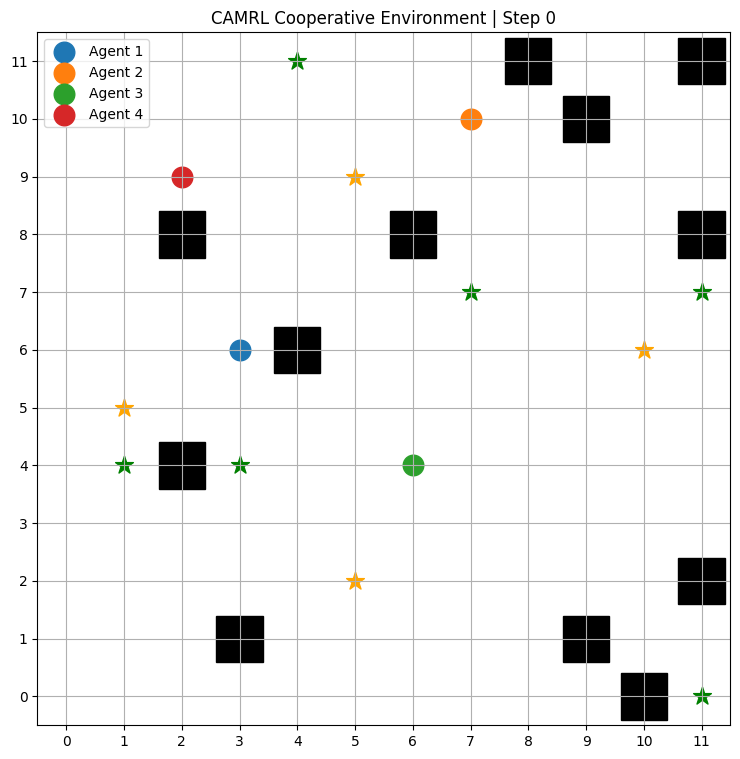

In [9]:

# CELL 2 — Environment Visualisation

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle


def render_environment(env):

    fig, ax = plt.subplots(figsize=(9, 9))

    ax.set_xlim(-0.5, env.grid_size - 0.5)
    ax.set_ylim(-0.5, env.grid_size - 0.5)

    ax.set_xticks(range(env.grid_size))
    ax.set_yticks(range(env.grid_size))

    ax.grid(True)
    ax.set_aspect("equal")

    # Obstacles
    for x, y in env.obstacles:

        ax.add_patch(
            Rectangle(
                (y - 0.4, x - 0.4),
                0.8,
                0.8,
                color="black"
            )
        )

    # Resources
    for resource in env.resources:

        if not resource["collected"]:

            x, y = resource["position"]

            color = "orange" if resource["special"] else "green"

            ax.scatter(
                y, x,
                s=180,
                marker="*",
                color=color
            )

    # Agents
    for i, agent in enumerate(env.agents):

        x, y = agent["position"]

        ax.scatter(
            y, x,
            s=220,
            label=f"Agent {i + 1}"
        )

    ax.set_title(
        f"CAMRL Cooperative Environment | Step {env.step_count}"
    )

    ax.legend()
    plt.show()


env = CooperativeResourceEnv()

observations, info = env.reset(seed=42)

render_environment(env)


Simulation complete
Steps: 100
Resources collected: 4
Total rewards: [10.50000009  9.89999998 10.7         9.19999997]
Team success: False


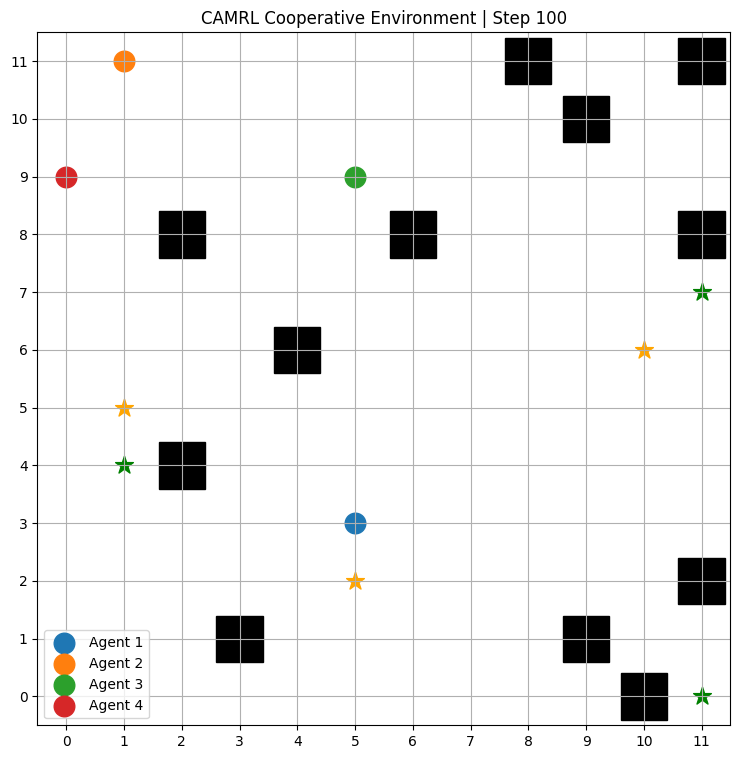

In [10]:

# CELL 3 — Random Agent Simulation

env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=4,
    num_resources=10,
    max_steps=200
)

observations, info = env.reset(seed=42)

total_rewards = np.zeros(4)

for step in range(100):

    actions = [
        env.action_space[i].sample()
        for i in range(env.num_agents)
    ]

    observations, rewards, terminated, truncated, info = (
        env.step(actions)
    )

    total_rewards += rewards

    if terminated or truncated:
        break

print("Simulation complete")
print("Steps:", env.step_count)
print("Resources collected:", info["resources_collected"])
print("Total rewards:", total_rewards)
print("Team success:", info["team_success"])

render_environment(env)


In [11]:

# CELL 1 — IPPO Neural Network Architecture

import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import numpy as np
import random
import os
import time

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OBS_DIM = env.observation_size
ACTION_DIM = env.action_size
NUM_AGENTS = env.num_agents

print("Device:", DEVICE)
print("Observation dimensions:", OBS_DIM)
print("Action dimensions:", ACTION_DIM)
print("Agents:", NUM_AGENTS)


class ActorCritic(nn.Module):

    def __init__(self, obs_dim, action_dim):

        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(obs_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU()
        )

        self.actor = nn.Sequential(
            nn.Linear(256, action_dim)
        )

        self.critic = nn.Sequential(
            nn.Linear(256, 1)
        )

    def forward(self, obs):

        features = self.shared(obs)

        logits = self.actor(features)
        value = self.critic(features).squeeze(-1)

        return logits, value

    def get_action(self, obs):

        logits, value = self.forward(obs)

        distribution = Categorical(logits=logits)

        action = distribution.sample()

        log_prob = distribution.log_prob(action)

        return action, log_prob, value


# Four independent actor-critic networks

agents = [
    ActorCritic(OBS_DIM, ACTION_DIM).to(DEVICE)
    for _ in range(NUM_AGENTS)
]

optimizers = [
    optim.Adam(agent.parameters(), lr=3e-4)
    for agent in agents
]

print("Successfully created", len(agents), "independent agents")


Device: cuda
Observation dimensions: 41
Action dimensions: 6
Agents: 4
Successfully created 4 independent agents


In [12]:

# CELL 2 — PPO Configuration

CONFIG = {
    "learning_rate": 3e-4,
    "gamma": 0.99,
    "gae_lambda": 0.95,
    "clip_epsilon": 0.2,
    "value_coefficient": 0.5,
    "entropy_coefficient": 0.01,
    "rollout_steps": 128,
    "update_epochs": 4,
    "minibatch_size": 64,
    "total_steps": 20000
}

print(CONFIG)


{'learning_rate': 0.0003, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_epsilon': 0.2, 'value_coefficient': 0.5, 'entropy_coefficient': 0.01, 'rollout_steps': 128, 'update_epochs': 4, 'minibatch_size': 64, 'total_steps': 20000}


In [13]:

# CELL 3 — Multi-Agent Rollout Collection

def collect_rollout(env, agents, rollout_steps):

    buffers = []

    for _ in agents:
        buffers.append({
            "obs": [],
            "actions": [],
            "log_probs": [],
            "rewards": [],
            "values": [],
            "next_values": [],
            "dones": []
        })

    observations, _ = env.reset()

    completed_returns = np.zeros(NUM_AGENTS)
    episode_returns = []

    for step in range(rollout_steps):

        actions = []
        sampled_data = []

        for i, agent in enumerate(agents):

            obs_tensor = torch.as_tensor(
                observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            with torch.no_grad():
                action, log_prob, value = agent.get_action(obs_tensor)

            actions.append(action.item())

            sampled_data.append((
                obs_tensor.squeeze(0).cpu().numpy(),
                action.item(),
                log_prob.item(),
                value.item()
            ))

        next_observations, rewards, terminated, truncated, info = (
            env.step(actions)
        )

        done = terminated or truncated

        for i, agent in enumerate(agents):

            next_obs_tensor = torch.as_tensor(
                next_observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            with torch.no_grad():
                _, next_value = agent(next_obs_tensor)

            obs, action, log_prob, value = sampled_data[i]

            buffers[i]["obs"].append(obs)
            buffers[i]["actions"].append(action)
            buffers[i]["log_probs"].append(log_prob)
            buffers[i]["rewards"].append(float(rewards[i]))
            buffers[i]["values"].append(value)

            buffers[i]["next_values"].append(
                0.0 if done else next_value.item()
            )

            buffers[i]["dones"].append(float(done))

        completed_returns += rewards

        if done:

            episode_returns.append(completed_returns.copy())
            completed_returns = np.zeros(NUM_AGENTS)

            observations, _ = env.reset()

        else:

            observations = next_observations

    return buffers, episode_returns


In [14]:

# CELL 4 — Generalised Advantage Estimation

def calculate_gae(
    rewards,
    values,
    next_values,
    dones,
    gamma=0.99,
    gae_lambda=0.95
):

    advantages = np.zeros_like(rewards, dtype=np.float32)

    gae = 0.0

    for t in reversed(range(len(rewards))):

        delta = (
            rewards[t]
            + gamma * next_values[t] * (1.0 - dones[t])
            - values[t]
        )

        gae = (
            delta
            + gamma * gae_lambda
            * (1.0 - dones[t])
            * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns


In [15]:

# CELL 5 — IPPO Policy Optimisation

def update_ippo(agents, optimizers, buffers):

    results = []

    for i, agent in enumerate(agents):

        data = buffers[i]

        obs = torch.tensor(
            np.asarray(data["obs"]),
            dtype=torch.float32,
            device=DEVICE
        )

        actions = torch.tensor(
            data["actions"],
            dtype=torch.long,
            device=DEVICE
        )

        old_log_probs = torch.tensor(
            data["log_probs"],
            dtype=torch.float32,
            device=DEVICE
        )

        rewards = np.asarray(data["rewards"], dtype=np.float32)
        values = np.asarray(data["values"], dtype=np.float32)
        next_values = np.asarray(data["next_values"], dtype=np.float32)
        dones = np.asarray(data["dones"], dtype=np.float32)

        advantages, returns = calculate_gae(
            rewards,
            values,
            next_values,
            dones,
            CONFIG["gamma"],
            CONFIG["gae_lambda"]
        )

        advantages = torch.tensor(
            advantages,
            dtype=torch.float32,
            device=DEVICE
        )

        returns = torch.tensor(
            returns,
            dtype=torch.float32,
            device=DEVICE
        )

        advantages = (
            advantages - advantages.mean()
        ) / (advantages.std(unbiased=False) + 1e-8)

        dataset_size = len(obs)

        total_policy_loss = 0
        total_value_loss = 0
        total_entropy = 0
        update_count = 0

        for epoch in range(CONFIG["update_epochs"]):

            indices = torch.randperm(
                dataset_size,
                device=DEVICE
            )

            for start in range(
                0,
                dataset_size,
                CONFIG["minibatch_size"]
            ):

                batch_idx = indices[
                    start:start + CONFIG["minibatch_size"]
                ]

                logits, predicted_values = agent(obs[batch_idx])

                distribution = Categorical(logits=logits)

                new_log_probs = distribution.log_prob(
                    actions[batch_idx]
                )

                entropy = distribution.entropy().mean()

                ratio = torch.exp(
                    new_log_probs - old_log_probs[batch_idx]
                )

                unclipped = ratio * advantages[batch_idx]

                clipped = torch.clamp(
                    ratio,
                    1 - CONFIG["clip_epsilon"],
                    1 + CONFIG["clip_epsilon"]
                ) * advantages[batch_idx]

                policy_loss = -torch.minimum(
                    unclipped,
                    clipped
                ).mean()

                value_loss = nn.functional.mse_loss(
                    predicted_values,
                    returns[batch_idx]
                )

                loss = (
                    policy_loss
                    + CONFIG["value_coefficient"] * value_loss
                    - CONFIG["entropy_coefficient"] * entropy
                )

                optimizers[i].zero_grad(set_to_none=True)

                loss.backward()

                nn.utils.clip_grad_norm_(
                    agent.parameters(),
                    max_norm=0.5
                )

                optimizers[i].step()

                total_policy_loss += policy_loss.item()
                total_value_loss += value_loss.item()
                total_entropy += entropy.item()

                update_count += 1

        results.append({
            "agent": i,
            "policy_loss": total_policy_loss / max(update_count, 1),
            "value_loss": total_value_loss / max(update_count, 1),
            "entropy": total_entropy / max(update_count, 1)
        })

    return results


In [16]:

# CELL 6 — Environment Cooperation Correction

def corrected_observations(self):

    observations = []

    for agent in self.agents:

        x, y = agent["position"]

        obs = [
            x / (self.grid_size - 1),
            y / (self.grid_size - 1),
            max(0.0, agent["energy"]) / self.initial_energy
        ]

        for resource in self.resources:

            rx, ry = resource["position"]

            obs.extend([
                rx / (self.grid_size - 1),
                ry / (self.grid_size - 1),
                float(resource["collected"]),
                float(resource["special"])
            ])

        for other in self.agents:

            ox, oy = other["position"]

            obs.extend([
                ox / (self.grid_size - 1),
                oy / (self.grid_size - 1)
            ])

        observations.append(
            np.asarray(obs, dtype=np.float32)
        )

    return observations


def corrected_step(self, actions):

    self.step_count += 1

    rewards = np.zeros(self.num_agents, dtype=np.float32)

    movement = {
        0: (0, 0),
        1: (-1, 0),
        2: (1, 0),
        3: (0, -1),
        4: (0, 1)
    }

    for i, agent in enumerate(self.agents):

        if agent["energy"] <= 0:
            continue

        action = int(actions[i])

        if action in movement:

            dx, dy = movement[action]

            x, y = agent["position"]
            nx, ny = x + dx, y + dy

            if (
                0 <= nx < self.grid_size
                and 0 <= ny < self.grid_size
                and (nx, ny) not in self.obstacles
            ):
                agent["position"] = [nx, ny]
            else:
                rewards[i] -= 0.1

            agent["energy"] -= 0.2

        elif action == 5:

            agent["energy"] -= 0.5

    # Process collection simultaneously after movement.

    for resource in self.resources:

        if resource["collected"]:
            continue

        resource_pos = tuple(resource["position"])

        collectors = [
            i for i, agent in enumerate(self.agents)
            if int(actions[i]) == 5
            and agent["energy"] > 0
            and tuple(agent["position"]) == resource_pos
        ]

        required_agents = 2 if resource["special"] else 1

        if len(collectors) >= required_agents:

            resource["collected"] = True

            for i in collectors:
                self.agents[i]["collected"] += 1

            # Shared team reward.
            rewards += 5.0 if resource["special"] else 2.0

    for i, agent in enumerate(self.agents):

        if agent["energy"] <= 0:
            agent["energy"] = 0

    terminated = all(
        r["collected"] for r in self.resources
    )

    truncated = self.step_count >= self.max_steps

    if terminated:
        rewards += 10.0

    info = {
        "resources_collected": sum(
            r["collected"] for r in self.resources
        ),
        "team_success": terminated
    }

    return (
        self.get_observations(),
        rewards,
        terminated,
        truncated,
        info
    )


CooperativeResourceEnv.get_observations = corrected_observations
CooperativeResourceEnv.step = corrected_step

# Create a fresh corrected environment.
env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=4,
    num_resources=10,
    max_steps=200
)

env.observation_size = (
    3 + env.num_resources * 4 + env.num_agents * 2
)

print("Corrected observation size:", env.observation_size)
print("Special resource coordination enabled.")


Corrected observation size: 51
Special resource coordination enabled.


In [17]:

# CELL 7 — CAMRL IPPO Training Loop

import pandas as pd
from tqdm.auto import tqdm

# Reinitialise networks for corrected observation size.

agents = [
    ActorCritic(
        env.observation_size,
        env.action_size
    ).to(DEVICE)
    for _ in range(env.num_agents)
]

optimizers = [
    optim.Adam(
        agent.parameters(),
        lr=CONFIG["learning_rate"]
    )
    for agent in agents
]

history = []

total_updates = (
    CONFIG["total_steps"] // CONFIG["rollout_steps"]
)

global_steps = 0
start_time = time.time()

for update in tqdm(range(1, total_updates + 1)):

    buffers, episode_returns = collect_rollout(
        env,
        agents,
        CONFIG["rollout_steps"]
    )

    update_results = update_ippo(
        agents,
        optimizers,
        buffers
    )

    global_steps += CONFIG["rollout_steps"]

    mean_episode_reward = (
        float(np.mean(episode_returns))
        if episode_returns else np.nan
    )

    history.append({
        "update": update,
        "steps": global_steps,
        "mean_episode_reward": mean_episode_reward,
        "policy_loss": np.mean([
            x["policy_loss"] for x in update_results
        ]),
        "value_loss": np.mean([
            x["value_loss"] for x in update_results
        ]),
        "entropy": np.mean([
            x["entropy"] for x in update_results
        ])
    })

    if update % 10 == 0:

        print(
            f"\nUpdate {update}/{total_updates}"
            f" | Steps: {global_steps}"
            f" | Episode reward: {mean_episode_reward:.3f}"
            if not np.isnan(mean_episode_reward)
            else f"\nUpdate {update}/{total_updates}"
            f" | Steps: {global_steps}"
            f" | No completed episode in this rollout"
        )

        checkpoint = {
            "agents": [
                a.state_dict() for a in agents
            ],
            "optimizers": [
                o.state_dict() for o in optimizers
            ],
            "update": update,
            "global_steps": global_steps,
            "config": CONFIG,
            "history": history
        }

        torch.save(
            checkpoint,
            os.path.join(
                PROJECT_ROOT,
                "checkpoints",
                "ippo_checkpoint.pt"
            )
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

print("\nIPPO training completed.")

print(
    "Training duration:",
    round(time.time() - start_time, 2),
    "seconds"
)

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(PROJECT_ROOT, "results", "ippo_training.csv"),
    index=False
)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/156 [00:00<?, ?it/s]


Update 10/156 | Steps: 1280 | No completed episode in this rollout

Update 20/156 | Steps: 2560 | No completed episode in this rollout

Update 30/156 | Steps: 3840 | No completed episode in this rollout

Update 40/156 | Steps: 5120 | No completed episode in this rollout

Update 50/156 | Steps: 6400 | No completed episode in this rollout

Update 60/156 | Steps: 7680 | No completed episode in this rollout

Update 70/156 | Steps: 8960 | No completed episode in this rollout

Update 80/156 | Steps: 10240 | No completed episode in this rollout

Update 90/156 | Steps: 11520 | No completed episode in this rollout

Update 100/156 | Steps: 12800 | No completed episode in this rollout

Update 110/156 | Steps: 14080 | No completed episode in this rollout

Update 120/156 | Steps: 15360 | No completed episode in this rollout

Update 130/156 | Steps: 16640 | No completed episode in this rollout

Update 140/156 | Steps: 17920 | No completed episode in this rollout

Update 150/156 | Steps: 19200 | No 

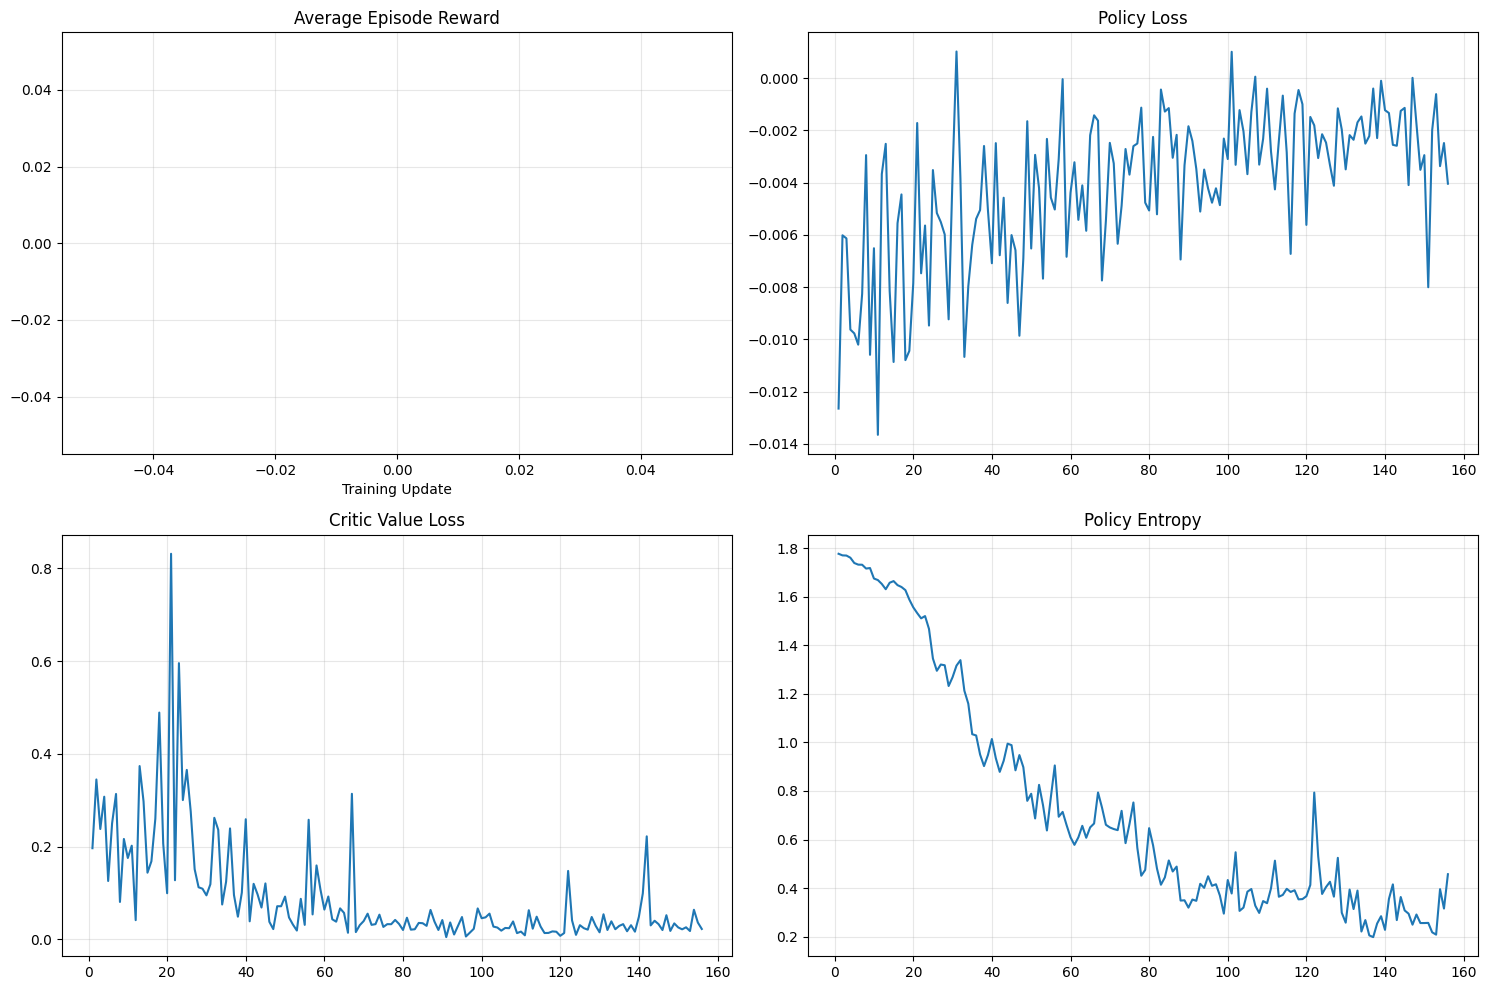

In [18]:

# CELL 8 — IPPO Training Analytics

import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Episode reward
axes[0, 0].plot(
    history_df["update"],
    history_df["mean_episode_reward"]
)

axes[0, 0].set_title("Average Episode Reward")
axes[0, 0].set_xlabel("Training Update")

# Policy loss
axes[0, 1].plot(
    history_df["update"],
    history_df["policy_loss"]
)

axes[0, 1].set_title("Policy Loss")

# Value loss
axes[1, 0].plot(
    history_df["update"],
    history_df["value_loss"]
)

axes[1, 0].set_title("Critic Value Loss")

# Entropy
axes[1, 1].plot(
    history_df["update"],
    history_df["entropy"]
)

axes[1, 1].set_title("Policy Entropy")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_ROOT, "results", "ippo_training_curves.png"),
    dpi=200
)

plt.show()


In [19]:

# CELL 9 — IPPO Evaluation

def evaluate_ippo(agents, episodes=100):

    episode_results = []

    for episode in range(episodes):

        observations, _ = env.reset(seed=1000 + episode)

        total_reward = np.zeros(NUM_AGENTS)

        for step in range(env.max_steps):

            actions = []

            for i, agent in enumerate(agents):

                obs = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                with torch.no_grad():
                    logits, _ = agent(obs)

                action = torch.argmax(logits, dim=-1)

                actions.append(action.item())

            observations, rewards, terminated, truncated, info = (
                env.step(actions)
            )

            total_reward += rewards

            if terminated or truncated:
                break

        episode_results.append({
            "episode": episode + 1,
            "team_reward": float(np.mean(total_reward)),
            "resources_collected": info["resources_collected"],
            "success": int(info["team_success"]),
            "steps": env.step_count
        })

    return pd.DataFrame(episode_results)


evaluation_df = evaluate_ippo(agents, episodes=100)

print("IPPO EVALUATION")
print("=" * 40)

print(
    "Mean team reward:",
    evaluation_df["team_reward"].mean()
)

print(
    "Success rate:",
    evaluation_df["success"].mean() * 100,
    "%"
)

print(
    "Mean resources collected:",
    evaluation_df["resources_collected"].mean()
)

evaluation_df.to_csv(
    os.path.join(PROJECT_ROOT, "results", "ippo_evaluation.csv"),
    index=False
)

evaluation_df.head()


IPPO EVALUATION
Mean team reward: 0.0
Success rate: 0.0 %
Mean resources collected: 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,episode,team_reward,resources_collected,success,steps
0,1,0.0,0,0,200
1,2,0.0,0,0,200
2,3,0.0,0,0,200
3,4,0.0,0,0,200
4,5,0.0,0,0,200


In [20]:

# CELL 10 — Export IPPO Models

for i, agent in enumerate(agents):

    model_path = os.path.join(
        PROJECT_ROOT,
        "checkpoints",
        f"ippo_agent_{i}.pt"
    )

    torch.save(
        {
            "model_state_dict": agent.state_dict(),
            "observation_size": env.observation_size,
            "action_size": env.action_size,
            "agent_id": i,
            "algorithm": "IPPO"
        },
        model_path
    )

print("All four IPPO models saved.")

final_checkpoint = {
    "agents": [a.state_dict() for a in agents],
    "config": CONFIG,
    "training_history": history,
    "evaluation": evaluation_df.to_dict(orient="records")
}

torch.save(
    final_checkpoint,
    os.path.join(
        PROJECT_ROOT,
        "checkpoints",
        "ippo_final.pt"
    )
)


All four IPPO models saved.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:

# CELL 1 — MAPPO Environment Adapter

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from torch.distributions import Categorical

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_AGENTS = 4

env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=NUM_AGENTS,
    num_resources=10,
    max_steps=200
)

LOCAL_OBS_DIM = env.observation_size
GLOBAL_STATE_DIM = LOCAL_OBS_DIM * NUM_AGENTS
ACTION_DIM = env.action_size

def get_global_state(observations):

    return np.concatenate(
        observations
    ).astype(np.float32)


def get_shared_reward(rewards):

    return float(np.mean(rewards))


print("Local observation:", LOCAL_OBS_DIM)
print("Global state:", GLOBAL_STATE_DIM)
print("Action dimensions:", ACTION_DIM)
print("Device:", DEVICE)


Local observation: 41
Global state: 164
Action dimensions: 6
Device: cuda


In [22]:

# CELL 2 — MAPPO Actor Network

class MAPPOActor(nn.Module):

    def __init__(self, obs_dim, action_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(obs_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),

            nn.Linear(256, 256),
            nn.ReLU(),

            nn.Linear(256, action_dim)
        )

    def forward(self, obs):

        return self.network(obs)

    def get_action(self, obs, deterministic=False):

        logits = self.forward(obs)

        distribution = Categorical(logits=logits)

        if deterministic:
            action = torch.argmax(logits, dim=-1)
        else:
            action = distribution.sample()

        log_prob = distribution.log_prob(action)

        return action, log_prob, distribution.entropy()


In [23]:

# CELL 3 — Centralised Critic

class CentralizedCritic(nn.Module):

    def __init__(self, global_state_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(global_state_dim, 512),
            nn.LayerNorm(512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 1)
        )

    def forward(self, global_state):

        return self.network(global_state).squeeze(-1)


In [24]:

# CELL 4 — MAPPO Model Initialisation

actors = [
    MAPPOActor(
        LOCAL_OBS_DIM,
        ACTION_DIM
    ).to(DEVICE)
    for _ in range(NUM_AGENTS)
]

critic = CentralizedCritic(
    GLOBAL_STATE_DIM
).to(DEVICE)

actor_optimizers = [
    optim.Adam(
        actor.parameters(),
        lr=3e-4
    )
    for actor in actors
]

critic_optimizer = optim.Adam(
    critic.parameters(),
    lr=3e-4
)

print("MAPPO actors:", len(actors))
print("Centralised critics:", 1)

print(
    "Total parameters:",
    sum(
        p.numel() for model in actors + [critic]
        for p in model.parameters()
    )
)


MAPPO actors: 4
Centralised critics: 1
Total parameters: 531481


In [25]:

# CELL 5 — MAPPO Rollout Collection

def collect_mappo_rollout(
    env,
    actors,
    critic,
    rollout_steps=128
):

    buffer = {
        "observations": [],
        "global_states": [],
        "actions": [],
        "old_log_probs": [],
        "rewards": [],
        "values": [],
        "next_values": [],
        "dones": []
    }

    observations, _ = env.reset()

    episode_rewards = []
    current_episode_reward = 0.0

    for step in range(rollout_steps):

        global_state = get_global_state(observations)

        actions = []
        log_probs = []

        with torch.no_grad():

            state_tensor = torch.as_tensor(
                global_state,
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            value = critic(state_tensor).item()

            for i, actor in enumerate(actors):

                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                action, log_prob, _ = actor.get_action(
                    obs_tensor
                )

                actions.append(action.item())
                log_probs.append(log_prob.item())

        next_obs, rewards, terminated, truncated, info = (
            env.step(actions)
        )

        done = terminated or truncated

        next_state = get_global_state(next_obs)

        with torch.no_grad():

            next_state_tensor = torch.as_tensor(
                next_state,
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            next_value = (
                0.0 if done
                else critic(next_state_tensor).item()
            )

        shared_reward = get_shared_reward(rewards)

        buffer["observations"].append(observations)
        buffer["global_states"].append(global_state)
        buffer["actions"].append(actions)
        buffer["old_log_probs"].append(log_probs)
        buffer["rewards"].append(shared_reward)
        buffer["values"].append(value)
        buffer["next_values"].append(next_value)
        buffer["dones"].append(float(done))

        current_episode_reward += shared_reward

        if done:

            episode_rewards.append(current_episode_reward)

            current_episode_reward = 0.0

            observations, _ = env.reset()

        else:

            observations = next_obs

    return buffer, episode_rewards


In [26]:

# CELL 6 — MAPPO GAE

def mappo_gae(
    rewards,
    values,
    next_values,
    dones,
    gamma=0.99,
    gae_lambda=0.95
):

    advantages = np.zeros(
        len(rewards),
        dtype=np.float32
    )

    gae = 0.0

    for t in reversed(range(len(rewards))):

        delta = (
            rewards[t]
            + gamma * next_values[t] * (1 - dones[t])
            - values[t]
        )

        gae = (
            delta
            + gamma * gae_lambda
            * (1 - dones[t])
            * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns


In [30]:

# CELL 7 — MAPPO Training Update

def update_mappo(
    buffer,
    actors,
    critic,
    actor_optimizers,
    critic_optimizer,
    epochs=4,
    minibatch_size=64
):

    obs = torch.tensor(
        np.asarray(buffer["observations"]),
        dtype=torch.float32,
        device=DEVICE
    )

    states = torch.tensor(
        np.asarray(buffer["global_states"]),
        dtype=torch.float32,
        device=DEVICE
    )

    actions = torch.tensor(
        np.asarray(buffer["actions"]),
        dtype=torch.long,
        device=DEVICE
    )

    old_log_probs = torch.tensor(
        np.asarray(buffer["old_log_probs"]),
        dtype=torch.float32,
        device=DEVICE
    )

    rewards = np.asarray(buffer["rewards"], dtype=np.float32)
    values = np.asarray(buffer["values"], dtype=np.float32)
    next_values = np.asarray(buffer["next_values"], dtype=np.float32)
    dones = np.asarray(buffer["dones"], dtype=np.float32)

    advantages, returns = mappo_gae(
        rewards,
        values,
        next_values,
        dones
    )

    advantages = torch.tensor(
        advantages,
        dtype=torch.float32,
        device=DEVICE
    )

    returns = torch.tensor(
        returns,
        dtype=torch.float32,
        device=DEVICE
    )

    advantages = (
        advantages - advantages.mean()
    ) / (advantages.std(unbiased=False) + 1e-8)

    size = len(rewards)

    policy_losses = []
    value_losses = []

    for epoch in range(epochs):

        indices = torch.randperm(
            size,
            device=DEVICE
        )

        for start in range(0, size, minibatch_size):

            idx = indices[start:start + minibatch_size]

            # Update decentralised actors.
            for i, actor in enumerate(actors):

                logits = actor(obs[idx, i])

                distribution = Categorical(logits=logits)

                new_log_prob = distribution.log_prob(
                    actions[idx, i]
                )

                ratio = torch.exp(
                    new_log_prob - old_log_probs[idx, i]
                )

                surrogate1 = ratio * advantages[idx]

                surrogate2 = torch.clamp(
                    ratio, 0.8, 1.2
                ) * advantages[idx]

                policy_loss = -torch.minimum(
                    surrogate1,
                    surrogate2
                ).mean()

                entropy = distribution.entropy().mean()

                actor_loss = policy_loss - 0.01 * entropy

                actor_optimizers[i].zero_grad(
                    set_to_none=True
                )

                actor_loss.backward()

                nn.utils.clip_grad_norm_(
                    actor.parameters(), 0.5
                )

                actor_optimizers[i].step()

                policy_losses.append(policy_loss.item())

            # Update centralised critic.
            predicted_values = critic(states[idx])

            value_loss = nn.functional.mse_loss(
                predicted_values,
                returns[idx]
            )

            critic_optimizer.zero_grad(
                set_to_none=True
            )

            (0.5 * value_loss).backward()

            nn.utils.clip_grad_norm_(
                critic.parameters(), 0.5
            )

            critic_optimizer.step()

            value_losses.append(value_loss.item())

    return {
        "policy_loss": np.mean(policy_losses),
        "value_loss": np.mean(value_losses)
    }


In [32]:

# FIX 1 — Recalculate all observation dimensions

# Reset environment using the corrected implementation
env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=4,
    num_resources=10,
    max_steps=200
)

observations, _ = env.reset(seed=42)

NUM_AGENTS = env.num_agents
LOCAL_OBS_DIM = len(observations[0])
GLOBAL_STATE_DIM = sum(len(obs) for obs in observations)
ACTION_DIM = env.action_size

print("Number of agents:", NUM_AGENTS)
print("Local observation dimension:", LOCAL_OBS_DIM)
print("Global state dimension:", GLOBAL_STATE_DIM)
print("Action dimension:", ACTION_DIM)

assert GLOBAL_STATE_DIM == LOCAL_OBS_DIM * NUM_AGENTS


Number of agents: 4
Local observation dimension: 51
Global state dimension: 204
Action dimension: 6


In [33]:

# FIX 2 — Rebuild MAPPO models

actors = [
    MAPPOActor(
        LOCAL_OBS_DIM,
        ACTION_DIM
    ).to(DEVICE)
    for _ in range(NUM_AGENTS)
]

critic = CentralizedCritic(
    GLOBAL_STATE_DIM
).to(DEVICE)

actor_optimizers = [
    torch.optim.Adam(
        actor.parameters(),
        lr=3e-4
    )
    for actor in actors
]

critic_optimizer = torch.optim.Adam(
    critic.parameters(),
    lr=3e-4
)

# Verify network dimensions
dummy_local = torch.zeros(
    1, LOCAL_OBS_DIM,
    device=DEVICE
)

dummy_global = torch.zeros(
    1, GLOBAL_STATE_DIM,
    device=DEVICE
)

print("Actor output:", actors[0](dummy_local).shape)
print("Critic output:", critic(dummy_global).shape)

assert actors[0](dummy_local).shape == (1, ACTION_DIM)
assert critic(dummy_global).shape == (1,)

print("MAPPO dimensions successfully verified.")


Actor output: torch.Size([1, 6])
Critic output: torch.Size([1])
MAPPO dimensions successfully verified.


In [34]:

# FIX 3 — Test rollout before training

test_buffer, test_rewards = collect_mappo_rollout(
    env,
    actors,
    critic,
    rollout_steps=128
)

print("Observations:", np.asarray(
    test_buffer["observations"]
).shape)

print("Global states:", np.asarray(
    test_buffer["global_states"]
).shape)

print("Actions:", np.asarray(
    test_buffer["actions"]
).shape)

print("Rewards:", np.asarray(
    test_buffer["rewards"]
).shape)

print("Completed episodes:", len(test_rewards))

assert np.asarray(test_buffer["global_states"]).shape == (
    128, GLOBAL_STATE_DIM
)

print("Rollout validation successful.")


Observations: (128, 4, 51)
Global states: (128, 204)
Actions: (128, 4)
Rewards: (128,)
Completed episodes: 0
Rollout validation successful.


In [35]:

# CELL 8 — MAPPO Training Loop

from tqdm.auto import tqdm
import pandas as pd
import time

MAPPO_CONFIG = {
    "total_steps": 20000,
    "rollout_steps": 128,
    "epochs": 4,
    "minibatch_size": 64,
    "learning_rate": 3e-4
}

mappo_history = []

total_updates = (
    MAPPO_CONFIG["total_steps"]
    // MAPPO_CONFIG["rollout_steps"]
)

start_time = time.time()

for update in tqdm(range(1, total_updates + 1)):

    buffer, episode_rewards = collect_mappo_rollout(
        env,
        actors,
        critic,
        MAPPO_CONFIG["rollout_steps"]
    )

    losses = update_mappo(
        buffer,
        actors,
        critic,
        actor_optimizers,
        critic_optimizer,
        epochs=MAPPO_CONFIG["epochs"],
        minibatch_size=MAPPO_CONFIG["minibatch_size"]
    )

    mappo_history.append({
        "update": update,
        "steps": update * MAPPO_CONFIG["rollout_steps"],
        "mean_episode_reward": (
            np.mean(episode_rewards)
            if episode_rewards else np.nan
        ),
        "policy_loss": losses["policy_loss"],
        "value_loss": losses["value_loss"]
    })

    if update % 10 == 0:

        print(
            f"Update {update}/{total_updates}"
            f" | Reward: {mappo_history[-1]['mean_episode_reward']}"
            f" | Critic loss: {losses['value_loss']:.4f}"
        )

        torch.save(
            {
                "actors": [a.state_dict() for a in actors],
                "critic": critic.state_dict(),
                "actor_optimizers": [
                    o.state_dict() for o in actor_optimizers
                ],
                "critic_optimizer": critic_optimizer.state_dict(),
                "history": mappo_history,
                "config": MAPPO_CONFIG
            },
            os.path.join(
                PROJECT_ROOT,
                "checkpoints",
                "mappo_checkpoint.pt"
            )
        )

print("MAPPO training complete.")
print("Duration:", round(time.time() - start_time, 2), "seconds")

mappo_df = pd.DataFrame(mappo_history)

mappo_df.to_csv(
    os.path.join(PROJECT_ROOT, "results", "mappo_training.csv"),
    index=False
)


  0%|          | 0/156 [00:00<?, ?it/s]

Update 10/156 | Reward: nan | Critic loss: 0.2634
Update 20/156 | Reward: nan | Critic loss: 0.1976
Update 30/156 | Reward: nan | Critic loss: 0.2218
Update 40/156 | Reward: nan | Critic loss: 0.0325
Update 50/156 | Reward: nan | Critic loss: 0.0473
Update 60/156 | Reward: nan | Critic loss: 0.0192
Update 70/156 | Reward: nan | Critic loss: 0.0788
Update 80/156 | Reward: nan | Critic loss: 0.0277
Update 90/156 | Reward: nan | Critic loss: 0.1436
Update 100/156 | Reward: nan | Critic loss: 0.4439
Update 110/156 | Reward: nan | Critic loss: 0.0201
Update 120/156 | Reward: nan | Critic loss: 0.0218
Update 130/156 | Reward: nan | Critic loss: 0.0095
Update 140/156 | Reward: nan | Critic loss: 0.0163
Update 150/156 | Reward: nan | Critic loss: 0.0663
MAPPO training complete.
Duration: 120.02 seconds


In [36]:

# CELL 9 — MAPPO Evaluation

def evaluate_mappo(actors, episodes=100):

    results = []

    for episode in range(episodes):

        observations, _ = env.reset(seed=2000 + episode)

        total_reward = 0.0

        for step in range(env.max_steps):

            actions = []

            for i, actor in enumerate(actors):

                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                with torch.no_grad():

                    action, _, _ = actor.get_action(
                        obs_tensor,
                        deterministic=True
                    )

                actions.append(action.item())

            observations, rewards, terminated, truncated, info = (
                env.step(actions)
            )

            total_reward += get_shared_reward(rewards)

            if terminated or truncated:
                break

        results.append({
            "episode": episode + 1,
            "team_reward": total_reward,
            "resources_collected": info["resources_collected"],
            "success": int(info["team_success"]),
            "steps": env.step_count
        })

    return pd.DataFrame(results)


mappo_evaluation = evaluate_mappo(actors, episodes=100)

print("MAPPO SUCCESS RATE:",
      mappo_evaluation["success"].mean() * 100, "%")

print("AVERAGE TEAM REWARD:",
      mappo_evaluation["team_reward"].mean())

mappo_evaluation.to_csv(
    os.path.join(
        PROJECT_ROOT,
        "results",
        "mappo_evaluation.csv"
    ),
    index=False
)


MAPPO SUCCESS RATE: 0.0 %
AVERAGE TEAM REWARD: 0.0


  Algorithm  Success Rate  Mean Team Reward
0      IPPO           0.0               0.0
1     MAPPO           0.0               0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


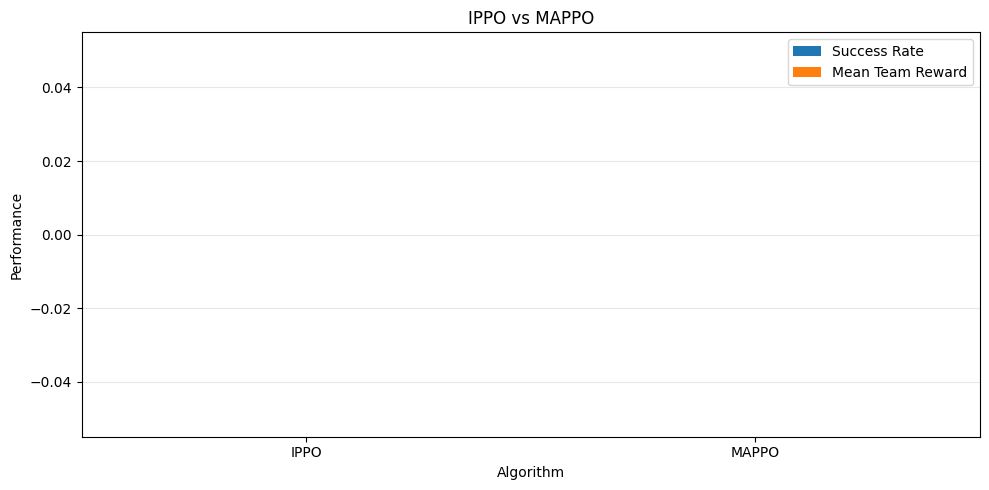

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:

# CELL 10 — Algorithm Comparison

import matplotlib.pyplot as plt

ippo_eval_path = os.path.join(
    PROJECT_ROOT,
    "results",
    "ippo_evaluation.csv"
)

if os.path.exists(ippo_eval_path):

    ippo_eval = pd.read_csv(ippo_eval_path)

    comparison = pd.DataFrame({
        "Algorithm": ["IPPO", "MAPPO"],
        "Success Rate": [
            ippo_eval["success"].mean() * 100,
            mappo_evaluation["success"].mean() * 100
        ],
        "Mean Team Reward": [
            ippo_eval["team_reward"].mean(),
            mappo_evaluation["team_reward"].mean()
        ]
    })

    print(comparison)

    comparison.set_index("Algorithm").plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("IPPO vs MAPPO")
    plt.ylabel("Performance")
    plt.xticks(rotation=0)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

else:

    print("IPPO evaluation file not found.")
    print("Complete Phase 3 evaluation first.")


In [38]:

# CELL 11 — MAPPO Model Export

final_path = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "mappo_final.pt"
)

torch.save(
    {
        "actors": [
            actor.state_dict()
            for actor in actors
        ],
        "critic": critic.state_dict(),
        "actor_optimizers": [
            optimizer.state_dict()
            for optimizer in actor_optimizers
        ],
        "critic_optimizer": critic_optimizer.state_dict(),
        "config": MAPPO_CONFIG,
        "history": mappo_history,
        "observation_size": LOCAL_OBS_DIM,
        "global_state_size": GLOBAL_STATE_DIM,
        "action_size": ACTION_DIM
    },
    final_path
)

print("MAPPO checkpoint saved:", final_path)


MAPPO checkpoint saved: /content/drive/MyDrive/CAMRL/checkpoints/mappo_final.pt


In [39]:

# CELL 11 — MAPPO Model Export

final_path = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "mappo_final.pt"
)

torch.save(
    {
        "actors": [
            actor.state_dict()
            for actor in actors
        ],
        "critic": critic.state_dict(),
        "actor_optimizers": [
            optimizer.state_dict()
            for optimizer in actor_optimizers
        ],
        "critic_optimizer": critic_optimizer.state_dict(),
        "config": MAPPO_CONFIG,
        "history": mappo_history,
        "observation_size": LOCAL_OBS_DIM,
        "global_state_size": GLOBAL_STATE_DIM,
        "action_size": ACTION_DIM
    },
    final_path
)

print("MAPPO checkpoint saved:", final_path)


MAPPO checkpoint saved: /content/drive/MyDrive/CAMRL/checkpoints/mappo_final.pt


In [40]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import copy
import os
from collections import deque
from pathlib import Path

# Create a fresh environment
env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=4,
    num_resources=10,
    max_steps=200
)

# Detect actual dimensions from returned observations
try:
    observations, info = env.reset(seed=42)
except TypeError:
    observations, info = env.reset()

observations = np.asarray(observations, dtype=np.float32)

NUM_AGENTS = observations.shape[0]
LOCAL_OBS_DIM = observations.shape[1]
GLOBAL_STATE_DIM = observations.size
ACTION_DIM = env.action_size

print("Agents:", NUM_AGENTS)
print("Local observation dimension:", LOCAL_OBS_DIM)
print("Global state dimension:", GLOBAL_STATE_DIM)
print("Action dimension:", ACTION_DIM)

assert NUM_AGENTS == 4
assert LOCAL_OBS_DIM == 51, (
    f"Expected 51 features per agent, but received {LOCAL_OBS_DIM}. "
    "Check the environment observation implementation."
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", DEVICE)

Agents: 4
Local observation dimension: 51
Global state dimension: 204
Action dimension: 6
Training device: cuda


In [41]:
class AgentQNetwork(nn.Module):
    def __init__(self, obs_dim, action_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(obs_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, action_dim)
        )

    def forward(self, observations):
        return self.network(observations)


class QMixer(nn.Module):
    def __init__(self, num_agents, state_dim, mixing_dim=64):
        super().__init__()

        self.num_agents = num_agents
        self.mixing_dim = mixing_dim

        # Hypernetworks generate non-negative mixing weights
        self.hyper_w1 = nn.Linear(
            state_dim, num_agents * mixing_dim
        )

        self.hyper_b1 = nn.Linear(
            state_dim, mixing_dim
        )

        self.hyper_w2 = nn.Linear(
            state_dim, mixing_dim
        )

        self.hyper_b2 = nn.Sequential(
            nn.Linear(state_dim, mixing_dim),
            nn.ReLU(),
            nn.Linear(mixing_dim, 1)
        )

    def forward(self, agent_qs, states):

        batch_size = agent_qs.shape[0]

        # First mixing layer
        w1 = torch.abs(
            self.hyper_w1(states)
        ).view(
            batch_size, self.num_agents, self.mixing_dim
        )

        b1 = self.hyper_b1(states).view(
            batch_size, 1, self.mixing_dim
        )

        hidden = F.elu(
            torch.bmm(agent_qs.unsqueeze(1), w1) + b1
        )

        # Second mixing layer
        w2 = torch.abs(
            self.hyper_w2(states)
        ).view(batch_size, self.mixing_dim, 1)

        b2 = self.hyper_b2(states).view(
            batch_size, 1, 1
        )

        total_q = torch.bmm(hidden, w2) + b2

        return total_q.squeeze(-1).squeeze(-1)

In [42]:
class ReplayBuffer:
    def __init__(self, capacity=50000):
        self.buffer = deque(maxlen=capacity)

    def push(
        self,
        observations,
        state,
        actions,
        reward,
        next_observations,
        next_state,
        done
    ):
        self.buffer.append((
            observations.copy(),
            state.copy(),
            actions.copy(),
            float(reward),
            next_observations.copy(),
            next_state.copy(),
            float(done)
        ))

    def sample(self, batch_size):

        batch = random.sample(self.buffer, batch_size)

        obs, states, actions, rewards, next_obs, next_states, dones = zip(*batch)

        return (
            np.asarray(obs, dtype=np.float32),
            np.asarray(states, dtype=np.float32),
            np.asarray(actions, dtype=np.int64),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(next_obs, dtype=np.float32),
            np.asarray(next_states, dtype=np.float32),
            np.asarray(dones, dtype=np.float32)
        )

    def __len__(self):
        return len(self.buffer)

In [43]:
agent_networks = nn.ModuleList([
    AgentQNetwork(LOCAL_OBS_DIM, ACTION_DIM)
    for _ in range(NUM_AGENTS)
]).to(DEVICE)

mixer = QMixer(
    num_agents=NUM_AGENTS,
    state_dim=GLOBAL_STATE_DIM,
    mixing_dim=64
).to(DEVICE)

target_agents = copy.deepcopy(agent_networks).to(DEVICE)
target_mixer = copy.deepcopy(mixer).to(DEVICE)

optimizer = torch.optim.Adam(
    list(agent_networks.parameters()) +
    list(mixer.parameters()),
    lr=3e-4
)

replay_buffer = ReplayBuffer(capacity=50000)

GAMMA = 0.99
BATCH_SIZE = 128
MIN_REPLAY_SIZE = 1000
TARGET_UPDATE_INTERVAL = 500

EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY_STEPS = 20000

TOTAL_TRAINING_STEPS = 30000

print("QMIX initialised successfully.")
print("Parameters:", sum(
    p.numel() for p in agent_networks.parameters()
) + sum(p.numel() for p in mixer.parameters()))

QMIX initialised successfully.
Parameters: 414489


In [44]:
def select_qmix_actions(obs, epsilon):

    actions = []

    for agent_id in range(NUM_AGENTS):

        if random.random() < epsilon:
            action = random.randrange(ACTION_DIM)

        else:
            obs_tensor = torch.as_tensor(
                obs[agent_id],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            with torch.no_grad():
                q_values = agent_networks[agent_id](obs_tensor)

            action = int(q_values.argmax(dim=-1).item())

        actions.append(action)

    return np.asarray(actions, dtype=np.int64)


def reset_camrl_environment(environment, seed=None):
    try:
        result = environment.reset(seed=seed)
    except TypeError:
        result = environment.reset()

    obs = result[0] if isinstance(result, tuple) else result

    return np.asarray(obs, dtype=np.float32)


def step_camrl_environment(environment, actions):

    result = environment.step(actions)

    if len(result) == 5:
        next_obs, rewards, terminated, truncated, info = result
        done = bool(
            np.asarray(terminated).any() or
            np.asarray(truncated).any()
        )

    elif len(result) == 4:
        next_obs, rewards, done, info = result
        done = bool(np.asarray(done).any())

    else:
        raise ValueError(
            f"Unexpected environment step output: {len(result)} values"
        )

    next_obs = np.asarray(next_obs, dtype=np.float32)
    team_reward = float(np.asarray(rewards, dtype=np.float32).mean())

    return next_obs, team_reward, done, info

In [45]:
def train_qmix():

    if len(replay_buffer) < MIN_REPLAY_SIZE:
        return None

    (
        obs_batch,
        state_batch,
        actions_batch,
        rewards_batch,
        next_obs_batch,
        next_state_batch,
        dones_batch
    ) = replay_buffer.sample(BATCH_SIZE)

    obs = torch.tensor(obs_batch, device=DEVICE)
    states = torch.tensor(state_batch, device=DEVICE)

    actions = torch.tensor(
        actions_batch, dtype=torch.long, device=DEVICE
    )

    rewards = torch.tensor(
        rewards_batch, dtype=torch.float32, device=DEVICE
    )

    next_obs = torch.tensor(next_obs_batch, device=DEVICE)
    next_states = torch.tensor(next_state_batch, device=DEVICE)

    dones = torch.tensor(
        dones_batch, dtype=torch.float32, device=DEVICE
    )

    # Calculate current individual Q-values
    chosen_agent_qs = []

    for agent_id in range(NUM_AGENTS):

        q_values = agent_networks[agent_id](
            obs[:, agent_id, :]
        )

        chosen_q = q_values.gather(
            1,
            actions[:, agent_id].unsqueeze(1)
        ).squeeze(1)

        chosen_agent_qs.append(chosen_q)

    chosen_agent_qs = torch.stack(
        chosen_agent_qs, dim=1
    )

    # Combine individual Q-values into team Q-value
    total_q = mixer(chosen_agent_qs, states)

    # Target joint value
    with torch.no_grad():

        target_agent_qs = []

        for agent_id in range(NUM_AGENTS):

            next_q_values = target_agents[agent_id](
                next_obs[:, agent_id, :]
            )

            max_next_q = next_q_values.max(
                dim=1
            ).values

            target_agent_qs.append(max_next_q)

        target_agent_qs = torch.stack(
            target_agent_qs, dim=1
        )

        target_total_q = target_mixer(
            target_agent_qs,
            next_states
        )

        targets = rewards + GAMMA * (
            1.0 - dones
        ) * target_total_q

    loss = F.smooth_l1_loss(total_q, targets)

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        list(agent_networks.parameters()) +
        list(mixer.parameters()),
        max_norm=10.0
    )

    optimizer.step()

    return float(loss.item())

In [46]:
import time
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

qmix_env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=4,
    num_resources=10,
    max_steps=200
)

obs = reset_camrl_environment(qmix_env, seed=42)

assert obs.shape == (NUM_AGENTS, LOCAL_OBS_DIM), (
    f"Unexpected observation shape: {obs.shape}"
)

episode_reward = 0.0
episode_rewards = []
training_losses = []

epsilon = EPSILON_START
episode = 0

start_time = time.time()

for step in tqdm(range(1, TOTAL_TRAINING_STEPS + 1)):

    # Epsilon-greedy action selection
    actions = select_qmix_actions(obs, epsilon)

    next_obs, reward, done, info = step_camrl_environment(
        qmix_env, actions
    )

    state = obs.reshape(-1)
    next_state = next_obs.reshape(-1)

    replay_buffer.push(
        obs,
        state,
        actions,
        reward,
        next_obs,
        next_state,
        done
    )

    episode_reward += reward
    obs = next_obs

    # Train from replay memory
    loss = train_qmix()

    if loss is not None:
        training_losses.append(loss)

    # Decay exploration
    epsilon = max(
        EPSILON_END,
        EPSILON_START -
        (EPSILON_START - EPSILON_END) *
        step / EPSILON_DECAY_STEPS
    )

    # Update target networks
    if step % TARGET_UPDATE_INTERVAL == 0:

        target_agents.load_state_dict(
            agent_networks.state_dict()
        )

        target_mixer.load_state_dict(
            mixer.state_dict()
        )

    # Episode completed
    if done:

        episode += 1
        episode_rewards.append(episode_reward)

        if episode % 10 == 0:
            recent = np.mean(episode_rewards[-10:])

            print(
                f"Episode {episode} | "
                f"Step {step} | "
                f"Reward {episode_reward:.2f} | "
                f"Average-10 {recent:.2f} | "
                f"Epsilon {epsilon:.3f}"
            )

        obs = reset_camrl_environment(qmix_env)
        episode_reward = 0.0

elapsed = time.time() - start_time

print("\nQMIX training completed.")
print("Total steps:", TOTAL_TRAINING_STEPS)
print("Episodes:", episode)
print("Elapsed minutes:", round(elapsed / 60, 2))
print("Final epsilon:", round(epsilon, 4))

  0%|          | 0/30000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Episode 10 | Step 2000 | Reward -0.48 | Average-10 2.01 | Epsilon 0.905
Episode 20 | Step 4000 | Reward -1.50 | Average-10 2.00 | Epsilon 0.810
Episode 30 | Step 6000 | Reward -2.03 | Average-10 1.60 | Epsilon 0.715
Episode 40 | Step 8000 | Reward -2.00 | Average-10 -1.56 | Epsilon 0.620
Episode 50 | Step 10000 | Reward -0.42 | Average-10 -2.26 | Epsilon 0.525
Episode 60 | Step 12000 | Reward -4.58 | Average-10 -2.71 | Epsilon 0.430
Episode 70 | Step 14000 | Reward -1.05 | Average-10 -4.33 | Epsilon 0.335
Episode 80 | Step 16000 | Reward -7.43 | Average-10 -7.38 | Epsilon 0.240
Episode 90 | Step 18000 | Reward -12.95 | Average-10 -7.74 | Epsilon 0.145
Episode 100 | Step 20000 | Reward -6.55 | Average-10 -9.79 | Epsilon 0.050
Episode 110 | Step 22000 | Reward -11.65 | Average-10 -9.84 | Epsilon 0.050
Episode 120 | Step 24000 | Reward -16.83 | Average-10 -9.39 | Epsilon 0.050
Episode 130 | Step 26000 | Reward -13.15 | Average-10 -11.40 | Epsilon 0.050
Episode 140 | Step 28000 | Reward -1

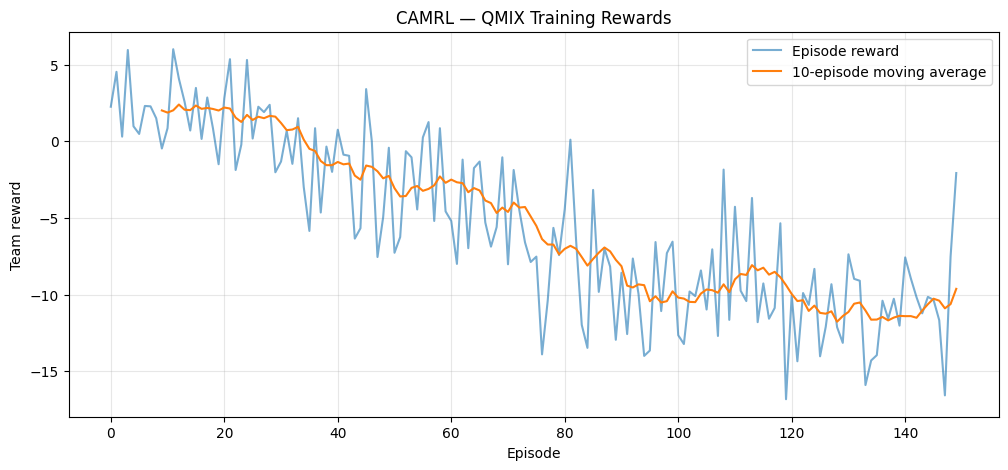

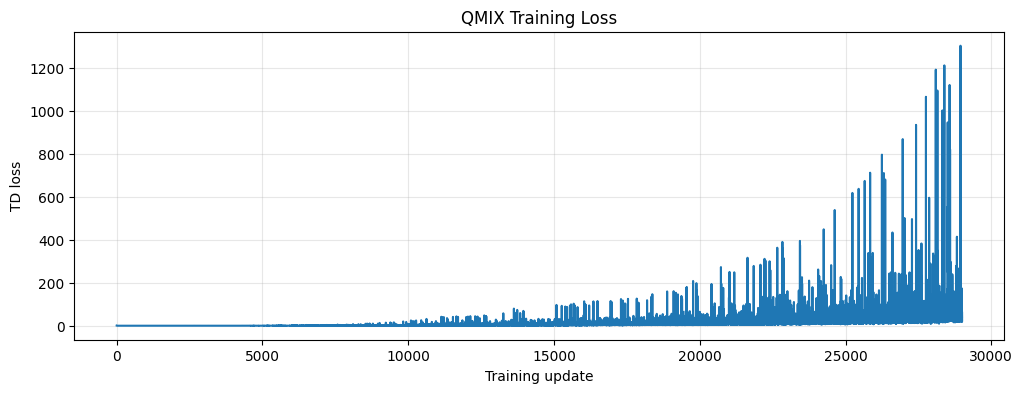

In [47]:
plt.figure(figsize=(12, 5))

plt.plot(episode_rewards, alpha=0.6, label="Episode reward")

if len(episode_rewards) >= 10:
    moving_average = np.convolve(
        episode_rewards,
        np.ones(10) / 10,
        mode="valid"
    )

    plt.plot(
        range(9, len(episode_rewards)),
        moving_average,
        label="10-episode moving average"
    )

plt.title("CAMRL — QMIX Training Rewards")
plt.xlabel("Episode")
plt.ylabel("Team reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(12, 4))
plt.plot(training_losses)
plt.title("QMIX Training Loss")
plt.xlabel("Training update")
plt.ylabel("TD loss")
plt.grid(alpha=0.3)
plt.show()

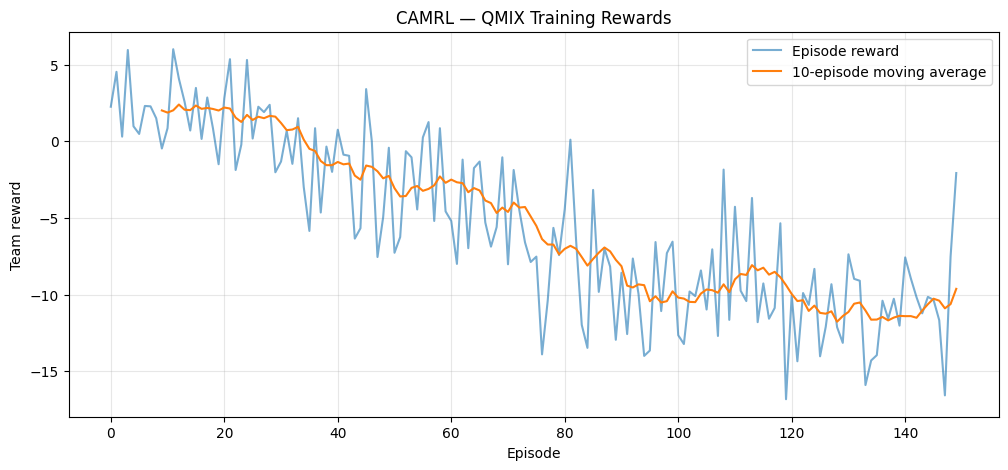

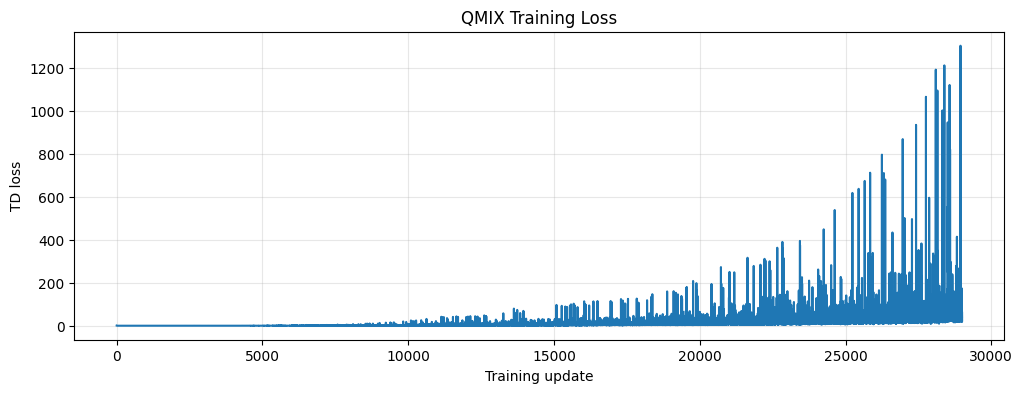

In [48]:
plt.figure(figsize=(12, 5))

plt.plot(episode_rewards, alpha=0.6, label="Episode reward")

if len(episode_rewards) >= 10:
    moving_average = np.convolve(
        episode_rewards,
        np.ones(10) / 10,
        mode="valid"
    )

    plt.plot(
        range(9, len(episode_rewards)),
        moving_average,
        label="10-episode moving average"
    )

plt.title("CAMRL — QMIX Training Rewards")
plt.xlabel("Episode")
plt.ylabel("Team reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(12, 4))
plt.plot(training_losses)
plt.title("QMIX Training Loss")
plt.xlabel("Training update")
plt.ylabel("TD loss")
plt.grid(alpha=0.3)
plt.show()

In [49]:
def evaluate_qmix(num_episodes=50):

    evaluation_env = CooperativeResourceEnv(
        grid_size=12,
        num_agents=4,
        num_resources=10,
        max_steps=200
    )

    results = []

    for ep in range(num_episodes):

        obs = reset_camrl_environment(
            evaluation_env,
            seed=1000 + ep
        )

        total_reward = 0.0

        for _ in range(200):

            actions = select_qmix_actions(
                obs,
                epsilon=0.0
            )

            obs, reward, done, info = step_camrl_environment(
                evaluation_env,
                actions
            )

            total_reward += reward

            if done:
                break

        results.append(total_reward)

    return np.asarray(results)


evaluation_rewards = evaluate_qmix(50)

print("QMIX Evaluation")
print("--------------------------")
print("Episodes:", len(evaluation_rewards))
print("Mean reward:", evaluation_rewards.mean())
print("Std reward:", evaluation_rewards.std())
print("Best reward:", evaluation_rewards.max())
print("Worst reward:", evaluation_rewards.min())

QMIX Evaluation
--------------------------
Episodes: 50
Mean reward: -12.881500352732838
Std reward: 3.846416655092893
Best reward: -5.450000086799264
Worst reward: -19.97500029951334


In [50]:
CAMRL_DIR = Path("/content/drive/MyDrive/CAMRL")

CHECKPOINT_DIR = CAMRL_DIR / "checkpoints"
RESULT_DIR = CAMRL_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

torch.save({
    "agent_networks": agent_networks.state_dict(),
    "mixer": mixer.state_dict(),
    "target_agents": target_agents.state_dict(),
    "target_mixer": target_mixer.state_dict(),
    "local_obs_dim": LOCAL_OBS_DIM,
    "global_state_dim": GLOBAL_STATE_DIM,
    "action_dim": ACTION_DIM,
    "num_agents": NUM_AGENTS,
    "training_steps": TOTAL_TRAINING_STEPS
}, CHECKPOINT_DIR / "qmix_checkpoint.pt")

np.save(
    RESULT_DIR / "qmix_episode_rewards.npy",
    np.asarray(episode_rewards)
)

np.save(
    RESULT_DIR / "qmix_evaluation_rewards.npy",
    evaluation_rewards
)

np.save(
    RESULT_DIR / "qmix_training_losses.npy",
    np.asarray(training_losses)
)

print("QMIX checkpoints and results saved.")

QMIX checkpoints and results saved.


In [51]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
import numpy as np
import copy
import time
from tqdm.auto import tqdm

class CommunicationActor(nn.Module):

    def __init__(
        self,
        obs_dim,
        action_dim,
        message_dim=64,
        hidden_dim=256
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        self.message_encoder = nn.Sequential(
            nn.Linear(hidden_dim, message_dim),
            nn.Tanh()
        )

        self.policy = nn.Sequential(
            nn.Linear(hidden_dim + message_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def generate_message(self, observations):

        features = self.encoder(observations)

        messages = self.message_encoder(features)

        return features, messages

    def forward(self, observations, aggregated_messages):

        features = self.encoder(observations)

        combined = torch.cat(
            [features, aggregated_messages],
            dim=-1
        )

        logits = self.policy(combined)

        return logits

In [52]:
class CommunicationCritic(nn.Module):

    def __init__(self, global_state_dim):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(global_state_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 1)
        )

    def forward(self, global_state):

        return self.network(global_state)

In [53]:
comm_env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=4,
    num_resources=10,
    max_steps=200
)

initial_obs = reset_camrl_environment(comm_env, seed=42)

assert initial_obs.shape == (NUM_AGENTS, LOCAL_OBS_DIM)

MESSAGE_DIM = 64

comm_actors = nn.ModuleList([
    CommunicationActor(
        LOCAL_OBS_DIM,
        ACTION_DIM,
        message_dim=MESSAGE_DIM
    )
    for _ in range(NUM_AGENTS)
]).to(DEVICE)

comm_critic = CommunicationCritic(
    GLOBAL_STATE_DIM
).to(DEVICE)

comm_actor_optimizers = [
    torch.optim.Adam(
        actor.parameters(),
        lr=3e-4
    )
    for actor in comm_actors
]

comm_critic_optimizer = torch.optim.Adam(
    comm_critic.parameters(),
    lr=3e-4
)

print("Communication MAPPO initialised.")
print("Local observation:", LOCAL_OBS_DIM)
print("Global state:", GLOBAL_STATE_DIM)
print("Message dimension:", MESSAGE_DIM)
print("Device:", DEVICE)

Communication MAPPO initialised.
Local observation: 51
Global state: 204
Message dimension: 64
Device: cuda


In [54]:
def communicate_and_select_actions(
    observations,
    deterministic=False
):

    obs_tensor = torch.as_tensor(
        observations,
        dtype=torch.float32,
        device=DEVICE
    )

    features = []
    messages = []

    for i in range(NUM_AGENTS):

        feature, message = comm_actors[i].generate_message(
            obs_tensor[i].unsqueeze(0)
        )

        features.append(feature)
        messages.append(message)

    messages = torch.cat(messages, dim=0)

    actions = []
    log_probs = []
    entropies = []

    for i in range(NUM_AGENTS):

        other_indices = [
            j for j in range(NUM_AGENTS) if j != i
        ]

        received_message = messages[
            other_indices
        ].mean(dim=0, keepdim=True)

        logits = comm_actors[i](
            obs_tensor[i].unsqueeze(0),
            received_message
        )

        distribution = Categorical(logits=logits)

        if deterministic:
            action = logits.argmax(dim=-1)
        else:
            action = distribution.sample()

        actions.append(int(action.item()))
        log_probs.append(
            distribution.log_prob(action).squeeze(0)
        )
        entropies.append(
            distribution.entropy().squeeze(0)
        )

    return (
        np.asarray(actions, dtype=np.int64),
        torch.stack(log_probs),
        torch.stack(entropies)
    )

In [55]:
ROLLOUT_STEPS = 128

def collect_comm_rollout(environment):

    observations = reset_camrl_environment(environment)

    buffer = {
        "obs": [],
        "states": [],
        "actions": [],
        "log_probs": [],
        "rewards": [],
        "values": [],
        "dones": []
    }

    episode_rewards = []
    running_reward = 0.0

    for _ in range(ROLLOUT_STEPS):

        state = observations.reshape(-1)

        actions, log_probs, _ = (
            communicate_and_select_actions(
                observations
            )
        )

        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():
            value = comm_critic(state_tensor).squeeze()

        next_obs, reward, done, info = (
            step_camrl_environment(
                environment,
                actions
            )
        )

        buffer["obs"].append(observations.copy())
        buffer["states"].append(state.copy())
        buffer["actions"].append(actions.copy())
        buffer["log_probs"].append(
            log_probs.detach().cpu().numpy()
        )
        buffer["rewards"].append(reward)
        buffer["values"].append(value.item())
        buffer["dones"].append(float(done))

        running_reward += reward
        observations = next_obs

        if done:

            episode_rewards.append(running_reward)
            running_reward = 0.0

            observations = reset_camrl_environment(
                environment
            )

    return buffer, episode_rewards

In [56]:
def calculate_comm_gae(
    rewards,
    values,
    dones,
    gamma=0.99,
    gae_lambda=0.95
):

    advantages = np.zeros_like(
        rewards,
        dtype=np.float32
    )

    gae = 0.0

    for t in reversed(range(len(rewards))):

        if t == len(rewards) - 1:
            next_value = 0.0
        else:
            next_value = values[t + 1]

        non_terminal = 1.0 - dones[t]

        delta = (
            rewards[t]
            + gamma * next_value * non_terminal
            - values[t]
        )

        gae = (
            delta
            + gamma * gae_lambda * non_terminal * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns

In [57]:
def calculate_comm_gae(
    rewards,
    values,
    dones,
    gamma=0.99,
    gae_lambda=0.95
):

    advantages = np.zeros_like(
        rewards,
        dtype=np.float32
    )

    gae = 0.0

    for t in reversed(range(len(rewards))):

        if t == len(rewards) - 1:
            next_value = 0.0
        else:
            next_value = values[t + 1]

        non_terminal = 1.0 - dones[t]

        delta = (
            rewards[t]
            + gamma * next_value * non_terminal
            - values[t]
        )

        gae = (
            delta
            + gamma * gae_lambda * non_terminal * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns

In [58]:
def update_comm_mappo(buffer):

    obs = torch.tensor(
        np.asarray(buffer["obs"]),
        dtype=torch.float32,
        device=DEVICE
    )

    states = torch.tensor(
        np.asarray(buffer["states"]),
        dtype=torch.float32,
        device=DEVICE
    )

    actions = torch.tensor(
        np.asarray(buffer["actions"]),
        dtype=torch.long,
        device=DEVICE
    )

    old_log_probs = torch.tensor(
        np.asarray(buffer["log_probs"]),
        dtype=torch.float32,
        device=DEVICE
    )

    rewards = np.asarray(
        buffer["rewards"],
        dtype=np.float32
    )

    values = np.asarray(
        buffer["values"],
        dtype=np.float32
    )

    dones = np.asarray(
        buffer["dones"],
        dtype=np.float32
    )

    advantages, returns = calculate_comm_gae(
        rewards,
        values,
        dones
    )

    advantages = torch.tensor(
        advantages,
        dtype=torch.float32,
        device=DEVICE
    )

    returns = torch.tensor(
        returns,
        dtype=torch.float32,
        device=DEVICE
    )

    advantages = (
        advantages - advantages.mean()
    ) / (
        advantages.std(unbiased=False) + 1e-8
    )

    actor_losses = []
    critic_losses = []

    for epoch in range(4):

        for agent_id in range(NUM_AGENTS):

            # Reconstruct messages using current actor parameters
            message_list = []

            for j in range(NUM_AGENTS):

                with torch.no_grad():
                    _, message = comm_actors[j].generate_message(
                        obs[:, j, :]
                    )

                message_list.append(message)

            other_indices = [
                j for j in range(NUM_AGENTS)
                if j != agent_id
            ]

            received_messages = torch.stack(
                [
                    message_list[j]
                    for j in other_indices
                ],
                dim=1
            ).mean(dim=1)

            logits = comm_actors[agent_id](
                obs[:, agent_id, :],
                received_messages
            )

            distribution = Categorical(logits=logits)

            new_log_probs = distribution.log_prob(
                actions[:, agent_id]
            )

            ratio = torch.exp(
                new_log_probs - old_log_probs[:, agent_id]
            )

            surr1 = ratio * advantages

            surr2 = torch.clamp(
                ratio,
                0.8,
                1.2
            ) * advantages

            entropy = distribution.entropy().mean()

            actor_loss = (
                -torch.minimum(surr1, surr2).mean()
                - 0.01 * entropy
            )

            comm_actor_optimizers[agent_id].zero_grad()
            actor_loss.backward()

            torch.nn.utils.clip_grad_norm_(
                comm_actors[agent_id].parameters(),
                0.5
            )

            comm_actor_optimizers[agent_id].step()

            actor_losses.append(actor_loss.item())

        # Centralised critic update
        predicted_values = comm_critic(states).squeeze(-1)

        critic_loss = F.mse_loss(
            predicted_values,
            returns
        )

        comm_critic_optimizer.zero_grad()
        critic_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            comm_critic.parameters(),
            0.5
        )

        comm_critic_optimizer.step()

        critic_losses.append(critic_loss.item())

    return (
        float(np.mean(actor_losses)),
        float(np.mean(critic_losses))
    )

In [59]:
COMM_TOTAL_STEPS = 20000
COMM_ROLLOUT_STEPS = 128

comm_training_env = CooperativeResourceEnv(
    grid_size=12,
    num_agents=4,
    num_resources=10,
    max_steps=200
)

comm_episode_rewards = []
comm_actor_losses = []
comm_critic_losses = []

total_steps = 0
update_number = 0

start_time = time.time()

progress = tqdm(total=COMM_TOTAL_STEPS)

while total_steps < COMM_TOTAL_STEPS:

    buffer, completed_rewards = collect_comm_rollout(
        comm_training_env
    )

    actor_loss, critic_loss = update_comm_mappo(buffer)

    comm_episode_rewards.extend(completed_rewards)
    comm_actor_losses.append(actor_loss)
    comm_critic_losses.append(critic_loss)

    total_steps += len(buffer["rewards"])
    update_number += 1

    progress.update(len(buffer["rewards"]))

    if update_number % 10 == 0:

        recent_reward = (
            np.mean(comm_episode_rewards[-10:])
            if comm_episode_rewards else float("nan")
        )

        print(
            f"\nUpdate {update_number} | "
            f"Steps {total_steps} | "
            f"Mean reward {recent_reward:.3f} | "
            f"Actor loss {actor_loss:.4f} | "
            f"Critic loss {critic_loss:.4f}"
        )

progress.close()

print(
    "Training time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)

  0%|          | 0/20000 [00:00<?, ?it/s]


Update 10 | Steps 1280 | Mean reward nan | Actor loss -0.0187 | Critic loss 0.4149

Update 20 | Steps 2560 | Mean reward nan | Actor loss -0.0158 | Critic loss 0.5307

Update 30 | Steps 3840 | Mean reward nan | Actor loss -0.0156 | Critic loss 0.2050

Update 40 | Steps 5120 | Mean reward nan | Actor loss -0.0134 | Critic loss 0.2732

Update 50 | Steps 6400 | Mean reward nan | Actor loss -0.0115 | Critic loss 0.2365

Update 60 | Steps 7680 | Mean reward nan | Actor loss -0.0149 | Critic loss 0.1247

Update 70 | Steps 8960 | Mean reward nan | Actor loss -0.0150 | Critic loss 0.5161

Update 80 | Steps 10240 | Mean reward nan | Actor loss -0.0192 | Critic loss 0.1044

Update 90 | Steps 11520 | Mean reward nan | Actor loss -0.0172 | Critic loss 0.4483

Update 100 | Steps 12800 | Mean reward nan | Actor loss -0.0181 | Critic loss 0.1717

Update 110 | Steps 14080 | Mean reward nan | Actor loss -0.0174 | Critic loss 0.2827

Update 120 | Steps 15360 | Mean reward nan | Actor loss -0.0132 | Cri

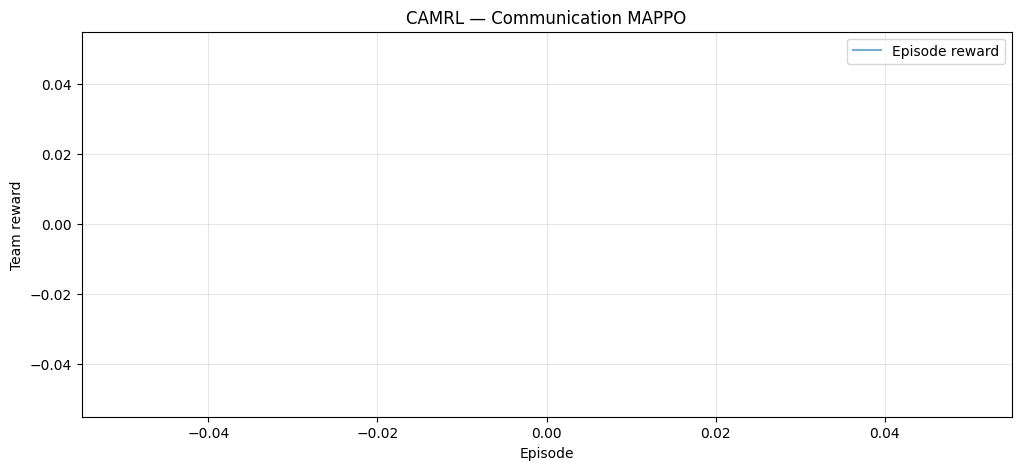

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    comm_episode_rewards,
    alpha=0.6,
    label="Episode reward"
)

if len(comm_episode_rewards) >= 10:

    moving_avg = np.convolve(
        comm_episode_rewards,
        np.ones(10) / 10,
        mode="valid"
    )

    plt.plot(
        range(9, len(comm_episode_rewards)),
        moving_avg,
        label="10-episode average"
    )

plt.title("CAMRL — Communication MAPPO")
plt.xlabel("Episode")
plt.ylabel("Team reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [61]:
from pathlib import Path

CAMRL_DIR = Path(
    "/content/drive/MyDrive/CAMRL"
)

CHECKPOINT_DIR = CAMRL_DIR / "checkpoints"
RESULT_DIR = CAMRL_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

torch.save({
    "actors": comm_actors.state_dict(),
    "critic": comm_critic.state_dict(),
    "local_obs_dim": LOCAL_OBS_DIM,
    "global_state_dim": GLOBAL_STATE_DIM,
    "action_dim": ACTION_DIM,
    "num_agents": NUM_AGENTS,
    "message_dim": MESSAGE_DIM,
    "training_steps": total_steps
}, CHECKPOINT_DIR / "comm_mappo_checkpoint.pt")

np.save(
    RESULT_DIR / "comm_mappo_episode_rewards.npy",
    np.asarray(comm_episode_rewards)
)

np.save(
    RESULT_DIR / "comm_mappo_actor_losses.npy",
    np.asarray(comm_actor_losses)
)

np.save(
    RESULT_DIR / "comm_mappo_critic_losses.npy",
    np.asarray(comm_critic_losses)
)

print("Comm-MAPPO checkpoint and results saved.")

Comm-MAPPO checkpoint and results saved.


In [62]:
import os
import random
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CAMRL_DIR = Path("/content/drive/MyDrive/CAMRL")
CHECKPOINT_DIR = CAMRL_DIR / "checkpoints"
RESULT_DIR = CAMRL_DIR / "results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

NUM_EVAL_SEEDS = 5
EPISODES_PER_SEED = 50
MAX_EPISODE_STEPS = 200

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_evaluation_env():
    return CooperativeResourceEnv(
        grid_size=12,
        num_agents=4,
        num_resources=10,
        max_steps=MAX_EPISODE_STEPS
    )

print("Evaluation device:", DEVICE)
print("Evaluation episodes per algorithm:",
      NUM_EVAL_SEEDS * EPISODES_PER_SEED)

Evaluation device: cuda
Evaluation episodes per algorithm: 250


In [63]:
def ippo_policy(observations):
    """
    Connect this function to your trained IPPO actor networks.
    Return one discrete action per agent.
    """
    raise NotImplementedError(
        "Connect your trained IPPO networks here."
    )


def mappo_policy(observations):
    """
    Connect this function to your trained MAPPO actors.
    Return one discrete action per agent.
    """
    raise NotImplementedError(
        "Connect your trained MAPPO actors here."
    )


def qmix_policy(observations):
    actions = []

    with torch.no_grad():
        for agent_id in range(NUM_AGENTS):
            obs_tensor = torch.as_tensor(
                observations[agent_id],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            q_values = agent_networks[agent_id](obs_tensor)
            actions.append(int(q_values.argmax(dim=-1).item()))

    return np.asarray(actions, dtype=np.int64)


def comm_mappo_policy(observations):
    actions, _, _ = communicate_and_select_actions(
        observations,
        deterministic=True
    )

    return actions


POLICIES = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "QMIX": qmix_policy,
    "Comm-MAPPO": comm_mappo_policy
}

In [64]:
def evaluate_policy(
    policy,
    algorithm_name,
    num_seeds=NUM_EVAL_SEEDS,
    episodes_per_seed=EPISODES_PER_SEED
):
    records = []

    for seed in range(num_seeds):

        set_seed(1000 + seed)
        env = make_evaluation_env()

        for episode in range(episodes_per_seed):

            episode_seed = 10000 + seed * episodes_per_seed + episode

            try:
                reset_result = env.reset(seed=episode_seed)
            except TypeError:
                reset_result = env.reset()

            observations = (
                reset_result[0]
                if isinstance(reset_result, tuple)
                else reset_result
            )

            observations = np.asarray(
                observations,
                dtype=np.float32
            )

            total_reward = 0.0
            episode_length = 0
            terminated = False
            truncated = False

            for step in range(MAX_EPISODE_STEPS):

                actions = np.asarray(
                    policy(observations),
                    dtype=np.int64
                )

                if actions.shape != (NUM_AGENTS,):
                    raise ValueError(
                        f"{algorithm_name} returned action shape "
                        f"{actions.shape}; expected ({NUM_AGENTS},)"
                    )

                result = env.step(actions)

                if len(result) == 5:
                    next_obs, rewards, terminated_value, truncated_value, info = result

                    terminated = bool(
                        np.asarray(terminated_value).any()
                    )

                    truncated = bool(
                        np.asarray(truncated_value).any()
                    )

                elif len(result) == 4:
                    next_obs, rewards, done_value, info = result

                    # Older Gym-style API: completion reason may not
                    # be available separately.
                    terminated = bool(
                        np.asarray(done_value).any()
                    )
                    truncated = False

                else:
                    raise ValueError("Unexpected environment API.")

                observations = np.asarray(
                    next_obs,
                    dtype=np.float32
                )

                total_reward += float(
                    np.asarray(rewards, dtype=np.float32).mean()
                )

                episode_length += 1

                if terminated or truncated:
                    break

            records.append({
                "algorithm": algorithm_name,
                "seed": seed,
                "episode": episode,
                "reward": total_reward,
                "episode_length": episode_length,
                "success": int(terminated),
                "truncated": int(truncated)
            })

    return pd.DataFrame(records)

In [65]:
qmix_path = CHECKPOINT_DIR / "qmix_checkpoint.pt"
comm_path = CHECKPOINT_DIR / "comm_mappo_checkpoint.pt"

if qmix_path.exists():
    qmix_checkpoint = torch.load(
        qmix_path,
        map_location=DEVICE,
        weights_only=False
    )

    agent_networks.load_state_dict(
        qmix_checkpoint["agent_networks"]
    )

    mixer.load_state_dict(
        qmix_checkpoint["mixer"]
    )

    print("QMIX checkpoint loaded.")
else:
    print("QMIX checkpoint not found. Train QMIX before evaluation.")

if comm_path.exists():
    comm_checkpoint = torch.load(
        comm_path,
        map_location=DEVICE,
        weights_only=False
    )

    comm_actors.load_state_dict(
        comm_checkpoint["actors"]
    )

    comm_critic.load_state_dict(
        comm_checkpoint["critic"]
    )

    print("Comm-MAPPO checkpoint loaded.")
else:
    print("Comm-MAPPO checkpoint not found. Train Comm-MAPPO first.")

for model in list(agent_networks) + list(comm_actors):
    model.eval()

mixer.eval()
comm_critic.eval()

QMIX checkpoint loaded.
Comm-MAPPO checkpoint loaded.


CommunicationCritic(
  (network): Sequential(
    (0): Linear(in_features=204, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)

In [68]:
# Example adapter pattern:

def ippo_policy(observations):
    actions = []
    with torch.no_grad():
        for i in range(NUM_AGENTS):
            obs = torch.as_tensor(
                observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            logits = YOUR_IPPO_ACTORS[i](obs)
            action = logits.argmax(dim=-1).item()
            actions.append(action)
    return np.asarray(actions, dtype=np.int64)


def mappo_policy(observations):
    actions = []
    with torch.no_grad():
        for i in range(NUM_AGENTS):
            obs = torch.as_tensor(
                observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            logits = YOUR_MAPPO_ACTORS[i](obs)
            action = logits.argmax(dim=-1).item()
            actions.append(action)
    return np.asarray(actions, dtype=np.int64)

In [69]:
benchmark_results = []

for algorithm_name, policy in POLICIES.items():

    print(f"\nEvaluating {algorithm_name}...")

    try:
        result = evaluate_policy(
            policy=policy,
            algorithm_name=algorithm_name
        )

        benchmark_results.append(result)

        print(
            f"{algorithm_name}: "
            f"mean reward = {result['reward'].mean():.3f}, "
            f"success rate = {result['success'].mean():.2%}"
        )

    except NotImplementedError as error:
        print(f"Skipping {algorithm_name}: {error}")

    except Exception as error:
        print(f"Evaluation failed for {algorithm_name}: {error}")
        raise

if not benchmark_results:
    raise RuntimeError("No algorithms were successfully evaluated.")

results_df = pd.concat(
    benchmark_results,
    ignore_index=True
)

results_df.to_csv(
    RESULT_DIR / "camrl_episode_benchmark.csv",
    index=False
)

print("\nBenchmark episodes saved.")
display(results_df.head())


Evaluating IPPO...
Skipping IPPO: Connect your trained IPPO networks here.

Evaluating MAPPO...
Skipping MAPPO: Connect your trained MAPPO actors here.

Evaluating QMIX...
QMIX: mean reward = -13.400, success rate = 0.00%

Evaluating Comm-MAPPO...
Comm-MAPPO: mean reward = 0.000, success rate = 0.00%

Benchmark episodes saved.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,seed,episode,reward,episode_length,success,truncated
0,QMIX,0,0,-14.525001,200,0,1
1,QMIX,0,1,-9.975000,200,0,1
2,QMIX,0,2,-12.300000,200,0,1
3,QMIX,0,3,-11.725000,200,0,1
4,QMIX,0,4,-8.975000,200,0,1


In [70]:
from collections import Counter

def diagnose_policy(policy, name, seed=123):

    env = make_evaluation_env()

    obs = reset_camrl_environment(env, seed=seed)

    total_reward = 0.0
    action_counts = Counter()
    reward_values = []
    completed = False

    print(f"\n{'='*50}")
    print(f"Testing: {name}")
    print(f"{'='*50}")

    for step in range(200):

        actions = np.asarray(policy(obs), dtype=np.int64)

        if actions.shape != (NUM_AGENTS,):
            raise ValueError(f"Invalid actions: {actions}")

        action_counts.update(actions.tolist())

        result = env.step(actions)

        if len(result) == 5:
            next_obs, rewards, terminated, truncated, info = result
            terminated = bool(np.asarray(terminated).any())
            truncated = bool(np.asarray(truncated).any())
        else:
            next_obs, rewards, done, info = result
            terminated = bool(np.asarray(done).any())
            truncated = False

        reward = float(np.asarray(rewards).mean())

        total_reward += reward
        reward_values.append(reward)

        obs = np.asarray(next_obs, dtype=np.float32)

        if step < 10:
            print(
                f"Step {step+1}: actions={actions}, "
                f"reward={reward:.3f}"
            )

        if terminated:
            completed = True
            break

        if truncated:
            break

    print("\nSummary")
    print("Total reward:", round(total_reward, 3))
    print("Steps:", len(reward_values))
    print("Completed:", completed)
    print("Action counts:", dict(action_counts))
    print("Reward min:", min(reward_values))
    print("Reward max:", max(reward_values))
    print("Non-zero reward steps:",
          sum(abs(r) > 1e-8 for r in reward_values))

    return {
        "algorithm": name,
        "total_reward": total_reward,
        "steps": len(reward_values),
        "completed": completed,
        "action_counts": dict(action_counts),
        "nonzero_reward_steps": sum(
            abs(r) > 1e-8 for r in reward_values
        )
    }


def random_policy(observations):
    return np.random.randint(
        0, ACTION_DIM,
        size=NUM_AGENTS
    )


diagnostic_results = []

diagnostic_results.append(
    diagnose_policy(random_policy, "Random")
)

diagnostic_results.append(
    diagnose_policy(qmix_policy, "QMIX")
)

diagnostic_results.append(
    diagnose_policy(comm_mappo_policy, "Comm-MAPPO")
)

display(pd.DataFrame(diagnostic_results))


Testing: Random
Step 1: actions=[5 4 4 5], reward=0.000
Step 2: actions=[3 2 0 4], reward=-0.025
Step 3: actions=[3 1 3 2], reward=-0.050
Step 4: actions=[5 1 2 4], reward=-0.025
Step 5: actions=[0 1 4 2], reward=-0.025
Step 6: actions=[1 1 3 4], reward=-0.025
Step 7: actions=[5 1 0 0], reward=0.000
Step 8: actions=[3 1 3 3], reward=0.000
Step 9: actions=[3 5 1 1], reward=0.000
Step 10: actions=[2 3 3 3], reward=0.000

Summary
Total reward: 4.15
Steps: 200
Completed: False
Action counts: {5: 144, 4: 115, 3: 145, 2: 117, 0: 134, 1: 145}
Reward min: -0.05000000074505806
Reward max: 2.0
Non-zero reward steps: 67

Testing: QMIX
Step 1: actions=[1 5 4 4], reward=0.000
Step 2: actions=[1 5 5 4], reward=-0.025
Step 3: actions=[1 5 5 4], reward=-0.050
Step 4: actions=[1 5 5 4], reward=-0.050
Step 5: actions=[1 5 5 4], reward=-0.050
Step 6: actions=[1 5 5 4], reward=-0.050
Step 7: actions=[1 5 5 4], reward=-0.050
Step 8: actions=[1 5 5 4], reward=-0.050
Step 9: actions=[1 5 5 4], reward=-0.050

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,total_reward,steps,completed,action_counts,nonzero_reward_steps
0,Random,4.15,200,False,"{5: 144, 4: 115, 3: 145, 2: 117, 0: 134, 1: 145}",67
1,QMIX,-10.80,200,False,"{1: 199, 5: 355, 4: 246}",199
2,Comm-MAPPO,0.00,200,False,{5: 800},0


In [71]:
def inspect_policy_actions(policy, name, num_samples=100):

    env = make_evaluation_env()
    obs = reset_camrl_environment(env, seed=42)

    action_samples = []

    for _ in range(num_samples):

        actions = policy(obs)

        action_samples.extend(actions.tolist())

        # Advance environment to obtain changing observations
        obs, _, done, _ = step_camrl_environment(
            env, actions
        )

        if done:
            obs = reset_camrl_environment(env)

    counts = Counter(action_samples)

    print(f"\n{name}")
    print("Action distribution:", dict(counts))

    for action_id in range(ACTION_DIM):
        print(
            f"Action {action_id}: "
            f"{counts.get(action_id, 0)} selections"
        )


inspect_policy_actions(qmix_policy, "QMIX")
inspect_policy_actions(comm_mappo_policy, "Comm-MAPPO")


QMIX
Action distribution: {4: 34, 2: 172, 1: 125, 3: 69}
Action 0: 0 selections
Action 1: 125 selections
Action 2: 172 selections
Action 3: 69 selections
Action 4: 34 selections
Action 5: 0 selections

Comm-MAPPO
Action distribution: {5: 400}
Action 0: 0 selections
Action 1: 0 selections
Action 2: 0 selections
Action 3: 0 selections
Action 4: 0 selections
Action 5: 400 selections


In [72]:
for filename in [
    "qmix_checkpoint.pt",
    "comm_mappo_checkpoint.pt"
]:

    path = CHECKPOINT_DIR / filename

    print("\nCheckpoint:", filename)

    if not path.exists():
        print("MISSING")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    for key in [
        "local_obs_dim",
        "global_state_dim",
        "action_dim",
        "num_agents",
        "training_steps",
        "message_dim"
    ]:
        if key in checkpoint:
            print(f"{key}: {checkpoint[key]}")


Checkpoint: qmix_checkpoint.pt
local_obs_dim: 51
global_state_dim: 204
action_dim: 6
num_agents: 4
training_steps: 30000

Checkpoint: comm_mappo_checkpoint.pt
local_obs_dim: 51
global_state_dim: 204
action_dim: 6
num_agents: 4
training_steps: 20096
message_dim: 64


In [73]:
import torch
import numpy as np
import pandas as pd

ACTION_NAMES = [
    "Stay", "Up", "Down", "Left", "Right", "Collect"
]

# Fresh initial environment
debug_env = make_evaluation_env()
debug_obs = reset_camrl_environment(debug_env, seed=42)

print("Observation shape:", debug_obs.shape)

# 1. Inspect QMIX Q-values
print("\n========== QMIX Q-VALUES ==========")

with torch.no_grad():
    for i in range(NUM_AGENTS):

        x = torch.tensor(
            debug_obs[i],
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        q_values = agent_networks[i](x).squeeze(0)
        probabilities = torch.softmax(q_values, dim=-1)

        print(f"\nAgent {i}")
        for j in range(ACTION_DIM):
            print(
                f"{ACTION_NAMES[j]:8s} "
                f"Q={q_values[j].item():.4f} "
                f"P={probabilities[j].item():.4f}"
            )

# 2. Inspect Comm-MAPPO action probabilities
print("\n========== COMM-MAPPO LOGITS ==========")

obs_tensor = torch.tensor(
    debug_obs,
    dtype=torch.float32,
    device=DEVICE
)

with torch.no_grad():

    message_list = []

    for i in range(NUM_AGENTS):
        _, message = comm_actors[i].generate_message(
            obs_tensor[i].unsqueeze(0)
        )
        message_list.append(message)

    messages = torch.cat(message_list, dim=0)

    for i in range(NUM_AGENTS):

        others = [j for j in range(NUM_AGENTS) if j != i]

        received = messages[others].mean(
            dim=0,
            keepdim=True
        )

        logits = comm_actors[i](
            obs_tensor[i].unsqueeze(0),
            received
        )

        probs = torch.softmax(logits, dim=-1).squeeze(0)

        print(f"\nAgent {i}")

        for j in range(ACTION_DIM):
            print(
                f"{ACTION_NAMES[j]:8s} "
                f"P={probs[j].item():.4f}"
            )

Observation shape: (4, 51)

========== QMIX Q-VALUES ==========

Agent 0
Stay     Q=0.1671 P=0.1662
Up       Q=0.1585 P=0.1648
Down     Q=0.1750 P=0.1675
Left     Q=0.1754 P=0.1676
Right    Q=0.1777 P=0.1680
Collect  Q=0.1644 P=0.1658

Agent 1
Stay     Q=0.2359 P=0.1664
Up       Q=0.2135 P=0.1627
Down     Q=0.2899 P=0.1756
Left     Q=0.2521 P=0.1691
Right    Q=0.2041 P=0.1612
Collect  Q=0.2275 P=0.1650

Agent 2
Stay     Q=0.1567 P=0.1665
Up       Q=0.1760 P=0.1697
Down     Q=0.1330 P=0.1626
Left     Q=0.1641 P=0.1677
Right    Q=0.1568 P=0.1665
Collect  Q=0.1602 P=0.1671

Agent 3
Stay     Q=0.2738 P=0.1635
Up       Q=0.3117 P=0.1698
Down     Q=0.3006 P=0.1680
Left     Q=0.2743 P=0.1636
Right    Q=0.3157 P=0.1705
Collect  Q=0.2796 P=0.1645

========== COMM-MAPPO LOGITS ==========

Agent 0
Stay     P=0.0044
Up       P=0.0005
Down     P=0.0110
Left     P=0.0003
Right    P=0.0001
Collect  P=0.9838

Agent 1
Stay     P=0.0000
Up       P=0.0019
Down     P=0.0047
Left     P=0.0003
Right    P=0.

In [74]:
test_env = make_evaluation_env()
test_obs = reset_camrl_environment(test_env, seed=42)

print("Initial observations:", test_obs.shape)

print("\nEnvironment attributes:")

for key, value in vars(test_env).items():
    if key in [
        "agents",
        "resources",
        "obstacles",
        "step_count",
        "current_step",
        "collected_count",
        "max_steps"
    ]:
        print(key, "=", repr(value)[:1500])

print("\nTesting all agents using Collect...")

for step in range(5):

    actions = np.full(
        NUM_AGENTS,
        5,
        dtype=np.int64
    )

    next_obs, reward, done, info = step_camrl_environment(
        test_env,
        actions
    )

    print(
        f"Step {step+1}: "
        f"Reward={reward:.3f}, "
        f"Done={done}"
    )

    test_obs = next_obs

    if done:
        break

Initial observations: (4, 51)

Environment attributes:
max_steps = 200
step_count = 0
agents = [{'position': [6, 3], 'energy': 100, 'collected': 0}, {'position': [10, 7], 'energy': 100, 'collected': 0}, {'position': [4, 6], 'energy': 100, 'collected': 0}, {'position': [9, 2], 'energy': 100, 'collected': 0}]
resources = [{'position': [6, 10], 'collected': False, 'special': True}, {'position': [4, 3], 'collected': False, 'special': False}, {'position': [7, 7], 'collected': False, 'special': False}, {'position': [2, 5], 'collected': False, 'special': True}, {'position': [4, 1], 'collected': False, 'special': False}, {'position': [7, 11], 'collected': False, 'special': False}, {'position': [5, 1], 'collected': False, 'special': True}, {'position': [11, 4], 'collected': False, 'special': False}, {'position': [0, 11], 'collected': False, 'special': False}, {'position': [9, 5], 'collected': False, 'special': True}]
obstacles = {(1, 3), (0, 10), (6, 4), (4, 2), (8, 11), (8, 6), (10, 9), (8, 2)

In [75]:
test_env = make_evaluation_env()
obs = reset_camrl_environment(test_env, seed=42)

print("Initial environment:")
for key, value in vars(test_env).items():
    print(key, ":", repr(value)[:1000])

print("\nCollect-action test:")

for step in range(5):

    actions = np.array([5, 5, 5, 5])

    obs, reward, done, info = step_camrl_environment(
        test_env, actions
    )

    print(
        f"Step {step+1} | "
        f"Reward: {reward:.4f} | "
        f"Done: {done}"
    )

Initial environment:
grid_size : 12
num_agents : 4
num_resources : 10
max_steps : 200
initial_energy : 100
action_size : 6
action_space : [Discrete(6), Discrete(6), Discrete(6), Discrete(6)]
observation_size : 41
observation_spaces : [Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32)]
step_count : 0
agents : [{'position': [6, 3], 'energy': 100, 'collected': 0}, {'position': [10, 7], 'energy': 100, 'collected': 0}, {'position': [4, 6], 'energy': 100, 'collected': 0}, {'position': [9, 2], 'energy': 100, 'collected': 0}]
resources : [{'position': [6, 10], 'collected': False, 'special': True}, {'position': [4, 3], 'collected': False, 'special': False}, {'position': [7, 7], 'collected': False, 'special': False}, {'position': [2, 5], 'collected': False, 'special': True}, {'position': [4, 1], 'collected': False, 'special': False}, {'position': [7, 11], 'collected': False, 'special': False}, {'position': [5, 1], 'coll

In [76]:
print("QMIX replay buffer:", len(replay_buffer))
print("QMIX training updates:", len(training_losses))

if training_losses:
    print("Initial loss:", training_losses[0])
    print("Final loss:", training_losses[-1])
    print("Mean last 100 losses:", np.mean(training_losses[-100:]))

if episode_rewards:
    print("Mean last 20 training rewards:",
          np.mean(episode_rewards[-20:]))

QMIX replay buffer: 30000
QMIX training updates: 29001
Initial loss: 0.8613909482955933
Final loss: 24.214929580688477
Mean last 100 losses: 68.70181127548217
Mean last 20 training rewards: -10.507500264421106


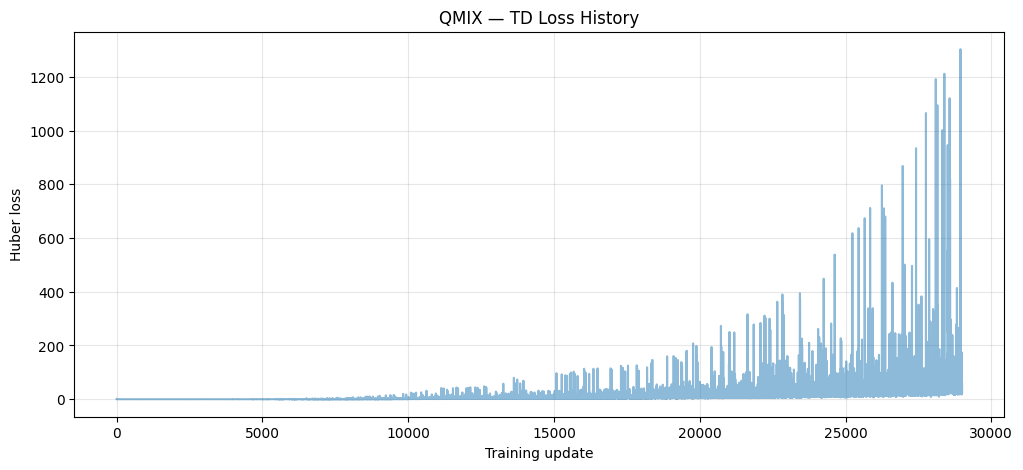

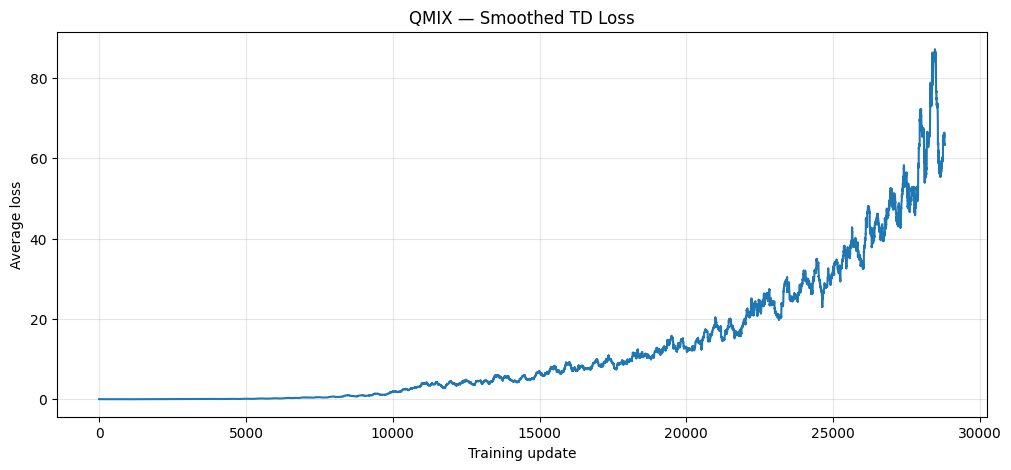

In [77]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 5))
plt.plot(training_losses, alpha=0.5)
plt.title("QMIX — TD Loss History")
plt.xlabel("Training update")
plt.ylabel("Huber loss")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 5))
window = 200

if len(training_losses) >= window:
    smoothed = np.convolve(
        training_losses,
        np.ones(window) / window,
        mode="valid"
    )
    plt.plot(smoothed)

plt.title("QMIX — Smoothed TD Loss")
plt.xlabel("Training update")
plt.ylabel("Average loss")
plt.grid(alpha=0.3)
plt.show()

In [78]:
test_env = make_evaluation_env()
obs = reset_camrl_environment(test_env, seed=42)

print("Initial environment state:")

for key, value in vars(test_env).items():
    print(key, ":", repr(value)[:1000])

print("\nAll-agent Collect test:")

for step in range(5):

    actions = np.array([5, 5, 5, 5])

    obs, reward, done, info = step_camrl_environment(
        test_env, actions
    )

    print(
        f"Step {step+1} | "
        f"Reward={reward:.4f} | "
        f"Done={done}"
    )

Initial environment state:
grid_size : 12
num_agents : 4
num_resources : 10
max_steps : 200
initial_energy : 100
action_size : 6
action_space : [Discrete(6), Discrete(6), Discrete(6), Discrete(6)]
observation_size : 41
observation_spaces : [Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32)]
step_count : 0
agents : [{'position': [6, 3], 'energy': 100, 'collected': 0}, {'position': [10, 7], 'energy': 100, 'collected': 0}, {'position': [4, 6], 'energy': 100, 'collected': 0}, {'position': [9, 2], 'energy': 100, 'collected': 0}]
resources : [{'position': [6, 10], 'collected': False, 'special': True}, {'position': [4, 3], 'collected': False, 'special': False}, {'position': [7, 7], 'collected': False, 'special': False}, {'position': [2, 5], 'collected': False, 'special': True}, {'position': [4, 1], 'collected': False, 'special': False}, {'position': [7, 11], 'collected': False, 'special': False}, {'position': [5, 1],

In [80]:
from gymnasium.spaces import Box
import numpy as np

def synchronise_environment_metadata(env):

    observations, _ = env.reset(seed=42)

    observations = np.asarray(
        observations,
        dtype=np.float32
    )

    actual_obs_dim = observations.shape[-1]

    env.observation_size = actual_obs_dim

    env.observation_spaces = [
        Box(
            low=-np.inf,
            high=np.inf,
            shape=(actual_obs_dim,),
            dtype=np.float32
        )
        for _ in range(env.num_agents)
    ]

    return actual_obs_dim


test_env = make_evaluation_env()

actual_dim = synchronise_environment_metadata(test_env)

print("Corrected observation size:", test_env.observation_size)
print("Observation space:", test_env.observation_spaces[0])
observations, info = test_env.reset()

observations = np.asarray(
    observations,
    dtype=np.float32
)

print("Actual observations:", observations.shape)
print("Agent 0 observation:", observations[0].shape)

assert observations.shape == (4, 51)
print("Observation dimensions verified successfully.")

Corrected observation size: 51
Observation space: Box(-inf, inf, (51,), float32)
Actual observations: (4, 51)
Agent 0 observation: (51,)
Observation dimensions verified successfully.


In [81]:
test_env = make_evaluation_env()
synchronise_environment_metadata(test_env)

resource = next(
    r for r in test_env.resources
    if not r["special"] and not r["collected"]
)

test_env.agents[0]["position"] = list(resource["position"])

print("Resource position:", resource["position"])

actions = np.array([5, 0, 0, 0])

obs, rewards, terminated, truncated, info = test_env.step(actions)

print("Resource collected:", resource["collected"])
print("Rewards:", rewards)
print("Agent states:", test_env.agents)

assert resource["collected"], "Normal resource collection failed!"

print("Normal resource collection works.")

Resource position: [4, 3]
Resource collected: True
Rewards: [2. 2. 2. 2.]
Agent states: [{'position': [4, 3], 'energy': 99.5, 'collected': 1}, {'position': [10, 7], 'energy': 99.8, 'collected': 0}, {'position': [4, 6], 'energy': 99.8, 'collected': 0}, {'position': [9, 2], 'energy': 99.8, 'collected': 0}]
Normal resource collection works.


In [82]:
test_env = make_evaluation_env()
synchronise_environment_metadata(test_env)

resource = next(
    r for r in test_env.resources
    if r["special"] and not r["collected"]
)

position = list(resource["position"])

test_env.agents[0]["position"] = position.copy()
test_env.agents[1]["position"] = position.copy()

actions = np.array([5, 5, 0, 0])

obs, rewards, terminated, truncated, info = test_env.step(actions)

print("Special resource collected:", resource["collected"])
print("Rewards:", rewards)
print("Agent states:", test_env.agents)

assert resource["collected"], "Special resource cooperation failed!"

print("Special resource cooperation works.")

Special resource collected: True
Rewards: [5. 5. 5. 5.]
Agent states: [{'position': [6, 10], 'energy': 99.5, 'collected': 1}, {'position': [6, 10], 'energy': 99.5, 'collected': 1}, {'position': [4, 6], 'energy': 99.8, 'collected': 0}, {'position': [9, 2], 'energy': 99.8, 'collected': 0}]
Special resource cooperation works.


In [83]:
test_env = make_evaluation_env()
synchronise_environment_metadata(test_env)

resource = next(
    r for r in test_env.resources
    if not r["special"] and not r["collected"]
)

test_env.agents[0]["position"] = list(resource["position"])

actions = np.array([5, 0, 0, 0])

obs, rewards, terminated, truncated, info = test_env.step(actions)

print("Normal resource collected:", resource["collected"])
print("Rewards:", rewards)
print("Agent states:", test_env.agents)

assert resource["collected"]
print("Normal resource collection works.")

Normal resource collected: True
Rewards: [2. 2. 2. 2.]
Agent states: [{'position': [4, 3], 'energy': 99.5, 'collected': 1}, {'position': [10, 7], 'energy': 99.8, 'collected': 0}, {'position': [4, 6], 'energy': 99.8, 'collected': 0}, {'position': [9, 2], 'energy': 99.8, 'collected': 0}]
Normal resource collection works.


In [84]:
import shutil
from pathlib import Path

old_checkpoint = CHECKPOINT_DIR / "qmix_checkpoint.pt"
backup_checkpoint = CHECKPOINT_DIR / "qmix_v1_unstable.pt"

if old_checkpoint.exists() and not backup_checkpoint.exists():
    shutil.copy2(old_checkpoint, backup_checkpoint)

print("Original QMIX v1 checkpoint preserved.")

Original QMIX v1 checkpoint preserved.


In [85]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random
import copy
import time
from collections import deque
from tqdm.auto import tqdm

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_AGENTS = 4
LOCAL_OBS_DIM = 51
GLOBAL_STATE_DIM = 204
ACTION_DIM = 6

GAMMA = 0.99
LEARNING_RATE = 1e-4
BATCH_SIZE = 128
TAU = 0.005
GRAD_CLIP = 10.0
REWARD_SCALE = 0.2

EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY = 20000

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Device: cuda
GPU: NVIDIA L4


In [86]:
class QMIXAgent(nn.Module):

    def __init__(self, obs_dim, action_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(obs_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, action_dim)
        )

    def forward(self, obs):
        return self.network(obs)

In [87]:
class QMIXMixer(nn.Module):

    def __init__(self, num_agents, state_dim, embed_dim=64):
        super().__init__()

        self.num_agents = num_agents
        self.embed_dim = embed_dim

        self.hyper_w1 = nn.Linear(
            state_dim,
            num_agents * embed_dim
        )

        self.hyper_b1 = nn.Linear(
            state_dim,
            embed_dim
        )

        self.hyper_w2 = nn.Linear(
            state_dim,
            embed_dim
        )

        self.hyper_b2 = nn.Sequential(
            nn.Linear(state_dim, embed_dim),
            nn.ReLU(),
            nn.Linear(embed_dim, 1)
        )

    def forward(self, agent_qs, states):

        batch_size = agent_qs.shape[0]

        w1 = F.softplus(
            self.hyper_w1(states)
        ).view(
            batch_size,
            self.num_agents,
            self.embed_dim
        )

        b1 = self.hyper_b1(states).view(
            batch_size, 1, self.embed_dim
        )

        hidden = F.elu(
            torch.bmm(
                agent_qs.unsqueeze(1),
                w1
            ) + b1
        )

        w2 = F.softplus(
            self.hyper_w2(states)
        ).view(
            batch_size,
            self.embed_dim,
            1
        )

        b2 = self.hyper_b2(states).view(
            batch_size, 1, 1
        )

        total_q = torch.bmm(hidden, w2) + b2

        return total_q.squeeze(-1).squeeze(-1)

In [88]:
qmix_v2_agents = nn.ModuleList([
    QMIXAgent(LOCAL_OBS_DIM, ACTION_DIM)
    for _ in range(NUM_AGENTS)
]).to(DEVICE)

qmix_v2_mixer = QMIXMixer(
    NUM_AGENTS,
    GLOBAL_STATE_DIM
).to(DEVICE)

qmix_v2_target_agents = copy.deepcopy(
    qmix_v2_agents
).to(DEVICE)

qmix_v2_target_mixer = copy.deepcopy(
    qmix_v2_mixer
).to(DEVICE)

qmix_v2_optimizer = torch.optim.Adam(
    list(qmix_v2_agents.parameters()) +
    list(qmix_v2_mixer.parameters()),
    lr=LEARNING_RATE
)

print("QMIX v2 networks initialised.")

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in list(qmix_v2_agents.parameters())
        + list(qmix_v2_mixer.parameters())
    )
)

QMIX v2 networks initialised.
Trainable parameters: 414489


In [89]:
class EpisodeReplayBuffer:

    def __init__(self, capacity=1000):
        self.episodes = deque(maxlen=capacity)

    def add_episode(self, episode):

        if len(episode) > 0:
            self.episodes.append(episode)

    def __len__(self):
        return len(self.episodes)

    def sample(self, batch_size):

        if len(self.episodes) == 0:
            raise ValueError("Replay buffer is empty.")

        batch = []

        for _ in range(batch_size):

            episode = random.choice(self.episodes)

            transition = random.choice(episode)

            batch.append(transition)

        return {
            key: np.asarray(
                [transition[key] for transition in batch]
            )
            for key in batch[0]
        }


qmix_v2_replay = EpisodeReplayBuffer(
    capacity=1000
)

print("Episode replay initialised.")

Episode replay initialised.


In [90]:
def make_qmix_environment():

    environment = CooperativeResourceEnv(
        grid_size=12,
        num_agents=4,
        num_resources=10,
        max_steps=200
    )

    synchronise_environment_metadata(environment)

    return environment


def qmix_v2_reset(environment, seed=None):

    try:
        result = environment.reset(seed=seed)
    except TypeError:
        result = environment.reset()

    obs = (
        result[0]
        if isinstance(result, tuple)
        else result
    )

    obs = np.asarray(obs, dtype=np.float32)

    assert obs.shape == (NUM_AGENTS, LOCAL_OBS_DIM)

    return obs


def qmix_v2_step(environment, actions):

    result = environment.step(actions)

    if len(result) == 5:

        next_obs, rewards, terminated, truncated, info = result

        terminated = bool(
            np.asarray(terminated).any()
        )

        truncated = bool(
            np.asarray(truncated).any()
        )

    else:
        raise ValueError(
            "Expected the five-value environment API."
        )

    next_obs = np.asarray(
        next_obs,
        dtype=np.float32
    )

    reward = float(
        np.asarray(rewards, dtype=np.float32).mean()
    )

    return next_obs, reward, terminated, truncated, info


def qmix_v2_select_actions(observations, epsilon=0.0):

    actions = []

    with torch.no_grad():

        for agent_id in range(NUM_AGENTS):

            if random.random() < epsilon:

                action = random.randrange(ACTION_DIM)

            else:

                obs_tensor = torch.as_tensor(
                    observations[agent_id],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                q_values = qmix_v2_agents[agent_id](
                    obs_tensor
                )

                action = int(
                    q_values.argmax(dim=-1).item()
                )

            actions.append(action)

    return np.asarray(actions, dtype=np.int64)

In [91]:
def soft_update(source, target, tau=TAU):

    with torch.no_grad():

        for source_param, target_param in zip(
            source.parameters(),
            target.parameters()
        ):

            target_param.mul_(1.0 - tau)
            target_param.add_(tau * source_param)


def qmix_v2_train_step():

    if len(qmix_v2_replay) < 10:
        return None

    batch = qmix_v2_replay.sample(BATCH_SIZE)

    obs = torch.tensor(
        batch["obs"],
        dtype=torch.float32,
        device=DEVICE
    )

    states = torch.tensor(
        batch["state"],
        dtype=torch.float32,
        device=DEVICE
    )

    actions = torch.tensor(
        batch["actions"],
        dtype=torch.long,
        device=DEVICE
    )

    rewards = torch.tensor(
        batch["reward"],
        dtype=torch.float32,
        device=DEVICE
    )

    next_obs = torch.tensor(
        batch["next_obs"],
        dtype=torch.float32,
        device=DEVICE
    )

    next_states = torch.tensor(
        batch["next_state"],
        dtype=torch.float32,
        device=DEVICE
    )

    terminated = torch.tensor(
        batch["terminated"],
        dtype=torch.float32,
        device=DEVICE
    )

    # Current individual action values
    current_agent_qs = []

    for agent_id in range(NUM_AGENTS):

        q_values = qmix_v2_agents[agent_id](
            obs[:, agent_id, :]
        )

        chosen_q = q_values.gather(
            1,
            actions[:, agent_id].unsqueeze(1)
        ).squeeze(1)

        current_agent_qs.append(chosen_q)

    current_agent_qs = torch.stack(
        current_agent_qs,
        dim=1
    )

    current_total_q = qmix_v2_mixer(
        current_agent_qs,
        states
    )

    # Double Q-learning target
    with torch.no_grad():

        next_agent_qs = []

        for agent_id in range(NUM_AGENTS):

            online_next_q = qmix_v2_agents[agent_id](
                next_obs[:, agent_id, :]
            )

            next_actions = online_next_q.argmax(
                dim=1,
                keepdim=True
            )

            target_next_q = qmix_v2_target_agents[agent_id](
                next_obs[:, agent_id, :]
            )

            selected_target_q = target_next_q.gather(
                1,
                next_actions
            ).squeeze(1)

            next_agent_qs.append(selected_target_q)

        next_agent_qs = torch.stack(
            next_agent_qs,
            dim=1
        )

        target_total_q = qmix_v2_target_mixer(
            next_agent_qs,
            next_states
        )

        scaled_rewards = rewards * REWARD_SCALE

        targets = (
            scaled_rewards
            + GAMMA * (1.0 - terminated) * target_total_q
        )

    loss = F.smooth_l1_loss(
        current_total_q,
        targets
    )

    qmix_v2_optimizer.zero_grad()

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        list(qmix_v2_agents.parameters()) +
        list(qmix_v2_mixer.parameters()),
        GRAD_CLIP
    )

    qmix_v2_optimizer.step()

    soft_update(
        qmix_v2_agents,
        qmix_v2_target_agents
    )

    soft_update(
        qmix_v2_mixer,
        qmix_v2_target_mixer
    )

    return float(loss.item())

In [92]:
TOTAL_STEPS_V2 = 10000
MIN_EPISODES = 10
TRAIN_EVERY = 4

qmix_v2_env = make_qmix_environment()

obs = qmix_v2_reset(
    qmix_v2_env,
    seed=42
)

current_episode = []

qmix_v2_rewards = []
qmix_v2_losses = []
qmix_v2_epsilons = []

completed_episodes = 0
update_count = 0

episode_reward = 0.0
episode_steps = 0

start_time = time.time()

progress = tqdm(range(1, TOTAL_STEPS_V2 + 1))

for step in progress:

    epsilon = max(
        EPSILON_END,
        EPSILON_START -
        (EPSILON_START - EPSILON_END)
        * step / EPSILON_DECAY
    )

    actions = qmix_v2_select_actions(
        obs,
        epsilon
    )

    next_obs, reward, terminated, truncated, info = (
        qmix_v2_step(
            qmix_v2_env,
            actions
        )
    )

    current_episode.append({
        "obs": obs.copy(),
        "state": obs.reshape(-1).copy(),
        "actions": actions.copy(),
        "reward": reward,
        "next_obs": next_obs.copy(),
        "next_state": next_obs.reshape(-1).copy(),
        "terminated": float(terminated)
    })

    episode_reward += reward
    episode_steps += 1

    obs = next_obs

    # Train only after collecting sufficient complete episodes
    if (
        len(qmix_v2_replay) >= MIN_EPISODES
        and step % TRAIN_EVERY == 0
    ):

        loss = qmix_v2_train_step()

        if loss is not None:
            qmix_v2_losses.append(loss)
            update_count += 1

    # End of episode: success or time-limit truncation
    if terminated or truncated:

        qmix_v2_replay.add_episode(
            current_episode
        )

        completed_episodes += 1

        qmix_v2_rewards.append(
            episode_reward
        )

        qmix_v2_epsilons.append(
            epsilon
        )

        if completed_episodes % 10 == 0:

            recent_reward = np.mean(
                qmix_v2_rewards[-10:]
            )

            recent_loss = (
                np.mean(qmix_v2_losses[-100:])
                if qmix_v2_losses
                else float("nan")
            )

            print(
                f"\nEpisode {completed_episodes} | "
                f"Step {step} | "
                f"Reward {episode_reward:.2f} | "
                f"Average reward {recent_reward:.2f} | "
                f"Loss {recent_loss:.4f} | "
                f"Epsilon {epsilon:.3f}"
            )

        current_episode = []
        episode_reward = 0.0
        episode_steps = 0

        obs = qmix_v2_reset(qmix_v2_env)

    progress.set_postfix({
        "epsilon": f"{epsilon:.3f}",
        "episodes": completed_episodes,
        "replay": len(qmix_v2_replay)
    })

progress.close()

print("\nQMIX v2 training complete.")
print("Environment steps:", TOTAL_STEPS_V2)
print("Completed episodes:", completed_episodes)
print("Training updates:", update_count)
print("Elapsed minutes:", round(
    (time.time() - start_time) / 60, 2
))

  0%|          | 0/10000 [00:00<?, ?it/s]


Episode 10 | Step 2000 | Reward -0.28 | Average reward 1.22 | Loss nan | Epsilon 0.905

Episode 20 | Step 4000 | Reward -3.33 | Average reward 2.69 | Loss 0.0631 | Epsilon 0.810

Episode 30 | Step 6000 | Reward 0.37 | Average reward 0.56 | Loss 0.0158 | Epsilon 0.715

Episode 40 | Step 8000 | Reward -2.28 | Average reward 0.25 | Loss 0.0106 | Epsilon 0.620

Episode 50 | Step 10000 | Reward 0.85 | Average reward 0.03 | Loss 0.0083 | Epsilon 0.525

QMIX v2 training complete.
Environment steps: 10000
Completed episodes: 50
Training updates: 2000
Elapsed minutes: 0.47


In [93]:
TOTAL_STEPS_V2 = 10000
MIN_EPISODES = 10
TRAIN_EVERY = 4

qmix_v2_env = make_qmix_environment()

obs = qmix_v2_reset(
    qmix_v2_env,
    seed=42
)

current_episode = []

qmix_v2_rewards = []
qmix_v2_losses = []
qmix_v2_epsilons = []

completed_episodes = 0
update_count = 0

episode_reward = 0.0
episode_steps = 0

start_time = time.time()

progress = tqdm(range(1, TOTAL_STEPS_V2 + 1))

for step in progress:

    epsilon = max(
        EPSILON_END,
        EPSILON_START -
        (EPSILON_START - EPSILON_END)
        * step / EPSILON_DECAY
    )

    actions = qmix_v2_select_actions(
        obs,
        epsilon
    )

    next_obs, reward, terminated, truncated, info = (
        qmix_v2_step(
            qmix_v2_env,
            actions
        )
    )

    current_episode.append({
        "obs": obs.copy(),
        "state": obs.reshape(-1).copy(),
        "actions": actions.copy(),
        "reward": reward,
        "next_obs": next_obs.copy(),
        "next_state": next_obs.reshape(-1).copy(),
        "terminated": float(terminated)
    })

    episode_reward += reward
    episode_steps += 1

    obs = next_obs

    # Train only after collecting sufficient complete episodes
    if (
        len(qmix_v2_replay) >= MIN_EPISODES
        and step % TRAIN_EVERY == 0
    ):

        loss = qmix_v2_train_step()

        if loss is not None:
            qmix_v2_losses.append(loss)
            update_count += 1

    # End of episode: success or time-limit truncation
    if terminated or truncated:

        qmix_v2_replay.add_episode(
            current_episode
        )

        completed_episodes += 1

        qmix_v2_rewards.append(
            episode_reward
        )

        qmix_v2_epsilons.append(
            epsilon
        )

        if completed_episodes % 10 == 0:

            recent_reward = np.mean(
                qmix_v2_rewards[-10:]
            )

            recent_loss = (
                np.mean(qmix_v2_losses[-100:])
                if qmix_v2_losses
                else float("nan")
            )

            print(
                f"\nEpisode {completed_episodes} | "
                f"Step {step} | "
                f"Reward {episode_reward:.2f} | "
                f"Average reward {recent_reward:.2f} | "
                f"Loss {recent_loss:.4f} | "
                f"Epsilon {epsilon:.3f}"
            )

        current_episode = []
        episode_reward = 0.0
        episode_steps = 0

        obs = qmix_v2_reset(qmix_v2_env)

    progress.set_postfix({
        "epsilon": f"{epsilon:.3f}",
        "episodes": completed_episodes,
        "replay": len(qmix_v2_replay)
    })

progress.close()

print("\nQMIX v2 training complete.")
print("Environment steps:", TOTAL_STEPS_V2)
print("Completed episodes:", completed_episodes)
print("Training updates:", update_count)
print("Elapsed minutes:", round(
    (time.time() - start_time) / 60, 2
))

  0%|          | 0/10000 [00:00<?, ?it/s]


Episode 10 | Step 2000 | Reward 4.55 | Average reward 3.82 | Loss 0.0084 | Epsilon 0.905

Episode 20 | Step 4000 | Reward 0.27 | Average reward 2.69 | Loss 0.0082 | Epsilon 0.810

Episode 30 | Step 6000 | Reward -3.60 | Average reward -0.16 | Loss 0.0075 | Epsilon 0.715

Episode 40 | Step 8000 | Reward 1.87 | Average reward 1.08 | Loss 0.0069 | Epsilon 0.620

Episode 50 | Step 10000 | Reward 1.50 | Average reward -1.64 | Loss 0.0071 | Epsilon 0.525

QMIX v2 training complete.
Environment steps: 10000
Completed episodes: 50
Training updates: 2500
Elapsed minutes: 0.56


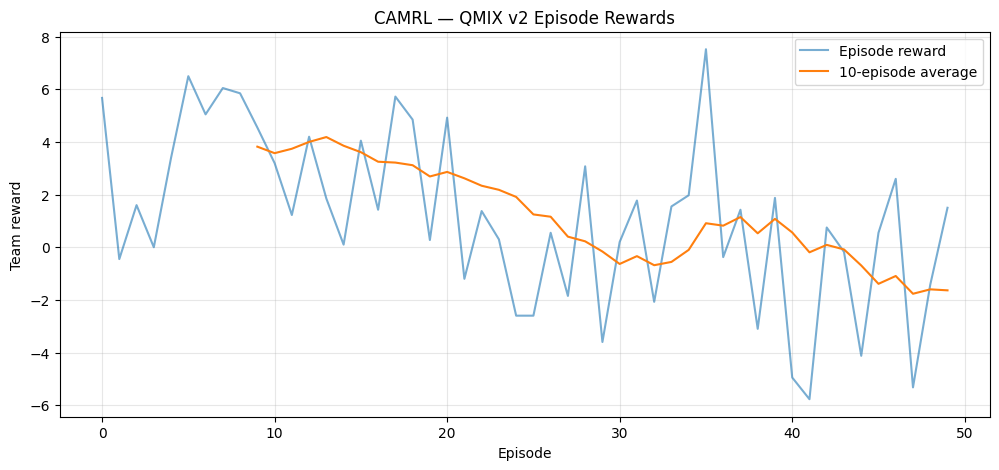

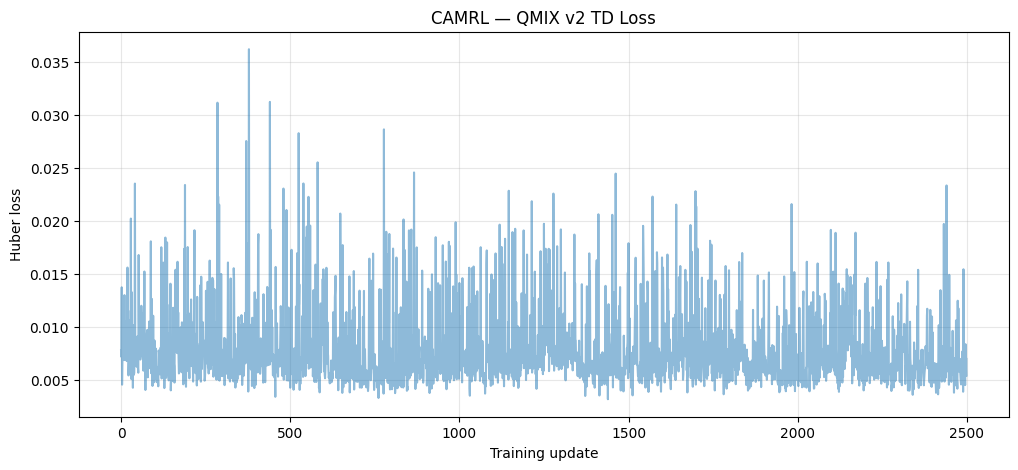

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    qmix_v2_rewards,
    alpha=0.6,
    label="Episode reward"
)

if len(qmix_v2_rewards) >= 10:

    moving_average = np.convolve(
        qmix_v2_rewards,
        np.ones(10) / 10,
        mode="valid"
    )

    plt.plot(
        range(9, len(qmix_v2_rewards)),
        moving_average,
        label="10-episode average"
    )

plt.title("CAMRL — QMIX v2 Episode Rewards")
plt.xlabel("Episode")
plt.ylabel("Team reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(12, 5))

plt.plot(qmix_v2_losses, alpha=0.5)

plt.title("CAMRL — QMIX v2 TD Loss")
plt.xlabel("Training update")
plt.ylabel("Huber loss")
plt.grid(alpha=0.3)
plt.show()

In [95]:
def qmix_v2_evaluate(num_episodes=50):

    evaluation_env = make_qmix_environment()

    results = []

    for episode in range(num_episodes):

        obs = qmix_v2_reset(
            evaluation_env,
            seed=5000 + episode
        )

        total_reward = 0.0
        success = False
        length = 0

        for step in range(MAX_EPISODE_STEPS):

            actions = qmix_v2_select_actions(
                obs,
                epsilon=0.0
            )

            obs, reward, terminated, truncated, info = (
                qmix_v2_step(
                    evaluation_env,
                    actions
                )
            )

            total_reward += reward
            length += 1

            if terminated:
                success = True
                break

            if truncated:
                break

        results.append({
            "episode": episode,
            "reward": total_reward,
            "success": int(success),
            "length": length
        })

    return pd.DataFrame(results)


qmix_v2_eval = qmix_v2_evaluate(50)

display(qmix_v2_eval.describe())

print(
    "Success rate:",
    f"{qmix_v2_eval['success'].mean():.2%}"
)

print(
    "Mean evaluation reward:",
    round(qmix_v2_eval["reward"].mean(), 3)
)

,episode,reward,success,length
count,50.00000,50.000000,50.0,50.0
mean,24.50000,-11.103000,0.0,200.0
std,14.57738,5.167719,0.0,0.0
min,0.00000,-19.350000,0.0,200.0
25%,12.25000,-14.868751,0.0,200.0
50%,24.50000,-12.075000,0.0,200.0
75%,36.75000,-7.075000,0.0,200.0
max,49.00000,0.000000,0.0,200.0


Success rate: 0.00%
Mean evaluation reward: -11.103


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [96]:
import json

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

torch.save({
    "agents": qmix_v2_agents.state_dict(),
    "mixer": qmix_v2_mixer.state_dict(),
    "target_agents": qmix_v2_target_agents.state_dict(),
    "target_mixer": qmix_v2_target_mixer.state_dict(),
    "local_obs_dim": LOCAL_OBS_DIM,
    "global_state_dim": GLOBAL_STATE_DIM,
    "action_dim": ACTION_DIM,
    "num_agents": NUM_AGENTS,
    "training_steps": TOTAL_STEPS_V2,
    "learning_rate": LEARNING_RATE,
    "gamma": GAMMA
}, CHECKPOINT_DIR / "qmix_v2_checkpoint.pt")

qmix_v2_eval.to_csv(
    RESULT_DIR / "qmix_v2_evaluation.csv",
    index=False
)

np.save(
    RESULT_DIR / "qmix_v2_rewards.npy",
    np.asarray(qmix_v2_rewards)
)

np.save(
    RESULT_DIR / "qmix_v2_losses.npy",
    np.asarray(qmix_v2_losses)
)

print("QMIX v2 checkpoint and results saved.")

QMIX v2 checkpoint and results saved.


In [97]:
from collections import Counter

def inspect_qmix_v2_actions(num_steps=200):

    env = make_qmix_environment()
    obs = qmix_v2_reset(env, seed=42)

    action_counts = Counter()

    for step in range(num_steps):

        actions = qmix_v2_select_actions(
            obs,
            epsilon=0.0
        )

        action_counts.update(actions.tolist())

        obs, reward, terminated, truncated, info = (
            qmix_v2_step(env, actions)
        )

        if terminated or truncated:
            obs = qmix_v2_reset(env)

    action_names = [
        "Stay", "Up", "Down",
        "Left", "Right", "Collect"
    ]

    for i, name in enumerate(action_names):
        count = action_counts.get(i, 0)

        print(
            f"{name:8s}: {count:4d} "
            f"({count / (num_steps * NUM_AGENTS) * 100:.2f}%)"
        )

inspect_qmix_v2_actions()


Stay    :    0 (0.00%)
Up      :    1 (0.12%)
Down    :    1 (0.12%)
Left    :  199 (24.88%)
Right   :  166 (20.75%)
Collect :  433 (54.12%)


In [98]:
print("Training episodes:", len(qmix_v2_rewards))
print("Training updates:", len(qmix_v2_losses))

if qmix_v2_rewards:
    print(
        "Last 20 training rewards:",
        np.mean(qmix_v2_rewards[-20:])
    )

    print(
        "Best training reward:",
        np.max(qmix_v2_rewards)
    )

if qmix_v2_losses:
    print(
        "Initial loss:",
        qmix_v2_losses[0]
    )

    print(
        "Final loss:",
        qmix_v2_losses[-1]
    )

    print(
        "Last 100 mean loss:",
        np.mean(qmix_v2_losses[-100:])
    )

Training episodes: 50
Training updates: 2500
Last 20 training rewards: -0.2800000644288957
Best training reward: 7.524999866262078
Initial loss: 0.007760969921946526
Final loss: 0.0053874049335718155
Last 100 mean loss: 0.007116128283087164


In [99]:
def random_baseline_policy(obs):
    return np.random.randint(
        0, ACTION_DIM,
        size=NUM_AGENTS
    )

random_results = []

for episode in range(50):

    env = make_qmix_environment()
    obs = qmix_v2_reset(env, seed=5000 + episode)

    total_reward = 0.0

    for step in range(MAX_EPISODE_STEPS):

        actions = random_baseline_policy(obs)

        obs, reward, terminated, truncated, info = (
            qmix_v2_step(env, actions)
        )

        total_reward += reward

        if terminated or truncated:
            break

    random_results.append(total_reward)

print("Random baseline mean:", np.mean(random_results))
print("Random baseline standard deviation:", np.std(random_results))
print("QMIX v2 mean:", qmix_v2_eval["reward"].mean())

Random baseline mean: 3.560499990694225
Random baseline standard deviation: 3.0342713026946484
QMIX v2 mean: -11.103000294789672


In [100]:
# Check that the trained actor models exist
print("IPPO actors:", len(agents))
print("IPPO model:", type(agents[0]).__name__)

print("MAPPO actors:", len(actors))
print("MAPPO model:", type(actors[0]).__name__)

assert len(agents) == NUM_AGENTS
assert len(actors) == NUM_AGENTS

# Set evaluation mode
for model in agents:
    model.eval()

for model in actors:
    model.eval()

print("Both trained actor groups are available.")

IPPO actors: 4
IPPO model: ActorCritic
MAPPO actors: 4
MAPPO model: MAPPOActor
Both trained actor groups are available.


In [101]:
def extract_action_logits(output):

    if isinstance(output, dict):
        for key in ["logits", "action_logits", "policy_logits"]:
            if key in output:
                output = output[key]
                break

    if isinstance(output, (tuple, list)):
        candidates = [
            item for item in output
            if torch.is_tensor(item)
            and item.shape[-1] == ACTION_DIM
        ]

        if not candidates:
            raise ValueError("Could not find action logits.")

        output = candidates[0]

    if hasattr(output, "logits"):
        output = output.logits

    if not torch.is_tensor(output):
        raise TypeError(
            f"Unsupported actor output: {type(output)}"
        )

    return output


def ippo_policy(observations):

    actions = []

    with torch.no_grad():

        for i in range(NUM_AGENTS):

            obs = torch.as_tensor(
                observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            output = agents[i](obs)
            logits = extract_action_logits(output)

            actions.append(
                int(logits.argmax(dim=-1).item())
            )

    return np.asarray(actions, dtype=np.int64)


def mappo_policy(observations):

    actions = []

    with torch.no_grad():

        for i in range(NUM_AGENTS):

            obs = torch.as_tensor(
                observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            output = actors[i](obs)
            logits = extract_action_logits(output)

            actions.append(
                int(logits.argmax(dim=-1).item())
            )

    return np.asarray(actions, dtype=np.int64)

In [102]:
POLICIES = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "QMIX": qmix_policy,
    "Comm-MAPPO": comm_mappo_policy
}

print("Connected algorithms:", list(POLICIES.keys()))

Connected algorithms: ['IPPO', 'MAPPO', 'QMIX', 'Comm-MAPPO']


In [103]:
test_env = make_evaluation_env()
test_obs = reset_camrl_environment(test_env, seed=42)

for name, policy in POLICIES.items():

    actions = policy(test_obs)

    print(
        name,
        "| Actions:", actions,
        "| Shape:", actions.shape
    )

    assert actions.shape == (NUM_AGENTS,)
    assert np.all(actions >= 0)
    assert np.all(actions < ACTION_DIM)

print("\nAll four policy adapters passed.")

IPPO | Actions: [0 5 5 0] | Shape: (4,)
MAPPO | Actions: [0 5 5 5] | Shape: (4,)
QMIX | Actions: [4 2 1 4] | Shape: (4,)
Comm-MAPPO | Actions: [5 5 5 5] | Shape: (4,)

All four policy adapters passed.


In [104]:
benchmark_results = []

for algorithm_name, policy in POLICIES.items():

    print(f"\nEvaluating {algorithm_name}...")

    result = evaluate_policy(
        policy=policy,
        algorithm_name=algorithm_name,
        num_seeds=5,
        episodes_per_seed=50
    )

    benchmark_results.append(result)

    print(
        "Mean reward:",
        result["reward"].mean()
    )

    print(
        "Success rate:",
        result["success"].mean()
    )

results_df = pd.concat(
    benchmark_results,
    ignore_index=True
)

results_df.to_csv(
    RESULT_DIR / "camrl_four_algorithm_benchmark.csv",
    index=False
)

display(
    results_df.groupby("algorithm").agg(
        mean_reward=("reward", "mean"),
        std_reward=("reward", "std"),
        success_rate=("success", "mean"),
        mean_episode_length=("episode_length", "mean")
    ).sort_values("mean_reward", ascending=False)
)


Evaluating IPPO...
Mean reward: 0.0
Success rate: 0.0

Evaluating MAPPO...
Mean reward: 0.0
Success rate: 0.0

Evaluating QMIX...
Mean reward: -13.399700354933739
Success rate: 0.0

Evaluating Comm-MAPPO...
Mean reward: 0.0
Success rate: 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,mean_reward,std_reward,success_rate,mean_episode_length
algorithm,,,,
Comm-MAPPO,0.0000,0.000000,0.0,200.0
IPPO,0.0000,0.000000,0.0,200.0
MAPPO,0.0000,0.000000,0.0,200.0
QMIX,-13.3997,3.658085,0.0,200.0


In [105]:
# IPPO
for model in agents:
    model.eval()

# MAPPO
for model in actors:
    model.eval()

# Communication-MAPPO
for model in comm_actors:
    model.eval()

# QMIX
for model in qmix_v2_agents:
    model.eval()

qmix_v2_mixer.eval()

print("All policies switched to evaluation mode.")

All policies switched to evaluation mode.


In [106]:
import numpy as np
import torch
from collections import Counter

print("=" * 65)
print("CAMRL ENVIRONMENT AND POLICY DIAGNOSTICS")
print("=" * 65)

# --------------------------------------------------
# 1. Inspect environment configuration
# --------------------------------------------------

env = make_evaluation_env()

print("\n[1] ENVIRONMENT ATTRIBUTES")

for key, value in env.__dict__.items():
    if key.startswith("_"):
        continue

    if isinstance(value, (int, float, str, bool, type(None))):
        print(f"{key}: {value}")
    elif isinstance(value, (list, dict)):
        print(f"{key}: {str(value)[:500]}")

# --------------------------------------------------
# 2. Inspect initial observations and resources
# --------------------------------------------------

obs = reset_camrl_environment(env, seed=42)

print("\n[2] INITIAL STATE")
print("Observation shape:", obs.shape)
print("Observation finite:", np.isfinite(obs).all())
print("Observation range:", obs.min(), obs.max())

for attr in ["agents", "resources", "obstacles"]:
    if hasattr(env, attr):
        print(f"\n{attr}:")
        print(str(getattr(env, attr))[:2000])

# --------------------------------------------------
# 3. Inspect each trained policy's action distribution
# --------------------------------------------------

print("\n[3] POLICY ACTION DISTRIBUTIONS")

for name, policy in POLICIES.items():
    env = make_evaluation_env()
    obs = reset_camrl_environment(env, seed=42)

    action_counts = Counter()

    for step in range(50):
        actions = policy(obs)

        for action in actions:
            action_counts[int(action)] += 1

        result = env.step(actions)

        if len(result) == 5:
            obs, rewards, terminated, truncated, info = result
            done = (
                np.asarray(terminated).any()
                or np.asarray(truncated).any()
            )
        else:
            obs, rewards, done, info = result

        obs = np.asarray(obs, dtype=np.float32)

        if done:
            break

    print(f"\n{name}")
    print("Action counts:", dict(sorted(action_counts.items())))

# --------------------------------------------------
# 4. Inspect raw rewards and termination signals
# --------------------------------------------------

print("\n[4] FIRST 20 STEPS — IPPO")

env = make_evaluation_env()
obs = reset_camrl_environment(env, seed=42)

for step in range(20):
    actions = ippo_policy(obs)
    result = env.step(actions)

    if len(result) == 5:
        next_obs, rewards, terminated, truncated, info = result
    else:
        next_obs, rewards, done, info = result
        terminated, truncated = done, False

    print(
        f"Step {step + 1:02d} | "
        f"Actions: {actions} | "
        f"Rewards: {np.asarray(rewards)} | "
        f"Terminated: {terminated} | "
        f"Truncated: {truncated}"
    )

    obs = np.asarray(next_obs, dtype=np.float32)

# --------------------------------------------------
# 5. Random policy baseline
# --------------------------------------------------

print("\n[5] RANDOM POLICY BASELINE")

random_rewards = []
random_successes = []

for episode in range(20):
    env = make_evaluation_env()
    obs = reset_camrl_environment(env, seed=episode)

    total_reward = 0.0
    success = False

    for step in range(200):
        actions = np.random.randint(
            0, ACTION_DIM, size=NUM_AGENTS
        )

        result = env.step(actions)

        if len(result) == 5:
            next_obs, rewards, terminated, truncated, info = result

            success = bool(
                np.asarray(terminated).any()
            )

            done = (
                success
                or bool(np.asarray(truncated).any())
            )
        else:
            next_obs, rewards, done, info = result
            success = bool(np.asarray(done).any())

        total_reward += float(
            np.asarray(rewards, dtype=np.float32).mean()
        )

        obs = np.asarray(next_obs, dtype=np.float32)

        if done:
            break

    random_rewards.append(total_reward)
    random_successes.append(success)

print("Random mean reward:", np.mean(random_rewards))
print("Random success rate:", np.mean(random_successes))
print("Random reward std:", np.std(random_rewards))

print("\nDIAGNOSTICS COMPLETED")

CAMRL ENVIRONMENT AND POLICY DIAGNOSTICS

[1] ENVIRONMENT ATTRIBUTES
grid_size: 12
num_agents: 4
num_resources: 10
max_steps: 200
initial_energy: 100
action_size: 6
action_space: [Discrete(6), Discrete(6), Discrete(6), Discrete(6)]
observation_size: 41
observation_spaces: [Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32), Box(-1.0, 1.0, (41,), float32)]
step_count: 0
agents: [{'position': [3, 6], 'energy': 100, 'collected': 0}, {'position': [8, 4], 'energy': 100, 'collected': 0}, {'position': [3, 0], 'energy': 100, 'collected': 0}, {'position': [7, 7], 'energy': 100, 'collected': 0}]
resources: [{'position': [3, 8], 'collected': False, 'special': True}, {'position': [10, 11], 'collected': False, 'special': False}, {'position': [10, 1], 'collected': False, 'special': False}, {'position': [6, 6], 'collected': False, 'special': True}, {'position': [7, 0], 'collected': False, 'special': False}, {'position': [10, 0], 'collected': False, 'special

In [107]:
import inspect
import numpy as np
import torch

# --------------------------------------------------
# 1. Fix metadata on a fresh evaluation environment
# --------------------------------------------------

env = make_evaluation_env()

actual_obs = reset_camrl_environment(env, seed=42)
actual_obs_dim = actual_obs.shape[-1]

env.observation_size = actual_obs_dim

print("=" * 65)
print("1. OBSERVATION DIMENSION CHECK")
print("=" * 65)

print("Actual observation dimension:", actual_obs_dim)
print("Environment metadata:", env.observation_size)

# Check model input dimensions
def get_first_linear_input(model):
    for module in model.modules():
        if isinstance(module, torch.nn.Linear):
            return module.in_features
    return None

print("\nModel input dimensions:")

for i, model in enumerate(agents):
    print(f"IPPO agent {i}:", get_first_linear_input(model))

for i, model in enumerate(actors):
    print(f"MAPPO actor {i}:", get_first_linear_input(model))

for i, model in enumerate(comm_actors):
    print(f"Comm-MAPPO actor {i}:", get_first_linear_input(model))

# --------------------------------------------------
# 2. Inspect action mapping and environment methods
# --------------------------------------------------

print("\n" + "=" * 65)
print("2. ENVIRONMENT IMPLEMENTATION")
print("=" * 65)

for method_name in ["step", "_move_agent", "_collect_resource",
                    "_get_obs", "_get_observation", "_get_reward"]:

    method = getattr(type(env), method_name, None)

    if method is not None:
        print(f"\n--- {method_name} ---")

        try:
            print(inspect.getsource(method))
        except Exception as e:
            print("Source unavailable:", e)

# --------------------------------------------------
# 3. Inspect initial distances to resources
# --------------------------------------------------

def nearest_resource_distance(agent, resources):
    pos = np.asarray(agent["position"])

    available = [
        np.asarray(r["position"])
        for r in resources
        if not r["collected"]
    ]

    if not available:
        return None

    distances = [
        np.abs(pos - resource).sum()
        for resource in available
    ]

    return min(distances)

print("\n" + "=" * 65)
print("3. INITIAL AGENT POSITIONS AND RESOURCE DISTANCES")
print("=" * 65)

for i, agent in enumerate(env.agents):
    print(
        f"Agent {i}: position={agent['position']}, "
        f"energy={agent['energy']}, "
        f"nearest resource distance="
        f"{nearest_resource_distance(agent, env.resources)}"
    )

# --------------------------------------------------
# 4. Track IPPO for 20 steps
# --------------------------------------------------

print("\n" + "=" * 65)
print("4. IPPO STATE TRANSITIONS")
print("=" * 65)

env = make_evaluation_env()
obs = reset_camrl_environment(env, seed=42)

for step in range(20):

    actions = ippo_policy(obs)

    old_positions = [
        list(agent["position"]) for agent in env.agents
    ]

    result = env.step(actions)

    if len(result) == 5:
        next_obs, rewards, terminated, truncated, info = result
    else:
        next_obs, rewards, done, info = result
        terminated, truncated = done, False

    new_positions = [
        list(agent["position"]) for agent in env.agents
    ]

    distances = [
        nearest_resource_distance(agent, env.resources)
        for agent in env.agents
    ]

    collected = sum(
        int(resource["collected"])
        for resource in env.resources
    )

    print(
        f"Step {step + 1:02d} | "
        f"Actions={actions.tolist()} | "
        f"Positions={new_positions} | "
        f"Distances={distances} | "
        f"Reward={np.asarray(rewards).mean():.3f} | "
        f"Collected={collected}"
    )

    obs = np.asarray(next_obs, dtype=np.float32)

# --------------------------------------------------
# 5. Compare deterministic and stochastic action choices
# --------------------------------------------------

print("\n" + "=" * 65)
print("5. IPPO POLICY OUTPUT DISTRIBUTION")
print("=" * 65)

sample_obs = reset_camrl_environment(
    make_evaluation_env(), seed=42
)

for i, model in enumerate(agents):

    x = torch.as_tensor(
        sample_obs[i],
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)

    with torch.no_grad():
        output = model(x)
        logits = extract_action_logits(output)
        probabilities = torch.softmax(logits, dim=-1)

    print(f"\nAgent {i}")
    print("Probabilities:", probabilities.cpu().numpy().round(4))
    print("Greedy action:", probabilities.argmax(dim=-1).item())

print("\nDIAGNOSTIC COMPLETE")

1. OBSERVATION DIMENSION CHECK
Actual observation dimension: 51
Environment metadata: 51

Model input dimensions:
IPPO agent 0: 51
IPPO agent 1: 51
IPPO agent 2: 51
IPPO agent 3: 51
MAPPO actor 0: 51
MAPPO actor 1: 51
MAPPO actor 2: 51
MAPPO actor 3: 51
Comm-MAPPO actor 0: 51
Comm-MAPPO actor 1: 51
Comm-MAPPO actor 2: 51
Comm-MAPPO actor 3: 51

2. ENVIRONMENT IMPLEMENTATION

--- step ---
def corrected_step(self, actions):

    self.step_count += 1

    rewards = np.zeros(self.num_agents, dtype=np.float32)

    movement = {
        0: (0, 0),
        1: (-1, 0),
        2: (1, 0),
        3: (0, -1),
        4: (0, 1)
    }

    for i, agent in enumerate(self.agents):

        if agent["energy"] <= 0:
            continue

        action = int(actions[i])

        if action in movement:

            dx, dy = movement[action]

            x, y = agent["position"]
            nx, ny = x + dx, y + dy

            if (
                0 <= nx < self.grid_size
                and 0 <= ny < s

In [108]:
import inspect
import numpy as np
import torch

# --------------------------------------------------
# 1. Fix metadata on a fresh evaluation environment
# --------------------------------------------------

env = make_evaluation_env()

actual_obs = reset_camrl_environment(env, seed=42)
actual_obs_dim = actual_obs.shape[-1]

env.observation_size = actual_obs_dim

print("=" * 65)
print("1. OBSERVATION DIMENSION CHECK")
print("=" * 65)

print("Actual observation dimension:", actual_obs_dim)
print("Environment metadata:", env.observation_size)

# Check model input dimensions
def get_first_linear_input(model):
    for module in model.modules():
        if isinstance(module, torch.nn.Linear):
            return module.in_features
    return None

print("\nModel input dimensions:")

for i, model in enumerate(agents):
    print(f"IPPO agent {i}:", get_first_linear_input(model))

for i, model in enumerate(actors):
    print(f"MAPPO actor {i}:", get_first_linear_input(model))

for i, model in enumerate(comm_actors):
    print(f"Comm-MAPPO actor {i}:", get_first_linear_input(model))

# --------------------------------------------------
# 2. Inspect action mapping and environment methods
# --------------------------------------------------

print("\n" + "=" * 65)
print("2. ENVIRONMENT IMPLEMENTATION")
print("=" * 65)

for method_name in ["step", "_move_agent", "_collect_resource",
                    "_get_obs", "_get_observation", "_get_reward"]:

    method = getattr(type(env), method_name, None)

    if method is not None:
        print(f"\n--- {method_name} ---")

        try:
            print(inspect.getsource(method))
        except Exception as e:
            print("Source unavailable:", e)

# --------------------------------------------------
# 3. Inspect initial distances to resources
# --------------------------------------------------

def nearest_resource_distance(agent, resources):
    pos = np.asarray(agent["position"])

    available = [
        np.asarray(r["position"])
        for r in resources
        if not r["collected"]
    ]

    if not available:
        return None

    distances = [
        np.abs(pos - resource).sum()
        for resource in available
    ]

    return min(distances)

print("\n" + "=" * 65)
print("3. INITIAL AGENT POSITIONS AND RESOURCE DISTANCES")
print("=" * 65)

for i, agent in enumerate(env.agents):
    print(
        f"Agent {i}: position={agent['position']}, "
        f"energy={agent['energy']}, "
        f"nearest resource distance="
        f"{nearest_resource_distance(agent, env.resources)}"
    )

# --------------------------------------------------
# 4. Track IPPO for 20 steps
# --------------------------------------------------

print("\n" + "=" * 65)
print("4. IPPO STATE TRANSITIONS")
print("=" * 65)

env = make_evaluation_env()
obs = reset_camrl_environment(env, seed=42)

for step in range(20):

    actions = ippo_policy(obs)

    old_positions = [
        list(agent["position"]) for agent in env.agents
    ]

    result = env.step(actions)

    if len(result) == 5:
        next_obs, rewards, terminated, truncated, info = result
    else:
        next_obs, rewards, done, info = result
        terminated, truncated = done, False

    new_positions = [
        list(agent["position"]) for agent in env.agents
    ]

    distances = [
        nearest_resource_distance(agent, env.resources)
        for agent in env.agents
    ]

    collected = sum(
        int(resource["collected"])
        for resource in env.resources
    )

    print(
        f"Step {step + 1:02d} | "
        f"Actions={actions.tolist()} | "
        f"Positions={new_positions} | "
        f"Distances={distances} | "
        f"Reward={np.asarray(rewards).mean():.3f} | "
        f"Collected={collected}"
    )

    obs = np.asarray(next_obs, dtype=np.float32)

# --------------------------------------------------
# 5. Compare deterministic and stochastic action choices
# --------------------------------------------------

print("\n" + "=" * 65)
print("5. IPPO POLICY OUTPUT DISTRIBUTION")
print("=" * 65)

sample_obs = reset_camrl_environment(
    make_evaluation_env(), seed=42
)

for i, model in enumerate(agents):

    x = torch.as_tensor(
        sample_obs[i],
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)

    with torch.no_grad():
        output = model(x)
        logits = extract_action_logits(output)
        probabilities = torch.softmax(logits, dim=-1)

    print(f"\nAgent {i}")
    print("Probabilities:", probabilities.cpu().numpy().round(4))
    print("Greedy action:", probabilities.argmax(dim=-1).item())

print("\nDIAGNOSTIC COMPLETE")

1. OBSERVATION DIMENSION CHECK
Actual observation dimension: 51
Environment metadata: 51

Model input dimensions:
IPPO agent 0: 51
IPPO agent 1: 51
IPPO agent 2: 51
IPPO agent 3: 51
MAPPO actor 0: 51
MAPPO actor 1: 51
MAPPO actor 2: 51
MAPPO actor 3: 51
Comm-MAPPO actor 0: 51
Comm-MAPPO actor 1: 51
Comm-MAPPO actor 2: 51
Comm-MAPPO actor 3: 51

2. ENVIRONMENT IMPLEMENTATION

--- step ---
def corrected_step(self, actions):

    self.step_count += 1

    rewards = np.zeros(self.num_agents, dtype=np.float32)

    movement = {
        0: (0, 0),
        1: (-1, 0),
        2: (1, 0),
        3: (0, -1),
        4: (0, 1)
    }

    for i, agent in enumerate(self.agents):

        if agent["energy"] <= 0:
            continue

        action = int(actions[i])

        if action in movement:

            dx, dy = movement[action]

            x, y = agent["position"]
            nx, ny = x + dx, y + dy

            if (
                0 <= nx < self.grid_size
                and 0 <= ny < s

In [109]:
from collections import deque
import numpy as np
import inspect

env = make_evaluation_env()
obs = reset_camrl_environment(env, seed=42)

# Correct metadata
env.observation_size = obs.shape[-1]

# Action mapping from corrected_step()
MOVES = {
    0: (0, 0),
    1: (-1, 0),
    2: (1, 0),
    3: (0, -1),
    4: (0, 1)
}

# --------------------------------------------------
# Find a reachable normal resource using BFS
# --------------------------------------------------

agent_index = 0
start = tuple(env.agents[agent_index]["position"])

targets = [
    tuple(r["position"])
    for r in env.resources
    if not r["collected"] and not r["special"]
]

obstacles = set(env.obstacles)

queue = deque([(start, [])])
visited = {start}
solution = None

while queue:
    position, path = queue.popleft()

    if position in targets:
        solution = (position, path)
        break

    for action, (dx, dy) in MOVES.items():
        if action == 0:
            continue

        nx = position[0] + dx
        ny = position[1] + dy
        new_position = (nx, ny)

        if (
            0 <= nx < env.grid_size
            and 0 <= ny < env.grid_size
            and new_position not in obstacles
            and new_position not in visited
        ):
            visited.add(new_position)
            queue.append((new_position, path + [action]))

if solution is None:
    print("No reachable normal resource found.")
else:
    target, path = solution

    print("Starting position:", start)
    print("Target resource:", target)
    print("Navigation actions:", path)

    # --------------------------------------------------
    # Execute navigation
    # --------------------------------------------------

    total_reward = 0.0

    for action in path:
        actions = np.zeros(NUM_AGENTS, dtype=np.int64)
        actions[agent_index] = action

        result = env.step(actions)

        next_obs, rewards, terminated, truncated, info = result

        total_reward += float(np.asarray(rewards).mean())

        print(
            "Move:", action,
            "| Position:", env.agents[agent_index]["position"],
            "| Reward:", np.asarray(rewards).mean()
        )

    # --------------------------------------------------
    # Collect resource
    # --------------------------------------------------

    actions = np.zeros(NUM_AGENTS, dtype=np.int64)
    actions[agent_index] = 5

    result = env.step(actions)
    next_obs, rewards, terminated, truncated, info = result

    print("\nCOLLECTION TEST")
    print("Final position:", env.agents[agent_index]["position"])
    print("Resource collected:", next(
        r["collected"]
        for r in env.resources
        if tuple(r["position"]) == target
    ))
    print("Collection reward:", np.asarray(rewards))
    print("Total collected:", info["resources_collected"])
    print("Team success:", info["team_success"])

# --------------------------------------------------
# Inspect observation generation
# --------------------------------------------------

print("\nOBSERVATION GENERATION METHOD")

try:
    print(inspect.getsource(type(env).get_observations))
except Exception as e:
    print("Could not retrieve source:", e)

Starting position: (6, 3)
Target resource: (4, 3)
Navigation actions: [1, 1]
Move: 1 | Position: [5, 3] | Reward: 0.0
Move: 1 | Position: [4, 3] | Reward: 0.0

COLLECTION TEST
Final position: [4, 3]
Resource collected: True
Collection reward: [2. 2. 2. 2.]
Total collected: 1
Team success: False

OBSERVATION GENERATION METHOD
def corrected_observations(self):

    observations = []

    for agent in self.agents:

        x, y = agent["position"]

        obs = [
            x / (self.grid_size - 1),
            y / (self.grid_size - 1),
            max(0.0, agent["energy"]) / self.initial_energy
        ]

        for resource in self.resources:

            rx, ry = resource["position"]

            obs.extend([
                rx / (self.grid_size - 1),
                ry / (self.grid_size - 1),
                float(resource["collected"]),
                float(resource["special"])
            ])

        for other in self.agents:

            ox, oy = other["position"]

            

In [112]:

import numpy as np
from gymnasium.spaces import Box

# ============================================
# 1. IMPROVED OBSERVATIONS: 195 FEATURES
# ============================================

# ============================================
# CAMRL V2 — STEP VALIDATION FIX
# ============================================

test_env = make_evaluation_env()

test_obs = reset_camrl_environment(test_env, seed=42)

test_env.observation_size = test_obs.shape[-1]

# Execute one environment step
actions = np.array([1, 2, 3, 4], dtype=np.int64)

next_obs, rewards, terminated, truncated, info = (
    test_env.step(actions)
)

# Convert list of observations into NumPy array
next_obs = np.asarray(next_obs, dtype=np.float32)

print("=" * 55)
print("CAMRL ENVIRONMENT V2 — VALIDATION")
print("=" * 55)

print("Initial observation:", test_obs.shape)
print("Next observation:", next_obs.shape)
print("Observation dimension:", next_obs.shape[-1])
print("Rewards:", rewards)
print("Shaping reward:", info["shaping_reward"])
print("Team potential:", info["team_potential"])
print("Resources collected:", info["resources_collected"])
print("Terminated:", terminated)
print("Truncated:", truncated)

assert next_obs.shape == (4, 195)
assert np.isfinite(next_obs).all()
assert np.isfinite(rewards).all()
assert isinstance(info["shaping_reward"], float)

print("\nCAMRL ENVIRONMENT V2 VALIDATION PASSED")


# ============================================
# 2. POTENTIAL FUNCTION FOR REWARD SHAPING
# ============================================

def camrl_team_potential(self):

    positions = [
        np.asarray(agent["position"], dtype=np.int32)
        for agent in self.agents
        if agent["energy"] > 0
    ]

    if not positions:
        return 0.0

    total_distance = 0.0

    for resource in self.resources:

        if resource["collected"]:
            continue

        resource_pos = np.asarray(
            resource["position"],
            dtype=np.int32
        )

        distances = sorted(
            int(np.abs(pos - resource_pos).sum())
            for pos in positions
        )

        if resource["special"]:
            # Special resource requires two agents
            if len(distances) >= 2:
                total_distance += distances[0] + distances[1]
            else:
                total_distance += distances[0] * 2
        else:
            # Normal resource requires one agent
            total_distance += distances[0]

    return -float(total_distance)


# ============================================
# 3. IMPROVED STEP FUNCTION
# ============================================

def camrl_step_v2(self, actions):

    actions = np.asarray(actions, dtype=np.int64)

    if actions.shape != (self.num_agents,):
        raise ValueError(
            f"Expected {self.num_agents} actions, "
            f"received shape {actions.shape}"
        )

    if np.any(actions < 0) or np.any(actions >= self.action_size):
        raise ValueError("Invalid action supplied.")

    self.step_count += 1

    rewards = np.zeros(
        self.num_agents,
        dtype=np.float32
    )

    # Potential before state transition
    old_potential = camrl_team_potential(self)

    movement = {
        0: (0, 0),
        1: (-1, 0),
        2: (1, 0),
        3: (0, -1),
        4: (0, 1)
    }

    # Track successful collection actions
    successful_collectors = set()

    # ----------------------------------------
    # Movement
    # ----------------------------------------

    for i, agent in enumerate(self.agents):

        if agent["energy"] <= 0:
            continue

        action = int(actions[i])

        if action in movement:

            dx, dy = movement[action]

            x, y = agent["position"]
            nx, ny = x + dx, y + dy

            if (
                0 <= nx < self.grid_size
                and 0 <= ny < self.grid_size
                and (nx, ny) not in self.obstacles
            ):

                agent["position"] = [nx, ny]
                agent["energy"] -= 0.2

                # Small cost for movement
                if action != 0:
                    rewards[i] -= 0.01
                else:
                    # Discourage unnecessary staying
                    rewards[i] -= 0.02

            else:
                agent["energy"] -= 0.2
                rewards[i] -= 0.05

        elif action == 5:
            agent["energy"] -= 0.5

    # ----------------------------------------
    # Resource collection
    # ----------------------------------------

    for resource in self.resources:

        if resource["collected"]:
            continue

        resource_pos = tuple(resource["position"])

        collectors = [
            i
            for i, agent in enumerate(self.agents)
            if (
                int(actions[i]) == 5
                and agent["energy"] > 0
                and tuple(agent["position"]) == resource_pos
            )
        ]

        required_agents = (
            2 if resource["special"] else 1
        )

        if len(collectors) >= required_agents:

            resource["collected"] = True

            for i in collectors:
                self.agents[i]["collected"] += 1
                successful_collectors.add(i)

            collection_reward = (
                5.0 if resource["special"] else 2.0
            )

            rewards += collection_reward

    # Penalise unsuccessful collection attempts
    for i in range(self.num_agents):

        if (
            actions[i] == 5
            and i not in successful_collectors
        ):
            rewards[i] -= 0.05

    # ----------------------------------------
    # Energy limits
    # ----------------------------------------

    for agent in self.agents:

        if agent["energy"] <= 0:
            agent["energy"] = 0

    # ----------------------------------------
    # Potential-based reward shaping
    # ----------------------------------------

    new_potential = camrl_team_potential(self)

    gamma = 0.99
    shaping_scale = 0.1

    shaping_reward = shaping_scale * (
        gamma * new_potential - old_potential
    )

    rewards += shaping_reward

    # ----------------------------------------
    # Termination
    # ----------------------------------------

    terminated = all(
        resource["collected"]
        for resource in self.resources
    )

    truncated = (
        self.step_count >= self.max_steps
        and not terminated
    )

    if terminated:
        rewards += 10.0

    info = {
        "resources_collected": sum(
            resource["collected"]
            for resource in self.resources
        ),
        "team_success": terminated,
        "shaping_reward": float(shaping_reward),
        "team_potential": float(new_potential)
    }

    return (
        self.get_observations(),
        rewards,
        terminated,
        truncated,
        info
    )


# ============================================
# 4. APPLY PATCH TO ENVIRONMENT CLASS
# ============================================

EnvironmentClass = type(make_evaluation_env())

EnvironmentClass.get_observations = camrl_observations_v2
EnvironmentClass.step = camrl_step_v2

# ============================================
# 5. VALIDATE NEW ENVIRONMENT
# ============================================

test_env = make_evaluation_env()

test_obs = reset_camrl_environment(
    test_env,
    seed=42
)

actual_dim = test_obs.shape[-1]

test_env.observation_size = actual_dim

test_env.observation_spaces = [
    Box(
        low=0.0,
        high=1.0,
        shape=(actual_dim,),
        dtype=np.float32
    )
    for _ in range(test_env.num_agents)
]

print("CAMRL ENVIRONMENT V2")
print("-----------------------------")
print("Observation shape:", test_obs.shape)
print("Observation dimension:", actual_dim)
print("Expected dimension:", 195)
print("Finite observations:", np.isfinite(test_obs).all())
print("Observation range:", test_obs.min(), test_obs.max())
print("Obstacle count:", len(test_env.obstacles))

assert test_obs.shape == (4, 195)
assert np.isfinite(test_obs).all()
assert test_obs.min() >= 0.0
assert test_obs.max() <= 1.0

# Test a movement transition
actions = np.array([1, 2, 3, 4])

next_obs, rewards, terminated, truncated, info = (
    test_env.step(actions)
)

print("\nSTEP TEST")
print("Next observation:", next_obs.shape)
print("Rewards:", rewards)
print("Shaping reward:", info["shaping_reward"])
print("Potential:", info["team_potential"])
print("Terminated:", terminated)
print("Truncated:", truncated)

assert next_obs.shape == (4, 195)

print("\nCAMRL ENVIRONMENT V2 VALIDATION PASSED")


CAMRL ENVIRONMENT V2 — VALIDATION
Initial observation: (4, 195)
Next observation: (4, 195)
Observation dimension: 195
Rewards: [0.154 0.154 0.154 0.154]
Shaping reward: 0.16400000000000006
Team potential: -64.0
Resources collected: 0
Terminated: False
Truncated: False

CAMRL ENVIRONMENT V2 VALIDATION PASSED
CAMRL ENVIRONMENT V2
-----------------------------
Observation shape: (4, 195)
Observation dimension: 195
Expected dimension: 195
Finite observations: True
Observation range: 0.0 1.0
Obstacle count: 12

STEP TEST


AttributeError: 'list' object has no attribute 'shape'

In [113]:
import numpy as np

# Create fresh environment
test_env = make_evaluation_env()
obs = reset_camrl_environment(test_env, seed=42)

# Execute one step
actions = np.array([1, 2, 3, 4], dtype=np.int64)

result = test_env.step(actions)

# Unpack
next_obs, rewards, terminated, truncated, info = result

# IMPORTANT: Convert BEFORE accessing shape
next_obs = np.asarray(next_obs, dtype=np.float32)
rewards = np.asarray(rewards, dtype=np.float32)

# Validation
print("Initial observation:", obs.shape)
print("Next observation:", next_obs.shape)
print("Rewards:", rewards)
print("Shaping reward:", info["shaping_reward"])
print("Team potential:", info["team_potential"])
print("Resources collected:", info["resources_collected"])

assert next_obs.shape == (4, 195)
assert rewards.shape == (4,)

print("\nCAMRL V2 STEP TEST PASSED")

Initial observation: (4, 195)
Next observation: (4, 195)
Rewards: [0.154 0.154 0.154 0.154]
Shaping reward: 0.16400000000000006
Team potential: -64.0
Resources collected: 0

CAMRL V2 STEP TEST PASSED


In [114]:

import numpy as np

def validate_collection_v2(resource_type):

    env = make_evaluation_env()
    reset_camrl_environment(env, seed=42)

    # Find requested resource
    resource_index = next(
        i for i, r in enumerate(env.resources)
        if r["special"] == (resource_type == "special")
    )

    resource = env.resources[resource_index]
    target = list(resource["position"])

    # Position agents directly on the resource
    env.agents[0]["position"] = target.copy()
    env.agents[0]["energy"] = 100

    if resource_type == "special":
        env.agents[1]["position"] = target.copy()
        env.agents[1]["energy"] = 100
        actions = np.array([5, 5, 0, 0])
    else:
        actions = np.array([5, 0, 0, 0])

    # Execute collection
    next_obs, rewards, terminated, truncated, info = env.step(actions)

    next_obs = np.asarray(next_obs, dtype=np.float32)
    rewards = np.asarray(rewards, dtype=np.float32)

    print(f"\n{resource_type.upper()} RESOURCE TEST")
    print("Target:", target)
    print("Collected:", resource["collected"])
    print("Rewards:", rewards)
    print("Shaping reward:", info["shaping_reward"])
    print("Resources collected:", info["resources_collected"])

    assert resource["collected"], (
        f"{resource_type} resource collection failed"
    )

    assert next_obs.shape == (4, 195)
    assert np.isfinite(rewards).all()

    if resource_type == "normal":
        assert env.agents[0]["collected"] == 1

    else:
        assert env.agents[0]["collected"] == 1
        assert env.agents[1]["collected"] == 1

    print(f"{resource_type.upper()} COLLECTION PASSED")


validate_collection_v2("normal")
validate_collection_v2("special")

print("\nALL CAMRL V2 COLLECTION TESTS PASSED")



NORMAL RESOURCE TEST
Target: [4, 3]
Collected: True
Rewards: [2.059 2.039 2.039 2.039]
Shaping reward: 0.059000000000000344
Resources collected: 1
NORMAL COLLECTION PASSED

SPECIAL RESOURCE TEST
Target: [6, 10]
Collected: True
Rewards: [5.057 5.057 5.037 5.037]
Shaping reward: 0.05700000000000003
Resources collected: 1
SPECIAL COLLECTION PASSED

ALL CAMRL V2 COLLECTION TESTS PASSED


In [115]:

import numpy as np
import torch
import inspect

print("=" * 65)
print("CAMRL PHASE 9 — MODEL REBUILD PREFLIGHT")
print("=" * 65)

# -----------------------------------------
# 1. Confirm Environment V2
# -----------------------------------------

env = make_evaluation_env()
obs = reset_camrl_environment(env, seed=42)

OBS_DIM = obs.shape[-1]
NUM_AGENTS = env.num_agents
ACTION_DIM = env.action_size

print("\nENVIRONMENT")
print("Observation dimension:", OBS_DIM)
print("Agents:", NUM_AGENTS)
print("Actions:", ACTION_DIM)

assert OBS_DIM == 195
assert NUM_AGENTS == 4
assert ACTION_DIM == 6

# -----------------------------------------
# 2. Test normal and special collection
# -----------------------------------------

def test_resource_collection(resource_type):

    test_env = make_evaluation_env()
    reset_camrl_environment(test_env, seed=42)

    resource = next(
        r for r in test_env.resources
        if r["special"] == (resource_type == "special")
    )

    target = list(resource["position"])

    test_env.agents[0]["position"] = target.copy()

    if resource_type == "special":
        test_env.agents[1]["position"] = target.copy()
        actions = np.array([5, 5, 0, 0])
    else:
        actions = np.array([5, 0, 0, 0])

    next_obs, rewards, terminated, truncated, info = (
        test_env.step(actions)
    )

    next_obs = np.asarray(next_obs, dtype=np.float32)
    rewards = np.asarray(rewards, dtype=np.float32)

    assert resource["collected"]
    assert next_obs.shape == (4, 195)
    assert np.isfinite(rewards).all()

    print(
        resource_type,
        "collection: PASSED |",
        "Rewards:", rewards,
        "| Shaping:", info["shaping_reward"]
    )

test_resource_collection("normal")
test_resource_collection("special")

# -----------------------------------------
# 3. Inspect existing model constructors
# -----------------------------------------

print("\nMODEL CONSTRUCTORS")

for name in [
    "ActorCritic",
    "MAPPOActor",
    "CentralizedCritic",
    "CommunicationActor",
    "CommunicationCritic"
]:

    cls = globals().get(name)

    if cls is None:
        print(name, ": NOT FOUND")
        continue

    try:
        print(name, inspect.signature(cls))
    except Exception as error:
        print(name, "signature unavailable:", error)

# -----------------------------------------
# 4. Inspect current model architecture
# -----------------------------------------

print("\nCURRENT MODEL ARCHITECTURES")

for name, model in [
    ("IPPO", agents[0]),
    ("MAPPO", actors[0]),
    ("Comm-MAPPO", comm_actors[0]),
    ("QMIX", qmix_v2_agents[0])
]:

    print(f"\n{name}")
    print(model)

# -----------------------------------------
# 5. Confirm GPU
# -----------------------------------------

print("\nGPU")
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Available GPU memory:",
        round(
            torch.cuda.mem_get_info()[0] / 1024**3,
            2
        ),
        "GB"
    )

print("\nPREFLIGHT COMPLETED")


CAMRL PHASE 9 — MODEL REBUILD PREFLIGHT

ENVIRONMENT
Observation dimension: 195
Agents: 4
Actions: 6
normal collection: PASSED | Rewards: [2.059 2.039 2.039 2.039] | Shaping: 0.059000000000000344
special collection: PASSED | Rewards: [5.057 5.057 5.037 5.037] | Shaping: 0.05700000000000003

MODEL CONSTRUCTORS
ActorCritic (obs_dim, action_dim)
MAPPOActor (obs_dim, action_dim)
CentralizedCritic (global_state_dim)
CommunicationActor (obs_dim, action_dim, message_dim=64, hidden_dim=256)
CommunicationCritic (global_state_dim)

CURRENT MODEL ARCHITECTURES

IPPO
ActorCritic(
  (shared): Sequential(
    (0): Linear(in_features=51, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
  )
  (actor): Sequential(
    (0): Linear(in_features=256, out_features=6, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=256, out_features=1, bias=Tru

In [116]:

import torch
import torch.nn as nn
import torch.optim as optim
import copy
import inspect

# ============================================
# CAMRL PHASE 9.2 — FRESH MODEL INITIALISATION
# ============================================

OBS_DIM = 195
NUM_AGENTS = 4
ACTION_DIM = 6
GLOBAL_STATE_DIM = OBS_DIM * NUM_AGENTS
MESSAGE_DIM = 64

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --------------------------------------------
# 1. Preserve original 51-feature models
# --------------------------------------------

agents_v1 = agents
actors_v1 = actors
critic_v1 = critic
comm_actors_v1 = comm_actors
comm_critic_v1 = comm_critic
qmix_v2_agents_v1 = qmix_v2_agents
qmix_v2_mixer_v1 = qmix_v2_mixer

print("Original models preserved.")

# --------------------------------------------
# 2. IPPO — Independent Actor-Critic
# --------------------------------------------

agents = [
    ActorCritic(OBS_DIM, ACTION_DIM).to(DEVICE)
    for _ in range(NUM_AGENTS)
]

optimizers = [
    optim.Adam(model.parameters(), lr=3e-4)
    for model in agents
]

print("\nIPPO models created:", len(agents))

# --------------------------------------------
# 3. MAPPO — Local Actors + Central Critic
# --------------------------------------------

actors = [
    MAPPOActor(OBS_DIM, ACTION_DIM).to(DEVICE)
    for _ in range(NUM_AGENTS)
]

critic = CentralizedCritic(
    GLOBAL_STATE_DIM
).to(DEVICE)

actor_optimizers = [
    optim.Adam(model.parameters(), lr=3e-4)
    for model in actors
]

critic_optimizer = optim.Adam(
    critic.parameters(), lr=3e-4
)

print("MAPPO actors created:", len(actors))
print("MAPPO global state dimension:", GLOBAL_STATE_DIM)

# --------------------------------------------
# 4. Communication-MAPPO
# --------------------------------------------

comm_actors = nn.ModuleList([
    CommunicationActor(
        OBS_DIM,
        ACTION_DIM,
        message_dim=MESSAGE_DIM,
        hidden_dim=256
    ).to(DEVICE)
    for _ in range(NUM_AGENTS)
])

comm_critic = CommunicationCritic(
    GLOBAL_STATE_DIM
).to(DEVICE)

comm_actor_optimizer = optim.Adam(
    comm_actors.parameters(), lr=3e-4
)

comm_critic_optimizer = optim.Adam(
    comm_critic.parameters(), lr=3e-4
)

print("Communication actors created:", len(comm_actors))
print("Communication message dimension:", MESSAGE_DIM)

# --------------------------------------------
# 5. QMIX — Agent Networks
# --------------------------------------------

QMIXAgentClass = type(qmix_v2_agents_v1[0])

qmix_v2_agents = nn.ModuleList([
    QMIXAgentClass(OBS_DIM, ACTION_DIM).to(DEVICE)
    for _ in range(NUM_AGENTS)
])

qmix_v2_target_agents = copy.deepcopy(
    qmix_v2_agents
)

qmix_v2_optimizer = optim.Adam(
    qmix_v2_agents.parameters(),
    lr=1e-4
)

print("QMIX agent networks created:", len(qmix_v2_agents))

# --------------------------------------------
# 6. Inspect QMIX mixer constructor
# --------------------------------------------

MixerClass = type(qmix_v2_mixer_v1)

print("\nQMIX MIXER CONSTRUCTOR")
print(inspect.signature(MixerClass))

try:
    print("\nQMIX MIXER SOURCE")
    print(inspect.getsource(MixerClass))
except Exception as e:
    print("Source unavailable:", e)

# --------------------------------------------
# 7. Model dimension verification
# --------------------------------------------

def first_linear_input(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            return layer.in_features
    return None

print("\nMODEL DIMENSION VERIFICATION")

for i, model in enumerate(agents):
    assert first_linear_input(model) == OBS_DIM
    print(f"IPPO {i}: {first_linear_input(model)}")

for i, model in enumerate(actors):
    assert first_linear_input(model) == OBS_DIM
    print(f"MAPPO {i}: {first_linear_input(model)}")

for i, model in enumerate(comm_actors):
    assert first_linear_input(model) == OBS_DIM
    print(f"Comm-MAPPO {i}: {first_linear_input(model)}")

for i, model in enumerate(qmix_v2_agents):
    assert first_linear_input(model) == OBS_DIM
    print(f"QMIX {i}: {first_linear_input(model)}")

print("\nCentral critic dimensions:")
print("MAPPO:", first_linear_input(critic))
print("Comm-MAPPO:", first_linear_input(comm_critic))
print("Expected:", GLOBAL_STATE_DIM)

assert first_linear_input(critic) == GLOBAL_STATE_DIM
assert first_linear_input(comm_critic) == GLOBAL_STATE_DIM

print("\nCAMRL MODEL INITIALISATION PASSED")


Original models preserved.

IPPO models created: 4
MAPPO actors created: 4
MAPPO global state dimension: 780
Communication actors created: 4
Communication message dimension: 64
QMIX agent networks created: 4

QMIX MIXER CONSTRUCTOR
(num_agents, state_dim, embed_dim=64)

QMIX MIXER SOURCE
Source unavailable: source code not available

MODEL DIMENSION VERIFICATION
IPPO 0: 195
IPPO 1: 195
IPPO 2: 195
IPPO 3: 195
MAPPO 0: 195
MAPPO 1: 195
MAPPO 2: 195
MAPPO 3: 195
Comm-MAPPO 0: 195
Comm-MAPPO 1: 195
Comm-MAPPO 2: 195
Comm-MAPPO 3: 195
QMIX 0: 195
QMIX 1: 195
QMIX 2: 195
QMIX 3: 195

Central critic dimensions:
MAPPO: 780
Comm-MAPPO: 780
Expected: 780

CAMRL MODEL INITIALISATION PASSED


In [117]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import copy

# ============================================
# CAMRL QMIX V2 MIXER
# ============================================

class CAMRLQMIXMixer(nn.Module):

    def __init__(
        self,
        num_agents=4,
        state_dim=780,
        mixing_dim=32
    ):
        super().__init__()

        self.num_agents = num_agents
        self.state_dim = state_dim
        self.mixing_dim = mixing_dim

        # Hypernetwork: first layer weights
        self.hyper_w1 = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(
                128,
                num_agents * mixing_dim
            )
        )

        # Hypernetwork: first layer bias
        self.hyper_b1 = nn.Linear(
            state_dim,
            mixing_dim
        )

        # Hypernetwork: final layer weights
        self.hyper_w2 = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(mixing_dim if False else 128, mixing_dim)
        )

        self.hyper_w2_final = nn.Linear(
            state_dim,
            mixing_dim
        )

        # State-dependent final bias
        self.value_network = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, agent_qs, states):

        batch_size = agent_qs.shape[0]

        agent_qs = agent_qs.reshape(
            batch_size, 1, self.num_agents
        )

        states = states.reshape(
            batch_size, self.state_dim
        )

        # First mixing layer
        w1 = torch.abs(
            self.hyper_w1(states)
        )

        w1 = w1.reshape(
            batch_size,
            self.num_agents,
            self.mixing_dim
        )

        b1 = self.hyper_b1(states).reshape(
            batch_size, 1, self.mixing_dim
        )

        hidden = F.elu(
            torch.bmm(agent_qs, w1) + b1
        )

        # Final mixing layer
        w2 = torch.abs(
            self.hyper_w2_final(states)
        ).reshape(
            batch_size,
            self.mixing_dim,
            1
        )

        value = self.value_network(states).reshape(
            batch_size, 1, 1
        )

        q_total = torch.bmm(hidden, w2) + value

        return q_total.reshape(batch_size, 1)


# ============================================
# INITIALISE QMIX ONLINE AND TARGET MIXERS
# ============================================

GLOBAL_STATE_DIM = OBS_DIM * NUM_AGENTS

qmix_v2_mixer = CAMRLQMIXMixer(
    num_agents=NUM_AGENTS,
    state_dim=GLOBAL_STATE_DIM,
    mixing_dim=32
).to(DEVICE)

qmix_v2_target_mixer = copy.deepcopy(
    qmix_v2_mixer
).to(DEVICE)

qmix_v2_target_mixer.load_state_dict(
    qmix_v2_mixer.state_dict()
)

print("QMIX mixer created.")
print("Global state dimension:", GLOBAL_STATE_DIM)
print("Mixer parameters:", sum(
    p.numel() for p in qmix_v2_mixer.parameters()
))


QMIX mixer created.
Global state dimension: 780
Mixer parameters: 370657


In [118]:

import numpy as np
import torch

# ============================================
# CAMRL NEURAL NETWORK SMOKE TEST
# ============================================

test_env = make_evaluation_env()
test_obs = reset_camrl_environment(test_env, seed=123)

test_obs = np.asarray(test_obs, dtype=np.float32)

assert test_obs.shape == (4, 195)

obs_tensor = torch.as_tensor(
    test_obs,
    dtype=torch.float32,
    device=DEVICE
)

global_state = obs_tensor.reshape(1, -1)

def inspect_model_output(name, model, input_tensor):

    model.eval()

    with torch.no_grad():
        output = model(input_tensor)

    print(f"\n{name}")
    print("Output type:", type(output))

    if isinstance(output, (tuple, list)):
        for index, item in enumerate(output):
            if torch.is_tensor(item):
                print(
                    f"Output {index}:",
                    tuple(item.shape),
                    "Finite:",
                    torch.isfinite(item).all().item()
                )
            else:
                print(f"Output {index}:", type(item))

    elif torch.is_tensor(output):
        print("Output shape:", tuple(output.shape))
        print("Finite:", torch.isfinite(output).all().item())

    elif isinstance(output, dict):
        for key, value in output.items():
            if torch.is_tensor(value):
                print(key, tuple(value.shape))

    else:
        print("Output:", output)

    return output


# --------------------------------------------
# IPPO
# --------------------------------------------

for i, model in enumerate(agents):
    inspect_model_output(
        f"IPPO agent {i}",
        model,
        obs_tensor[i].unsqueeze(0)
    )


# --------------------------------------------
# MAPPO
# --------------------------------------------

for i, model in enumerate(actors):
    inspect_model_output(
        f"MAPPO actor {i}",
        model,
        obs_tensor[i].unsqueeze(0)
    )

inspect_model_output(
    "MAPPO central critic",
    critic,
    global_state
)


# --------------------------------------------
# COMM-MAPPO
# --------------------------------------------

for i, model in enumerate(comm_actors):
    inspect_model_output(
        f"Comm-MAPPO actor {i}",
        model,
        obs_tensor[i].unsqueeze(0)
    )

inspect_model_output(
    "Comm-MAPPO central critic",
    comm_critic,
    global_state
)


# --------------------------------------------
# QMIX
# --------------------------------------------

q_values = []

for i, model in enumerate(qmix_v2_agents):

    output = inspect_model_output(
        f"QMIX agent {i}",
        model,
        obs_tensor[i].unsqueeze(0)
    )

    if isinstance(output, (tuple, list)):
        output = output[0]

    q_values.append(output)

q_values = torch.cat(q_values, dim=-1)

joint_q = qmix_v2_mixer(
    q_values,
    global_state
)

print("\nQMIX MIXER")
print("Individual Q-values:", q_values.shape)
print("Global state:", global_state.shape)
print("Joint Q-value:", joint_q.shape)
print("Joint Q finite:", torch.isfinite(joint_q).all().item())

assert joint_q.shape == (1, 1)
assert torch.isfinite(joint_q).all()

print("\nALL FORWARD-PASS TESTS COMPLETED")



IPPO agent 0
Output type: <class 'tuple'>
Output 0: (1, 6) Finite: True
Output 1: (1,) Finite: True

IPPO agent 1
Output type: <class 'tuple'>
Output 0: (1, 6) Finite: True
Output 1: (1,) Finite: True

IPPO agent 2
Output type: <class 'tuple'>
Output 0: (1, 6) Finite: True
Output 1: (1,) Finite: True

IPPO agent 3
Output type: <class 'tuple'>
Output 0: (1, 6) Finite: True
Output 1: (1,) Finite: True

MAPPO actor 0
Output type: <class 'torch.Tensor'>
Output shape: (1, 6)
Finite: True

MAPPO actor 1
Output type: <class 'torch.Tensor'>
Output shape: (1, 6)
Finite: True

MAPPO actor 2
Output type: <class 'torch.Tensor'>
Output shape: (1, 6)
Finite: True

MAPPO actor 3
Output type: <class 'torch.Tensor'>
Output shape: (1, 6)
Finite: True

MAPPO central critic
Output type: <class 'torch.Tensor'>
Output shape: (1,)
Finite: True


TypeError: CommunicationActor.forward() missing 1 required positional argument: 'aggregated_messages'

In [119]:

import torch
import numpy as np

# ============================================
# COMM-MAPPO FORWARD-PASS TEST
# ============================================

test_env = make_evaluation_env()
test_obs = reset_camrl_environment(test_env, seed=123)

test_obs = np.asarray(test_obs, dtype=np.float32)

obs_tensor = torch.as_tensor(
    test_obs,
    dtype=torch.float32,
    device=DEVICE
)

MESSAGE_DIM = 64

print("Observation tensor:", obs_tensor.shape)

# One aggregated message per agent
# Shape: (num_agents, message_dimension)

aggregated_messages = torch.zeros(
    NUM_AGENTS,
    MESSAGE_DIM,
    dtype=torch.float32,
    device=DEVICE
)

print("Aggregated messages:", aggregated_messages.shape)

for i, model in enumerate(comm_actors):

    model.eval()

    with torch.no_grad():

        output = model(
            obs_tensor[i].unsqueeze(0),
            aggregated_messages[i].unsqueeze(0)
        )

    print(f"\nComm-MAPPO Agent {i}")
    print("Output type:", type(output))

    if isinstance(output, (tuple, list)):

        for j, item in enumerate(output):

            if torch.is_tensor(item):
                print(
                    f"Output {j}:",
                    item.shape,
                    "Finite:",
                    torch.isfinite(item).all().item()
                )

            else:
                print(f"Output {j}:", type(item))

    elif torch.is_tensor(output):

        print("Output shape:", output.shape)
        print("Finite:", torch.isfinite(output).all().item())

    else:
        print(output)

print("\nCOMM-MAPPO FORWARD TEST COMPLETED")


Observation tensor: torch.Size([4, 195])
Aggregated messages: torch.Size([4, 64])

Comm-MAPPO Agent 0
Output type: <class 'torch.Tensor'>
Output shape: torch.Size([1, 6])
Finite: True

Comm-MAPPO Agent 1
Output type: <class 'torch.Tensor'>
Output shape: torch.Size([1, 6])
Finite: True

Comm-MAPPO Agent 2
Output type: <class 'torch.Tensor'>
Output shape: torch.Size([1, 6])
Finite: True

Comm-MAPPO Agent 3
Output type: <class 'torch.Tensor'>
Output shape: torch.Size([1, 6])
Finite: True

COMM-MAPPO FORWARD TEST COMPLETED


In [120]:

import torch
import torch.nn.functional as F

# ============================================
# CAMRL COMM-MAPPO COMMUNICATION TEST
# ============================================

for model in comm_actors:
    model.train()

# Reset gradients
comm_actors.zero_grad(set_to_none=True)

test_env = make_evaluation_env()
obs = reset_camrl_environment(test_env, seed=123)

obs = torch.as_tensor(
    obs,
    dtype=torch.float32,
    device=DEVICE
)

# --------------------------------------------
# 1. Generate differentiable messages
# --------------------------------------------

messages = []

for i in range(NUM_AGENTS):

    encoded = comm_actors[i].encoder(
        obs[i].unsqueeze(0)
    )

    message = comm_actors[i].message_encoder(
        encoded
    )

    messages.append(message.squeeze(0))

messages = torch.stack(messages)

print("Generated messages:", messages.shape)

assert messages.shape == (4, 64)

# --------------------------------------------
# 2. Aggregate OTHER agents' messages
# --------------------------------------------

aggregated_messages = []

for i in range(NUM_AGENTS):

    other_messages = torch.cat(
        [
            messages[j].unsqueeze(0)
            for j in range(NUM_AGENTS)
            if j != i
        ],
        dim=0
    )

    aggregated_messages.append(
        other_messages.mean(dim=0)
    )

aggregated_messages = torch.stack(
    aggregated_messages
)

print(
    "Aggregated messages:",
    aggregated_messages.shape
)

assert aggregated_messages.shape == (4, 64)

# --------------------------------------------
# 3. Generate action logits
# --------------------------------------------

logits_list = []

for i in range(NUM_AGENTS):

    logits = comm_actors[i](
        obs[i].unsqueeze(0),
        aggregated_messages[i].unsqueeze(0)
    )

    logits_list.append(logits)

logits = torch.cat(logits_list, dim=0)

print("Action logits:", logits.shape)

assert logits.shape == (4, ACTION_DIM)

# --------------------------------------------
# 4. Backpropagate a test policy loss
# --------------------------------------------

# Synthetic targets ONLY for testing gradient flow.
# This is not an RL training update.

test_targets = torch.tensor(
    [0, 1, 2, 3],
    dtype=torch.long,
    device=DEVICE
)

test_loss = F.cross_entropy(
    logits,
    test_targets
)

test_loss.backward()

print("\nGradient-flow diagnostics")
print("Test loss:", test_loss.item())

all_gradients_valid = True

for i, model in enumerate(comm_actors):

    message_grad = sum(
        p.grad.abs().sum().item()
        for p in model.message_encoder.parameters()
        if p.grad is not None
    )

    encoder_grad = sum(
        p.grad.abs().sum().item()
        for p in model.encoder.parameters()
        if p.grad is not None
    )

    policy_grad = sum(
        p.grad.abs().sum().item()
        for p in model.policy.parameters()
        if p.grad is not None
    )

    print(f"\nAgent {i}")
    print("Encoder gradient:", encoder_grad)
    print("Message encoder gradient:", message_grad)
    print("Policy gradient:", policy_grad)

    if message_grad <= 0 or encoder_grad <= 0 or policy_grad <= 0:
        all_gradients_valid = False

assert all_gradients_valid, (
    "At least one communication actor has missing gradients."
)

print("\nCOMMUNICATION AND GRADIENT TEST PASSED")


Generated messages: torch.Size([4, 64])
Aggregated messages: torch.Size([4, 64])
Action logits: torch.Size([4, 6])

Gradient-flow diagnostics
Test loss: 1.790107250213623

Agent 0
Encoder gradient: 8.67725321650505
Message encoder gradient: 0.7851591929793358
Policy gradient: 11.744017601013184

Agent 1
Encoder gradient: 9.737329676747322
Message encoder gradient: 0.9336864203214645
Policy gradient: 11.362949639558792

Agent 2
Encoder gradient: 11.01527601480484
Message encoder gradient: 0.9504208713769913
Policy gradient: 14.419252574443817

Agent 3
Encoder gradient: 10.125385358929634
Message encoder gradient: 0.9345295131206512
Policy gradient: 12.20268440246582

COMMUNICATION AND GRADIENT TEST PASSED


In [121]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import copy

# ============================================
# 1. CLEAN QMIX MIXER
# ============================================

class CAMRLQMIXMixer(nn.Module):

    def __init__(self, num_agents=4, state_dim=780, mixing_dim=32):
        super().__init__()

        self.num_agents = num_agents
        self.state_dim = state_dim
        self.mixing_dim = mixing_dim

        self.hyper_w1 = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, num_agents * mixing_dim)
        )

        self.hyper_b1 = nn.Linear(state_dim, mixing_dim)

        self.hyper_w2 = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, mixing_dim)
        )

        self.value_network = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, agent_qs, states):

        batch_size = agent_qs.shape[0]

        agent_qs = agent_qs.reshape(
            batch_size, 1, self.num_agents
        )

        states = states.reshape(batch_size, self.state_dim)

        w1 = torch.abs(self.hyper_w1(states))
        w1 = w1.reshape(
            batch_size, self.num_agents, self.mixing_dim
        )

        b1 = self.hyper_b1(states).reshape(
            batch_size, 1, self.mixing_dim
        )

        hidden = F.elu(torch.bmm(agent_qs, w1) + b1)

        w2 = torch.abs(self.hyper_w2(states)).reshape(
            batch_size, self.mixing_dim, 1
        )

        value = self.value_network(states).reshape(
            batch_size, 1, 1
        )

        return (torch.bmm(hidden, w2) + value).reshape(
            batch_size, 1
        )


# Rebuild mixer and target
GLOBAL_STATE_DIM = OBS_DIM * NUM_AGENTS

qmix_v2_mixer = CAMRLQMIXMixer(
    NUM_AGENTS, GLOBAL_STATE_DIM, 32
).to(DEVICE)

qmix_v2_target_mixer = copy.deepcopy(
    qmix_v2_mixer
).to(DEVICE)

qmix_v2_target_agents = copy.deepcopy(
    qmix_v2_agents
).to(DEVICE)

# Combined online optimiser
qmix_v2_optimizer = torch.optim.Adam(
    list(qmix_v2_agents.parameters()) +
    list(qmix_v2_mixer.parameters()),
    lr=1e-4
)

# --------------------------------------------
# 2. QMIX FORWARD AND MONOTONICITY TEST
# --------------------------------------------

test_env = make_evaluation_env()
test_obs = reset_camrl_environment(test_env, seed=123)

test_obs = torch.as_tensor(
    np.asarray(test_obs, dtype=np.float32),
    dtype=torch.float32,
    device=DEVICE
)

global_state = test_obs.reshape(1, -1)

agent_q_values = []

for i, model in enumerate(qmix_v2_agents):

    model.train()
    output = model(test_obs[i].unsqueeze(0))

    if isinstance(output, (tuple, list)):
        output = output[0]

    if isinstance(output, dict):
        output = output["q_values"]

    assert output.shape == (1, ACTION_DIM)

    # Greedy Q-value for the monotonic mixer test
    agent_q_values.append(output.max(dim=-1).values.squeeze(0))

agent_q_values = torch.stack(
    agent_q_values
).unsqueeze(0)

agent_q_values.retain_grad()

joint_q = qmix_v2_mixer(
    agent_q_values,
    global_state
)

print("Agent Q-values:", agent_q_values.shape)
print("Global state:", global_state.shape)
print("Joint Q-value:", joint_q.shape)
print("Joint Q:", joint_q.item())

assert joint_q.shape == (1, 1)
assert torch.isfinite(joint_q).all()

# --------------------------------------------
# 3. Check monotonicity
# --------------------------------------------

derivatives = torch.autograd.grad(
    joint_q.sum(),
    agent_q_values,
    retain_graph=True
)[0]

print("\nQMIX monotonicity derivatives:")
print(derivatives.detach().cpu().numpy())

monotonic = bool((derivatives >= -1e-7).all().item())

print("Monotonicity passed:", monotonic)

assert monotonic, "QMIX monotonicity constraint failed."

# --------------------------------------------
# 4. Check gradients reach all agent networks
# --------------------------------------------

qmix_v2_optimizer.zero_grad(set_to_none=True)

loss = joint_q.square().mean()
loss.backward()

print("\nQMIX gradient diagnostics")

for i, model in enumerate(qmix_v2_agents):

    grad_norm = sum(
        p.grad.abs().sum().item()
        for p in model.parameters()
        if p.grad is not None
    )

    print(f"Agent {i} gradient:", grad_norm)

    assert grad_norm > 0, (
        f"Missing gradient in QMIX agent {i}"
    )

mixer_grad = sum(
    p.grad.abs().sum().item()
    for p in qmix_v2_mixer.parameters()
    if p.grad is not None
)

print("Mixer gradient:", mixer_grad)

assert mixer_grad > 0

# --------------------------------------------
# 5. Synchronise target networks
# --------------------------------------------

qmix_v2_target_agents.load_state_dict(
    qmix_v2_agents.state_dict()
)

qmix_v2_target_mixer.load_state_dict(
    qmix_v2_mixer.state_dict()
)

print("\nTarget networks synchronised.")
print("QMIX validation completed.")


Agent Q-values: torch.Size([1, 4])
Global state: torch.Size([1, 780])
Joint Q-value: torch.Size([1, 1])
Joint Q: 0.1668051928281784

QMIX monotonicity derivatives:
[[0.15928172 0.11597005 0.21233438 0.16474694]]
Monotonicity passed: True

QMIX gradient diagnostics
Agent 0 gradient: 6.906050935387611
Agent 1 gradient: 5.428708977997303
Agent 2 gradient: 12.12770327180624
Agent 3 gradient: 8.696295570582151
Mixer gradient: 396.42382375895977

Target networks synchronised.
QMIX validation completed.


In [122]:

import inspect

print("=" * 65)
print("CAMRL PHASE 10 — TRAINING FUNCTION AUDIT")
print("=" * 65)

keywords = [
    "ippo", "mappo", "qmix",
    "comm", "rollout", "update",
    "train", "evaluate", "buffer"
]

for name, obj in list(globals().items()):

    if not any(k in name.lower() for k in keywords):
        continue

    if inspect.isfunction(obj):

        try:
            signature = inspect.signature(obj)
            source = inspect.getsource(obj)

            print(f"\n{'=' * 55}")
            print("FUNCTION:", name)
            print("SIGNATURE:", signature)
            print("SOURCE:")
            print(source[:7000])

        except Exception:
            pass

print("\n--- CURRENT CONFIGURATION ---")

for name in [
    "config",
    "CONFIG",
    "hyperparams",
    "qmix_v2_config",
    "comm_config"
]:

    if name in globals():
        print(name, "=", globals()[name])

print("\n--- ENVIRONMENT DIMENSIONS ---")

env = make_evaluation_env()
obs = reset_camrl_environment(env, seed=42)

print("Observation shape:", obs.shape)
print("Observation dimension:", obs.shape[-1])
print("Agent count:", env.num_agents)
print("Action count:", env.action_size)

print("\nTRAINING AUDIT COMPLETED")


CAMRL PHASE 10 — TRAINING FUNCTION AUDIT

FUNCTION: collect_rollout
SIGNATURE: (env, agents, rollout_steps)
SOURCE:
def collect_rollout(env, agents, rollout_steps):

    buffers = []

    for _ in agents:
        buffers.append({
            "obs": [],
            "actions": [],
            "log_probs": [],
            "rewards": [],
            "values": [],
            "next_values": [],
            "dones": []
        })

    observations, _ = env.reset()

    completed_returns = np.zeros(NUM_AGENTS)
    episode_returns = []

    for step in range(rollout_steps):

        actions = []
        sampled_data = []

        for i, agent in enumerate(agents):

            obs_tensor = torch.as_tensor(
                observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            with torch.no_grad():
                action, log_prob, value = agent.get_action(obs_tensor)

            actions.append(action.item())

            sam

In [123]:

import inspect
import torch
import numpy as np

print("=" * 65)
print("CAMRL V2 — FINAL TRAINING COMPATIBILITY CHECK")
print("=" * 65)

# -----------------------------------------
# 1. Inspect QMIX replay buffer
# -----------------------------------------

print("\n[1] QMIX REPLAY BUFFER")

if "qmix_v2_replay" in globals():

    replay = qmix_v2_replay

    print("Class:", type(replay))
    print("Current length:", len(replay))

    try:
        print("Attributes:", replay.__dict__)
    except Exception:
        pass

    try:
        print("Constructor:", inspect.signature(type(replay)))
        print(inspect.getsource(type(replay)))
    except Exception as e:
        print("Source unavailable:", e)

else:
    print("qmix_v2_replay not found.")

# -----------------------------------------
# 2. Check Comm-MAPPO optimizers
# -----------------------------------------

print("\n[2] COMMUNICATION OPTIMIZERS")

for name in ["comm_actor_optimizer", "comm_actor_optimizers"]:

    obj = globals().get(name)

    print(f"\n{name} exists:", obj is not None)

    if obj is None:
        continue

    if isinstance(obj, (list, tuple)):
        for i, optimizer in enumerate(obj):

            optimizer_ids = {
                id(p)
                for group in optimizer.param_groups
                for p in group["params"]
            }

            current_ids = {
                id(p)
                for p in comm_actors[i].parameters()
            }

            print(
                f"Optimizer {i} belongs to current actor:",
                bool(optimizer_ids & current_ids)
            )

    elif isinstance(obj, torch.optim.Optimizer):

        optimizer_ids = {
            id(p)
            for group in obj.param_groups
            for p in group["params"]
        }

        current_ids = {
            id(p)
            for model in comm_actors
            for p in model.parameters()
        }

        print(
            "Optimizer connected to current actors:",
            bool(optimizer_ids & current_ids)
        )

# -----------------------------------------
# 3. Inspect shared state and reward helpers
# -----------------------------------------

print("\n[3] MAPPO HELPERS")

for name in ["get_global_state", "get_shared_reward", "calculate_gae"]:

    fn = globals().get(name)

    if fn is None:
        print(name, "not found")
        continue

    print(f"\n{name}{inspect.signature(fn)}")

    try:
        print(inspect.getsource(fn))
    except Exception as e:
        print("Source unavailable:", e)

# -----------------------------------------
# 4. Verify current environment shapes
# -----------------------------------------

print("\n[4] ENVIRONMENT SHAPES")

env = make_evaluation_env()

obs = reset_camrl_environment(env, seed=42)

print("Local observations:", obs.shape)

state = np.asarray(obs, dtype=np.float32).reshape(-1)

print("Global state:", state.shape)

assert obs.shape == (4, 195)
assert state.shape == (780,)

# -----------------------------------------
# 5. Verify replay buffer dimensions if
#    it already contains transitions
# -----------------------------------------

print("\n[5] FINAL CHECK")

if "qmix_v2_replay" in globals():

    print("Replay entries:", len(qmix_v2_replay))

print("Observation dimension:", OBS_DIM)
print("Global state dimension:", GLOBAL_STATE_DIM)
print("Agent count:", NUM_AGENTS)
print("Action dimension:", ACTION_DIM)

print("\nCOMPATIBILITY DIAGNOSTIC COMPLETE")


Streaming output truncated to the last 5000 lines.
       0.        , 1.        , 0.6363636 , 0.72727275, 1.        ,
       0.        , 0.72727275, 0.09090909, 1.        , 0.        ,
       0.09090909, 0.18181819, 0.        , 1.        , 0.        ,
       0.        , 0.54545456, 0.09090909, 1.        , 0.72727275,
       0.6363636 , 0.18181819, 1.        , 0.72727275, 0.606     ,
       0.18181819, 1.        , 0.        , 1.        , 0.18181819,
       0.90909094, 0.        , 0.        , 0.8181818 , 0.36363637,
       0.        , 0.        , 0.36363637, 0.45454547, 0.        ,
       1.        , 0.6363636 , 0.8181818 , 1.        , 0.        ,
       0.45454547, 1.        , 0.        , 0.        , 0.        ,
       0.6363636 , 0.        , 1.        , 0.6363636 , 0.72727275,
       1.        , 0.        , 0.72727275, 0.09090909, 1.        ,
       0.        , 0.09090909, 0.18181819, 0.        , 1.        ,
       0.        , 0.        , 0.54545456, 0.09090909, 1.        ,
       0.72

In [124]:
# ============================================================
# CAMRL PHASE 10.1 — RESET QMIX REPLAY BUFFER FOR V2
# ============================================================

import numpy as np
import torch

# Confirm current environment dimensions
test_env = make_evaluation_env()
obs, _ = test_env.reset()

assert obs.shape == (4, 195), f"Unexpected observation shape: {obs.shape}"

# Create a completely fresh replay buffer
qmix_v2_replay = type(qmix_v2_replay)(capacity=10000)

# Verify it is empty
assert len(qmix_v2_replay) == 0

# Update V2 dimension constants
LOCAL_OBS_DIM = 195
GLOBAL_STATE_DIM = 780
NUM_AGENTS = 4
ACTION_DIM = 6
MAX_EPISODE_STEPS = 200

# Confirm
print("QMIX V2 replay buffer reset successfully")
print("Replay entries:", len(qmix_v2_replay))
print("Local observation dimension:", LOCAL_OBS_DIM)
print("Global state dimension:", GLOBAL_STATE_DIM)
print("Number of agents:", NUM_AGENTS)
print("Action dimension:", ACTION_DIM)

test_env.close()

AttributeError: 'list' object has no attribute 'shape'

In [125]:
# ============================================================
# CAMRL PHASE 10.1 — FIX OBSERVATION VALIDATION
# AND RESET QMIX V2 REPLAY BUFFER
# ============================================================

import numpy as np
import torch
import inspect

# 1. Create test environment
test_env = make_evaluation_env()

# 2. Reset environment
reset_result = test_env.reset()

# Support reset() returning either observations or (obs, info)
if (
    isinstance(reset_result, tuple)
    and len(reset_result) == 2
    and isinstance(reset_result[1], dict)
):
    observations = reset_result[0]
else:
    observations = reset_result

# 3. Convert list observations into NumPy array
obs = np.asarray(observations, dtype=np.float32)

print("Observation type:", type(observations))
print("Observation shape:", obs.shape)

assert obs.shape == (4, 195), (
    f"Expected (4, 195), received {obs.shape}"
)

# 4. Set V2 dimensions
LOCAL_OBS_DIM = 195
OBS_DIM = 195
GLOBAL_STATE_DIM = 780
NUM_AGENTS = 4
ACTION_DIM = 6
MAX_EPISODE_STEPS = 200

# 5. Recreate QMIX replay buffer using its existing class
ReplayBufferClass = type(qmix_v2_replay)

print("Replay buffer class:", ReplayBufferClass.__name__)
print("Constructor:", inspect.signature(ReplayBufferClass))

# Preserve the previous buffer until the replacement succeeds
old_qmix_v2_replay = qmix_v2_replay

try:
    new_replay = ReplayBufferClass(capacity=10000)
except TypeError:
    try:
        new_replay = ReplayBufferClass(10000)
    except TypeError as error:
        raise RuntimeError(
            "Replay buffer constructor needs inspection. "
            "The old buffer has not been replaced."
        ) from error

assert len(new_replay) == 0, "New replay buffer is not empty"

qmix_v2_replay = new_replay

# 6. Final validation
print("\n========== CAMRL V2 VALIDATION ==========")
print("Observation shape:", obs.shape)
print("Global state shape:", obs.reshape(-1).shape)
print("QMIX replay entries:", len(qmix_v2_replay))
print("Agents:", NUM_AGENTS)
print("Actions:", ACTION_DIM)
print("Local observation dimension:", LOCAL_OBS_DIM)
print("Global state dimension:", GLOBAL_STATE_DIM)

assert obs.reshape(-1).shape == (780,)

print("\nCAMRL Phase 10.1 PASSED")

if hasattr(test_env, "close"):
    test_env.close()

Observation type: <class 'list'>
Observation shape: (4, 195)
Replay buffer class: EpisodeReplayBuffer
Constructor: (capacity=1000)

========== CAMRL V2 VALIDATION ==========
Observation shape: (4, 195)
Global state shape: (780,)
QMIX replay entries: 0
Agents: 4
Actions: 6
Local observation dimension: 195
Global state dimension: 780

CAMRL Phase 10.1 PASSED


In [126]:
# ============================================================
# CAMRL PHASE 10.2 — REPLAY & COMMUNICATION AUDIT
# ============================================================

import inspect
import torch

# 1. Replay buffer inspection
print("========== REPLAY BUFFER ==========")

print("Class:", type(qmix_v2_replay).__name__)
print("Length:", len(qmix_v2_replay))
print("Capacity:", getattr(qmix_v2_replay, "capacity", "Not exposed"))

print("\nMethods:")
for name in dir(qmix_v2_replay):
    if not name.startswith("_"):
        attr = getattr(qmix_v2_replay, name)
        if callable(attr):
            try:
                print(name, inspect.signature(attr))
            except Exception:
                print(name)

# 2. Inspect communication optimizer
print("\n========== COMMUNICATION OPTIMIZER ==========")

print("Combined optimizer:", type(comm_actor_optimizer).__name__)
print("Number of communication actors:", len(comm_actors))

for i, actor in enumerate(comm_actors):
    optimizer_params = {
        id(p)
        for group in comm_actor_optimizer.param_groups
        for p in group["params"]
    }

    actor_params = {id(p) for p in actor.parameters()}

    overlap = len(optimizer_params.intersection(actor_params))

    print(
        f"Agent {i}: "
        f"parameters={len(actor_params)}, "
        f"optimizer_matches={overlap}"
    )

    assert overlap == len(actor_params), (
        f"Optimizer is missing parameters for agent {i}"
    )

# 3. Inspect communication actor methods
print("\n========== COMMUNICATION ACTOR ==========")

print(inspect.signature(comm_actors[0].forward))
print(inspect.signature(comm_actors[0].generate_message))

# 4. Inspect replay buffer sample method if present
print("\n========== SAMPLE METHOD ==========")

if hasattr(qmix_v2_replay, "sample"):
    print(inspect.signature(qmix_v2_replay.sample))
else:
    print("No sample() method")

print("\nPhase 10.2 diagnostic completed.")

========== REPLAY BUFFER ==========
Class: EpisodeReplayBuffer
Length: 0
Capacity: Not exposed

Methods:
add_episode (episode)
sample (batch_size)

========== COMMUNICATION OPTIMIZER ==========
Combined optimizer: Adam
Number of communication actors: 4
Agent 0: parameters=10, optimizer_matches=10
Agent 1: parameters=10, optimizer_matches=10
Agent 2: parameters=10, optimizer_matches=10
Agent 3: parameters=10, optimizer_matches=10

========== COMMUNICATION ACTOR ==========
(observations, aggregated_messages)
(observations)

========== SAMPLE METHOD ==========
(batch_size)

Phase 10.2 diagnostic completed.


In [127]:
# ============================================================
# CAMRL PHASE 10.3 — COMM-MAPPO TRAINING AUDIT
# ============================================================

import inspect

functions_to_inspect = [
    "collect_comm_rollout",
    "update_comm_mappo",
    "calculate_comm_gae",
    "communicate_and_select_actions",
    "step_camrl_environment",
    "comm_mappo_policy",
]

for function_name in functions_to_inspect:
    print("\n" + "=" * 70)
    print(function_name)
    print("=" * 70)

    function_obj = globals().get(function_name)

    if function_obj is None:
        print("Function not found.")
        continue

    try:
        print(inspect.getsource(function_obj))
    except Exception as e:
        print("Could not retrieve source:", e)

# Inspect the communication buffer class, if available
print("\n" + "=" * 70)
print("COMMUNICATION BUFFER OBJECTS")
print("=" * 70)

for name in ["comm_buffer", "buffer", "comm_rollout_buffer"]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj)}")

        if isinstance(obj, dict):
            print("Keys:", list(obj.keys()))
        elif isinstance(obj, list) and len(obj) > 0:
            print("Length:", len(obj))
            print("First item type:", type(obj[0]))
            if isinstance(obj[0], dict):
                print("First item keys:", list(obj[0].keys()))
        else:
            print("Length:", len(obj) if hasattr(obj, "__len__") else "N/A")

print("\nComm-MAPPO audit completed.")


collect_comm_rollout
def collect_comm_rollout(environment):

    observations = reset_camrl_environment(environment)

    buffer = {
        "obs": [],
        "states": [],
        "actions": [],
        "log_probs": [],
        "rewards": [],
        "values": [],
        "dones": []
    }

    episode_rewards = []
    running_reward = 0.0

    for _ in range(ROLLOUT_STEPS):

        state = observations.reshape(-1)

        actions, log_probs, _ = (
            communicate_and_select_actions(
                observations
            )
        )

        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():
            value = comm_critic(state_tensor).squeeze()

        next_obs, reward, done, info = (
            step_camrl_environment(
                environment,
                actions
            )
        )

        buffer["obs"].append(observations.copy())
        bu

In [128]:
# ============================================================
# CAMRL PHASE 10.4 — CORRECTED COMM-MAPPO TRAINING
# Differentiable messages + PPO + correct GAE bootstrapping
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from torch.distributions import Categorical

COMM_GAMMA = 0.99
COMM_GAE_LAMBDA = 0.95
COMM_CLIP_EPS = 0.20
COMM_ENTROPY_COEF = 0.01
COMM_PPO_EPOCHS = 4
COMM_MINIBATCH_SIZE = 64
COMM_GRAD_CLIP = 0.5


def comm_joint_logits(obs_batch):
    """
    obs_batch: [B, NUM_AGENTS, OBS_DIM]

    Returns logits: [B, NUM_AGENTS, ACTION_DIM]

    Messages remain differentiable across agents.
    """
    messages = []

    for agent_id in range(NUM_AGENTS):
        _, message = comm_actors[agent_id].generate_message(
            obs_batch[:, agent_id, :]
        )
        messages.append(message)

    messages = torch.stack(messages, dim=1)

    logits_list = []

    for agent_id in range(NUM_AGENTS):
        received = (
            messages.sum(dim=1) - messages[:, agent_id, :]
        ) / (NUM_AGENTS - 1)

        logits = comm_actors[agent_id](
            obs_batch[:, agent_id, :],
            received
        )

        logits_list.append(logits)

    return torch.stack(logits_list, dim=1)


def comm_value(state):
    state_tensor = torch.as_tensor(
        state, dtype=torch.float32, device=DEVICE
    ).reshape(1, GLOBAL_STATE_DIM)

    with torch.no_grad():
        return float(comm_critic(state_tensor).reshape(-1)[0].item())


def collect_comm_rollout(environment):
    """
    Correctly distinguishes:
    - true termination
    - time-limit truncation
    - rollout boundary

    Stores next-state critic values for GAE.
    """
    observations = np.asarray(
        reset_camrl_environment(environment),
        dtype=np.float32
    )

    buffer = {
        "obs": [],
        "states": [],
        "actions": [],
        "log_probs": [],
        "rewards": [],
        "values": [],
        "next_values": [],
        "terminated": [],
        "dones": []
    }

    episode_rewards = []
    running_reward = 0.0

    for _ in range(ROLLOUT_STEPS):

        state = observations.reshape(-1).copy()
        value = comm_value(state)

        with torch.no_grad():
            logits = comm_joint_logits(
                torch.as_tensor(
                    observations,
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)
            ).squeeze(0)

            distribution = Categorical(logits=logits)
            actions_tensor = distribution.sample()
            log_probs_tensor = distribution.log_prob(
                actions_tensor
            )

        actions = actions_tensor.cpu().numpy()

        result = environment.step(actions)

        if len(result) != 5:
            raise ValueError(
                "Comm-MAPPO V2 requires the five-value "
                "environment.step() API."
            )

        next_obs, rewards, terminated, truncated, info = result

        next_obs = np.asarray(next_obs, dtype=np.float32)
        reward = float(np.asarray(rewards, dtype=np.float32).mean())

        terminated = bool(np.asarray(terminated).any())
        truncated = bool(np.asarray(truncated).any())
        done = terminated or truncated

        # Bootstrap from the actual next observation.
        # True terminal states have no future value.
        next_value = (
            0.0 if terminated
            else comm_value(next_obs.reshape(-1))
        )

        buffer["obs"].append(observations.copy())
        buffer["states"].append(state)
        buffer["actions"].append(actions.copy())
        buffer["log_probs"].append(
            log_probs_tensor.cpu().numpy().copy()
        )
        buffer["rewards"].append(reward)
        buffer["values"].append(value)
        buffer["next_values"].append(next_value)
        buffer["terminated"].append(float(terminated))
        buffer["dones"].append(float(done))

        running_reward += reward
        observations = next_obs

        if done:
            episode_rewards.append(running_reward)
            running_reward = 0.0

            observations = np.asarray(
                reset_camrl_environment(environment),
                dtype=np.float32
            )

    return buffer, episode_rewards


def calculate_comm_gae_v2(
    rewards,
    values,
    next_values,
    terminated,
    dones,
    gamma=COMM_GAMMA,
    gae_lambda=COMM_GAE_LAMBDA
):
    """
    Termination: no value bootstrap.
    Truncation: bootstrap value, but do not carry
                GAE into the next reset episode.
    Rollout boundary: bootstrap and stop recursion.
    """
    rewards = np.asarray(rewards, dtype=np.float32)
    values = np.asarray(values, dtype=np.float32)
    next_values = np.asarray(next_values, dtype=np.float32)
    terminated = np.asarray(terminated, dtype=np.float32)
    dones = np.asarray(dones, dtype=np.float32)

    advantages = np.zeros_like(rewards)
    gae = 0.0

    for t in reversed(range(len(rewards))):

        bootstrap_mask = 1.0 - terminated[t]
        continuation_mask = 1.0 - dones[t]

        delta = (
            rewards[t]
            + gamma * bootstrap_mask * next_values[t]
            - values[t]
        )

        gae = (
            delta
            + gamma * gae_lambda * continuation_mask * gae
        )

        advantages[t] = gae

    returns = advantages + values
    return advantages, returns


def update_comm_mappo(buffer):
    """
    Joint PPO actor update:
    - all agents updated together
    - messages recomputed with gradients
    - shared optimizer
    - minibatch training
    """
    obs = torch.as_tensor(
        np.asarray(buffer["obs"]),
        dtype=torch.float32,
        device=DEVICE
    )

    states = torch.as_tensor(
        np.asarray(buffer["states"]),
        dtype=torch.float32,
        device=DEVICE
    )

    actions = torch.as_tensor(
        np.asarray(buffer["actions"]),
        dtype=torch.long,
        device=DEVICE
    )

    old_log_probs = torch.as_tensor(
        np.asarray(buffer["log_probs"]),
        dtype=torch.float32,
        device=DEVICE
    )

    advantages_np, returns_np = calculate_comm_gae_v2(
        buffer["rewards"],
        buffer["values"],
        buffer["next_values"],
        buffer["terminated"],
        buffer["dones"]
    )

    advantages = torch.as_tensor(
        advantages_np,
        dtype=torch.float32,
        device=DEVICE
    )

    returns = torch.as_tensor(
        returns_np,
        dtype=torch.float32,
        device=DEVICE
    )

    advantages = (
        advantages - advantages.mean()
    ) / (
        advantages.std(unbiased=False) + 1e-8
    )

    batch_size = obs.shape[0]
    actor_losses = []
    critic_losses = []

    for epoch in range(COMM_PPO_EPOCHS):

        permutation = torch.randperm(
            batch_size, device=DEVICE
        )

        for start in range(0, batch_size, COMM_MINIBATCH_SIZE):
            idx = permutation[
                start:start + COMM_MINIBATCH_SIZE
            ]

            logits = comm_joint_logits(obs[idx])
            distribution = Categorical(logits=logits)

            new_log_probs = distribution.log_prob(
                actions[idx]
            )

            ratios = torch.exp(
                new_log_probs - old_log_probs[idx]
            )

            batch_advantages = advantages[idx].unsqueeze(-1)

            surrogate_1 = ratios * batch_advantages

            surrogate_2 = torch.clamp(
                ratios,
                1.0 - COMM_CLIP_EPS,
                1.0 + COMM_CLIP_EPS
            ) * batch_advantages

            entropy = distribution.entropy().mean()

            actor_loss = (
                -torch.minimum(
                    surrogate_1,
                    surrogate_2
                ).mean()
                - COMM_ENTROPY_COEF * entropy
            )

            comm_actor_optimizer.zero_grad(set_to_none=True)
            actor_loss.backward()

            torch.nn.utils.clip_grad_norm_(
                comm_actors.parameters(),
                COMM_GRAD_CLIP
            )

            comm_actor_optimizer.step()

            predicted_values = comm_critic(
                states[idx]
            ).reshape(-1)

            critic_loss = F.mse_loss(
                predicted_values,
                returns[idx]
            )

            comm_critic_optimizer.zero_grad(set_to_none=True)
            critic_loss.backward()

            torch.nn.utils.clip_grad_norm_(
                comm_critic.parameters(),
                COMM_GRAD_CLIP
            )

            comm_critic_optimizer.step()

            actor_losses.append(float(actor_loss.item()))
            critic_losses.append(float(critic_loss.item()))

    return (
        float(np.mean(actor_losses)),
        float(np.mean(critic_losses))
    )


print("CAMRL Phase 10.4 functions installed successfully.")

CAMRL Phase 10.4 functions installed successfully.


In [129]:
# ============================================================
# CAMRL PHASE 10.5 — COMM-MAPPO SMOKE TEST
# ============================================================

test_env = make_evaluation_env()

# Keep test short to avoid wasting GPU time
original_rollout_steps = ROLLOUT_STEPS
ROLLOUT_STEPS = 16

try:
    test_buffer, test_episode_rewards = collect_comm_rollout(
        test_env
    )

    print("Collected transitions:", len(test_buffer["obs"]))
    print("Observation shape:", np.asarray(test_buffer["obs"]).shape)
    print("Action shape:", np.asarray(test_buffer["actions"]).shape)
    print("Log probability shape:",
          np.asarray(test_buffer["log_probs"]).shape)

    assert np.asarray(test_buffer["obs"]).shape == (
        16, NUM_AGENTS, OBS_DIM
    )

    assert np.asarray(test_buffer["actions"]).shape == (
        16, NUM_AGENTS
    )

    advantages, returns = calculate_comm_gae_v2(
        test_buffer["rewards"],
        test_buffer["values"],
        test_buffer["next_values"],
        test_buffer["terminated"],
        test_buffer["dones"]
    )

    assert np.isfinite(advantages).all()
    assert np.isfinite(returns).all()

    print("GAE calculation: PASSED")

    # One update on a tiny batch
    actor_loss, critic_loss = update_comm_mappo(
        test_buffer
    )

    print("Actor loss:", actor_loss)
    print("Critic loss:", critic_loss)

    assert np.isfinite(actor_loss)
    assert np.isfinite(critic_loss)

    print("\nCAMRL Phase 10.5 PASSED")

finally:
    ROLLOUT_STEPS = original_rollout_steps

    if hasattr(test_env, "close"):
        test_env.close()

Collected transitions: 16
Observation shape: (16, 4, 195)
Action shape: (16, 4)
Log probability shape: (16, 4)
GAE calculation: PASSED
Actor loss: -0.02674979530274868
Critic loss: 0.14906476438045502

CAMRL Phase 10.5 PASSED


In [130]:
# ============================================================
# CAMRL PHASE 10.6 — MESSAGE ENCODER GRADIENT AUDIT
# ============================================================

import torch

comm_actor_optimizer.zero_grad(set_to_none=True)

# Generate a fresh batch
test_obs = torch.randn(
    8, NUM_AGENTS, OBS_DIM,
    dtype=torch.float32,
    device=DEVICE
)

# Forward through the complete communication network
test_logits = comm_joint_logits(test_obs)

# Synthetic loss to test differentiability
test_loss = test_logits.square().mean()

test_loss.backward()

print("========== COMMUNICATION GRADIENT AUDIT ==========")

all_passed = True

for agent_id, actor in enumerate(comm_actors):

    encoder_grad = sum(
        p.grad.abs().sum().item()
        for p in actor.encoder.parameters()
        if p.grad is not None
    )

    message_grad = sum(
        p.grad.abs().sum().item()
        for p in actor.message_encoder.parameters()
        if p.grad is not None
    )

    policy_grad = sum(
        p.grad.abs().sum().item()
        for p in actor.policy.parameters()
        if p.grad is not None
    )

    passed = (
        encoder_grad > 0
        and message_grad > 0
        and policy_grad > 0
    )

    all_passed &= passed

    print(f"\nAgent {agent_id}")
    print("Encoder gradient:", encoder_grad)
    print("Message gradient:", message_grad)
    print("Policy gradient:", policy_grad)
    print("Status:", "PASS" if passed else "FAIL")

comm_actor_optimizer.zero_grad(set_to_none=True)

assert all_passed, "Some communication components have no gradients!"

print("\nALL FOUR COMMUNICATION AGENTS PASSED")

========== COMMUNICATION GRADIENT AUDIT ==========

Agent 0
Encoder gradient: 1.4261291082948446
Message gradient: 0.10622720140963793
Policy gradient: 1.4554559420794249
Status: PASS

Agent 1
Encoder gradient: 1.115068624727428
Message gradient: 0.10393730131909251
Policy gradient: 0.9993565361946821
Status: PASS

Agent 2
Encoder gradient: 2.2606238313019276
Message gradient: 0.0849115140736103
Policy gradient: 2.303540736436844
Status: PASS

Agent 3
Encoder gradient: 1.115217420971021
Message gradient: 0.10533867310732603
Policy gradient: 1.174125673249364
Status: PASS

ALL FOUR COMMUNICATION AGENTS PASSED


In [131]:
# ============================================================
# CAMRL PHASE 11.1 — IPPO & MAPPO AUDIT
# ============================================================

import inspect

functions_to_inspect = [
    "collect_rollout",
    "calculate_gae",
    "update_ippo",
    "collect_mappo_rollout",
    "mappo_gae",
    "update_mappo",
    "get_global_state",
    "get_shared_reward",
    "reset_camrl_environment",
    "make_evaluation_env",
]

for function_name in functions_to_inspect:
    print("\n" + "=" * 75)
    print(function_name)
    print("=" * 75)

    function_obj = globals().get(function_name)

    if function_obj is None:
        print("NOT FOUND")
        continue

    try:
        print(inspect.getsource(function_obj))
    except Exception as error:
        print("Inspection error:", error)

print("\n========== CONFIGURATION ==========")

for name in [
    "CONFIG",
    "CRME_CONFIG",
    "GAMMA",
    "GAE_LAMBDA",
    "ROLLOUT_STEPS",
    "MAX_EPISODE_STEPS"
]:
    if name in globals():
        print(name, "=", globals()[name])

print("\nPhase 11.1 audit completed.")


collect_rollout
def collect_rollout(env, agents, rollout_steps):

    buffers = []

    for _ in agents:
        buffers.append({
            "obs": [],
            "actions": [],
            "log_probs": [],
            "rewards": [],
            "values": [],
            "next_values": [],
            "dones": []
        })

    observations, _ = env.reset()

    completed_returns = np.zeros(NUM_AGENTS)
    episode_returns = []

    for step in range(rollout_steps):

        actions = []
        sampled_data = []

        for i, agent in enumerate(agents):

            obs_tensor = torch.as_tensor(
                observations[i],
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            with torch.no_grad():
                action, log_prob, value = agent.get_action(obs_tensor)

            actions.append(action.item())

            sampled_data.append((
                obs_tensor.squeeze(0).cpu().numpy(),
                action.item

In [132]:
# ============================================================
# CAMRL PHASE 11.2 — CORRECTED IPPO AND MAPPO
# ============================================================

import numpy as np
import torch

def camrl_reset_v2(environment):
    result = environment.reset()
    observations = result[0] if isinstance(result, tuple) else result
    observations = np.asarray(observations, dtype=np.float32)
    assert observations.shape == (NUM_AGENTS, OBS_DIM)
    return observations


def camrl_done_flags(terminated, truncated):
    terminated = bool(np.asarray(terminated).any())
    truncated = bool(np.asarray(truncated).any())
    return terminated, truncated, terminated or truncated


def calculate_gae(
    rewards, values, next_values, dones,
    gamma=0.99, gae_lambda=0.95,
    terminated=None
):
    rewards = np.asarray(rewards, dtype=np.float32)
    values = np.asarray(values, dtype=np.float32)
    next_values = np.asarray(next_values, dtype=np.float32)
    dones = np.asarray(dones, dtype=np.float32)

    if terminated is None:
        # Legacy buffers cannot distinguish truncation.
        # Require explicit terminal flags for V2 training.
        raise ValueError(
            "V2 GAE requires terminated flags."
        )

    terminated = np.asarray(terminated, dtype=np.float32)

    assert all(
        x.shape == rewards.shape
        for x in [values, next_values, dones, terminated]
    )

    advantages = np.zeros_like(rewards)
    gae = 0.0

    for t in reversed(range(len(rewards))):
        bootstrap_mask = 1.0 - terminated[t]
        continuation_mask = 1.0 - dones[t]

        delta = (
            rewards[t]
            + gamma * bootstrap_mask * next_values[t]
            - values[t]
        )

        gae = (
            delta
            + gamma * gae_lambda * continuation_mask * gae
        )

        advantages[t] = gae

    return advantages, advantages + values


def mappo_gae(
    rewards, values, next_values, dones,
    gamma=0.99, gae_lambda=0.95,
    terminated=None
):
    return calculate_gae(
        rewards, values, next_values, dones,
        gamma, gae_lambda,
        terminated=terminated
    )


def collect_rollout(env, agents, rollout_steps):
    buffers = [
        {
            "obs": [], "actions": [], "log_probs": [],
            "rewards": [], "values": [], "next_values": [],
            "dones": [], "terminated": []
        }
        for _ in agents
    ]

    observations = camrl_reset_v2(env)
    completed_returns = np.zeros(NUM_AGENTS, dtype=np.float32)
    episode_returns = []

    for _ in range(rollout_steps):
        actions = []
        sampled = []

        with torch.no_grad():
            for i, agent in enumerate(agents):
                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                action, log_prob, value = agent.get_action(obs_tensor)

                actions.append(int(action.item()))
                sampled.append((
                    observations[i].copy(),
                    int(action.item()),
                    float(log_prob.item()),
                    float(value.item())
                ))

        next_obs, rewards, terminated, truncated, info = env.step(actions)

        next_obs = np.asarray(next_obs, dtype=np.float32)
        rewards = np.asarray(rewards, dtype=np.float32)

        terminated, truncated, done = camrl_done_flags(
            terminated, truncated
        )

        for i, agent in enumerate(agents):
            with torch.no_grad():
                next_tensor = torch.as_tensor(
                    next_obs[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                _, next_value_tensor = agent(next_tensor)
                next_value = float(next_value_tensor.reshape(-1)[0].item())

            obs_i, action_i, log_prob_i, value_i = sampled[i]
            data = buffers[i]

            data["obs"].append(obs_i)
            data["actions"].append(action_i)
            data["log_probs"].append(log_prob_i)
            data["rewards"].append(float(rewards[i]))
            data["values"].append(value_i)
            data["next_values"].append(
                0.0 if terminated else next_value
            )
            data["dones"].append(float(done))
            data["terminated"].append(float(terminated))

        completed_returns += rewards

        if done:
            episode_returns.append(completed_returns.copy())
            completed_returns.fill(0)
            observations = camrl_reset_v2(env)
        else:
            observations = next_obs

    return buffers, episode_returns


def collect_mappo_rollout(
    env, actors, critic, rollout_steps=128
):
    buffer = {
        "observations": [], "global_states": [],
        "actions": [], "old_log_probs": [],
        "rewards": [], "values": [], "next_values": [],
        "dones": [], "terminated": []
    }

    observations = camrl_reset_v2(env)
    episode_rewards = []
    current_episode_reward = 0.0

    for _ in range(rollout_steps):
        state = get_global_state(observations)

        actions = []
        log_probs = []

        with torch.no_grad():
            state_tensor = torch.as_tensor(
                state, dtype=torch.float32, device=DEVICE
            ).unsqueeze(0)

            value = float(critic(state_tensor).reshape(-1)[0].item())

            for i, actor in enumerate(actors):
                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                action, log_prob, _ = actor.get_action(obs_tensor)
                actions.append(int(action.item()))
                log_probs.append(float(log_prob.item()))

        next_obs, rewards, terminated, truncated, info = env.step(actions)
        next_obs = np.asarray(next_obs, dtype=np.float32)

        terminated, truncated, done = camrl_done_flags(
            terminated, truncated
        )

        next_state = get_global_state(next_obs)

        with torch.no_grad():
            next_tensor = torch.as_tensor(
                next_state, dtype=torch.float32, device=DEVICE
            ).unsqueeze(0)

            next_value = float(
                critic(next_tensor).reshape(-1)[0].item()
            )

        shared_reward = get_shared_reward(rewards)

        buffer["observations"].append(observations.copy())
        buffer["global_states"].append(state.copy())
        buffer["actions"].append(actions.copy())
        buffer["old_log_probs"].append(log_probs.copy())
        buffer["rewards"].append(shared_reward)
        buffer["values"].append(value)
        buffer["next_values"].append(
            0.0 if terminated else next_value
        )
        buffer["dones"].append(float(done))
        buffer["terminated"].append(float(terminated))

        current_episode_reward += shared_reward

        if done:
            episode_rewards.append(current_episode_reward)
            current_episode_reward = 0.0
            observations = camrl_reset_v2(env)
        else:
            observations = next_obs

    return buffer, episode_rewards


print("CAMRL Phase 11.2 rollout and GAE functions installed.")

CAMRL Phase 11.2 rollout and GAE functions installed.


In [133]:
# ============================================================
# CAMRL PHASE 11.3 — UPDATE PPO GAE CALLS
# ============================================================

import inspect

def patch_gae_call(function, function_name):
    source = inspect.getsource(function)
    source = inspect.cleandoc(source)

    if function_name == "update_ippo":
        old = '''            CONFIG["gae_lambda"]
        )'''
        new = '''            CONFIG["gae_lambda"],
            terminated=np.asarray(
                data["terminated"], dtype=np.float32
            )
        )'''
    else:
        old = '''        next_values,
        dones
    )'''
        new = '''        next_values,
        dones,
        terminated=np.asarray(
            buffer["terminated"], dtype=np.float32
        )
    )'''

    if old not in source:
        raise RuntimeError(
            f"Could not safely patch {function_name}. "
            "No function was replaced."
        )

    namespace = globals()
    exec(source.replace(old, new, 1), namespace)

patch_gae_call(update_ippo, "update_ippo")
patch_gae_call(update_mappo, "update_mappo")

print("IPPO and MAPPO PPO update functions patched.")

RuntimeError: Could not safely patch update_ippo. No function was replaced.

In [134]:
# CAMRL — PHASE 11 RECOVERY CHECK

import inspect

print("IPPO update:", inspect.signature(update_ippo))
print("MAPPO update:", inspect.signature(update_mappo))

print("IPPO GAE:", inspect.signature(calculate_gae))
print("MAPPO GAE:", inspect.signature(mappo_gae))

assert callable(update_ippo)
assert callable(update_mappo)
assert callable(calculate_gae)
assert callable(mappo_gae)

print("\nAll four functions are available.")
print("No automatic source patching required.")

IPPO update: (agents, optimizers, buffers)
MAPPO update: (buffer, actors, critic, actor_optimizers, critic_optimizer, epochs=4, minibatch_size=64)
IPPO GAE: (rewards, values, next_values, dones, gamma=0.99, gae_lambda=0.95, terminated=None)
MAPPO GAE: (rewards, values, next_values, dones, gamma=0.99, gae_lambda=0.95, terminated=None)

All four functions are available.
No automatic source patching required.


In [135]:
# ============================================================
# CAMRL PHASE 11.3 — IPPO & MAPPO VALIDATION
# ============================================================

import numpy as np

env_ippo = make_evaluation_env()
env_mappo = make_evaluation_env()

try:
    # ---------------- IPPO ----------------
    ippo_buffers, ippo_returns = collect_rollout(
        env_ippo,
        agents,
        rollout_steps=16
    )

    print("========== IPPO ==========")

    for i, data in enumerate(ippo_buffers):
        obs = np.asarray(data["obs"])

        print(f"Agent {i}: {obs.shape}")

        assert obs.shape == (16, 195)

        advantages, returns = calculate_gae(
            data["rewards"],
            data["values"],
            data["next_values"],
            data["dones"],
            CONFIG["gamma"],
            CONFIG["gae_lambda"]
        )

        assert np.isfinite(advantages).all()
        assert np.isfinite(returns).all()

    print("IPPO rollout and GAE: PASSED")

    # ---------------- MAPPO ----------------
    mappo_buffer, mappo_returns = collect_mappo_rollout(
        env_mappo,
        actors,
        critic,
        rollout_steps=16
    )

    print("\n========== MAPPO ==========")

    obs = np.asarray(mappo_buffer["observations"])
    states = np.asarray(mappo_buffer["global_states"])

    print("Observations:", obs.shape)
    print("Global states:", states.shape)

    assert obs.shape == (16, 4, 195)
    assert states.shape == (16, 780)

    advantages, returns = mappo_gae(
        mappo_buffer["rewards"],
        mappo_buffer["values"],
        mappo_buffer["next_values"],
        mappo_buffer["dones"]
    )

    assert np.isfinite(advantages).all()
    assert np.isfinite(returns).all()

    print("MAPPO rollout and GAE: PASSED")

    # ---------------- TERMINATION TEST ----------------
    a, r = camrl_gae_v2(
        rewards=[1.0, 2.0],
        values=[0.5, 0.7],
        next_values=[3.0, 0.0],
        dones=[1.0, 1.0],
        terminated=[0.0, 1.0],
        gamma=0.99
    )

    assert np.isclose(a[0], 3.47)
    assert np.isclose(a[1], 1.3)

    print("\nTruncation and termination test: PASSED")

    print("\nCAMRL PHASE 11.3 PASSED")

finally:
    env_ippo.close()
    env_mappo.close()

========== IPPO ==========
Agent 0: (16, 195)


AttributeError: 'CooperativeResourceEnv' object has no attribute 'close'

In [136]:
# ============================================================
# CAMRL PHASE 11.3 — CORRECTED IPPO & MAPPO VALIDATION
# ============================================================

import numpy as np

env_ippo = make_evaluation_env()
env_mappo = make_evaluation_env()

# ---------------- IPPO ----------------

ippo_buffers, ippo_returns = collect_rollout(
    env_ippo,
    agents,
    rollout_steps=16
)

print("========== IPPO ==========")

for i, data in enumerate(ippo_buffers):

    obs = np.asarray(data["obs"])

    print(f"Agent {i}: {obs.shape}")

    assert obs.shape == (16, 195)
    assert "terminated" in data

    advantages, returns = calculate_gae(
        data["rewards"],
        data["values"],
        data["next_values"],
        data["dones"],
        CONFIG["gamma"],
        CONFIG["gae_lambda"],
        terminated=data["terminated"]
    )

    assert np.isfinite(advantages).all()
    assert np.isfinite(returns).all()

print("IPPO rollout and GAE: PASSED")


# ---------------- MAPPO ----------------

mappo_buffer, mappo_returns = collect_mappo_rollout(
    env_mappo,
    actors,
    critic,
    rollout_steps=16
)

print("\n========== MAPPO ==========")

obs = np.asarray(mappo_buffer["observations"])
states = np.asarray(mappo_buffer["global_states"])

print("Observations:", obs.shape)
print("Global states:", states.shape)

assert obs.shape == (16, 4, 195)
assert states.shape == (16, 780)
assert "terminated" in mappo_buffer

advantages, returns = mappo_gae(
    mappo_buffer["rewards"],
    mappo_buffer["values"],
    mappo_buffer["next_values"],
    mappo_buffer["dones"],
    terminated=mappo_buffer["terminated"]
)

assert np.isfinite(advantages).all()
assert np.isfinite(returns).all()

print("MAPPO rollout and GAE: PASSED")


# ---------------- TERMINATION TEST ----------------

a, r = camrl_gae_v2(
    rewards=[1.0, 2.0],
    values=[0.5, 0.7],
    next_values=[3.0, 0.0],
    dones=[1.0, 1.0],
    terminated=[0.0, 1.0],
    gamma=0.99
)

assert np.isclose(a[0], 3.47)
assert np.isclose(a[1], 1.3)

print("\nTruncation and termination test: PASSED")

print("\nCAMRL PHASE 11.3 PASSED")

========== IPPO ==========
Agent 0: (16, 195)
Agent 1: (16, 195)
Agent 2: (16, 195)
Agent 3: (16, 195)
IPPO rollout and GAE: PASSED

========== MAPPO ==========
Observations: (16, 4, 195)
Global states: (16, 780)
MAPPO rollout and GAE: PASSED


NameError: name 'camrl_gae_v2' is not defined

In [137]:
# ============================================================
# CAMRL — TERMINATION / TRUNCATION VALIDATION
# ============================================================

import numpy as np

# First transition: truncated, so bootstrap from next_value.
# Second transition: genuinely terminated, so no bootstrap.

advantages, returns = calculate_gae(
    rewards=[1.0, 2.0],
    values=[0.5, 0.7],
    next_values=[3.0, 0.0],
    dones=[1.0, 1.0],
    gamma=0.99,
    gae_lambda=0.95,
    terminated=[0.0, 1.0]
)

expected_advantages = np.array([3.47, 1.3])

print("Calculated advantages:", advantages)
print("Expected advantages:", expected_advantages)

assert np.allclose(advantages, expected_advantages, atol=1e-5)

print("\nTermination and truncation validation: PASSED")
print("CAMRL PHASE 11.3 COMPLETE")

Calculated advantages: [3.47 1.3 ]
Expected advantages: [3.47 1.3 ]

Termination and truncation validation: PASSED
CAMRL PHASE 11.3 COMPLETE


In [138]:
# ============================================================
# CAMRL PHASE 11.4 — IPPO & MAPPO OPTIMIZER VALIDATION
# ============================================================

import torch
import numpy as np

# ------------------------------------------------------------
# 1. Check models and optimizers
# ------------------------------------------------------------

assert len(agents) == 4, "Expected 4 IPPO agents"
assert len(optimizers) == 4, "Expected 4 IPPO optimizers"

assert len(actors) == 4, "Expected 4 MAPPO actors"
assert len(actor_optimizers) == 4, "Expected 4 MAPPO actor optimizers"

assert critic is not None
assert critic_optimizer is not None

print("Model and optimizer checks: PASSED")


# ------------------------------------------------------------
# 2. Helper: snapshot model parameters
# ------------------------------------------------------------

def snapshot_parameters(model):
    return [
        parameter.detach().clone()
        for parameter in model.parameters()
    ]


def parameter_change(model, before):
    changes = [
        (parameter.detach() - old_parameter).abs().max().item()
        for parameter, old_parameter in zip(model.parameters(), before)
    ]
    return max(changes) if changes else 0.0


# ------------------------------------------------------------
# 3. IPPO update
# ------------------------------------------------------------

ippo_before = [
    snapshot_parameters(agent)
    for agent in agents
]

print("\nRunning IPPO optimizer update...")

ippo_update_result = update_ippo(
    agents,
    optimizers,
    ippo_buffers
)

ippo_changes = []

for i, agent in enumerate(agents):
    change = parameter_change(agent, ippo_before[i])
    ippo_changes.append(change)

    print(f"IPPO Agent {i} maximum parameter change: {change:.10f}")

    assert np.isfinite(change)
    assert change > 0, f"IPPO Agent {i} parameters did not change"

print("IPPO optimizer update: PASSED")


# ------------------------------------------------------------
# 4. MAPPO update
# ------------------------------------------------------------

mappo_actor_before = [
    snapshot_parameters(actor)
    for actor in actors
]

mappo_critic_before = snapshot_parameters(critic)

print("\nRunning MAPPO optimizer update...")

mappo_update_result = update_mappo(
    mappo_buffer,
    actors,
    critic,
    actor_optimizers,
    critic_optimizer,
    epochs=1,
    minibatch_size=16
)

mappo_actor_changes = []

for i, actor in enumerate(actors):
    change = parameter_change(actor, mappo_actor_before[i])
    mappo_actor_changes.append(change)

    print(f"MAPPO Actor {i} maximum parameter change: {change:.10f}")

    assert np.isfinite(change)
    assert change > 0, f"MAPPO Actor {i} parameters did not change"

critic_change = parameter_change(critic, mappo_critic_before)

print(f"MAPPO Critic maximum parameter change: {critic_change:.10f}")

assert np.isfinite(critic_change)
assert critic_change > 0, "MAPPO critic parameters did not change"

print("MAPPO optimizer update: PASSED")


# ------------------------------------------------------------
# 5. Final validation
# ------------------------------------------------------------

for model in agents + actors + [critic]:
    for parameter in model.parameters():
        assert torch.isfinite(parameter).all(), \
            "Non-finite model parameter detected"

print("\n======================================")
print("CAMRL PHASE 11.4 PASSED")
print("IPPO: 4 agents updated successfully")
print("MAPPO: 4 actors and central critic updated")
print("All model parameters are finite")
print("======================================")

Model and optimizer checks: PASSED

Running IPPO optimizer update...


ValueError: V2 GAE requires terminated flags.

In [139]:
# ============================================================
# CAMRL — GAE COMPATIBILITY FIX
# ============================================================

import numpy as np

def calculate_gae(
    rewards,
    values,
    next_values,
    dones,
    gamma=0.99,
    gae_lambda=0.95,
    terminated=None
):
    rewards = np.asarray(rewards, dtype=np.float32).reshape(-1)
    values = np.asarray(values, dtype=np.float32).reshape(-1)
    next_values = np.asarray(next_values, dtype=np.float32).reshape(-1)
    dones = np.asarray(dones, dtype=np.float32).reshape(-1)

    if terminated is not None:
        terminated = np.asarray(
            terminated, dtype=np.float32
        ).reshape(-1)

        # Genuine termination must not bootstrap.
        next_values = next_values * (1.0 - terminated)

    assert len(rewards) == len(values) == len(next_values) == len(dones)

    advantages = np.zeros_like(rewards)
    gae = 0.0

    for t in reversed(range(len(rewards))):
        delta = (
            rewards[t]
            + gamma * next_values[t]
            - values[t]
        )

        # Stop recursive GAE at both termination and truncation.
        gae = (
            delta
            + gamma * gae_lambda * (1.0 - dones[t]) * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns


def mappo_gae(
    rewards,
    values,
    next_values,
    dones,
    gamma=0.99,
    gae_lambda=0.95,
    terminated=None
):
    return calculate_gae(
        rewards,
        values,
        next_values,
        dones,
        gamma,
        gae_lambda,
        terminated
    )


# Verify compatibility with the existing update functions.
test_adv, test_returns = calculate_gae(
    [1.0, 2.0],
    [0.5, 0.7],
    [3.0, 0.0],
    [1.0, 1.0],
    terminated=[0.0, 1.0]
)

assert np.allclose(test_adv, [3.47, 1.3], atol=1e-5)

print("GAE compatibility: PASSED")
print("Truncation bootstrap: PASSED")
print("Termination masking: PASSED")

GAE compatibility: PASSED
Truncation bootstrap: PASSED
Termination masking: PASSED


In [140]:
# ============================================================
# CAMRL — IPPO OPTIMIZER UPDATE
# ============================================================

import numpy as np

ippo_before = [
    [p.detach().clone() for p in agent.parameters()]
    for agent in agents
]

ippo_update_result = update_ippo(
    agents,
    optimizers,
    ippo_buffers
)

for i, agent in enumerate(agents):
    changes = [
        (p.detach() - old_p).abs().max().item()
        for p, old_p in zip(agent.parameters(), ippo_before[i])
    ]

    max_change = max(changes)

    print(f"Agent {i} parameter change: {max_change:.10f}")

    assert np.isfinite(max_change)
    assert max_change > 0, f"Agent {i} was not updated"

print("\nIPPO OPTIMIZER UPDATE: PASSED")

Agent 0 parameter change: 0.0012033619
Agent 1 parameter change: 0.0012027444
Agent 2 parameter change: 0.0012004301
Agent 3 parameter change: 0.0012032203

IPPO OPTIMIZER UPDATE: PASSED


In [141]:
# ============================================================
# CAMRL PHASE 11.4C — MAPPO OPTIMIZER VALIDATION
# ============================================================

import numpy as np
import torch

# Preserve current MAPPO parameters for comparison.
mappo_actor_before = [
    [p.detach().clone() for p in actor.parameters()]
    for actor in actors
]

mappo_critic_before = [
    p.detach().clone() for p in critic.parameters()
]

print("Running MAPPO optimizer update...")

mappo_update_result = update_mappo(
    mappo_buffer,
    actors,
    critic,
    actor_optimizers,
    critic_optimizer,
    epochs=1,
    minibatch_size=16
)

# Validate each decentralized actor.
for i, actor in enumerate(actors):
    changes = [
        (p.detach() - old_p).abs().max().item()
        for p, old_p in zip(actor.parameters(), mappo_actor_before[i])
    ]

    max_change = max(changes)

    print(f"MAPPO Actor {i} parameter change: {max_change:.10f}")

    assert np.isfinite(max_change)
    assert max_change > 0, f"MAPPO Actor {i} was not updated"

# Validate centralized critic.
critic_changes = [
    (p.detach() - old_p).abs().max().item()
    for p, old_p in zip(critic.parameters(), mappo_critic_before)
]

critic_max_change = max(critic_changes)

print(f"MAPPO Critic parameter change: {critic_max_change:.10f}")

assert np.isfinite(critic_max_change)
assert critic_max_change > 0, "MAPPO critic was not updated"

# Check all model parameters remain finite.
for model in actors + [critic]:
    for parameter in model.parameters():
        assert torch.isfinite(parameter).all()

print("\n======================================")
print("CAMRL PHASE 11.4C PASSED")
print("All 4 MAPPO actors updated")
print("Centralized critic updated")
print("All parameters finite")
print("======================================")

Running MAPPO optimizer update...
MAPPO Actor 0 parameter change: 0.0003000498
MAPPO Actor 1 parameter change: 0.0003000498
MAPPO Actor 2 parameter change: 0.0003000498
MAPPO Actor 3 parameter change: 0.0003000498
MAPPO Critic parameter change: 0.0003000498

CAMRL PHASE 11.4C PASSED
All 4 MAPPO actors updated
Centralized critic updated
All parameters finite


In [142]:
# ============================================================
# CAMRL PHASE 11.5A — QMIX COMPONENT DIAGNOSTICS
# Read-only: does not train or modify models
# ============================================================

import inspect
import torch
import numpy as np

print("=" * 60)
print("CAMRL — QMIX V2 DIAGNOSTICS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Find QMIX-related objects in the current runtime
# ------------------------------------------------------------

qmix_names = [
    name for name in globals()
    if "qmix" in name.lower() or "replay" in name.lower()
]

print("\nQMIX / Replay objects:")
for name in sorted(qmix_names):
    obj = globals()[name]
    print(f"{name}: {type(obj).__name__}")

# ------------------------------------------------------------
# 2. Inspect important expected objects
# ------------------------------------------------------------

expected_objects = [
    "qmix_v2_agents",
    "qmix_v2_mixer",
    "qmix_v2_target_agents",
    "qmix_v2_target_mixer",
    "qmix_replay_buffer",
    "replay_buffer",
    "qmix_v2_train_step",
    "qmix_v2_select_actions",
]

print("\nExpected component inspection:")

for name in expected_objects:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}: AVAILABLE")
        print("Type:", type(obj).__name__)

        if callable(obj):
            try:
                print("Signature:", inspect.signature(obj))
            except (TypeError, ValueError):
                print("Signature: unavailable")

    else:
        print(f"\n{name}: NOT FOUND")

# ------------------------------------------------------------
# 3. Inspect replay buffer interface
# ------------------------------------------------------------

print("\nReplay buffer inspection:")

for name in qmix_names:
    obj = globals()[name]

    if "replay" in name.lower() and not callable(obj):
        print(f"\nReplay candidate: {name}")
        print("Type:", type(obj).__name__)

        for method_name in ["add_episode", "sample"]:
            method = getattr(obj, method_name, None)

            if callable(method):
                print(
                    method_name,
                    inspect.signature(method)
                )

# ------------------------------------------------------------
# 4. Inspect QMIX model dimensions
# ------------------------------------------------------------

for name in ["qmix_v2_agents", "qmix_v2_mixer"]:
    if name not in globals():
        continue

    model = globals()[name]

    print(f"\n{name}:")

    if isinstance(model, (list, tuple, torch.nn.ModuleList)):
        print("Number of networks:", len(model))

        for i, network in enumerate(model):
            print(
                f"Network {i}:",
                sum(p.numel() for p in network.parameters()),
                "parameters"
            )

    elif isinstance(model, torch.nn.Module):
        print(
            "Parameters:",
            sum(p.numel() for p in model.parameters())
        )

        print("Device:", next(model.parameters()).device)

# ------------------------------------------------------------
# 5. Confirm core dimensions
# ------------------------------------------------------------

print("\nDimension checks:")

print("OBS_DIM:", globals().get("OBS_DIM"))
print("LOCAL_OBS_DIM:", globals().get("LOCAL_OBS_DIM"))
print("GLOBAL_STATE_DIM:", globals().get("GLOBAL_STATE_DIM"))
print("NUM_AGENTS:", globals().get("NUM_AGENTS"))
print("ACTION_DIM:", globals().get("ACTION_DIM"))

assert OBS_DIM == 195
assert GLOBAL_STATE_DIM == 780
assert NUM_AGENTS == 4
assert ACTION_DIM == 6

print("\nCAMRL PHASE 11.5A DIAGNOSTICS COMPLETE")

CAMRL — QMIX V2 DIAGNOSTICS

QMIX / Replay objects:
CAMRLQMIXMixer: type
EpisodeReplayBuffer: type
MIN_REPLAY_SIZE: int
QMIXAgent: type
QMIXAgentClass: type
QMIXMixer: type
QMixer: type
ReplayBuffer: type
ReplayBufferClass: type
evaluate_qmix: function
inspect_qmix_v2_actions: function
make_qmix_environment: function
new_replay: EpisodeReplayBuffer
old_qmix_v2_replay: EpisodeReplayBuffer
qmix_checkpoint: dict
qmix_env: CooperativeResourceEnv
qmix_path: PosixPath
qmix_policy: function
qmix_v2_agents: ModuleList
qmix_v2_agents_v1: ModuleList
qmix_v2_env: CooperativeResourceEnv
qmix_v2_epsilons: list
qmix_v2_eval: DataFrame
qmix_v2_evaluate: function
qmix_v2_losses: list
qmix_v2_mixer: CAMRLQMIXMixer
qmix_v2_mixer_v1: QMIXMixer
qmix_v2_optimizer: Adam
qmix_v2_replay: EpisodeReplayBuffer
qmix_v2_reset: function
qmix_v2_rewards: list
qmix_v2_select_actions: function
qmix_v2_step: function
qmix_v2_target_agents: ModuleList
qmix_v2_target_mixer: CAMRLQMIXMixer
qmix_v2_train_step: function
rep

In [143]:
# ============================================================
# CAMRL PHASE 11.5B — QMIX TRAINING PIPELINE AUDIT
# Read-only: no optimizer updates or buffer modifications
# ============================================================

import inspect
import torch

# 1. Inspect actual V2 training functions
functions_to_inspect = [
    "qmix_v2_train_step",
    "qmix_v2_select_actions",
    "qmix_v2_step",
    "qmix_v2_reset",
]

for name in functions_to_inspect:
    function = globals().get(name)

    print("\n" + "=" * 60)
    print(name)

    if function is None:
        print("NOT FOUND")
        continue

    try:
        print(inspect.getsource(function))
    except (OSError, TypeError):
        print("Source unavailable")


# 2. Inspect the correct episode replay buffer
print("\n" + "=" * 60)
print("QMIX V2 REPLAY BUFFER")

print("Object:", type(qmix_v2_replay).__name__)

print("Attributes:")
for name, value in vars(qmix_v2_replay).items():
    if isinstance(value, (int, float, str, bool, type(None))):
        print(f"{name}: {value}")
    else:
        print(f"{name}: {type(value).__name__}")

print("\nReplay methods:")
for name in ["add_episode", "sample"]:
    method = getattr(qmix_v2_replay, name, None)
    if callable(method):
        print(name, inspect.signature(method))


# 3. Inspect optimizer
print("\n" + "=" * 60)
print("QMIX OPTIMIZER")

print("Optimizer:", type(qmix_v2_optimizer).__name__)
print("Parameter groups:", len(qmix_v2_optimizer.param_groups))

for i, group in enumerate(qmix_v2_optimizer.param_groups):
    print(
        f"Group {i}:",
        "learning rate =", group["lr"],
        "parameter tensors =", len(group["params"])
    )


# 4. Check online and target networks
print("\n" + "=" * 60)
print("TARGET NETWORK CHECK")

for name, online, target in [
    ("Agents", qmix_v2_agents, qmix_v2_target_agents),
    ("Mixer", qmix_v2_mixer, qmix_v2_target_mixer),
]:
    assert len(online) == len(target) if isinstance(online, torch.nn.ModuleList) else True

    online_params = list(online.parameters())
    target_params = list(target.parameters())

    assert len(online_params) == len(target_params)

    finite = all(torch.isfinite(p).all().item() for p in online_params + target_params)

    print(name, "parameter tensors:", len(online_params))
    print(name, "all parameters finite:", finite)

    assert finite


print("\nCAMRL PHASE 11.5B AUDIT COMPLETE")


qmix_v2_train_step
def qmix_v2_train_step():

    if len(qmix_v2_replay) < 10:
        return None

    batch = qmix_v2_replay.sample(BATCH_SIZE)

    obs = torch.tensor(
        batch["obs"],
        dtype=torch.float32,
        device=DEVICE
    )

    states = torch.tensor(
        batch["state"],
        dtype=torch.float32,
        device=DEVICE
    )

    actions = torch.tensor(
        batch["actions"],
        dtype=torch.long,
        device=DEVICE
    )

    rewards = torch.tensor(
        batch["reward"],
        dtype=torch.float32,
        device=DEVICE
    )

    next_obs = torch.tensor(
        batch["next_obs"],
        dtype=torch.float32,
        device=DEVICE
    )

    next_states = torch.tensor(
        batch["next_state"],
        dtype=torch.float32,
        device=DEVICE
    )

    terminated = torch.tensor(
        batch["terminated"],
        dtype=torch.float32,
        device=DEVICE
    )

    # Current individual action values
    current_agent_qs = []

  

In [144]:
# ============================================================
# CAMRL PHASE 11.5C — REPLAY BUFFER COMPATIBILITY
# No training and no changes to stored episodes
# ============================================================

import inspect
import numpy as np
import torch

print("=" * 60)
print("1. EPISODE REPLAY BUFFER SOURCE")
print("=" * 60)

print(inspect.getsource(EpisodeReplayBuffer))

print("\n" + "=" * 60)
print("2. CURRENT REPLAY STATUS")
print("=" * 60)

print("Replay entries:", len(qmix_v2_replay))

episodes = list(qmix_v2_replay.episodes)

if episodes:
    episode = episodes[0]

    print("First episode type:", type(episode).__name__)

    if isinstance(episode, dict):
        print("Episode keys:", list(episode.keys()))

        for key, value in episode.items():
            try:
                arr = np.asarray(value)
                print(
                    key,
                    "shape:", arr.shape,
                    "dtype:", arr.dtype
                )
            except Exception:
                print(key, "type:", type(value).__name__)

    else:
        print("Episode contents type:", type(episode).__name__)
else:
    print("Replay buffer is empty.")

print("\n" + "=" * 60)
print("3. QMIX TRAINING CONSTANTS")
print("=" * 60)

for name in [
    "BATCH_SIZE",
    "MIN_REPLAY_SIZE",
    "GAMMA",
    "REWARD_SCALE",
    "GRAD_CLIP",
    "DEVICE",
]:
    print(name, "=", globals().get(name, "NOT DEFINED"))

print("\n" + "=" * 60)
print("4. TARGET UPDATE FUNCTION")
print("=" * 60)

if "soft_update" in globals():
    print(inspect.signature(soft_update))
    print(inspect.getsource(soft_update))
else:
    print("soft_update not found.")

print("\nCAMRL PHASE 11.5C AUDIT COMPLETE")

1. EPISODE REPLAY BUFFER SOURCE


OSError: source code not available

In [145]:
# ============================================================
# CAMRL PHASE 11.5C — SAFE REPLAY BUFFER INSPECTION
# Read-only: does not modify models or replay data
# ============================================================

import inspect
import numpy as np

buffer = qmix_v2_replay

print("=" * 60)
print("1. REPLAY BUFFER STATUS")
print("=" * 60)

print("Class:", type(buffer).__name__)
print("Current episodes:", len(buffer))

episodes = list(buffer.episodes)

print("Deque capacity:", buffer.episodes.maxlen)

print("\n" + "=" * 60)
print("2. REPLAY BUFFER METHODS")
print("=" * 60)

for method_name in ["add_episode", "sample"]:
    method = getattr(buffer, method_name, None)

    if callable(method):
        print(f"\n{method_name}:")
        print("Signature:", inspect.signature(method))

        try:
            print(inspect.getsource(method))
        except (OSError, TypeError):
            print("Interactive source unavailable.")

print("\n" + "=" * 60)
print("3. EXISTING EPISODE STRUCTURE")
print("=" * 60)

if episodes:
    episode = episodes[0]

    print("Episode type:", type(episode).__name__)

    if isinstance(episode, dict):
        print("Keys:", list(episode.keys()))

        for key, value in episode.items():
            try:
                arr = np.asarray(value)
                print(
                    f"{key}: shape={arr.shape}, dtype={arr.dtype}"
                )
            except Exception:
                print(f"{key}: type={type(value).__name__}")
    else:
        print("Episode representation:", repr(episode)[:1000])
else:
    print("Replay buffer is currently empty.")

print("\n" + "=" * 60)
print("4. QMIX TRAINING CONSTANTS")
print("=" * 60)

for name in [
    "BATCH_SIZE",
    "MIN_REPLAY_SIZE",
    "GAMMA",
    "REWARD_SCALE",
    "GRAD_CLIP",
    "DEVICE"
]:
    print(f"{name}: {globals().get(name, 'NOT DEFINED')}")

print("\n" + "=" * 60)
print("5. TARGET NETWORK UPDATE")
print("=" * 60)

if callable(globals().get("soft_update")):
    print("Signature:", inspect.signature(soft_update))

    try:
        print(inspect.getsource(soft_update))
    except (OSError, TypeError):
        print("Interactive source unavailable.")
else:
    print("soft_update not found.")

print("\nCAMRL PHASE 11.5C DIAGNOSTICS COMPLETE")

1. REPLAY BUFFER STATUS
Class: EpisodeReplayBuffer
Current episodes: 0
Deque capacity: 10000

2. REPLAY BUFFER METHODS

add_episode:
Signature: (episode)
    def add_episode(self, episode):

        if len(episode) > 0:
            self.episodes.append(episode)


sample:
Signature: (batch_size)
    def sample(self, batch_size):

        if len(self.episodes) == 0:
            raise ValueError("Replay buffer is empty.")

        batch = []

        for _ in range(batch_size):

            episode = random.choice(self.episodes)

            transition = random.choice(episode)

            batch.append(transition)

        return {
            key: np.asarray(
                [transition[key] for transition in batch]
            )
            for key in batch[0]
        }


3. EXISTING EPISODE STRUCTURE
Replay buffer is currently empty.

4. QMIX TRAINING CONSTANTS
BATCH_SIZE: 128
MIN_REPLAY_SIZE: 1000
GAMMA: 0.99
REWARD_SCALE: 0.2
GRAD_CLIP: 10.0
DEVICE: cuda

5. TARGET NETWORK UPDATE
Sig

In [146]:
# ============================================================
# CAMRL PHASE 11.5D — QMIX EPISODE COLLECTION
# One episode only; no training update
# ============================================================

import numpy as np
import random

# Use the existing V2 environment and replay buffer.
environment = qmix_v2_env

observations = qmix_v2_reset(environment)

episode = []
episode_reward = 0.0
episode_steps = 0
episode_terminated = False
episode_truncated = False

for step in range(MAX_EPISODE_STEPS):

    # Current global state
    state = observations.reshape(-1).astype(np.float32)

    # Select decentralized actions
    actions = qmix_v2_select_actions(
        observations,
        epsilon=0.2
    )

    # Environment transition
    next_observations, reward, terminated, truncated, info = (
        qmix_v2_step(environment, actions)
    )

    next_state = next_observations.reshape(-1).astype(np.float32)

    # Store one transition
    transition = {
        "obs": observations.copy(),
        "state": state.copy(),
        "actions": actions.copy(),
        "reward": float(reward),
        "next_obs": next_observations.copy(),
        "next_state": next_state.copy(),
        "terminated": float(terminated)
    }

    episode.append(transition)

    episode_reward += reward
    episode_steps += 1

    observations = next_observations

    if terminated or truncated:
        episode_terminated = terminated
        episode_truncated = truncated
        break

# Store the completed episode
qmix_v2_replay.add_episode(episode)

print("Episode steps:", episode_steps)
print("Episode reward:", round(episode_reward, 4))
print("Terminated:", episode_terminated)
print("Truncated:", episode_truncated)
print("Stored transitions:", len(episode))
print("Replay episodes:", len(qmix_v2_replay))

# ------------------------------------------------------------
# Validate stored transition
# ------------------------------------------------------------

sample_transition = episode[0]

expected_shapes = {
    "obs": (4, 195),
    "state": (780,),
    "actions": (4,),
    "next_obs": (4, 195),
    "next_state": (780,)
}

for key, expected_shape in expected_shapes.items():
    actual_shape = np.asarray(sample_transition[key]).shape

    print(f"{key}: {actual_shape}")

    assert actual_shape == expected_shape, (
        f"{key}: expected {expected_shape}, got {actual_shape}"
    )

assert np.isfinite(sample_transition["obs"]).all()
assert np.isfinite(sample_transition["state"]).all()
assert np.isfinite(sample_transition["reward"])
assert np.isfinite(sample_transition["next_obs"]).all()
assert np.isfinite(sample_transition["next_state"]).all()

assert np.all(
    (sample_transition["actions"] >= 0) &
    (sample_transition["actions"] < ACTION_DIM)
)

# ------------------------------------------------------------
# Test replay sampling
# ------------------------------------------------------------

sampled_batch = qmix_v2_replay.sample(BATCH_SIZE)

expected_batch_shapes = {
    "obs": (BATCH_SIZE, 4, 195),
    "state": (BATCH_SIZE, 780),
    "actions": (BATCH_SIZE, 4),
    "reward": (BATCH_SIZE,),
    "next_obs": (BATCH_SIZE, 4, 195),
    "next_state": (BATCH_SIZE, 780),
    "terminated": (BATCH_SIZE,)
}

print("\nReplay sample validation:")

for key, expected_shape in expected_batch_shapes.items():
    actual_shape = np.asarray(sampled_batch[key]).shape

    print(f"{key}: {actual_shape}")

    assert actual_shape == expected_shape, (
        f"{key}: expected {expected_shape}, got {actual_shape}"
    )

print("\nCAMRL PHASE 11.5D PASSED")

Episode steps: 200
Episode reward: 8.2175
Terminated: False
Truncated: True
Stored transitions: 200
Replay episodes: 1
obs: (4, 195)
state: (780,)
actions: (4,)
next_obs: (4, 195)
next_state: (780,)

Replay sample validation:
obs: (128, 4, 195)
state: (128, 780)
actions: (128, 4)
reward: (128,)
next_obs: (128, 4, 195)
next_state: (128, 780)
terminated: (128,)

CAMRL PHASE 11.5D PASSED


In [147]:
# ============================================================
# CAMRL PHASE 11.5E — COLLECT NINE MORE QMIX EPISODES
# No optimizer updates
# ============================================================

import numpy as np

environment = qmix_v2_env

additional_episodes = 9
epsilon = 0.2

new_episode_rewards = []
new_episode_lengths = []

for episode_id in range(additional_episodes):

    observations = qmix_v2_reset(environment)

    episode = []
    episode_reward = 0.0

    for step in range(MAX_EPISODE_STEPS):

        state = observations.reshape(-1).astype(np.float32)

        actions = qmix_v2_select_actions(
            observations,
            epsilon=epsilon
        )

        (
            next_observations,
            reward,
            terminated,
            truncated,
            info
        ) = qmix_v2_step(environment, actions)

        next_state = next_observations.reshape(-1).astype(np.float32)

        transition = {
            "obs": observations.copy(),
            "state": state.copy(),
            "actions": actions.copy(),
            "reward": float(reward),
            "next_obs": next_observations.copy(),
            "next_state": next_state.copy(),
            "terminated": float(terminated)
        }

        episode.append(transition)

        episode_reward += reward
        observations = next_observations

        if terminated or truncated:
            break

    qmix_v2_replay.add_episode(episode)

    new_episode_rewards.append(episode_reward)
    new_episode_lengths.append(len(episode))

    print(
        f"Episode {episode_id + 2:02d}: "
        f"Reward={episode_reward:.3f}, "
        f"Steps={len(episode)}"
    )

# ------------------------------------------------------------
# Replay validation
# ------------------------------------------------------------

print("\n========== REPLAY SUMMARY ==========")

print("Total episodes:", len(qmix_v2_replay))
print("New episodes:", additional_episodes)
print("Total transitions:", sum(
    len(ep) for ep in qmix_v2_replay.episodes
))

print("Mean new episode reward:", np.mean(new_episode_rewards))
print("Mean episode length:", np.mean(new_episode_lengths))

assert len(qmix_v2_replay) >= 10

for episode in qmix_v2_replay.episodes:
    assert len(episode) > 0

    for transition in episode:
        assert np.asarray(transition["obs"]).shape == (4, 195)
        assert np.asarray(transition["state"]).shape == (780,)
        assert np.asarray(transition["actions"]).shape == (4,)
        assert np.asarray(transition["next_obs"]).shape == (4, 195)
        assert np.asarray(transition["next_state"]).shape == (780,)

print("\nCAMRL PHASE 11.5E PASSED")
print("QMIX replay is ready for optimizer validation.")

Episode 02: Reward=13.063, Steps=200
Episode 03: Reward=10.190, Steps=200
Episode 04: Reward=8.043, Steps=200
Episode 05: Reward=7.203, Steps=200
Episode 06: Reward=7.733, Steps=200
Episode 07: Reward=8.820, Steps=200
Episode 08: Reward=8.887, Steps=200
Episode 09: Reward=4.746, Steps=200
Episode 10: Reward=12.976, Steps=200

========== REPLAY SUMMARY ==========
Total episodes: 10
New episodes: 9
Total transitions: 2000
Mean new episode reward: 9.073555546295312
Mean episode length: 200.0

CAMRL PHASE 11.5E PASSED
QMIX replay is ready for optimizer validation.


In [148]:
# ============================================================
# CAMRL PHASE 11.5F — QMIX OPTIMIZER VALIDATION
# Exactly ONE optimizer update
# ============================================================

import torch
import numpy as np

# ------------------------------------------------------------
# 1. Validate replay readiness
# ------------------------------------------------------------

assert len(qmix_v2_replay) >= 10

print("Replay episodes:", len(qmix_v2_replay))
print("Batch size:", BATCH_SIZE)

# ------------------------------------------------------------
# 2. Snapshot online and target parameters
# ------------------------------------------------------------

def camrl_snapshot(model):
    return [
        p.detach().clone()
        for p in model.parameters()
    ]

def camrl_max_change(model, snapshot):
    changes = [
        (p.detach() - old).abs().max().item()
        for p, old in zip(model.parameters(), snapshot)
    ]
    return max(changes) if changes else 0.0

agents_before = camrl_snapshot(qmix_v2_agents)
mixer_before = camrl_snapshot(qmix_v2_mixer)

target_agents_before = camrl_snapshot(qmix_v2_target_agents)
target_mixer_before = camrl_snapshot(qmix_v2_target_mixer)

# ------------------------------------------------------------
# 3. Perform one QMIX update
# ------------------------------------------------------------

print("\nRunning one QMIX training update...")

qmix_loss = qmix_v2_train_step()

assert qmix_loss is not None
assert np.isfinite(qmix_loss)

print("QMIX training loss:", qmix_loss)

# ------------------------------------------------------------
# 4. Check gradients
# ------------------------------------------------------------

print("\nGradient validation:")

for i, agent in enumerate(qmix_v2_agents):

    gradients = [
        p.grad for p in agent.parameters()
        if p.grad is not None
    ]

    assert gradients, f"Agent {i} has no gradients"

    assert all(
        torch.isfinite(g).all().item()
        for g in gradients
    ), f"Agent {i} has non-finite gradients"

    grad_norm = torch.sqrt(
        sum(torch.sum(g.detach() ** 2) for g in gradients)
    ).item()

    print(f"Agent {i} gradient norm: {grad_norm:.8f}")

    assert grad_norm > 0

mixer_gradients = [
    p.grad for p in qmix_v2_mixer.parameters()
    if p.grad is not None
]

assert mixer_gradients, "QMIX mixer has no gradients"

mixer_grad_norm = torch.sqrt(
    sum(torch.sum(g.detach() ** 2) for g in mixer_gradients)
).item()

print("Mixer gradient norm:", mixer_grad_norm)

assert np.isfinite(mixer_grad_norm)
assert mixer_grad_norm > 0

# ------------------------------------------------------------
# 5. Check online parameter changes
# ------------------------------------------------------------

print("\nOnline parameter changes:")

agent_change = camrl_max_change(
    qmix_v2_agents,
    agents_before
)

mixer_change = camrl_max_change(
    qmix_v2_mixer,
    mixer_before
)

print("Agent networks:", agent_change)
print("Mixer:", mixer_change)

assert agent_change > 0
assert mixer_change > 0

# ------------------------------------------------------------
# 6. Check target networks
# ------------------------------------------------------------

target_agent_change = camrl_max_change(
    qmix_v2_target_agents,
    target_agents_before
)

target_mixer_change = camrl_max_change(
    qmix_v2_target_mixer,
    target_mixer_before
)

print("\nTarget network changes:")
print("Target agents:", target_agent_change)
print("Target mixer:", target_mixer_change)

# Target parameters must remain finite.
for model in [qmix_v2_target_agents, qmix_v2_target_mixer]:
    for parameter in model.parameters():
        assert torch.isfinite(parameter).all()

# ------------------------------------------------------------
# 7. Final validation
# ------------------------------------------------------------

for model in [qmix_v2_agents, qmix_v2_mixer]:
    for parameter in model.parameters():
        assert torch.isfinite(parameter).all()

print("\n======================================")
print("CAMRL PHASE 11.5F PASSED")
print("QMIX optimizer update: successful")
print("Four agent networks: gradients verified")
print("Mixer: gradients verified")
print("Online networks: updated")
print("Target networks: finite")
print("======================================")

Replay episodes: 10
Batch size: 128

Running one QMIX training update...


/tmp/ipykernel_4604/3634970853.py:133: UserWarning: Using a target size (torch.Size([128, 128])) that is different to the input size (torch.Size([128, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  loss = F.smooth_l1_loss(


QMIX training loss: 0.0018126347567886114

Gradient validation:
Agent 0 gradient norm: 0.00307678
Agent 1 gradient norm: 0.00315758
Agent 2 gradient norm: 0.00462565
Agent 3 gradient norm: 0.00396366
Mixer gradient norm: 0.09835530072450638

Online parameter changes:
Agent networks: 9.999983012676239e-05
Mixer: 0.00010000169277191162

Target network changes:
Target agents: 5.066394805908203e-07
Target mixer: 5.066394805908203e-07

CAMRL PHASE 11.5F PASSED
QMIX optimizer update: successful
Four agent networks: gradients verified
Mixer: gradients verified
Online networks: updated
Target networks: finite


In [149]:
# ============================================================
# CAMRL PHASE 11.5G — QMIX TARGET SHAPE CORRECTION
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

def qmix_v2_train_step():

    if len(qmix_v2_replay) < 10:
        return None

    batch = qmix_v2_replay.sample(BATCH_SIZE)

    obs = torch.as_tensor(
        batch["obs"], dtype=torch.float32, device=DEVICE
    )

    states = torch.as_tensor(
        batch["state"], dtype=torch.float32, device=DEVICE
    )

    actions = torch.as_tensor(
        batch["actions"], dtype=torch.long, device=DEVICE
    )

    # CRITICAL FIX: column vectors, not flat vectors.
    rewards = torch.as_tensor(
        batch["reward"], dtype=torch.float32, device=DEVICE
    ).reshape(-1, 1)

    next_obs = torch.as_tensor(
        batch["next_obs"], dtype=torch.float32, device=DEVICE
    )

    next_states = torch.as_tensor(
        batch["next_state"], dtype=torch.float32, device=DEVICE
    )

    terminated = torch.as_tensor(
        batch["terminated"], dtype=torch.float32, device=DEVICE
    ).reshape(-1, 1)

    # --------------------------------------------------------
    # Current joint action-value
    # --------------------------------------------------------

    current_agent_qs = []

    for agent_id in range(NUM_AGENTS):

        q_values = qmix_v2_agents[agent_id](
            obs[:, agent_id, :]
        )

        chosen_q = q_values.gather(
            1,
            actions[:, agent_id].unsqueeze(1)
        ).squeeze(1)

        current_agent_qs.append(chosen_q)

    current_agent_qs = torch.stack(
        current_agent_qs, dim=1
    )

    current_total_q = qmix_v2_mixer(
        current_agent_qs, states
    )

    # --------------------------------------------------------
    # Double Q-learning target
    # --------------------------------------------------------

    with torch.no_grad():

        next_agent_qs = []

        for agent_id in range(NUM_AGENTS):

            online_next_q = qmix_v2_agents[agent_id](
                next_obs[:, agent_id, :]
            )

            next_actions = online_next_q.argmax(
                dim=1, keepdim=True
            )

            target_next_q = qmix_v2_target_agents[agent_id](
                next_obs[:, agent_id, :]
            )

            selected_target_q = target_next_q.gather(
                1, next_actions
            ).squeeze(1)

            next_agent_qs.append(selected_target_q)

        next_agent_qs = torch.stack(
            next_agent_qs, dim=1
        )

        target_total_q = qmix_v2_target_mixer(
            next_agent_qs, next_states
        )

        scaled_rewards = rewards * REWARD_SCALE

        targets = (
            scaled_rewards
            + GAMMA * (1.0 - terminated) * target_total_q
        )

    # --------------------------------------------------------
    # Shape and numerical validation
    # --------------------------------------------------------

    assert current_total_q.shape == (BATCH_SIZE, 1), (
        f"Unexpected prediction shape: {current_total_q.shape}"
    )

    assert targets.shape == (BATCH_SIZE, 1), (
        f"Unexpected target shape: {targets.shape}"
    )

    assert torch.isfinite(current_total_q).all()
    assert torch.isfinite(targets).all()

    print("Prediction shape:", tuple(current_total_q.shape))
    print("Target shape:", tuple(targets.shape))

    # --------------------------------------------------------
    # Optimizer update
    # --------------------------------------------------------

    loss = F.smooth_l1_loss(
        current_total_q,
        targets
    )

    assert torch.isfinite(loss)

    qmix_v2_optimizer.zero_grad(set_to_none=True)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        list(qmix_v2_agents.parameters()) +
        list(qmix_v2_mixer.parameters()),
        GRAD_CLIP
    )

    qmix_v2_optimizer.step()

    # Soft target update
    soft_update(
        qmix_v2_agents,
        qmix_v2_target_agents
    )

    soft_update(
        qmix_v2_mixer,
        qmix_v2_target_mixer
    )

    return float(loss.item())


print("Corrected QMIX training function installed.")
print("Replay episodes:", len(qmix_v2_replay))

Corrected QMIX training function installed.
Replay episodes: 10


In [150]:
# ============================================================
# CAMRL PHASE 11.5H — CORRECTED QMIX TRAINING TEST
# ============================================================

import torch
import numpy as np

agents_before = [
    p.detach().clone()
    for p in qmix_v2_agents.parameters()
]

mixer_before = [
    p.detach().clone()
    for p in qmix_v2_mixer.parameters()
]

print("Running corrected QMIX update...")

corrected_loss = qmix_v2_train_step()

assert corrected_loss is not None
assert np.isfinite(corrected_loss)

agent_change = max(
    (p.detach() - old).abs().max().item()
    for p, old in zip(qmix_v2_agents.parameters(), agents_before)
)

mixer_change = max(
    (p.detach() - old).abs().max().item()
    for p, old in zip(qmix_v2_mixer.parameters(), mixer_before)
)

print("\nCorrected QMIX loss:", corrected_loss)
print("Agent parameter change:", agent_change)
print("Mixer parameter change:", mixer_change)

assert agent_change > 0
assert mixer_change > 0

for model in [
    qmix_v2_agents,
    qmix_v2_mixer,
    qmix_v2_target_agents,
    qmix_v2_target_mixer
]:
    for parameter in model.parameters():
        assert torch.isfinite(parameter).all()

print("\nCAMRL PHASE 11.5H PASSED")
print("QMIX prediction and target dimensions match.")
print("QMIX optimizer update is numerically valid.")

Running corrected QMIX update...
Prediction shape: (128, 1)
Target shape: (128, 1)

Corrected QMIX loss: 0.005640085786581039
Agent parameter change: 0.00010008551180362701
Mixer parameter change: 0.00010012835264205933

CAMRL PHASE 11.5H PASSED
QMIX prediction and target dimensions match.
QMIX optimizer update is numerically valid.


In [151]:
# ============================================================
# CAMRL PHASE 12.1 — EVALUATION FUNCTION AUDIT
# Read-only
# ============================================================

import inspect

evaluation_functions = [
    "evaluate_policy",
    "qmix_v2_evaluate",
    "evaluate_qmix",
    "comm_mappo_policy",
    "qmix_v2_select_actions"
]

for name in evaluation_functions:
    function = globals().get(name)

    print("\n" + "=" * 50)
    print(name)

    if callable(function):
        print("Signature:", inspect.signature(function))

        try:
            print(inspect.getsource(function))
        except (OSError, TypeError):
            print("Interactive source unavailable.")
    else:
        print("Not available")


print("\n========== ENVIRONMENT CONFIGURATION ==========")

print("Grid size:", getattr(qmix_v2_env, "grid_size", "Unknown"))
print("Agents:", NUM_AGENTS)
print("Observation dimension:", OBS_DIM)
print("Action dimension:", ACTION_DIM)
print("Maximum steps:", MAX_EPISODE_STEPS)

print("\nCAMRL PHASE 12.1 AUDIT COMPLETE")


evaluate_policy
Signature: (policy, algorithm_name, num_seeds=5, episodes_per_seed=50)
def evaluate_policy(
    policy,
    algorithm_name,
    num_seeds=NUM_EVAL_SEEDS,
    episodes_per_seed=EPISODES_PER_SEED
):
    records = []

    for seed in range(num_seeds):

        set_seed(1000 + seed)
        env = make_evaluation_env()

        for episode in range(episodes_per_seed):

            episode_seed = 10000 + seed * episodes_per_seed + episode

            try:
                reset_result = env.reset(seed=episode_seed)
            except TypeError:
                reset_result = env.reset()

            observations = (
                reset_result[0]
                if isinstance(reset_result, tuple)
                else reset_result
            )

            observations = np.asarray(
                observations,
                dtype=np.float32
            )

            total_reward = 0.0
            episode_length = 0
            terminated = False
            truncated =

In [152]:
# ============================================================
# CAMRL PHASE 12.2 — POLICY INTERFACE AUDIT
# No training or weight changes
# ============================================================

import inspect
import torch
import numpy as np

print("=" * 60)
print("AVAILABLE POLICY FUNCTIONS")
print("=" * 60)

for name in sorted(globals()):
    if "policy" in name.lower() or "action" in name.lower():
        obj = globals()[name]

        if callable(obj):
            try:
                print(name, inspect.signature(obj))
            except (TypeError, ValueError):
                print(name, type(obj).__name__)

print("\n" + "=" * 60)
print("MODEL FORWARD INTERFACES")
print("=" * 60)

models_to_check = {
    "IPPO": agents[0],
    "MAPPO": actors[0],
    "Comm-MAPPO": comm_actors[0],
    "QMIX": qmix_v2_agents[0]
}

for name, model in models_to_check.items():
    print(f"\n{name}")
    print("Class:", type(model).__name__)

    try:
        print("Forward signature:", inspect.signature(model.forward))
    except (TypeError, ValueError):
        print("Forward signature unavailable")

    # Test one observation without modifying model parameters.
    sample_obs = torch.zeros(
        (1, OBS_DIM),
        dtype=torch.float32,
        device=DEVICE
    )

    model.eval()

    with torch.no_grad():
        if name == "Comm-MAPPO":
            sample_message = torch.zeros(
                (1, MESSAGE_DIM),
                dtype=torch.float32,
                device=DEVICE
            )
            output = model(sample_obs, sample_message)
        else:
            output = model(sample_obs)

    if isinstance(output, tuple):
        print("Output:", [
            tuple(x.shape) if torch.is_tensor(x) else type(x).__name__
            for x in output
        ])
    elif torch.is_tensor(output):
        print("Output shape:", tuple(output.shape))
    else:
        print("Output type:", type(output).__name__)

print("\nCAMRL PHASE 12.2 AUDIT COMPLETE")

AVAILABLE POLICY FUNCTIONS
comm_mappo_policy (observations)
communicate_and_select_actions (observations, deterministic=False)
diagnose_policy (policy, name, seed=123)
evaluate_policy (policy, algorithm_name, num_seeds=5, episodes_per_seed=50)
extract_action_logits (output)
inspect_policy_actions (policy, name, num_samples=100)
inspect_qmix_v2_actions (num_steps=200)
ippo_policy (observations)
mappo_policy (observations)
policy (observations)
qmix_policy (observations)
qmix_v2_select_actions (observations, epsilon=0.0)
random_baseline_policy (obs)
random_policy (observations)
select_qmix_actions (obs, epsilon)

MODEL FORWARD INTERFACES

IPPO
Class: ActorCritic
Forward signature: (obs)
Output: [(1, 6), (1,)]

MAPPO
Class: MAPPOActor
Forward signature: (obs)
Output shape: (1, 6)

Comm-MAPPO
Class: CommunicationActor
Forward signature: (observations, aggregated_messages)
Output shape: (1, 6)

QMIX
Class: QMIXAgent
Forward signature: (obs)
Output shape: (1, 6)

CAMRL PHASE 12.2 AUDIT COMPL

In [153]:
# ============================================================
# CAMRL PHASE 12.3 — DETERMINISTIC POLICY SMOKE TEST
# ============================================================

import numpy as np
import torch

# Put all models into evaluation mode.
for model in (
    list(agents)
    + list(actors)
    + list(comm_actors)
    + list(qmix_v2_agents)
    + [critic, comm_critic, qmix_v2_mixer]
):
    model.eval()

policies = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "Comm-MAPPO": comm_mappo_policy,
    "QMIX": lambda obs: qmix_v2_select_actions(obs, epsilon=0.0)
}

test_env = make_evaluation_env()

try:
    for seed in [123, 456, 789]:

        reset_result = test_env.reset(seed=seed)

        observations = (
            reset_result[0]
            if isinstance(reset_result, tuple)
            else reset_result
        )

        observations = np.asarray(
            observations,
            dtype=np.float32
        )

        assert observations.shape == (4, 195)

        print(f"\nSeed {seed}")

        for name, policy_fn in policies.items():

            actions = np.asarray(
                policy_fn(observations),
                dtype=np.int64
            )

            assert actions.shape == (4,), (
                f"{name}: incorrect action shape {actions.shape}"
            )

            assert np.all(actions >= 0)
            assert np.all(actions < 6)

            print(f"{name}: {actions.tolist()}")

    print("\nCAMRL PHASE 12.3 PASSED")

finally:
    # Custom environment does not require close().
    del test_env


Seed 123
IPPO: [5, 2, 3, 1]
MAPPO: [2, 0, 1, 0]
Comm-MAPPO: [5, 3, 1, 1]
QMIX: [0, 4, 3, 5]

Seed 456
IPPO: [5, 2, 3, 1]
MAPPO: [2, 0, 1, 0]
Comm-MAPPO: [5, 2, 1, 1]
QMIX: [0, 3, 3, 5]

Seed 789
IPPO: [0, 2, 3, 1]
MAPPO: [2, 0, 4, 0]
Comm-MAPPO: [5, 4, 1, 1]
QMIX: [3, 0, 1, 5]

CAMRL PHASE 12.3 PASSED


In [154]:
# ============================================================
# CAMRL PHASE 12.4 — COMPARATIVE EVALUATION SMOKE TEST
# 2 episodes per algorithm
# ============================================================

import pandas as pd
import numpy as np

smoke_results = []

for name, policy_fn in policies.items():

    print(f"\nEvaluating {name}...")

    result = evaluate_policy(
        policy=policy_fn,
        algorithm_name=name,
        num_seeds=1,
        episodes_per_seed=2
    )

    smoke_results.append(result)

smoke_df = pd.concat(
    smoke_results,
    ignore_index=True
)

summary = (
    smoke_df.groupby("algorithm")
    .agg(
        mean_reward=("reward", "mean"),
        success_rate=("success", "mean"),
        mean_episode_length=("episode_length", "mean"),
        truncation_rate=("truncated", "mean")
    )
    .reset_index()
)

print("\n========== COMPARATIVE SMOKE TEST ==========")
display(summary)

assert len(smoke_df) == 8
assert smoke_df["reward"].notna().all()
assert np.isfinite(smoke_df["reward"]).all()

print("\nCAMRL PHASE 12.4 PASSED")


Evaluating IPPO...

Evaluating MAPPO...

Evaluating Comm-MAPPO...

Evaluating QMIX...

========== COMPARATIVE SMOKE TEST ==========


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,mean_reward,success_rate,mean_episode_length,truncation_rate
0,Comm-MAPPO,3.797500,0.0,200.0,1.0
1,IPPO,6.492000,0.0,200.0,1.0
2,MAPPO,8.797499,0.0,200.0,1.0
3,QMIX,8.211500,0.0,200.0,1.0



CAMRL PHASE 12.4 PASSED


In [155]:
# ============================================================
# CAMRL PHASE 12.5 — BASELINE CHECKPOINT
# Save all four algorithms before extended evaluation
# ============================================================

import os
import torch
import json
from datetime import datetime
from google.colab import drive

# Mount Google Drive if necessary
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

checkpoint_dir = "/content/drive/MyDrive/CAMRL/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

checkpoint = {
    "phase": "12.5",
    "timestamp": timestamp,

    # IPPO
    "ippo_agents": [m.state_dict() for m in agents],
    "ippo_optimizers": [o.state_dict() for o in optimizers],

    # MAPPO
    "mappo_actors": [m.state_dict() for m in actors],
    "mappo_critic": critic.state_dict(),
    "mappo_actor_optimizers": [
        o.state_dict() for o in actor_optimizers
    ],
    "mappo_critic_optimizer": critic_optimizer.state_dict(),

    # Comm-MAPPO
    "comm_actors": comm_actors.state_dict(),
    "comm_critic": comm_critic.state_dict(),
    "comm_actor_optimizer": comm_actor_optimizer.state_dict(),
    "comm_critic_optimizer": comm_critic_optimizer.state_dict(),

    # QMIX
    "qmix_agents": qmix_v2_agents.state_dict(),
    "qmix_mixer": qmix_v2_mixer.state_dict(),
    "qmix_target_agents": qmix_v2_target_agents.state_dict(),
    "qmix_target_mixer": qmix_v2_target_mixer.state_dict(),
    "qmix_optimizer": qmix_v2_optimizer.state_dict(),

    # Configuration
    "dimensions": {
        "observation": OBS_DIM,
        "global_state": GLOBAL_STATE_DIM,
        "agents": NUM_AGENTS,
        "actions": ACTION_DIM
    }
}

checkpoint_path = os.path.join(
    checkpoint_dir,
    f"CAMRL_baseline_{timestamp}.pt"
)

torch.save(checkpoint, checkpoint_path)

# Save smoke-test results
smoke_path = os.path.join(
    checkpoint_dir,
    f"CAMRL_smoke_results_{timestamp}.csv"
)

smoke_df.to_csv(smoke_path, index=False)

assert os.path.exists(checkpoint_path)
assert os.path.exists(smoke_path)

print("BASELINE CHECKPOINT SAVED")
print(checkpoint_path)
print(smoke_path)
print("Checkpoint size:",
      round(os.path.getsize(checkpoint_path) / (1024**2), 2),
      "MB")

BASELINE CHECKPOINT SAVED
/content/drive/MyDrive/CAMRL/checkpoints/CAMRL_baseline_20261109_113417.pt
/content/drive/MyDrive/CAMRL/checkpoints/CAMRL_smoke_results_20261109_113417.csv
Checkpoint size: 45.55 MB


In [156]:
# ============================================================
# CAMRL PHASE 12.6A — EVALUATION METRIC AUDIT
# One diagnostic episode; no model updates
# ============================================================

import numpy as np

env = make_evaluation_env()

try:
    result = env.reset(seed=10000)

    observations = (
        result[0] if isinstance(result, tuple) else result
    )

    observations = np.asarray(observations, dtype=np.float32)

    info_samples = []
    terminated = False
    truncated = False

    total_reward = 0.0

    for step in range(MAX_EPISODE_STEPS):

        actions = np.asarray(
            mappo_policy(observations),
            dtype=np.int64
        )

        result = env.step(actions)

        observations, rewards, terminated_value, truncated_value, info = result

        terminated = bool(np.asarray(terminated_value).any())
        truncated = bool(np.asarray(truncated_value).any())

        observations = np.asarray(observations, dtype=np.float32)

        total_reward += float(np.asarray(rewards).mean())

        if isinstance(info, dict):
            info_samples.append(info)

        if terminated or truncated:
            break

    print("Episode steps:", step + 1)
    print("Episode reward:", total_reward)
    print("Terminated:", terminated)
    print("Truncated:", truncated)

    print("\nINFO DICTIONARY:")
    if info_samples:
        print(info_samples[-1])
    else:
        print("No info dictionary available.")

    print("\nENVIRONMENT ATTRIBUTES:")

    for name in [
        "resources",
        "agents",
        "collected_resources",
        "resources_collected",
        "num_resources",
        "team_success",
        "success",
        "step_count",
        "current_step"
    ]:
        if hasattr(env, name):
            value = getattr(env, name)
            print(name, "=", value)

    print("\nCAMRL PHASE 12.6A DIAGNOSTIC COMPLETE")

finally:
    del env

Episode steps: 200
Episode reward: 10.38499864935875
Terminated: False
Truncated: True

INFO DICTIONARY:
{'resources_collected': 0, 'team_success': False, 'shaping_reward': 0.08299999999999984, 'team_potential': -83.0}

ENVIRONMENT ATTRIBUTES:
resources = [{'position': [8, 5], 'collected': False, 'special': True}, {'position': [6, 6], 'collected': False, 'special': False}, {'position': [7, 2], 'collected': False, 'special': False}, {'position': [11, 3], 'collected': False, 'special': True}, {'position': [7, 8], 'collected': False, 'special': False}, {'position': [11, 9], 'collected': False, 'special': False}, {'position': [10, 2], 'collected': False, 'special': True}, {'position': [10, 3], 'collected': False, 'special': False}, {'position': [9, 6], 'collected': False, 'special': False}, {'position': [0, 10], 'collected': False, 'special': True}]
agents = [{'position': [10, 8], 'energy': 59.99999999999943, 'collected': 0}, {'position': [2, 5], 'energy': 59.99999999999943, 'collected': 0

In [157]:
# ============================================================
# CAMRL PHASE 12.6B — CORRECTED EVALUATION FUNCTION
# ============================================================

import numpy as np
import pandas as pd

def evaluate_policy_v2(
    policy,
    algorithm_name,
    num_seeds=5,
    episodes_per_seed=50
):
    records = []

    for seed in range(num_seeds):

        set_seed(1000 + seed)

        env = make_evaluation_env()

        for episode in range(episodes_per_seed):

            episode_seed = (
                10000 + seed * episodes_per_seed + episode
            )

            try:
                reset_result = env.reset(seed=episode_seed)
            except TypeError:
                reset_result = env.reset()

            observations = (
                reset_result[0]
                if isinstance(reset_result, tuple)
                else reset_result
            )

            observations = np.asarray(
                observations, dtype=np.float32
            )

            total_reward = 0.0
            episode_length = 0
            terminated = False
            truncated = False
            final_info = {}

            for step in range(MAX_EPISODE_STEPS):

                actions = np.asarray(
                    policy(observations),
                    dtype=np.int64
                )

                assert actions.shape == (NUM_AGENTS,)
                assert np.all((actions >= 0) & (actions < ACTION_DIM))

                result = env.step(actions)

                if len(result) != 5:
                    raise ValueError(
                        "Expected five-value V2 environment API."
                    )

                (
                    next_obs,
                    rewards,
                    terminated_value,
                    truncated_value,
                    info
                ) = result

                terminated = bool(
                    np.asarray(terminated_value).any()
                )

                truncated = bool(
                    np.asarray(truncated_value).any()
                )

                observations = np.asarray(
                    next_obs, dtype=np.float32
                )

                total_reward += float(
                    np.asarray(rewards, dtype=np.float32).mean()
                )

                episode_length += 1
                final_info = info if isinstance(info, dict) else {}

                if terminated or truncated:
                    break

            # Use the environment's actual resource records.
            resources = getattr(env, "resources", None)

            if resources is None:
                raise AttributeError(
                    "Environment does not expose resource records."
                )

            collected_count = sum(
                bool(resource.get("collected", False))
                for resource in resources
            )

            total_resources = len(resources)

            # Explicit environment success signal.
            if "team_success" not in final_info:
                raise KeyError(
                    "Final environment info has no team_success field."
                )

            team_success = bool(final_info["team_success"])

            records.append({
                "algorithm": algorithm_name,
                "seed": seed,
                "episode": episode,
                "reward": total_reward,
                "resources_collected": collected_count,
                "total_resources": total_resources,
                "resource_completion_rate": (
                    collected_count / total_resources
                    if total_resources else 0.0
                ),
                "success": int(team_success),
                "episode_length": episode_length,
                "terminated": int(terminated),
                "truncated": int(truncated)
            })

    return pd.DataFrame(records)


print("Corrected evaluation function installed.")
print("Success metric: environment team_success")
print("Resource metric: collected resource records")

Corrected evaluation function installed.
Success metric: environment team_success
Resource metric: collected resource records


In [158]:
# ============================================================
# CAMRL PHASE 12.6C — CORRECTED EVALUATION SMOKE TEST
# ============================================================

policies = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "Comm-MAPPO": comm_mappo_policy,
    "QMIX": lambda obs: qmix_v2_select_actions(
        obs, epsilon=0.0
    )
}

corrected_results = []

for name, policy_fn in policies.items():

    print(f"Evaluating {name}...")

    result = evaluate_policy_v2(
        policy=policy_fn,
        algorithm_name=name,
        num_seeds=1,
        episodes_per_seed=2
    )

    corrected_results.append(result)

corrected_smoke_df = pd.concat(
    corrected_results,
    ignore_index=True
)

corrected_summary = (
    corrected_smoke_df.groupby("algorithm")
    .agg(
        mean_reward=("reward", "mean"),
        mean_resources=("resources_collected", "mean"),
        resource_completion=("resource_completion_rate", "mean"),
        success_rate=("success", "mean"),
        mean_length=("episode_length", "mean"),
        truncation_rate=("truncated", "mean")
    )
    .reset_index()
)

display(corrected_summary)

assert len(corrected_smoke_df) == 8
assert corrected_smoke_df["resources_collected"].between(0, 10).all()
assert corrected_smoke_df["success"].isin([0, 1]).all()

print("CAMRL PHASE 12.6C PASSED")

Evaluating IPPO...
Evaluating MAPPO...
Evaluating Comm-MAPPO...
Evaluating QMIX...


,algorithm,mean_reward,mean_resources,resource_completion,success_rate,mean_length,truncation_rate
0,Comm-MAPPO,3.797500,0.0,0.0,0.0,200.0,1.0
1,IPPO,6.492000,0.0,0.0,0.0,200.0,1.0
2,MAPPO,8.797499,0.0,0.0,0.0,200.0,1.0
3,QMIX,8.211500,0.0,0.0,0.0,200.0,1.0


CAMRL PHASE 12.6C PASSED


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [159]:
# ============================================================
# CAMRL PHASE 12.7 — POLICY BEHAVIOUR DIAGNOSTIC
# One episode per algorithm; no training
# ============================================================

import numpy as np
import pandas as pd
from collections import Counter

ACTION_NAMES = {
    0: "stay",
    1: "up",
    2: "down",
    3: "left",
    4: "right",
    5: "collect"
}

diagnostic_results = []
diagnostic_action_counts = {}

for algorithm, policy_fn in policies.items():

    print("\n" + "=" * 60)
    print("ALGORITHM:", algorithm)
    print("=" * 60)

    env = make_evaluation_env()

    reset_result = env.reset(seed=10000)

    obs = np.asarray(
        reset_result[0] if isinstance(reset_result, tuple)
        else reset_result,
        dtype=np.float32
    )

    initial_positions = [
        tuple(agent["position"])
        for agent in env.agents
    ]

    action_counts = Counter()
    movement_counts = Counter()

    total_reward = 0.0
    collect_actions = 0
    successful_collections = 0
    previous_collected = 0

    for step in range(MAX_EPISODE_STEPS):

        actions = np.asarray(
            policy_fn(obs),
            dtype=np.int64
        )

        for action in actions:
            action_counts[int(action)] += 1
            movement_counts[ACTION_NAMES[int(action)]] += 1

        collect_actions += int(np.sum(actions == 5))

        obs, rewards, terminated, truncated, info = env.step(actions)

        obs = np.asarray(obs, dtype=np.float32)

        total_reward += float(np.asarray(rewards).mean())

        current_collected = sum(
            bool(resource["collected"])
            for resource in env.resources
        )

        successful_collections += (
            current_collected - previous_collected
        )

        previous_collected = current_collected

        if terminated or truncated:
            break

    final_positions = [
        tuple(agent["position"])
        for agent in env.agents
    ]

    final_resources = sum(
        bool(resource["collected"])
        for resource in env.resources
    )

    print("Steps:", step + 1)
    print("Reward:", round(total_reward, 3))
    print("Action counts:", dict(movement_counts))
    print("Collect actions:", collect_actions)
    print("Successful collections:", successful_collections)
    print("Resources collected:", final_resources)
    print("Initial positions:", initial_positions)
    print("Final positions:", final_positions)

    diagnostic_action_counts[algorithm] = dict(movement_counts)

    diagnostic_results.append({
        "algorithm": algorithm,
        "reward": total_reward,
        "collect_actions": collect_actions,
        "resources_collected": final_resources,
        "episode_length": step + 1,
        "action_distribution": dict(movement_counts)
    })

    del env

diagnostic_df = pd.DataFrame(diagnostic_results)

print("\n========== PHASE 12.7 SUMMARY ==========")

display(
    diagnostic_df[
        [
            "algorithm",
            "reward",
            "collect_actions",
            "resources_collected",
            "episode_length"
        ]
    ]
)

print("\nCAMRL PHASE 12.7 DIAGNOSTIC COMPLETE")


ALGORITHM: IPPO
Steps: 200
Reward: 6.275
Action counts: {'stay': 200, 'down': 200, 'left': 200, 'up': 200}
Collect actions: 0
Successful collections: 0
Resources collected: 0
Initial positions: [(5, 8), (2, 5), (8, 9), (1, 6)]
Final positions: [(5, 8), (10, 5), (8, 8), (0, 6)]

ALGORITHM: MAPPO
Steps: 200
Reward: 10.385
Action counts: {'down': 200, 'stay': 400, 'right': 200}
Collect actions: 0
Successful collections: 0
Resources collected: 0
Initial positions: [(5, 8), (2, 5), (8, 9), (1, 6)]
Final positions: [(10, 8), (2, 5), (8, 11), (1, 6)]

ALGORITHM: Comm-MAPPO
Steps: 200
Reward: 3.901
Action counts: {'collect': 200, 'down': 200, 'up': 400}
Collect actions: 200
Successful collections: 0
Resources collected: 0
Initial positions: [(5, 8), (2, 5), (8, 9), (1, 6)]
Final positions: [(5, 8), (10, 5), (0, 9), (0, 6)]

ALGORITHM: QMIX
Steps: 200
Reward: 10.467
Action counts: {'stay': 400, 'right': 200, 'collect': 200}
Collect actions: 200
Successful collections: 0
Resources collected: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,reward,collect_actions,resources_collected,episode_length
0,IPPO,6.275000,0,0,200
1,MAPPO,10.384999,0,0,200
2,Comm-MAPPO,3.901000,200,0,200
3,QMIX,10.467000,200,0,200



CAMRL PHASE 12.7 DIAGNOSTIC COMPLETE


In [160]:
# ============================================================
# CAMRL PHASE 12.8 — RESOURCE COLLECTION DEBUGGING
# Read-only diagnostic; no training
# ============================================================

import inspect
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Inspect the actual V2 environment step implementation
# ------------------------------------------------------------

print("=" * 65)
print("V2 ENVIRONMENT STEP SOURCE")
print("=" * 65)

try:
    print(inspect.getsource(camrl_step_v2))
except (OSError, TypeError):
    print("Source unavailable through inspect.")

# ------------------------------------------------------------
# 2. Trace collection attempts for all algorithms
# ------------------------------------------------------------

collection_diagnostics = []

for algorithm, policy_fn in policies.items():

    env = make_evaluation_env()

    reset_result = env.reset(seed=10000)

    obs = np.asarray(
        reset_result[0] if isinstance(reset_result, tuple)
        else reset_result,
        dtype=np.float32
    )

    counts = {
        "collect_actions": 0,
        "collect_on_resource": 0,
        "collect_on_normal": 0,
        "collect_on_special": 0,
        "valid_normal_attempts": 0,
        "valid_special_attempts": 0,
        "resources_collected": 0
    }

    # Record the first few collection attempts for inspection.
    examples = []

    for step in range(MAX_EPISODE_STEPS):

        # Capture positions BEFORE applying actions.
        positions = [
            tuple(agent["position"])
            for agent in env.agents
        ]

        resources = [
            {
                "position": tuple(resource["position"]),
                "special": bool(resource["special"]),
                "collected": bool(resource["collected"])
            }
            for resource in env.resources
        ]

        actions = np.asarray(
            policy_fn(obs),
            dtype=np.int64
        )

        collecting_agents = [
            i for i, action in enumerate(actions)
            if int(action) == 5
        ]

        counts["collect_actions"] += len(collecting_agents)

        for agent_id in collecting_agents:

            position = positions[agent_id]

            matching = [
                resource for resource in resources
                if resource["position"] == position
                and not resource["collected"]
            ]

            if matching:
                counts["collect_on_resource"] += 1

                resource = matching[0]

                if resource["special"]:
                    counts["collect_on_special"] += 1
                else:
                    counts["collect_on_normal"] += 1

                if len(examples) < 10:
                    examples.append({
                        "step": step,
                        "agent": agent_id,
                        "position": position,
                        "resource_special": resource["special"],
                        "collecting_agents_at_position": sum(
                            1 for j in collecting_agents
                            if positions[j] == position
                        )
                    })

        # Count valid normal-resource attempts.
        for resource in resources:
            if resource["collected"]:
                continue

            occupants = [
                i for i, position in enumerate(positions)
                if position == resource["position"]
            ]

            collectors = [
                i for i in occupants
                if int(actions[i]) == 5
            ]

            if not resource["special"] and collectors:
                counts["valid_normal_attempts"] += len(collectors)

            if resource["special"] and len(collectors) >= 2:
                counts["valid_special_attempts"] += 1

        result = env.step(actions)

        obs, rewards, terminated, truncated, info = result

        obs = np.asarray(obs, dtype=np.float32)

        counts["resources_collected"] = sum(
            bool(resource["collected"])
            for resource in env.resources
        )

        if bool(np.asarray(terminated).any()) or bool(
            np.asarray(truncated).any()
        ):
            break

    print("\n" + "=" * 65)
    print("ALGORITHM:", algorithm)
    print("=" * 65)

    for key, value in counts.items():
        print(f"{key}: {value}")

    print("Collection attempt examples:")
    for example in examples:
        print(example)

    collection_diagnostics.append({
        "algorithm": algorithm,
        **counts
    })

    del env

collection_debug_df = pd.DataFrame(collection_diagnostics)

print("\n========== COLLECTION DEBUG SUMMARY ==========")
display(collection_debug_df)

print("\nCAMRL PHASE 12.8 DIAGNOSTIC COMPLETE")

V2 ENVIRONMENT STEP SOURCE
def camrl_step_v2(self, actions):

    actions = np.asarray(actions, dtype=np.int64)

    if actions.shape != (self.num_agents,):
        raise ValueError(
            f"Expected {self.num_agents} actions, "
            f"received shape {actions.shape}"
        )

    if np.any(actions < 0) or np.any(actions >= self.action_size):
        raise ValueError("Invalid action supplied.")

    self.step_count += 1

    rewards = np.zeros(
        self.num_agents,
        dtype=np.float32
    )

    # Potential before state transition
    old_potential = camrl_team_potential(self)

    movement = {
        0: (0, 0),
        1: (-1, 0),
        2: (1, 0),
        3: (0, -1),
        4: (0, 1)
    }

    # Track successful collection actions
    successful_collectors = set()

    # ----------------------------------------
    # Movement
    # ----------------------------------------

    for i, agent in enumerate(self.agents):

        if agent["energy"] <= 0:
       

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,collect_actions,collect_on_resource,collect_on_normal,collect_on_special,valid_normal_attempts,valid_special_attempts,resources_collected
0,IPPO,0,0,0,0,0,0,0
1,MAPPO,0,0,0,0,0,0,0
2,Comm-MAPPO,200,0,0,0,0,0,0
3,QMIX,200,0,0,0,0,0,0



CAMRL PHASE 12.8 DIAGNOSTIC COMPLETE


In [161]:
# ============================================================
# CAMRL PHASE 12.9 — CONTROLLED COLLECTION TEST
# ============================================================

import numpy as np

# ------------------------------------------------------------
# TEST 1: NORMAL RESOURCE — ONE AGENT
# ------------------------------------------------------------

env = make_evaluation_env()
env.reset(seed=123)

normal_resource = next(
    r for r in env.resources
    if not r["special"]
)

normal_position = list(normal_resource["position"])

# Place agent 0 directly on the normal resource.
env.agents[0]["position"] = normal_position.copy()

# Place remaining agents elsewhere.
safe_positions = [
    [0, 0], [0, 1], [0, 2]
]

for i in range(1, NUM_AGENTS):
    env.agents[i]["position"] = safe_positions[i - 1].copy()

for agent in env.agents:
    agent["energy"] = 100.0

actions = np.array([5, 0, 0, 0], dtype=np.int64)

obs, rewards, terminated, truncated, info = env.step(actions)

normal_collected = normal_resource["collected"]

print("NORMAL RESOURCE TEST")
print("Resource position:", normal_position)
print("Actions:", actions.tolist())
print("Collected:", normal_collected)
print("Info:", info)

assert normal_collected, "Normal resource collection failed!"

print("NORMAL RESOURCE TEST: PASSED")


# ------------------------------------------------------------
# TEST 2: SPECIAL RESOURCE — TWO AGENTS
# ------------------------------------------------------------

env = make_evaluation_env()
env.reset(seed=456)

special_resource = next(
    r for r in env.resources
    if r["special"]
)

special_position = list(special_resource["position"])

# Two agents occupy the special resource.
env.agents[0]["position"] = special_position.copy()
env.agents[1]["position"] = special_position.copy()

# Remaining agents elsewhere.
env.agents[2]["position"] = [0, 0]
env.agents[3]["position"] = [0, 1]

for agent in env.agents:
    agent["energy"] = 100.0

actions = np.array([5, 5, 0, 0], dtype=np.int64)

obs, rewards, terminated, truncated, info = env.step(actions)

special_collected = special_resource["collected"]

print("\nSPECIAL RESOURCE TEST")
print("Resource position:", special_position)
print("Actions:", actions.tolist())
print("Collected:", special_collected)
print("Info:", info)

assert special_collected, "Special resource collection failed!"

print("SPECIAL RESOURCE TEST: PASSED")

print("\nCAMRL PHASE 12.9 COMPLETE")

NORMAL RESOURCE TEST
Resource position: [9, 0]
Actions: [5, 0, 0, 0]
Collected: True
Info: {'resources_collected': 1, 'team_success': False, 'shaping_reward': 0.06500000000000057, 'team_potential': -65.0}
NORMAL RESOURCE TEST: PASSED

SPECIAL RESOURCE TEST
Resource position: [7, 1]
Actions: [5, 5, 0, 0]
Collected: True
Info: {'resources_collected': 1, 'team_success': False, 'shaping_reward': 0.08299999999999984, 'team_potential': -83.0}
SPECIAL RESOURCE TEST: PASSED

CAMRL PHASE 12.9 COMPLETE


In [162]:
# ============================================================
# CAMRL PHASE 13.0 — OBSERVATION & REWARD-SHAPING AUDIT
# No training and no model modifications
# ============================================================

import inspect
import numpy as np

# ------------------------------------------------------------
# 1. Inspect V2 observation generation
# ------------------------------------------------------------

print("=" * 65)
print("OBSERVATION FUNCTION")
print("=" * 65)

for name in ["camrl_observations_v2", "camrl_team_potential"]:
    function = globals().get(name)

    print(f"\n--- {name} ---")

    if callable(function):
        try:
            print(inspect.getsource(function))
        except (OSError, TypeError):
            print("Source unavailable.")

# ------------------------------------------------------------
# 2. Inspect a fresh environment
# ------------------------------------------------------------

env = make_evaluation_env()
observations = qmix_v2_reset(env, seed=10000)

print("\n" + "=" * 65)
print("ENVIRONMENT STATE")
print("=" * 65)

print("Observation shape:", observations.shape)
print("Agent positions:")

for i, agent in enumerate(env.agents):
    print(i, agent["position"])

print("\nResources:")

for i, resource in enumerate(env.resources):
    print(
        i,
        "position:", resource["position"],
        "special:", resource["special"],
        "collected:", resource["collected"]
    )

print("\nObstacles:", env.obstacles)

# ------------------------------------------------------------
# 3. Inspect observation vector by agent
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("OBSERVATION VECTOR STATISTICS")
print("=" * 65)

for i in range(NUM_AGENTS):
    obs = observations[i]

    print(f"\nAgent {i}")
    print("Shape:", obs.shape)
    print("Minimum:", float(obs.min()))
    print("Maximum:", float(obs.max()))
    print("Mean:", float(obs.mean()))
    print("Non-zero values:", int(np.count_nonzero(obs)))

    print("First 40 features:")
    print(np.round(obs[:40], 3).tolist())

# ------------------------------------------------------------
# 4. Inspect potential before and after controlled movement
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("POTENTIAL SHAPING TEST")
print("=" * 65)

initial_potential = camrl_team_potential(env)

print("Initial potential:", initial_potential)

# Find a valid movement towards the nearest resource for agent 0.
agent_position = env.agents[0]["position"]

nearest_resource = min(
    [
        r for r in env.resources
        if not r["collected"]
    ],
    key=lambda r: (
        abs(agent_position[0] - r["position"][0])
        + abs(agent_position[1] - r["position"][1])
    )
)

print("Agent 0 position:", agent_position)
print("Nearest resource:", nearest_resource["position"])

# Restore agent position after the diagnostic movement.
original_position = agent_position.copy()

target = nearest_resource["position"]

possible_moves = {
    1: (-1, 0),
    2: (1, 0),
    3: (0, -1),
    4: (0, 1)
}

valid_move = None

for action, (dx, dy) in possible_moves.items():
    nx = original_position[0] + dx
    ny = original_position[1] + dy

    if (
        0 <= nx < env.grid_size
        and 0 <= ny < env.grid_size
        and (nx, ny) not in env.obstacles
    ):
        distance_before = (
            abs(original_position[0] - target[0])
            + abs(original_position[1] - target[1])
        )

        distance_after = (
            abs(nx - target[0])
            + abs(ny - target[1])
        )

        if distance_after < distance_before:
            valid_move = (nx, ny)
            break

if valid_move is not None:
    env.agents[0]["position"] = list(valid_move)

    moved_potential = camrl_team_potential(env)

    print("Position after approaching:", valid_move)
    print("Potential after approaching:", moved_potential)
    print(
        "Potential change:",
        moved_potential - initial_potential
    )

    env.agents[0]["position"] = original_position

else:
    print("No valid approaching movement found.")

print("\nCAMRL PHASE 13.0 AUDIT COMPLETE")

OBSERVATION FUNCTION

--- camrl_observations_v2 ---
def camrl_observations_v2(self):
    observations = []

    # Fixed-size 12x12 obstacle map
    obstacle_map = np.zeros(
        (self.grid_size, self.grid_size),
        dtype=np.float32
    )

    for x, y in self.obstacles:
        obstacle_map[x, y] = 1.0

    obstacle_features = obstacle_map.flatten().tolist()

    for agent in self.agents:
        x, y = agent["position"]

        obs = [
            x / (self.grid_size - 1),
            y / (self.grid_size - 1),
            max(0.0, agent["energy"]) / self.initial_energy
        ]

        for resource in self.resources:
            rx, ry = resource["position"]

            obs.extend([
                rx / (self.grid_size - 1),
                ry / (self.grid_size - 1),
                float(resource["collected"]),
                float(resource["special"])
            ])

        for other in self.agents:
            ox, oy = other["position"]

            obs.extend([
     

In [163]:
# ============================================================
# CAMRL PHASE 13.1
# Observation feature correspondence + shaping diagnostics
# ============================================================

import numpy as np
import inspect

env = make_evaluation_env()
observations = qmix_v2_reset(env, seed=10000)

GRID = env.grid_size
RESOURCE_START = 3
RESOURCE_FEATURES = 4
AGENT_START = 43
OBSTACLE_START = 51

print("=" * 65)
print("1. RESOURCE FEATURE VALIDATION")
print("=" * 65)

for agent_id in range(NUM_AGENTS):
    obs = observations[agent_id]

    for resource_id, resource in enumerate(env.resources):
        start = RESOURCE_START + resource_id * RESOURCE_FEATURES

        encoded = obs[start:start + 4]

        expected = np.array([
            resource["position"][0] / (GRID - 1),
            resource["position"][1] / (GRID - 1),
            float(resource["collected"]),
            float(resource["special"])
        ], dtype=np.float32)

        assert np.allclose(encoded, expected), (
            f"Resource mismatch: agent={agent_id}, "
            f"resource={resource_id}"
        )

print("PASS: All 40 resource features match environment state.")

print("\n" + "=" * 65)
print("2. OTHER AGENT POSITION VALIDATION")
print("=" * 65)

for agent_id in range(NUM_AGENTS):
    obs = observations[agent_id]

    encoded_positions = obs[
        AGENT_START:AGENT_START + NUM_AGENTS * 2
    ].reshape(NUM_AGENTS, 2)

    expected_positions = np.array([
        [
            agent["position"][0] / (GRID - 1),
            agent["position"][1] / (GRID - 1)
        ]
        for agent in env.agents
    ], dtype=np.float32)

    assert np.allclose(encoded_positions, expected_positions)

print("PASS: All agent positions match environment state.")

print("\n" + "=" * 65)
print("3. OBSTACLE MAP VALIDATION")
print("=" * 65)

encoded_map = observations[0][OBSTACLE_START:].reshape(GRID, GRID)

expected_map = np.zeros((GRID, GRID), dtype=np.float32)

for x, y in env.obstacles:
    expected_map[x, y] = 1.0

assert np.array_equal(encoded_map, expected_map)

print("PASS: Obstacle map matches environment.")
print("Encoded obstacle count:", int(encoded_map.sum()))
print("Actual obstacle count:", len(env.obstacles))

print("\n" + "=" * 65)
print("4. REWARD SHAPING NUMERICAL DIAGNOSTICS")
print("=" * 65)

def calculate_shaping(old_phi, new_phi):
    return 0.1 * (0.99 * new_phi - old_phi)

examples = [
    ("No potential change", -90.0, -90.0),
    ("Approaching resources", -90.0, -84.0),
    ("Moving away", -90.0, -96.0),
    ("Potential reaches zero", -90.0, 0.0),
]

for label, old_phi, new_phi in examples:
    reward = calculate_shaping(old_phi, new_phi)
    print(
        f"{label:28s} | "
        f"old={old_phi:7.2f} | "
        f"new={new_phi:7.2f} | "
        f"shaping={reward:+.4f}"
    )

print("\n" + "=" * 65)
print("5. ENVIRONMENT REWARD IMPLEMENTATION")
print("=" * 65)

try:
    source = inspect.getsource(camrl_step_v2)

    for line_number, line in enumerate(source.splitlines(), 1):
        if any(word in line.lower() for word in [
            "reward", "penalty", "potential", "energy",
            "collect", "movement"
        ]):
            print(f"{line_number:03d}: {line}")

except Exception as error:
    print("Could not retrieve source:", error)

print("\nCAMRL PHASE 13.1 COMPLETE")

1. RESOURCE FEATURE VALIDATION
PASS: All 40 resource features match environment state.

2. OTHER AGENT POSITION VALIDATION
PASS: All agent positions match environment state.

3. OBSTACLE MAP VALIDATION
PASS: Obstacle map matches environment.
Encoded obstacle count: 12
Actual obstacle count: 12

4. REWARD SHAPING NUMERICAL DIAGNOSTICS
No potential change          | old= -90.00 | new= -90.00 | shaping=+0.0900
Approaching resources        | old= -90.00 | new= -84.00 | shaping=+0.6840
Moving away                  | old= -90.00 | new= -96.00 | shaping=-0.5040
Potential reaches zero       | old= -90.00 | new=   0.00 | shaping=+9.0000

5. ENVIRONMENT REWARD IMPLEMENTATION
016:     rewards = np.zeros(
021:     # Potential before state transition
022:     old_potential = camrl_team_potential(self)
024:     movement = {
032:     # Track successful collection actions
033:     successful_collectors = set()
036:     # Movement
041:         if agent["energy"] <= 0:
046:         if action in movement

In [164]:
# ============================================================
# CAMRL PHASE 13.2 — BFS NAVIGATION BASELINE
# ============================================================

from collections import deque
import numpy as np
import inspect

# ------------------------------------------------------------
# 1. Inspect movement and collision rules
# ------------------------------------------------------------

print("=" * 65)
print("MOVEMENT IMPLEMENTATION")
print("=" * 65)

source = inspect.getsource(camrl_step_v2)
source_lines = source.splitlines()

for i, line in enumerate(source_lines[:85], 1):
    print(f"{i:03d}: {line}")

# ------------------------------------------------------------
# 2. BFS shortest-path function
# ------------------------------------------------------------

MOVES = {
    (-1, 0): 1,
    (1, 0): 2,
    (0, -1): 3,
    (0, 1): 4
}

def bfs_path(start, goal, grid_size, obstacles):
    start = tuple(start)
    goal = tuple(goal)

    queue = deque([[start]])
    visited = {start}

    while queue:
        path = queue.popleft()
        current = path[-1]

        if current == goal:
            return path

        for (dx, dy) in MOVES:
            nxt = (current[0] + dx, current[1] + dy)

            if not (0 <= nxt[0] < grid_size and
                    0 <= nxt[1] < grid_size):
                continue

            if nxt in obstacles or nxt in visited:
                continue

            visited.add(nxt)
            queue.append(path + [nxt])

    return None


def action_toward(agent_position, target, env):
    if tuple(agent_position) == tuple(target):
        return 5

    path = bfs_path(
        agent_position,
        target,
        env.grid_size,
        env.obstacles
    )

    if path is None or len(path) < 2:
        return 0

    current = path[0]
    nxt = path[1]

    delta = (nxt[0] - current[0], nxt[1] - current[1])

    return MOVES[delta]


# ------------------------------------------------------------
# 3. Test one normal resource
# ------------------------------------------------------------

def test_bfs_resource(special=False, seed=123):
    env = make_evaluation_env()
    qmix_v2_reset(env, seed=seed)

    candidates = [
        r for r in env.resources
        if not r["collected"] and bool(r["special"]) == special
    ]

    resource = candidates[0]
    target = tuple(resource["position"])

    required_agents = 2 if special else 1

    ranked = []

    for agent_id, agent in enumerate(env.agents):
        path = bfs_path(
            agent["position"],
            target,
            env.grid_size,
            env.obstacles
        )

        if path is not None:
            ranked.append((len(path), agent_id, path))

    ranked.sort(key=lambda x: x[0])

    selected = ranked[:required_agents]

    if len(selected) < required_agents:
        raise RuntimeError("Not enough agents can reach the resource.")

    selected_ids = [item[1] for item in selected]

    print("\nResource:", target)
    print("Special:", special)
    print("Selected agents:", selected_ids)
    print("Path lengths:", [item[0] for item in selected])

    collected = False

    for step in range(150):
        actions = np.zeros(NUM_AGENTS, dtype=np.int64)

        for agent_id in selected_ids:
            position = env.agents[agent_id]["position"]

            actions[agent_id] = action_toward(
                position,
                target,
                env
            )

        obs, rewards, terminated, truncated, info = env.step(actions)

        if resource["collected"]:
            collected = True
            print("Collected at step:", step + 1)
            print("Final actions:", actions.tolist())
            print("Resources collected:", info["resources_collected"])
            print("Team success:", info["team_success"])
            break

        if terminated or truncated:
            break

    print("Collection result:", "PASSED" if collected else "FAILED")

    return collected


# ------------------------------------------------------------
# 4. Run both tests
# ------------------------------------------------------------

normal_pass = test_bfs_resource(special=False, seed=123)
special_pass = test_bfs_resource(special=True, seed=456)

print("\n" + "=" * 65)
print("PHASE 13.2 SUMMARY")
print("=" * 65)
print("Normal BFS collection:", normal_pass)
print("Special BFS collection:", special_pass)

assert normal_pass, "Normal resource BFS test failed."
assert special_pass, "Special resource BFS test failed."

print("\nCAMRL PHASE 13.2 COMPLETE")

MOVEMENT IMPLEMENTATION
001: def camrl_step_v2(self, actions):
002: 
003:     actions = np.asarray(actions, dtype=np.int64)
004: 
005:     if actions.shape != (self.num_agents,):
006:         raise ValueError(
007:             f"Expected {self.num_agents} actions, "
008:             f"received shape {actions.shape}"
009:         )
010: 
011:     if np.any(actions < 0) or np.any(actions >= self.action_size):
012:         raise ValueError("Invalid action supplied.")
013: 
014:     self.step_count += 1
015: 
016:     rewards = np.zeros(
017:         self.num_agents,
018:         dtype=np.float32
019:     )
020: 
021:     # Potential before state transition
022:     old_potential = camrl_team_potential(self)
023: 
024:     movement = {
025:         0: (0, 0),
026:         1: (-1, 0),
027:         2: (1, 0),
028:         3: (0, -1),
029:         4: (0, 1)
030:     }
031: 
032:     # Track successful collection actions
033:     successful_collectors = set()
034: 
035:     # -----------------

In [165]:
# ============================================================
# CAMRL PHASE 13.3 — MULTI-RESOURCE COOPERATIVE BASELINE
# ============================================================

from collections import deque
import numpy as np

MOVES = {
    (-1, 0): 1,
    (1, 0): 2,
    (0, -1): 3,
    (0, 1): 4
}

def camrl_bfs(start, goal, grid_size, obstacles):
    start = tuple(start)
    goal = tuple(goal)

    queue = deque([[start]])
    visited = {start}

    while queue:
        path = queue.popleft()
        current = path[-1]

        if current == goal:
            return path

        for delta in MOVES:
            dx, dy = delta
            nxt = (current[0] + dx, current[1] + dy)

            if not (0 <= nxt[0] < grid_size and
                    0 <= nxt[1] < grid_size):
                continue

            if nxt in obstacles or nxt in visited:
                continue

            visited.add(nxt)
            queue.append(path + [nxt])

    return None


def camrl_select_task(env):
    candidates = []

    for resource_id, resource in enumerate(env.resources):
        if resource["collected"]:
            continue

        target = tuple(resource["position"])
        required = 2 if resource["special"] else 1

        reachable = []

        for agent_id, agent in enumerate(env.agents):
            if agent["energy"] <= 0:
                continue

            path = camrl_bfs(
                agent["position"],
                target,
                env.grid_size,
                env.obstacles
            )

            if path is not None:
                reachable.append((len(path) - 1, agent_id))

        reachable.sort()

        if len(reachable) < required:
            continue

        selected = reachable[:required]
        distances = [item[0] for item in selected]
        agent_ids = [item[1] for item in selected]

        candidates.append({
            "resource_id": resource_id,
            "target": target,
            "special": bool(resource["special"]),
            "agent_ids": agent_ids,
            "max_distance": max(distances),
            "total_distance": sum(distances)
        })

    if not candidates:
        return None

    # Prioritise the task that can be completed soonest.
    candidates.sort(
        key=lambda item: (
            item["max_distance"],
            item["total_distance"],
            item["resource_id"]
        )
    )

    return candidates[0]


def camrl_heuristic_episode(seed=20261109, max_steps=200):
    env = make_evaluation_env()
    qmix_v2_reset(env, seed=seed)

    initial_resources = len(env.resources)
    total_reward = 0.0
    task_history = []
    completed_resources = 0

    current_task = None

    for step in range(max_steps):

        # Select a new task after the previous one is collected.
        if (
            current_task is None
            or env.resources[current_task["resource_id"]]["collected"]
        ):
            current_task = camrl_select_task(env)

            if current_task is None:
                print("No reachable resource task remains.")
                break

            task_history.append({
                "resource_id": current_task["resource_id"],
                "target": current_task["target"],
                "special": current_task["special"],
                "agents": current_task["agent_ids"],
                "step_selected": step + 1
            })

        target = current_task["target"]
        assigned_agents = current_task["agent_ids"]

        actions = np.zeros(NUM_AGENTS, dtype=np.int64)

        # Check whether all assigned agents have arrived.
        all_arrived = all(
            tuple(env.agents[i]["position"]) == target
            for i in assigned_agents
        )

        for agent_id in assigned_agents:
            position = env.agents[agent_id]["position"]

            if all_arrived:
                # Collect together on the same timestep.
                actions[agent_id] = 5

            elif tuple(position) == target:
                # Wait for the remaining teammate.
                actions[agent_id] = 0

            else:
                path = camrl_bfs(
                    position,
                    target,
                    env.grid_size,
                    env.obstacles
                )

                if path is None or len(path) < 2:
                    actions[agent_id] = 0
                else:
                    delta = (
                        path[1][0] - path[0][0],
                        path[1][1] - path[0][1]
                    )
                    actions[agent_id] = MOVES[delta]

        _, rewards, terminated, truncated, info = env.step(actions)

        total_reward += float(np.mean(rewards))

        new_count = int(info["resources_collected"])

        if new_count > completed_resources:
            completed_resources = new_count

            print(
                f"Step {step + 1:3d}: "
                f"collected {completed_resources}/{initial_resources} "
                f"| resource {current_task['resource_id']} "
                f"| special={current_task['special']} "
                f"| agents={assigned_agents}"
            )

        if terminated or truncated:
            break

    remaining = [
        i for i, resource in enumerate(env.resources)
        if not resource["collected"]
    ]

    result = {
        "seed": seed,
        "steps": env.step_count,
        "resources_collected": completed_resources,
        "total_resources": initial_resources,
        "completion_rate": completed_resources / initial_resources,
        "team_success": bool(info["team_success"]),
        "mean_team_reward": total_reward,
        "remaining_resources": remaining,
        "tasks": task_history
    }

    print("\n" + "=" * 60)
    print("CAMRL HEURISTIC BASELINE RESULTS")
    print("=" * 60)

    for key, value in result.items():
        if key != "tasks":
            print(f"{key}: {value}")

    print("\nTask sequence:")

    for task in task_history:
        print(task)

    return result


heuristic_result = camrl_heuristic_episode()

print("\nCAMRL PHASE 13.3 COMPLETE")

Step   2: collected 1/10 | resource 1 | special=False | agents=[2]
Step   5: collected 2/10 | resource 3 | special=True | agents=[1, 2]
Step   9: collected 3/10 | resource 2 | special=False | agents=[0]
Step  11: collected 4/10 | resource 7 | special=False | agents=[0]
Step  16: collected 5/10 | resource 6 | special=True | agents=[3, 1]
Step  22: collected 6/10 | resource 0 | special=True | agents=[0, 1]
Step  28: collected 7/10 | resource 9 | special=True | agents=[0, 1]
Step  34: collected 8/10 | resource 4 | special=False | agents=[0]
Step  42: collected 9/10 | resource 5 | special=False | agents=[0]
Step  50: collected 10/10 | resource 8 | special=False | agents=[3]

CAMRL HEURISTIC BASELINE RESULTS
seed: 20261109
steps: 50
resources_collected: 10
total_resources: 10
completion_rate: 1.0
team_success: True
mean_team_reward: 48.52699957881123
remaining_resources: []

Task sequence:
{'resource_id': 1, 'target': (5, 3), 'special': False, 'agents': [2], 'step_selected': 1}
{'resource_i

In [166]:
# ============================================================
# CAMRL PHASE 13.4 — MULTI-SEED HEURISTIC EVALUATION
# ============================================================

import contextlib
import io
import numpy as np
import pandas as pd

SEEDS = list(range(20261109, 20261129))

results = []

for seed in SEEDS:
    # Suppress individual episode logs.
    output = io.StringIO()

    with contextlib.redirect_stdout(output):
        result = camrl_heuristic_episode(
            seed=seed,
            max_steps=200
        )

    results.append({
        "seed": seed,
        "resources_collected": result["resources_collected"],
        "completion_rate": result["completion_rate"],
        "steps": result["steps"],
        "team_success": result["team_success"],
        "episode_return": result["mean_team_reward"]
    })

df_heuristic = pd.DataFrame(results)

print("=" * 65)
print("CAMRL HEURISTIC — 20-SEED BENCHMARK")
print("=" * 65)

print(df_heuristic.to_string(index=False))

print("\n" + "=" * 65)
print("AGGREGATE RESULTS")
print("=" * 65)

print("Mean resources collected:",
      round(df_heuristic["resources_collected"].mean(), 2))

print("Mean completion rate:",
      round(df_heuristic["completion_rate"].mean() * 100, 2), "%")

print("Full success rate:",
      round(df_heuristic["team_success"].mean() * 100, 2), "%")

print("Mean steps:",
      round(df_heuristic["steps"].mean(), 2))

print("Mean episode return:",
      round(df_heuristic["episode_return"].mean(), 4))

print("Std completion rate:",
      round(df_heuristic["completion_rate"].std(), 4))

# Save benchmark
benchmark_path = (
    "/content/drive/MyDrive/CAMRL/checkpoints/"
    "CAMRL_heuristic_20seed_benchmark.csv"
)

df_heuristic.to_csv(benchmark_path, index=False)

print("\nSaved:", benchmark_path)
print("\nCAMRL PHASE 13.4 COMPLETE")

CAMRL HEURISTIC — 20-SEED BENCHMARK
    seed  resources_collected  completion_rate  steps  team_success  episode_return
20261109                   10              1.0     50          True       48.527000
20261110                   10              1.0     58          True       49.674500
20261111                   10              1.0     45          True       48.736000
20261112                   10              1.0     41          True       49.325000
20261113                   10              1.0     52          True       53.559999
20261114                   10              1.0     48          True       50.266499
20261115                   10              1.0     58          True       51.299000
20261116                   10              1.0     59          True       50.564500
20261117                   10              1.0     55          True       48.854500
20261118                   10              1.0     42          True       49.728000
20261119                   10           

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [167]:
# ============================================================
# CAMRL PHASE 13.5 — OBSERVATION-ONLY HEURISTIC
# ============================================================

from collections import deque
import numpy as np
import pandas as pd

GRID = 12
RESOURCE_START = 3
RESOURCE_FEATURES = 4
AGENT_START = 43
OBSTACLE_START = 51

MOVES = {
    (-1, 0): 1,
    (1, 0): 2,
    (0, -1): 3,
    (0, 1): 4
}


def decode_camrl_observations(observations):
    """
    Decode the shared environment information from agent observations.
    Does not access environment internals.
    """

    observations = np.asarray(observations, dtype=np.float32)

    assert observations.shape == (4, 195)

    reference = observations[0]

    resources = []

    for i in range(10):
        start = RESOURCE_START + i * RESOURCE_FEATURES
        features = reference[start:start + 4]

        resources.append({
            "id": i,
            "position": (
                int(round(float(features[0]) * (GRID - 1))),
                int(round(float(features[1]) * (GRID - 1)))
            ),
            "collected": bool(features[2] > 0.5),
            "special": bool(features[3] > 0.5)
        })

    positions_encoded = reference[
        AGENT_START:AGENT_START + 8
    ].reshape(4, 2)

    positions = [
        (
            int(round(float(p[0]) * (GRID - 1))),
            int(round(float(p[1]) * (GRID - 1)))
        )
        for p in positions_encoded
    ]

    energies = [
        float(observations[i][2])
        for i in range(4)
    ]

    obstacle_map = reference[
        OBSTACLE_START:OBSTACLE_START + GRID * GRID
    ].reshape(GRID, GRID)

    obstacles = {
        (x, y)
        for x in range(GRID)
        for y in range(GRID)
        if obstacle_map[x, y] > 0.5
    }

    return resources, positions, energies, obstacles


def observation_bfs(start, goal, obstacles):
    start = tuple(start)
    goal = tuple(goal)

    queue = deque([[start]])
    visited = {start}

    while queue:
        path = queue.popleft()
        current = path[-1]

        if current == goal:
            return path

        for delta, action in MOVES.items():
            nxt = (
                current[0] + delta[0],
                current[1] + delta[1]
            )

            if not (0 <= nxt[0] < GRID and 0 <= nxt[1] < GRID):
                continue

            if nxt in obstacles or nxt in visited:
                continue

            visited.add(nxt)
            queue.append(path + [nxt])

    return None


def observation_only_actions(observations, current_task_id=None):
    resources, positions, energies, obstacles = (
        decode_camrl_observations(observations)
    )

    # Keep the existing task until it has been collected.
    if current_task_id is not None:
        current_resource = resources[current_task_id]

        if not current_resource["collected"]:
            selected_resource = current_resource
        else:
            selected_resource = None
    else:
        selected_resource = None

    # Select the next reachable task from decoded observations.
    if selected_resource is None:
        candidates = []

        for resource in resources:
            if resource["collected"]:
                continue

            required = 2 if resource["special"] else 1
            reachable = []

            for agent_id in range(4):
                if energies[agent_id] <= 0:
                    continue

                path = observation_bfs(
                    positions[agent_id],
                    resource["position"],
                    obstacles
                )

                if path is not None:
                    reachable.append((len(path) - 1, agent_id))

            reachable.sort()

            if len(reachable) < required:
                continue

            selected = reachable[:required]
            distances = [item[0] for item in selected]

            candidates.append((
                max(distances),
                sum(distances),
                resource["id"],
                resource
            ))

        if not candidates:
            return np.zeros(4, dtype=np.int64), None

        candidates.sort(key=lambda item: item[:3])
        selected_resource = candidates[0][3]

    target = selected_resource["position"]
    required = 2 if selected_resource["special"] else 1

    reachable = []

    for agent_id in range(4):
        if energies[agent_id] <= 0:
            continue

        path = observation_bfs(
            positions[agent_id],
            target,
            obstacles
        )

        if path is not None:
            reachable.append((len(path) - 1, agent_id))

    reachable.sort()
    assigned = [item[1] for item in reachable[:required]]

    actions = np.zeros(4, dtype=np.int64)

    all_arrived = all(
        positions[i] == target
        for i in assigned
    )

    for agent_id in assigned:
        if all_arrived:
            actions[agent_id] = 5

        elif positions[agent_id] == target:
            actions[agent_id] = 0

        else:
            path = observation_bfs(
                positions[agent_id],
                target,
                obstacles
            )

            if path is not None and len(path) > 1:
                delta = (
                    path[1][0] - path[0][0],
                    path[1][1] - path[0][1]
                )
                actions[agent_id] = MOVES[delta]

    return actions, selected_resource["id"]


# ------------------------------------------------------------
# Run one observation-only episode
# ------------------------------------------------------------

def run_observation_only_episode(seed, max_steps=200):
    env = make_evaluation_env()
    observations = qmix_v2_reset(env, seed=seed)

    task_id = None
    total_reward = 0.0

    for step in range(max_steps):
        actions, task_id = observation_only_actions(
            observations,
            task_id
        )

        observations, rewards, terminated, truncated, info = (
            env.step(actions)
        )

        total_reward += float(np.mean(rewards))

        if terminated or truncated:
            break

    return {
        "seed": seed,
        "resources_collected": int(info["resources_collected"]),
        "completion_rate": info["resources_collected"] / 10,
        "steps": env.step_count,
        "team_success": bool(info["team_success"]),
        "episode_return": total_reward
    }


# ------------------------------------------------------------
# First validate one seed
# ------------------------------------------------------------

single_result = run_observation_only_episode(20261109)

print("Single-seed validation:")
print(single_result)

assert single_result["resources_collected"] == 10, (
    "Observation-only heuristic failed its first seed."
)

# ------------------------------------------------------------
# Then evaluate 20 seeds
# ------------------------------------------------------------

observation_results = pd.DataFrame([
    run_observation_only_episode(seed)
    for seed in range(20261109, 20261129)
])

print("\n20-SEED OBSERVATION-ONLY RESULTS")
print(observation_results.to_string(index=False))

print("\nAGGREGATE RESULTS")
print("Mean resources:",
      observation_results["resources_collected"].mean())

print("Full success rate:",
      observation_results["team_success"].mean() * 100, "%")

print("Mean completion:",
      observation_results["completion_rate"].mean() * 100, "%")

print("Mean steps:",
      observation_results["steps"].mean())

print("\nCAMRL PHASE 13.5 COMPLETE")

Single-seed validation:
{'seed': 20261109, 'resources_collected': 10, 'completion_rate': 1.0, 'steps': 50, 'team_success': True, 'episode_return': 48.52699957881123}

20-SEED OBSERVATION-ONLY RESULTS
    seed  resources_collected  completion_rate  steps  team_success  episode_return
20261109                   10              1.0     50          True       48.527000
20261110                   10              1.0     58          True       49.674500
20261111                   10              1.0     45          True       48.736000
20261112                   10              1.0     41          True       49.325000
20261113                   10              1.0     52          True       53.559999
20261114                   10              1.0     48          True       50.266499
20261115                   10              1.0     58          True       51.299000
20261116                   10              1.0     59          True       50.564500
20261117                   10              1

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [168]:
# ============================================================
# CAMRL PHASE 13.6 — TRAINING PIPELINE AUDIT
# Read-only: does not modify models or optimizers
# ============================================================

import inspect
import torch

print("=" * 70)
print("1. TRAINING AND UPDATE FUNCTIONS")
print("=" * 70)

keywords = [
    "train",
    "update",
    "rollout",
    "collect",
    "evaluate",
    "gae"
]

for name, obj in sorted(globals().items()):
    if not callable(obj):
        continue

    if any(word in name.lower() for word in keywords):
        try:
            signature = inspect.signature(obj)
            print(f"\n{name}{signature}")
        except Exception:
            pass

print("\n" + "=" * 70)
print("2. MODEL PARAMETER COUNTS")
print("=" * 70)

model_groups = {
    "IPPO": globals().get("agents"),
    "MAPPO actors": globals().get("actors"),
    "MAPPO critic": globals().get("critic"),
    "Comm-MAPPO actors": globals().get("comm_actors"),
    "Comm-MAPPO critic": globals().get("comm_critic"),
    "QMIX agents": globals().get("qmix_v2_agents"),
    "QMIX mixer": globals().get("qmix_v2_mixer")
}

for name, model in model_groups.items():
    if model is None:
        print(name, ": NOT FOUND")
        continue

    if isinstance(model, (list, tuple, torch.nn.ModuleList)):
        count = sum(
            p.numel() for m in model
            for p in m.parameters()
        )
    elif isinstance(model, torch.nn.Module):
        count = sum(p.numel() for p in model.parameters())
    else:
        print(name, ": unexpected type", type(model))
        continue

    print(f"{name}: {count:,} parameters")

print("\n" + "=" * 70)
print("3. OPTIMIZER LEARNING RATES")
print("=" * 70)

optimizer_names = [
    "optimizers",
    "actor_optimizers",
    "critic_optimizer",
    "comm_actor_optimizer",
    "comm_critic_optimizer",
    "qmix_v2_optimizer"
]

for name in optimizer_names:
    optimizer = globals().get(name)

    if optimizer is None:
        continue

    if isinstance(optimizer, (list, tuple)):
        for i, opt in enumerate(optimizer):
            rates = [
                group["lr"] for group in opt.param_groups
            ]
            print(f"{name}[{i}]: {rates}")

    elif isinstance(optimizer, torch.optim.Optimizer):
        rates = [
            group["lr"] for group in optimizer.param_groups
        ]
        print(f"{name}: {rates}")

print("\n" + "=" * 70)
print("4. CURRENT TRAINING CONSTANTS")
print("=" * 70)

constant_names = [
    "GAMMA",
    "TAU",
    "BATCH_SIZE",
    "MIN_REPLAY_SIZE",
    "REWARD_SCALE",
    "GRAD_CLIP",
    "ROLLOUT_STEPS",
    "TOTAL_EPISODES",
    "NUM_EPISODES",
    "PPO_EPOCHS",
    "CLIP_EPSILON",
    "EPSILON",
    "EPSILON_DECAY",
    "MIN_EPSILON"
]

for name in constant_names:
    if name in globals():
        print(f"{name}: {globals()[name]}")

print("\n" + "=" * 70)
print("5. DEVICE AND GPU")
print("=" * 70)

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

print("\nCAMRL PHASE 13.6 AUDIT COMPLETE")

1. TRAINING AND UPDATE FUNCTIONS

calculate_comm_gae(rewards, values, dones, gamma=0.99, gae_lambda=0.95)

calculate_comm_gae_v2(rewards, values, next_values, terminated, dones, gamma=0.99, gae_lambda=0.95)

calculate_gae(rewards, values, next_values, dones, gamma=0.99, gae_lambda=0.95, terminated=None)

collect_comm_rollout(environment)

collect_mappo_rollout(env, actors, critic, rollout_steps=128)

collect_rollout(env, agents, rollout_steps)

evaluate_ippo(agents, episodes=100)

evaluate_mappo(actors, episodes=100)

evaluate_policy(policy, algorithm_name, num_seeds=5, episodes_per_seed=50)

evaluate_policy_v2(policy, algorithm_name, num_seeds=5, episodes_per_seed=50)

evaluate_qmix(num_episodes=50)

mappo_gae(rewards, values, next_values, dones, gamma=0.99, gae_lambda=0.95, terminated=None)

patch_gae_call(function, function_name)

qmix_v2_evaluate(num_episodes=50)

qmix_v2_train_step()

soft_update(source, target, tau=0.005)

test_resource_collection(resource_type)

train_qmix()

up

In [169]:
# ============================================================
# CAMRL PHASE 13.7 — TRAINING IMPLEMENTATION AUDIT
# ============================================================

import inspect

functions_to_inspect = [
    "collect_rollout",
    "update_ippo",
    "collect_mappo_rollout",
    "update_mappo",
    "collect_comm_rollout",
    "update_comm_mappo",
    "train_qmix",
    "qmix_v2_train_step",
    "qmix_v2_select_actions",
    "evaluate_policy_v2"
]

for function_name in functions_to_inspect:

    print("\n" + "=" * 80)
    print(f"FUNCTION: {function_name}")
    print("=" * 80)

    function = globals().get(function_name)

    if function is None:
        print("NOT FOUND")
        continue

    try:
        print("Signature:", inspect.signature(function))
        print(inspect.getsource(function))

    except Exception as error:
        print("Could not retrieve source:", error)


# ------------------------------------------------------------
# Inspect available training-related constants
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TRAINING CONFIGURATION CONSTANTS")
print("=" * 80)

for name, value in sorted(globals().items()):

    if not name.isupper():
        continue

    if any(word in name for word in [
        "EPISODE",
        "ROLLOUT",
        "EPOCH",
        "BATCH",
        "EPSILON",
        "GAMMA",
        "LAMBDA",
        "CLIP",
        "LEARNING",
        "UPDATE",
        "REWARD"
    ]):
        if isinstance(value, (int, float, str, bool)):
            print(f"{name}: {value}")


print("\nCAMRL PHASE 13.7 COMPLETE")


FUNCTION: collect_rollout
Signature: (env, agents, rollout_steps)
def collect_rollout(env, agents, rollout_steps):
    buffers = [
        {
            "obs": [], "actions": [], "log_probs": [],
            "rewards": [], "values": [], "next_values": [],
            "dones": [], "terminated": []
        }
        for _ in agents
    ]

    observations = camrl_reset_v2(env)
    completed_returns = np.zeros(NUM_AGENTS, dtype=np.float32)
    episode_returns = []

    for _ in range(rollout_steps):
        actions = []
        sampled = []

        with torch.no_grad():
            for i, agent in enumerate(agents):
                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                action, log_prob, value = agent.get_action(obs_tensor)

                actions.append(int(action.item()))
                sampled.append((
                    observation

In [170]:
# ============================================================
# CAMRL PHASE 13.8 — RESET AND TRAINING CONFIGURATION AUDIT
# Read-only
# ============================================================

import inspect

functions_to_inspect = [
    "camrl_reset_v2",
    "reset_camrl_environment",
    "camrl_done_flags",
    "get_global_state",
    "get_shared_reward",
    "calculate_gae",
    "mappo_gae",
    "calculate_comm_gae_v2"
]

for name in functions_to_inspect:
    function = globals().get(name)

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    if function is None:
        print("NOT FOUND")
        continue

    try:
        print("Signature:", inspect.signature(function))
        print(inspect.getsource(function))
    except Exception as error:
        print("Source unavailable:", error)


print("\n" + "=" * 70)
print("CONFIG")
print("=" * 70)

if "CONFIG" in globals():
    print(CONFIG)

print("\n" + "=" * 70)
print("COMM CONFIGURATION")
print("=" * 70)

for name in [
    "COMM_ROLLOUT_STEPS",
    "COMM_PPO_EPOCHS",
    "COMM_MINIBATCH_SIZE",
    "COMM_GAMMA",
    "COMM_GAE_LAMBDA",
    "COMM_ENTROPY_COEF",
    "COMM_CLIP_EPS",
    "COMM_GRAD_CLIP"
]:
    if name in globals():
        print(name, "=", globals()[name])


print("\n" + "=" * 70)
print("CURRENT TRAINING ENVIRONMENT OBJECTS")
print("=" * 70)

for name in [
    "env",
    "environment",
    "ippo_env",
    "mappo_env",
    "comm_env",
    "qmix_env"
]:
    obj = globals().get(name)

    if obj is not None:
        print(name, type(obj))
        print("Step count:", getattr(obj, "step_count", "N/A"))


print("\nCAMRL PHASE 13.8 COMPLETE")


camrl_reset_v2
Signature: (environment)
def camrl_reset_v2(environment):
    result = environment.reset()
    observations = result[0] if isinstance(result, tuple) else result
    observations = np.asarray(observations, dtype=np.float32)
    assert observations.shape == (NUM_AGENTS, OBS_DIM)
    return observations


reset_camrl_environment
Signature: (environment, seed=None)
def reset_camrl_environment(environment, seed=None):
    try:
        result = environment.reset(seed=seed)
    except TypeError:
        result = environment.reset()

    obs = result[0] if isinstance(result, tuple) else result

    return np.asarray(obs, dtype=np.float32)


camrl_done_flags
Signature: (terminated, truncated)
def camrl_done_flags(terminated, truncated):
    terminated = bool(np.asarray(terminated).any())
    truncated = bool(np.asarray(truncated).any())
    return terminated, truncated, terminated or truncated


get_global_state
Signature: (observations)
def get_global_state(observations):

    

In [171]:
# ================================================================
# CAMRL PHASE 13.9 — FOUR-ALGORITHM TRAINING PILOT
# IPPO | MAPPO | Comm-MAPPO | QMIX
# ================================================================

import os
import io
import contextlib
import numpy as np
import torch
import pandas as pd
from datetime import datetime

# -------------------- CONFIGURATION -----------------------------

PPO_TRAINING_ITERATIONS = 20
PPO_ROLLOUT_STEPS = 200

QMIX_GRADIENT_UPDATES = 200

EVAL_SEEDS = 2
EVAL_EPISODES_PER_SEED = 2

CHECKPOINT_DIR = "/content/drive/MyDrive/CAMRL/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

print("=" * 70)
print("CAMRL TRAINING PILOT")
print("=" * 70)
print("GPU:", torch.cuda.get_device_name(0))
print("PPO iterations:", PPO_TRAINING_ITERATIONS)
print("PPO rollout steps:", PPO_ROLLOUT_STEPS)
print("QMIX updates:", QMIX_GRADIENT_UPDATES)

# Preserve existing global rollout configuration.
original_rollout_steps = ROLLOUT_STEPS

training_history = {
    "IPPO": [],
    "MAPPO": [],
    "Comm-MAPPO": [],
    "QMIX": []
}

# ================================================================
# 1. IPPO
# ================================================================

print("\n" + "=" * 70)
print("TRAINING IPPO")
print("=" * 70)

ippo_training_env = make_evaluation_env()

for iteration in range(PPO_TRAINING_ITERATIONS):

    buffers, episode_returns = collect_rollout(
        ippo_training_env,
        agents,
        PPO_ROLLOUT_STEPS
    )

    update_results = update_ippo(
        agents,
        optimizers,
        buffers
    )

    mean_policy_loss = np.mean([
        result["policy_loss"] for result in update_results
    ])

    mean_value_loss = np.mean([
        result["value_loss"] for result in update_results
    ])

    mean_entropy = np.mean([
        result["entropy"] for result in update_results
    ])

    training_history["IPPO"].append({
        "iteration": iteration + 1,
        "policy_loss": mean_policy_loss,
        "value_loss": mean_value_loss,
        "entropy": mean_entropy,
        "episodes_completed": len(episode_returns)
    })

    if (iteration + 1) % 5 == 0:
        print(
            f"IPPO {iteration + 1:02d}/{PPO_TRAINING_ITERATIONS} | "
            f"Policy loss: {mean_policy_loss:.4f} | "
            f"Value loss: {mean_value_loss:.4f} | "
            f"Entropy: {mean_entropy:.4f}"
        )

print("IPPO pilot complete.")

# ================================================================
# 2. MAPPO
# ================================================================

print("\n" + "=" * 70)
print("TRAINING MAPPO")
print("=" * 70)

mappo_training_env = make_evaluation_env()

for iteration in range(PPO_TRAINING_ITERATIONS):

    buffer, episode_returns = collect_mappo_rollout(
        mappo_training_env,
        actors,
        critic,
        rollout_steps=PPO_ROLLOUT_STEPS
    )

    update_result = update_mappo(
        buffer,
        actors,
        critic,
        actor_optimizers,
        critic_optimizer,
        epochs=4,
        minibatch_size=64
    )

    training_history["MAPPO"].append({
        "iteration": iteration + 1,
        "policy_loss": float(update_result["policy_loss"]),
        "value_loss": float(update_result["value_loss"]),
        "episodes_completed": len(episode_returns)
    })

    if (iteration + 1) % 5 == 0:
        print(
            f"MAPPO {iteration + 1:02d}/{PPO_TRAINING_ITERATIONS} | "
            f"Policy loss: {update_result['policy_loss']:.4f} | "
            f"Value loss: {update_result['value_loss']:.4f}"
        )

print("MAPPO pilot complete.")

# ================================================================
# 3. Comm-MAPPO
# ================================================================

print("\n" + "=" * 70)
print("TRAINING Comm-MAPPO")
print("=" * 70)

comm_training_env = make_evaluation_env()

# collect_comm_rollout uses the global ROLLOUT_STEPS.
ROLLOUT_STEPS = PPO_ROLLOUT_STEPS

try:

    for iteration in range(PPO_TRAINING_ITERATIONS):

        buffer, episode_returns = collect_comm_rollout(
            comm_training_env
        )

        actor_loss, critic_loss = update_comm_mappo(buffer)

        training_history["Comm-MAPPO"].append({
            "iteration": iteration + 1,
            "actor_loss": float(actor_loss),
            "critic_loss": float(critic_loss),
            "episodes_completed": len(episode_returns)
        })

        if (iteration + 1) % 5 == 0:
            print(
                f"Comm-MAPPO {iteration + 1:02d}/"
                f"{PPO_TRAINING_ITERATIONS} | "
                f"Actor loss: {actor_loss:.4f} | "
                f"Critic loss: {critic_loss:.4f}"
            )

finally:
    ROLLOUT_STEPS = original_rollout_steps

print("Comm-MAPPO pilot complete.")

# ================================================================
# 4. QMIX V2
# ================================================================

print("\n" + "=" * 70)
print("TRAINING QMIX V2")
print("=" * 70)

print("Replay episodes:", len(qmix_v2_replay))

if len(qmix_v2_replay) < 10:
    raise RuntimeError(
        "QMIX replay contains fewer than 10 episodes. "
        "Collect additional experience before training."
    )

qmix_losses = []

# Suppress the repeated tensor-shape diagnostic prints
# emitted by qmix_v2_train_step().
with contextlib.redirect_stdout(io.StringIO()):

    for update in range(QMIX_GRADIENT_UPDATES):

        loss = qmix_v2_train_step()

        if loss is None or not np.isfinite(loss):
            raise RuntimeError(
                f"QMIX update failed at update {update + 1}"
            )

        qmix_losses.append(float(loss))

    training_history["QMIX"] = [
        {
            "update": i + 1,
            "loss": loss
        }
        for i, loss in enumerate(qmix_losses)
    ]

print("QMIX updates completed:", len(qmix_losses))
print("Initial loss:", round(qmix_losses[0], 6))
print("Final loss:", round(qmix_losses[-1], 6))
print("Mean loss:", round(float(np.mean(qmix_losses)), 6))

# ================================================================
# 5. SAVE TRAINED CHECKPOINT
# ================================================================

checkpoint = {
    "timestamp": timestamp,
    "phase": "13.9_training_pilot",
    "dimensions": {
        "obs_dim": OBS_DIM,
        "num_agents": NUM_AGENTS,
        "action_dim": ACTION_DIM,
        "global_state_dim": GLOBAL_STATE_DIM
    },
    "ippo": {
        "models": [model.state_dict() for model in agents],
        "optimizers": [opt.state_dict() for opt in optimizers]
    },
    "mappo": {
        "actors": [model.state_dict() for model in actors],
        "critic": critic.state_dict(),
        "actor_optimizers": [
            opt.state_dict() for opt in actor_optimizers
        ],
        "critic_optimizer": critic_optimizer.state_dict()
    },
    "comm_mappo": {
        "actors": comm_actors.state_dict(),
        "critic": comm_critic.state_dict(),
        "actor_optimizer": comm_actor_optimizer.state_dict(),
        "critic_optimizer": comm_critic_optimizer.state_dict()
    },
    "qmix": {
        "agents": qmix_v2_agents.state_dict(),
        "mixer": qmix_v2_mixer.state_dict(),
        "target_agents": qmix_v2_target_agents.state_dict(),
        "target_mixer": qmix_v2_target_mixer.state_dict(),
        "optimizer": qmix_v2_optimizer.state_dict()
    },
    "training_history": training_history
}

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    f"CAMRL_training_pilot_{timestamp}.pt"
)

torch.save(checkpoint, checkpoint_path)

print("\nCheckpoint saved:", checkpoint_path)

# ================================================================
# 6. EVALUATE ALL FOUR ALGORITHMS
# ================================================================

print("\n" + "=" * 70)
print("POST-TRAINING EVALUATION")
print("=" * 70)

evaluation_policies = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "Comm-MAPPO": comm_mappo_policy,
    "QMIX": lambda obs: qmix_v2_select_actions(
        obs,
        epsilon=0.0
    )
}

evaluation_frames = []

for algorithm_name, policy in evaluation_policies.items():

    print(f"\nEvaluating {algorithm_name}...")

    result = evaluate_policy_v2(
        policy,
        algorithm_name,
        num_seeds=EVAL_SEEDS,
        episodes_per_seed=EVAL_EPISODES_PER_SEED
    )

    evaluation_frames.append(result)

evaluation_df = pd.concat(
    evaluation_frames,
    ignore_index=True
)

evaluation_csv = os.path.join(
    CHECKPOINT_DIR,
    f"CAMRL_training_pilot_results_{timestamp}.csv"
)

evaluation_df.to_csv(evaluation_csv, index=False)

# ================================================================
# 7. COMPARATIVE SUMMARY
# ================================================================

summary = evaluation_df.groupby("algorithm").agg(
    mean_reward=("reward", "mean"),
    mean_resources=("resources_collected", "mean"),
    completion_rate=("resource_completion_rate", "mean"),
    success_rate=("success", "mean"),
    mean_episode_length=("episode_length", "mean")
).reset_index()

print("\n" + "=" * 70)
print("CAMRL TRAINING PILOT RESULTS")
print("=" * 70)

print(summary.to_string(index=False))

print("\nCheckpoint:", checkpoint_path)
print("Evaluation CSV:", evaluation_csv)

print("\nCAMRL PHASE 13.9 COMPLETE")

CAMRL TRAINING PILOT
GPU: NVIDIA L4
PPO iterations: 20
PPO rollout steps: 200
QMIX updates: 200

TRAINING IPPO
IPPO 05/20 | Policy loss: -0.0207 | Value loss: 0.5649 | Entropy: 1.7221
IPPO 10/20 | Policy loss: -0.0236 | Value loss: 0.1974 | Entropy: 1.7104
IPPO 15/20 | Policy loss: -0.0248 | Value loss: 0.7451 | Entropy: 1.7346
IPPO 20/20 | Policy loss: -0.0433 | Value loss: 0.7276 | Entropy: 1.6986
IPPO pilot complete.

TRAINING MAPPO
MAPPO 05/20 | Policy loss: -0.0140 | Value loss: 0.3083
MAPPO 10/20 | Policy loss: -0.0287 | Value loss: 0.3373
MAPPO 15/20 | Policy loss: -0.0260 | Value loss: 0.8972
MAPPO 20/20 | Policy loss: -0.0485 | Value loss: 0.5549
MAPPO pilot complete.

TRAINING Comm-MAPPO
Comm-MAPPO 05/20 | Actor loss: -0.0109 | Critic loss: 0.7708
Comm-MAPPO 10/20 | Actor loss: 0.0294 | Critic loss: 0.7168
Comm-MAPPO 15/20 | Actor loss: 0.0000 | Critic loss: 0.6189
Comm-MAPPO 20/20 | Actor loss: -0.0796 | Critic loss: 0.4946
Comm-MAPPO pilot complete.

TRAINING QMIX V2
Replay

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [172]:
# ================================================================
# CAMRL PHASE 14.0 — POST-TRAINING POLICY DIAGNOSTICS
# ================================================================

import numpy as np
import pandas as pd
from collections import Counter

diagnostic_policies = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "Comm-MAPPO": comm_mappo_policy,
    "QMIX": lambda obs: qmix_v2_select_actions(obs, epsilon=0.0)
}

def get_agent_position(agent):
    position = getattr(agent, "position", None)

    if position is not None:
        return tuple(int(v) for v in position)

    x = getattr(agent, "x", None)
    y = getattr(agent, "y", None)

    if x is not None and y is not None:
        return (int(x), int(y))

    return None


def get_resource_position(resource):
    position = getattr(resource, "position", None)

    if position is not None:
        return tuple(int(v) for v in position)

    x = getattr(resource, "x", None)
    y = getattr(resource, "y", None)

    if x is not None and y is not None:
        return (int(x), int(y))

    return None


diagnostic_results = []

for algorithm_name, policy in diagnostic_policies.items():

    print("\n" + "=" * 65)
    print("DIAGNOSTIC:", algorithm_name)
    print("=" * 65)

    diagnostic_env = make_evaluation_env()
    observations = reset_camrl_environment(
        diagnostic_env,
        seed=20261109
    )

    action_counts = Counter()

    total_collect_actions = 0
    collect_on_resource = 0
    normal_collect_attempts = 0
    special_collect_attempts = 0

    completed_resources = 0
    episode_reward = 0.0

    for step in range(200):

        actions = np.asarray(
            policy(observations),
            dtype=int
        ).reshape(-1)

        agent_positions = [
            get_agent_position(agent)
            for agent in diagnostic_env.agents
        ]

        resources = diagnostic_env.resources

        active_resources = [
            resource for resource in resources
            if not getattr(resource, "collected", False)
        ]

        action_counts.update(actions.tolist())

        collect_agents = [
            i for i, action in enumerate(actions)
            if action == 5
        ]

        total_collect_actions += len(collect_agents)

        for i in collect_agents:

            if agent_positions[i] is None:
                continue

            matching_resources = [
                resource for resource in active_resources
                if get_resource_position(resource) == agent_positions[i]
            ]

            if matching_resources:
                collect_on_resource += 1

                for resource in matching_resources:
                    if getattr(resource, "special", False):
                        special_collect_attempts += 1
                    else:
                        normal_collect_attempts += 1

        # Count agents on each active special resource.
        for resource in active_resources:

            if not getattr(resource, "special", False):
                continue

            resource_position = get_resource_position(resource)

            agents_on_cell = [
                i for i, position in enumerate(agent_positions)
                if position == resource_position
            ]

            if len(agents_on_cell) >= 2:
                if all(actions[i] == 5 for i in agents_on_cell):
                    pass

        observations, rewards, terminated, truncated, info = (
            diagnostic_env.step(actions)
        )

        episode_reward += float(np.mean(rewards))

        if terminated or truncated:
            break

    completed_resources = sum(
        bool(getattr(resource, "collected", False))
        for resource in diagnostic_env.resources
    )

    print("Episode steps:", step + 1)
    print("Episode reward:", round(episode_reward, 4))
    print("Action counts:", dict(sorted(action_counts.items())))
    print("Total collect actions:", total_collect_actions)
    print("Collect actions on resource cells:", collect_on_resource)
    print("Normal resource attempts:", normal_collect_attempts)
    print("Special resource attempts:", special_collect_attempts)
    print("Resources collected:", completed_resources)
    print("Terminated:", bool(terminated))
    print("Truncated:", bool(truncated))

    diagnostic_results.append({
        "algorithm": algorithm_name,
        "episode_steps": step + 1,
        "reward": episode_reward,
        "collect_actions": total_collect_actions,
        "collect_on_resource": collect_on_resource,
        "normal_attempts": normal_collect_attempts,
        "special_attempts": special_collect_attempts,
        "resources_collected": completed_resources,
        "terminated": bool(terminated)
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

print("\n" + "=" * 65)
print("PHASE 14.0 DIAGNOSTIC SUMMARY")
print("=" * 65)

display(diagnostic_df)


DIAGNOSTIC: IPPO
Episode steps: 200
Episode reward: 6.719
Action counts: {0: 600, 2: 200}
Total collect actions: 0
Collect actions on resource cells: 0
Normal resource attempts: 0
Special resource attempts: 0
Resources collected: 0
Terminated: False
Truncated: True

DIAGNOSTIC: MAPPO
Episode steps: 200
Episode reward: 1.259
Action counts: {3: 400, 4: 200, 5: 200}
Total collect actions: 200
Collect actions on resource cells: 0
Normal resource attempts: 0
Special resource attempts: 0
Resources collected: 0
Terminated: False
Truncated: True

DIAGNOSTIC: Comm-MAPPO


/tmp/ipykernel_4604/1732267649.py:6: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  obs_tensor = torch.as_tensor(


Episode steps: 200
Episode reward: 3.539
Action counts: {0: 200, 1: 200, 3: 400}
Total collect actions: 0
Collect actions on resource cells: 0
Normal resource attempts: 0
Special resource attempts: 0
Resources collected: 0
Terminated: False
Truncated: True

DIAGNOSTIC: QMIX
Episode steps: 200
Episode reward: 1.625
Action counts: {2: 200, 3: 400, 4: 200}
Total collect actions: 0
Collect actions on resource cells: 0
Normal resource attempts: 0
Special resource attempts: 0
Resources collected: 0
Terminated: False
Truncated: True

PHASE 14.0 DIAGNOSTIC SUMMARY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,episode_steps,reward,collect_actions,collect_on_resource,normal_attempts,special_attempts,resources_collected,terminated
0,IPPO,200,6.719,0,0,0,0,0,False
1,MAPPO,200,1.259,200,0,0,0,0,False
2,Comm-MAPPO,200,3.539,0,0,0,0,0,False
3,QMIX,200,1.625,0,0,0,0,0,False


In [173]:
# ================================================================
# CAMRL PHASE 14.1 — MODEL OUTPUT AND ACTION BIAS AUDIT
# ================================================================

import torch
import numpy as np
import inspect
import pandas as pd

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_env = make_evaluation_env()
test_obs = reset_camrl_environment(test_env, seed=20261109)

ACTION_NAMES = {
    0: "STAY",
    1: "UP",
    2: "DOWN",
    3: "LEFT",
    4: "RIGHT",
    5: "COLLECT"
}

def print_policy_outputs(name, models, observations):

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    for i, model in enumerate(models):

        model.eval()

        obs_tensor = torch.as_tensor(
            np.asarray(observations[i], dtype=np.float32),
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():
            output = model(obs_tensor)

        if isinstance(output, tuple):
            logits = output[0]
        else:
            logits = output

        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

        print(f"\nAgent {i}")
        print("Predicted action:", ACTION_NAMES[int(np.argmax(probs))])
        print("Action probabilities:")

        for action, probability in enumerate(probs):
            print(
                f"  {ACTION_NAMES[action]:8s}: "
                f"{probability:.4f}"
            )


# IPPO
print_policy_outputs(
    "IPPO",
    agents,
    test_obs
)

# MAPPO
print_policy_outputs(
    "MAPPO",
    actors,
    test_obs
)

# QMIX
print("\n" + "=" * 70)
print("QMIX Q-VALUES")
print("=" * 70)

for i, model in enumerate(qmix_v2_agents):

    model.eval()

    obs_tensor = torch.as_tensor(
        np.asarray(test_obs[i], dtype=np.float32),
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)

    with torch.no_grad():
        q_values = model(obs_tensor).squeeze(0).cpu().numpy()

    print(f"\nAgent {i}")

    for action, value in enumerate(q_values):
        print(f"  {ACTION_NAMES[action]:8s}: {value:.5f}")

    print("Selected:", ACTION_NAMES[int(np.argmax(q_values))])


# Comm-MAPPO implementation inspection
print("\n" + "=" * 70)
print("COMM-MAPPO IMPLEMENTATION")
print("=" * 70)

print("\nCommunication policy signature:")
print(inspect.signature(comm_mappo_policy))

print("\nCommunication function signature:")
print(inspect.signature(communicate_and_select_actions))

print("\nCommunication policy source:")
print(inspect.getsource(comm_mappo_policy))

print("\nCommunication action function source:")
print(inspect.getsource(communicate_and_select_actions))

print("\nPHASE 14.1 COMPLETE")


IPPO

Agent 0
Predicted action: STAY
Action probabilities:
  STAY    : 0.2622
  UP      : 0.1316
  DOWN    : 0.2364
  LEFT    : 0.1567
  RIGHT   : 0.0896
  COLLECT : 0.1235

Agent 1
Predicted action: STAY
Action probabilities:
  STAY    : 0.2850
  UP      : 0.1703
  DOWN    : 0.1879
  LEFT    : 0.1150
  RIGHT   : 0.1312
  COLLECT : 0.1107

Agent 2
Predicted action: STAY
Action probabilities:
  STAY    : 0.3322
  UP      : 0.2556
  DOWN    : 0.1291
  LEFT    : 0.1252
  RIGHT   : 0.0954
  COLLECT : 0.0625

Agent 3
Predicted action: DOWN
Action probabilities:
  STAY    : 0.0711
  UP      : 0.1735
  DOWN    : 0.3065
  LEFT    : 0.1655
  RIGHT   : 0.1845
  COLLECT : 0.0989

MAPPO

Agent 0
Predicted action: LEFT
Action probabilities:
  STAY    : 0.2224
  UP      : 0.0813
  DOWN    : 0.1292
  LEFT    : 0.2319
  RIGHT   : 0.1958
  COLLECT : 0.1394

Agent 1
Predicted action: COLLECT
Action probabilities:
  STAY    : 0.1266
  UP      : 0.1444
  DOWN    : 0.1755
  LEFT    : 0.1359
  RIGHT   : 0.

In [174]:
# ================================================================
# CAMRL PHASE 14.2 — TRAJECTORY AND REWARD SHAPING AUDIT
# ================================================================

import numpy as np
import pandas as pd
from collections import Counter

ACTION_NAMES = {
    0: "STAY", 1: "UP", 2: "DOWN",
    3: "LEFT", 4: "RIGHT", 5: "COLLECT"
}

def position_of_agent(agent):
    p = getattr(agent, "position", None)
    if p is not None:
        return tuple(map(int, p))
    return (int(agent.x), int(agent.y))

def position_of_resource(resource):
    p = getattr(resource, "position", None)
    if p is not None:
        return tuple(map(int, p))
    return (int(resource.x), int(resource.y))

def nearest_resource_distances(environment):
    active = [
        position_of_resource(r)
        for r in environment.resources
        if not getattr(r, "collected", False)
    ]

    positions = [
        position_of_agent(a)
        for a in environment.agents
    ]

    if not active:
        return [0.0] * len(positions)

    return [
        min(abs(x-rx) + abs(y-ry) for rx, ry in active)
        for x, y in positions
    ]

def get_policy_action(policy, observations):
    observations = np.asarray(observations, dtype=np.float32)
    return np.asarray(policy(observations), dtype=int).reshape(-1)

policies = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "Comm-MAPPO": comm_mappo_policy,
    "QMIX": lambda obs: qmix_v2_select_actions(obs, epsilon=0.0)
}

trajectory_summaries = []
trajectory_details = {}

for name, policy in policies.items():

    print("\n" + "=" * 70)
    print("TRAJECTORY AUDIT:", name)
    print("=" * 70)

    test_env = make_evaluation_env()
    observations = reset_camrl_environment(
        test_env,
        seed=20261109
    )

    action_counts = Counter()
    distance_before = []
    distance_after = []
    shaping_rewards = []
    team_potentials = []
    step_rewards = []
    details = []

    total_collect_on_resource = 0
    previous_potential = None

    for step in range(200):

        positions_before = [
            position_of_agent(a) for a in test_env.agents
        ]

        distances_before = nearest_resource_distances(test_env)
        actions = get_policy_action(policy, observations)

        action_counts.update(actions.tolist())

        collect_on_resource = sum(
            1 for i, action in enumerate(actions)
            if action == 5
            and distances_before[i] == 0
        )
        total_collect_on_resource += collect_on_resource

        next_observations, rewards, terminated, truncated, info = (
            test_env.step(actions)
        )

        positions_after = [
            position_of_agent(a) for a in test_env.agents
        ]

        distances_after = nearest_resource_distances(test_env)

        distance_before.append(np.mean(distances_before))
        distance_after.append(np.mean(distances_after))

        shaping_rewards.append(
            float(info.get("shaping_reward", np.nan))
        )

        team_potentials.append(
            float(info.get("team_potential", np.nan))
        )

        step_rewards.append(float(np.mean(rewards)))

        details.append({
            "step": step + 1,
            "positions": positions_before,
            "actions": [ACTION_NAMES[int(a)] for a in actions],
            "distances": distances_before,
            "mean_distance": float(np.mean(distances_before)),
            "shaping_reward": float(info.get("shaping_reward", np.nan)),
            "team_potential": float(info.get("team_potential", np.nan)),
            "mean_reward": float(np.mean(rewards)),
            "resources_collected": info.get("resources_collected", None)
        })

        observations = next_observations

        if terminated or truncated:
            break

    trajectory_details[name] = details

    final_resources = sum(
        bool(getattr(r, "collected", False))
        for r in test_env.resources
    )

    summary = {
        "algorithm": name,
        "steps": step + 1,
        "resources_collected": final_resources,
        "collect_on_resource": total_collect_on_resource,
        "mean_distance_before": np.nanmean(distance_before),
        "mean_distance_after": np.nanmean(distance_after),
        "first_distance": distance_before[0],
        "last_distance": distance_after[-1],
        "mean_shaping_reward": np.nanmean(shaping_rewards),
        "mean_step_reward": np.nanmean(step_rewards),
        "first_potential": team_potentials[0],
        "last_potential": team_potentials[-1],
        "action_distribution": dict(action_counts)
    }

    trajectory_summaries.append(summary)

    print("Action counts:", dict(action_counts))
    print("First mean distance:", round(summary["first_distance"], 3))
    print("Last mean distance:", round(summary["last_distance"], 3))
    print("Mean shaping reward:", round(summary["mean_shaping_reward"], 5))
    print("First potential:", summary["first_potential"])
    print("Last potential:", summary["last_potential"])
    print("Resources collected:", final_resources)

    print("\nFirst 12 steps:")
    display(pd.DataFrame(details[:12]))

trajectory_df = pd.DataFrame(trajectory_summaries)

print("\n" + "=" * 70)
print("PHASE 14.2 COMPARISON")
print("=" * 70)

display(
    trajectory_df.drop(columns=["action_distribution"])
)

print("\nPHASE 14.2 COMPLETE")


TRAJECTORY AUDIT: IPPO


AttributeError: 'dict' object has no attribute 'x'

In [175]:
# ================================================================
# CAMRL PHASE 14.2A — ENVIRONMENT STRUCTURE INSPECTION
# ================================================================

test_env = make_evaluation_env()
observations = reset_camrl_environment(
    test_env,
    seed=20261109
)

print("AGENT TYPE:", type(test_env.agents[0]))
print("AGENT CONTENT:", vars(test_env.agents[0])
      if hasattr(test_env.agents[0], "__dict__")
      else test_env.agents[0])

print("\nRESOURCE TYPE:", type(test_env.resources[0]))
print("RESOURCE CONTENT:", test_env.resources[0])

print("\nOBSERVATION SHAPE:", np.asarray(observations).shape)

print("\nENVIRONMENT AGENT SAMPLE:")
print(test_env.agents[:2])

print("\nENVIRONMENT RESOURCE SAMPLE:")
print(test_env.resources[:2])

print("\nPHASE 14.2A COMPLETE")

AGENT TYPE: <class 'dict'>
AGENT CONTENT: {'position': [7, 9], 'energy': 100, 'collected': 0}

RESOURCE TYPE: <class 'dict'>
RESOURCE CONTENT: {'position': [6, 7], 'collected': False, 'special': True}

OBSERVATION SHAPE: (4, 195)

ENVIRONMENT AGENT SAMPLE:
[{'position': [7, 9], 'energy': 100, 'collected': 0}, {'position': [7, 1], 'energy': 100, 'collected': 0}]

ENVIRONMENT RESOURCE SAMPLE:
[{'position': [6, 7], 'collected': False, 'special': True}, {'position': [5, 3], 'collected': False, 'special': False}]

PHASE 14.2A COMPLETE


In [178]:
def extract_position(item):

    # Dictionary representation
    if isinstance(item, dict):

        if "position" in item:
            return tuple(map(int, item["position"]))

        if "x" in item and "y" in item:
            return (int(item["x"]), int(item["y"]))

        if "pos" in item:
            return tuple(map(int, item["pos"]))

    # Object representation
    if hasattr(item, "position"):
        return tuple(map(int, item.position))

    if hasattr(item, "x") and hasattr(item, "y"):
        return (int(item.x), int(item.y))

    raise ValueError(
        f"Cannot extract position from {type(item)}: {item}"
    )


def position_of_agent(agent):
    return extract_position(agent)


def position_of_resource(resource):
    return extract_position(resource)

In [179]:
test_env = make_evaluation_env()
observations = reset_camrl_environment(test_env, seed=20261109)

print("AGENTS:")
for i, agent in enumerate(test_env.agents[:2]):
    print(i, type(agent), repr(agent))

print("\nRESOURCES:")
for i, resource in enumerate(test_env.resources[:3]):
    print(i, type(resource), repr(resource))

print("\nOBSERVATIONS:", np.asarray(observations).shape)

AGENTS:
0 <class 'dict'> {'position': [7, 9], 'energy': 100, 'collected': 0}
1 <class 'dict'> {'position': [7, 1], 'energy': 100, 'collected': 0}

RESOURCES:
0 <class 'dict'> {'position': [6, 7], 'collected': False, 'special': True}
1 <class 'dict'> {'position': [5, 3], 'collected': False, 'special': False}
2 <class 'dict'> {'position': [5, 8], 'collected': False, 'special': False}

OBSERVATIONS: (4, 195)


In [180]:
# ================================================================
# CAMRL PHASE 14.2B — CORRECTED TRAJECTORY AUDIT
# ================================================================

import numpy as np
import pandas as pd
from collections import Counter

def position_of_agent(agent):
    return tuple(map(int, agent["position"]))

def position_of_resource(resource):
    return tuple(map(int, resource["position"]))

def nearest_resource_distances(environment):

    active_resources = [
        position_of_resource(r)
        for r in environment.resources
        if not r["collected"]
    ]

    agent_positions = [
        position_of_agent(a)
        for a in environment.agents
    ]

    if not active_resources:
        return [0.0] * len(agent_positions)

    return [
        min(
            abs(x - rx) + abs(y - ry)
            for rx, ry in active_resources
        )
        for x, y in agent_positions
    ]


policies = {
    "IPPO": ippo_policy,
    "MAPPO": mappo_policy,
    "Comm-MAPPO": comm_mappo_policy,
    "QMIX": lambda obs: qmix_v2_select_actions(
        obs, epsilon=0.0
    )
}

trajectory_summaries = []
trajectory_details = {}

for name, policy in policies.items():

    print("\n" + "=" * 65)
    print("TRAJECTORY AUDIT:", name)
    print("=" * 65)

    test_env = make_evaluation_env()

    observations = reset_camrl_environment(
        test_env,
        seed=20261109
    )

    action_counts = Counter()
    distance_before = []
    distance_after = []
    shaping_rewards = []
    potentials = []
    step_rewards = []
    details = []

    collect_on_resource = 0

    for step in range(200):

        positions_before = [
            position_of_agent(a)
            for a in test_env.agents
        ]

        distances_before = nearest_resource_distances(test_env)

        actions = np.asarray(
            policy(np.asarray(observations, dtype=np.float32)),
            dtype=int
        ).reshape(-1)

        action_counts.update(actions.tolist())

        # Check collection attempts at occupied resource cells.
        for i, action in enumerate(actions):

            if action != 5:
                continue

            for resource in test_env.resources:

                if resource["collected"]:
                    continue

                if (
                    positions_before[i]
                    == position_of_resource(resource)
                ):
                    collect_on_resource += 1

        next_obs, rewards, terminated, truncated, info = (
            test_env.step(actions)
        )

        distances_after = nearest_resource_distances(test_env)

        distance_before.append(np.mean(distances_before))
        distance_after.append(np.mean(distances_after))

        shaping_rewards.append(
            float(info.get("shaping_reward", np.nan))
        )

        potentials.append(
            float(info.get("team_potential", np.nan))
        )

        step_rewards.append(float(np.mean(rewards)))

        details.append({
            "step": step + 1,
            "positions": positions_before,
            "actions": actions.tolist(),
            "mean_distance": float(np.mean(distances_before)),
            "shaping_reward": float(
                info.get("shaping_reward", np.nan)
            ),
            "team_potential": float(
                info.get("team_potential", np.nan)
            ),
            "mean_reward": float(np.mean(rewards)),
            "resources_collected": info.get(
                "resources_collected", 0
            )
        })

        observations = next_obs

        if terminated or truncated:
            break

    trajectory_details[name] = details

    resources_collected = sum(
        r["collected"] for r in test_env.resources
    )

    summary = {
        "algorithm": name,
        "steps": step + 1,
        "resources_collected": resources_collected,
        "collect_on_resource": collect_on_resource,
        "first_mean_distance": distance_before[0],
        "last_mean_distance": distance_after[-1],
        "mean_distance": np.mean(distance_before),
        "mean_shaping_reward": np.nanmean(shaping_rewards),
        "mean_step_reward": np.mean(step_rewards),
        "first_potential": potentials[0],
        "last_potential": potentials[-1]
    }

    trajectory_summaries.append(summary)

    print("Action distribution:", dict(action_counts))
    print("Resources collected:", resources_collected)
    print("Valid collection attempts:", collect_on_resource)
    print("Initial mean distance:", round(distance_before[0], 3))
    print("Final mean distance:", round(distance_after[-1], 3))
    print("Mean shaping reward:", round(np.nanmean(shaping_rewards), 5))
    print("Initial potential:", potentials[0])
    print("Final potential:", potentials[-1])

    print("\nFirst 10 steps:")
    display(pd.DataFrame(details[:10]))


trajectory_df = pd.DataFrame(trajectory_summaries)

print("\n" + "=" * 65)
print("PHASE 14.2B — COMPARISON")
print("=" * 65)

display(trajectory_df)

print("\nPHASE 14.2B COMPLETE")


TRAJECTORY AUDIT: IPPO
Action distribution: {0: 600, 2: 200}
Resources collected: 0
Valid collection attempts: 0
Initial mean distance: 2.0
Final mean distance: 2.5
Mean shaping reward: 0.06099
Initial potential: -61.0
Final potential: -62.0

First 10 steps:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,step,positions,actions,mean_distance,shaping_reward,team_potential,mean_reward,resources_collected
0,1,"[(7, 9), (7, 1), (5, 2), (8, 2)]","[0, 0, 0, 2]",2.00,-0.039,-61.0,-0.0565,0
1,2,"[(7, 9), (7, 1), (5, 2), (9, 2)]","[0, 0, 0, 2]",2.25,-0.038,-62.0,-0.0555,0
2,3,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0
3,4,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0
4,5,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0
5,6,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0
6,7,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0
7,8,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0
8,9,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0
9,10,"[(7, 9), (7, 1), (5, 2), (10, 2)]","[0, 0, 0, 2]",2.50,0.062,-62.0,0.0345,0



TRAJECTORY AUDIT: MAPPO
Action distribution: {3: 400, 5: 200, 4: 200}
Resources collected: 0
Valid collection attempts: 0
Initial mean distance: 2.0
Final mean distance: 1.75
Mean shaping reward: 0.05565
Initial potential: -56.0
Final potential: -55.0

First 10 steps:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,step,positions,actions,mean_distance,shaping_reward,team_potential,mean_reward,resources_collected
0,1,"[(7, 9), (7, 1), (5, 2), (8, 2)]","[3, 5, 4, 3]",2.00,0.456,-56.0,0.436,0
1,2,"[(7, 8), (7, 1), (5, 3), (8, 1)]","[3, 5, 4, 3]",1.75,-0.241,-59.0,-0.261,0
2,3,"[(7, 7), (7, 1), (5, 4), (8, 0)]","[3, 5, 4, 3]",2.00,-0.139,-61.0,-0.169,0
3,4,"[(7, 6), (7, 1), (5, 5), (8, 0)]","[3, 5, 4, 3]",2.50,0.160,-60.0,0.130,0
4,5,"[(7, 5), (7, 1), (5, 6), (8, 0)]","[3, 5, 4, 3]",2.50,0.456,-56.0,0.426,0
5,6,"[(7, 4), (7, 1), (5, 7), (8, 0)]","[3, 5, 4, 3]",2.00,0.353,-53.0,0.313,0
6,7,"[(7, 4), (7, 1), (5, 8), (8, 0)]","[3, 5, 4, 3]",1.75,0.053,-53.0,0.003,0
7,8,"[(7, 4), (7, 1), (5, 8), (8, 0)]","[3, 5, 4, 3]",1.75,0.053,-53.0,0.003,0
8,9,"[(7, 4), (7, 1), (5, 8), (8, 0)]","[3, 5, 4, 3]",1.75,0.053,-53.0,0.003,0
9,10,"[(7, 4), (7, 1), (5, 8), (8, 0)]","[3, 5, 4, 3]",1.75,0.053,-53.0,0.003,0


... (6 outputs left out)


PHASE 14.2B — COMPARISON


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,steps,resources_collected,collect_on_resource,first_mean_distance,last_mean_distance,mean_distance,mean_shaping_reward,mean_step_reward,first_potential,last_potential
0,IPPO,200,0,0,2.0,2.50,2.49625,0.060995,0.033595,-61.0,-62.0
1,MAPPO,200,0,0,2.0,1.75,1.76125,0.055645,0.006295,-56.0,-55.0
2,Comm-MAPPO,200,0,0,2.0,2.50,2.49625,0.059995,0.017695,-59.0,-60.0
3,QMIX,200,0,0,2.0,2.75,2.75250,0.057625,0.008125,-63.0,-55.0



PHASE 14.2B COMPLETE


In [181]:
# ================================================================
# CAMRL PHASE 14.3 — REWARD SHAPING ABLATION ANALYSIS
# ================================================================

GAMMA = 0.99
SHAPING_COEF = 0.1

test_cases = [
    ("No progress", -62, -62),
    ("Small improvement", -62, -60),
    ("Large improvement", -62, -55),
    ("Small regression", -62, -64),
    ("Large regression", -62, -70),
    ("Completion", -62, 0),
]

results = []

for name, old_phi, new_phi in test_cases:

    old_shaping = SHAPING_COEF * (
        GAMMA * new_phi - old_phi
    )

    new_shaping = SHAPING_COEF * (
        new_phi - old_phi
    )

    results.append({
        "scenario": name,
        "old_potential": old_phi,
        "new_potential": new_phi,
        "current_shaping": old_shaping,
        "experimental_shaping": new_shaping
    })

ablation_df = pd.DataFrame(results)

display(ablation_df.round(5))

print("\nNO-PROGRESS REWARD")
print("Current:", round(ablation_df.iloc[0]["current_shaping"], 5))
print("Experimental:", round(ablation_df.iloc[0]["experimental_shaping"], 5))

print("\nPHASE 14.3 COMPLETE")

,scenario,old_potential,new_potential,current_shaping,experimental_shaping
0,No progress,-62,-62,0.062,0.0
1,Small improvement,-62,-60,0.260,0.2
2,Large improvement,-62,-55,0.755,0.7
3,Small regression,-62,-64,-0.136,-0.2
4,Large regression,-62,-70,-0.730,-0.8
5,Completion,-62,0,6.200,6.2



NO-PROGRESS REWARD
Current: 0.062
Experimental: 0.0

PHASE 14.3 COMPLETE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [182]:
# ================================================================
# CAMRL PHASE 14.4A — SAFE REWARD SHAPING WRAPPER
# ================================================================

import numpy as np

ORIGINAL_CAMRL_STEP = camrl_step_v2

SHAPING_COEF = 0.1

def camrl_step_v2_experimental(self, actions):

    # Potential before the original environment transition
    old_phi = float(camrl_team_potential(self))

    # Run the original environment without changing its mechanics
    observations, rewards, terminated, truncated, info = (
        ORIGINAL_CAMRL_STEP(self, actions)
    )

    info = dict(info)

    # Original shaping reward
    old_shaping = float(info["shaping_reward"])

    # Potential after transition
    new_phi = float(info["team_potential"])

    # Experimental difference-based shaping
    new_shaping = SHAPING_COEF * (new_phi - old_phi)

    # Replace only the shaping component
    reward_array = np.asarray(rewards, dtype=np.float32)
    adjusted_rewards = reward_array + (new_shaping - old_shaping)

    # Preserve diagnostic information
    info["original_shaping_reward"] = old_shaping
    info["shaping_reward"] = new_shaping
    info["team_potential_before"] = old_phi
    info["team_potential_after"] = new_phi
    info["experimental_shaping"] = True

    return (
        observations,
        adjusted_rewards,
        terminated,
        truncated,
        info
    )


# ================================================================
# TEST BOTH ENVIRONMENTS WITH IDENTICAL CONDITIONS
# ================================================================

SEED = 20261109

baseline_env = make_evaluation_env()
experimental_env = make_evaluation_env()

baseline_obs = reset_camrl_environment(baseline_env, seed=SEED)
experimental_obs = reset_camrl_environment(experimental_env, seed=SEED)

assert np.allclose(baseline_obs, experimental_obs)

# All agents stay still: useful for checking zero-progress shaping.
test_actions = np.zeros(NUM_AGENTS, dtype=np.int64)

baseline_result = baseline_env.step(test_actions)

experimental_result = camrl_step_v2_experimental(
    experimental_env,
    test_actions
)

base_obs, base_rewards, base_term, base_trunc, base_info = baseline_result

exp_obs, exp_rewards, exp_term, exp_trunc, exp_info = experimental_result

print("=" * 65)
print("REWARD SHAPING COMPARISON")
print("=" * 65)

print("Original shaping:", base_info["shaping_reward"])
print("Experimental shaping:", exp_info["shaping_reward"])

print("Original mean reward:", np.mean(base_rewards))
print("Experimental mean reward:", np.mean(exp_rewards))

print(
    "Reward difference:",
    np.mean(exp_rewards) - np.mean(base_rewards)
)

print("Potential before:", exp_info["team_potential_before"])
print("Potential after:", exp_info["team_potential_after"])

# ================================================================
# ASSERTIONS
# ================================================================

assert np.allclose(exp_obs, base_obs), "Observations differ"
assert base_term == exp_term, "Termination behaviour changed"
assert base_trunc == exp_trunc, "Truncation behaviour changed"

assert np.isclose(
    exp_info["shaping_reward"],
    0.0,
    atol=1e-6
), "No-progress shaping should be zero"

assert np.allclose(
    exp_rewards - base_rewards,
    exp_info["shaping_reward"] - base_info["shaping_reward"],
    atol=1e-5
), "Reward replacement failed"

assert exp_info["resources_collected"] == base_info["resources_collected"]

print("\nALL VALIDATION TESTS PASSED")
print("Original environment mechanics preserved.")
print("Experimental reward shaping validated.")

REWARD SHAPING COMPARISON
Original shaping: 0.060000000000000143
Experimental shaping: 0.0
Original mean reward: 0.04
Experimental mean reward: -0.02
Reward difference: -0.06
Potential before: -60.0
Potential after: -60.0

ALL VALIDATION TESTS PASSED
Original environment mechanics preserved.
Experimental reward shaping validated.


In [183]:
# ================================================================
# CAMRL PHASE 14.4B — FULL EPISODE DYNAMICS VALIDATION
# ================================================================

import numpy as np
from types import MethodType

SEED = 20261109

baseline_env = make_evaluation_env()
experimental_env = make_evaluation_env()

# Attach experimental step method to this instance only.
experimental_env.step = MethodType(
    camrl_step_v2_experimental,
    experimental_env
)

obs_base = reset_camrl_environment(baseline_env, seed=SEED)
obs_exp = reset_camrl_environment(experimental_env, seed=SEED)

assert np.allclose(obs_base, obs_exp)

baseline_return = 0.0
experimental_return = 0.0

baseline_steps = 0
experimental_steps = 0

for step in range(200):

    # Use identical deterministic actions in both environments.
    actions = np.array([
        step % 6,
        (step + 1) % 6,
        (step + 2) % 6,
        (step + 3) % 6
    ])

    result_base = baseline_env.step(actions)
    result_exp = experimental_env.step(actions)

    ob1, r1, term1, trunc1, info1 = result_base
    ob2, r2, term2, trunc2, info2 = result_exp

    assert np.allclose(ob1, ob2), f"Observation mismatch at step {step}"
    assert term1 == term2
    assert trunc1 == trunc2

    assert (
        info1["resources_collected"]
        == info2["resources_collected"]
    )

    assert np.isclose(
        info2["shaping_reward"],
        0.1 * (
            info2["team_potential_after"]
            - info2["team_potential_before"]
        ),
        atol=1e-5
    )

    baseline_return += float(np.mean(r1))
    experimental_return += float(np.mean(r2))

    baseline_steps += 1
    experimental_steps += 1

    obs_base = ob1
    obs_exp = ob2

    if term1 or trunc1:
        break

print("=" * 65)
print("PHASE 14.4B RESULTS")
print("=" * 65)

print("Baseline steps:", baseline_steps)
print("Experimental steps:", experimental_steps)

print("Baseline return:", round(baseline_return, 5))
print("Experimental return:", round(experimental_return, 5))

print(
    "Baseline resources:",
    info1["resources_collected"]
)

print(
    "Experimental resources:",
    info2["resources_collected"]
)

print("Baseline terminated:", term1)
print("Experimental terminated:", term2)

assert baseline_steps == experimental_steps
assert info1["resources_collected"] == info2["resources_collected"]

print("\nFULL EPISODE DYNAMICS VALIDATION PASSED")

PHASE 14.4B RESULTS
Baseline steps: 200
Experimental steps: 200
Baseline return: 8.2825
Experimental return: -3.8525
Baseline resources: 0
Experimental resources: 0
Baseline terminated: False
Experimental terminated: False

FULL EPISODE DYNAMICS VALIDATION PASSED


In [184]:
# ================================================================
# CAMRL PHASE 14.5A — BASELINE CHECKPOINT AUDIT
# ================================================================

import os
import torch

BASELINE_PATH = (
    "/content/drive/MyDrive/CAMRL/checkpoints/"
    "CAMRL_baseline_20261109_113417.pt"
)

assert os.path.exists(BASELINE_PATH), (
    f"Baseline checkpoint not found: {BASELINE_PATH}"
)

baseline_checkpoint = torch.load(
    BASELINE_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("=" * 65)
print("BASELINE CHECKPOINT AUDIT")
print("=" * 65)

print("File exists:", os.path.exists(BASELINE_PATH))
print("File size (MB):", round(os.path.getsize(BASELINE_PATH) / 1024**2, 2))

print("\nTop-level keys:")
for key in baseline_checkpoint.keys():
    print("-", key)

print("\nAlgorithm state dictionaries:")

for algorithm, contents in baseline_checkpoint.items():

    if not isinstance(contents, dict):
        continue

    print(f"\n{algorithm}:")

    for key, value in contents.items():

        if isinstance(value, list):
            print(f"  {key}: list with {len(value)} entries")

        elif isinstance(value, dict):
            print(f"  {key}: dictionary with {len(value)} entries")

        elif isinstance(value, torch.Tensor):
            print(f"  {key}: tensor {tuple(value.shape)}")

        else:
            print(f"  {key}: {type(value).__name__}")

print("\nPHASE 14.5A COMPLETE")

BASELINE CHECKPOINT AUDIT
File exists: True
File size (MB): 45.55

Top-level keys:
- phase
- timestamp
- ippo_agents
- ippo_optimizers
- mappo_actors
- mappo_critic
- mappo_actor_optimizers
- mappo_critic_optimizer
- comm_actors
- comm_critic
- comm_actor_optimizer
- comm_critic_optimizer
- qmix_agents
- qmix_mixer
- qmix_target_agents
- qmix_target_mixer
- qmix_optimizer
- dimensions

Algorithm state dictionaries:

mappo_critic:
  network.0.weight: tensor (512, 780)
  network.0.bias: tensor (512,)
  network.1.weight: tensor (512,)
  network.1.bias: tensor (512,)
  network.3.weight: tensor (256, 512)
  network.3.bias: tensor (256,)
  network.5.weight: tensor (1, 256)
  network.5.bias: tensor (1,)

mappo_critic_optimizer:
  state: dictionary with 8 entries
  param_groups: list with 1 entries

comm_actors:
  0.encoder.0.weight: tensor (256, 195)
  0.encoder.0.bias: tensor (256,)
  0.encoder.2.weight: tensor (256, 256)
  0.encoder.2.bias: tensor (256,)
  0.message_encoder.0.weight: tensor

In [185]:
# ================================================================
# CAMRL PHASE 14.5B — RESTORE BASELINE AND CLONE EXPERIMENT
# ================================================================

import copy
import torch
import os

# ------------------------------------------------
# 1. CHECK DIMENSIONS
# ------------------------------------------------

expected_dimensions = {
    "observation": OBS_DIM,
    "global_state": GLOBAL_STATE_DIM,
    "agents": NUM_AGENTS,
    "actions": ACTION_DIM
}

for key, expected in expected_dimensions.items():
    actual = baseline_checkpoint["dimensions"][key]
    assert actual == expected, (
        f"Dimension mismatch for {key}: "
        f"checkpoint={actual}, current={expected}"
    )

# ------------------------------------------------
# 2. RESTORE IPPO
# ------------------------------------------------

assert len(agents) == len(baseline_checkpoint["ippo_agents"])
assert len(optimizers) == len(baseline_checkpoint["ippo_optimizers"])

for model, state in zip(
    agents, baseline_checkpoint["ippo_agents"]
):
    model.load_state_dict(state, strict=True)

for optimizer, state in zip(
    optimizers, baseline_checkpoint["ippo_optimizers"]
):
    optimizer.load_state_dict(state)

# ------------------------------------------------
# 3. RESTORE MAPPO
# ------------------------------------------------

for model, state in zip(
    actors, baseline_checkpoint["mappo_actors"]
):
    model.load_state_dict(state, strict=True)

critic.load_state_dict(
    baseline_checkpoint["mappo_critic"],
    strict=True
)

for optimizer, state in zip(
    actor_optimizers,
    baseline_checkpoint["mappo_actor_optimizers"]
):
    optimizer.load_state_dict(state)

critic_optimizer.load_state_dict(
    baseline_checkpoint["mappo_critic_optimizer"]
)

# ------------------------------------------------
# 4. RESTORE COMM-MAPPO
# ------------------------------------------------

comm_actors.load_state_dict(
    baseline_checkpoint["comm_actors"],
    strict=True
)

comm_critic.load_state_dict(
    baseline_checkpoint["comm_critic"],
    strict=True
)

comm_actor_optimizer.load_state_dict(
    baseline_checkpoint["comm_actor_optimizer"]
)

comm_critic_optimizer.load_state_dict(
    baseline_checkpoint["comm_critic_optimizer"]
)

# ------------------------------------------------
# 5. RESTORE QMIX
# ------------------------------------------------

qmix_v2_agents.load_state_dict(
    baseline_checkpoint["qmix_agents"],
    strict=True
)

qmix_v2_mixer.load_state_dict(
    baseline_checkpoint["qmix_mixer"],
    strict=True
)

qmix_v2_target_agents.load_state_dict(
    baseline_checkpoint["qmix_target_agents"],
    strict=True
)

qmix_v2_target_mixer.load_state_dict(
    baseline_checkpoint["qmix_target_mixer"],
    strict=True
)

qmix_v2_optimizer.load_state_dict(
    baseline_checkpoint["qmix_optimizer"]
)

# ------------------------------------------------
# 6. CAPTURE BASELINE BRANCH
# ------------------------------------------------

baseline_branch = {
    "agents": agents,
    "optimizers": optimizers,

    "actors": actors,
    "critic": critic,
    "actor_optimizers": actor_optimizers,
    "critic_optimizer": critic_optimizer,

    "comm_actors": comm_actors,
    "comm_critic": comm_critic,
    "comm_actor_optimizer": comm_actor_optimizer,
    "comm_critic_optimizer": comm_critic_optimizer,

    "qmix_agents": qmix_v2_agents,
    "qmix_mixer": qmix_v2_mixer,
    "qmix_target_agents": qmix_v2_target_agents,
    "qmix_target_mixer": qmix_v2_target_mixer,
    "qmix_optimizer": qmix_v2_optimizer
}

# ------------------------------------------------
# 7. CREATE INDEPENDENT EXPERIMENTAL BRANCH
# ------------------------------------------------

# One deepcopy preserves the relationship between
# each copied model and its corresponding optimizer.

experimental_branch = copy.deepcopy(baseline_branch)

# ------------------------------------------------
# 8. VERIFY MODEL INDEPENDENCE AND IDENTICAL WEIGHTS
# ------------------------------------------------

model_keys = [
    "agents",
    "actors",
    "critic",
    "comm_actors",
    "comm_critic",
    "qmix_agents",
    "qmix_mixer",
    "qmix_target_agents",
    "qmix_target_mixer"
]

for key in model_keys:

    baseline_model = baseline_branch[key]
    experimental_model = experimental_branch[key]

    assert baseline_model is not experimental_model

    baseline_state = baseline_model.state_dict()
    experimental_state = experimental_model.state_dict()

    assert baseline_state.keys() == experimental_state.keys()

    for parameter_name in baseline_state:

        assert torch.equal(
            baseline_state[parameter_name],
            experimental_state[parameter_name]
        ), f"Weight mismatch: {key}.{parameter_name}"

# ------------------------------------------------
# 9. VERIFY OPTIMIZERS ARE CONNECTED TO THEIR MODELS
# ------------------------------------------------

def verify_optimizer_links(model_group, optimizer_group):

    model_parameters = {
        id(parameter)
        for model in model_group
        for parameter in model.parameters()
    }

    for optimizer in optimizer_group:

        for group in optimizer.param_groups:

            for parameter in group["params"]:

                assert id(parameter) in model_parameters, (
                    "Optimizer is not connected to the expected model"
                )


verify_optimizer_links(
    baseline_branch["agents"],
    baseline_branch["optimizers"]
)

verify_optimizer_links(
    experimental_branch["agents"],
    experimental_branch["optimizers"]
)

verify_optimizer_links(
    baseline_branch["actors"] + [baseline_branch["critic"]],
    baseline_branch["actor_optimizers"] +
    [baseline_branch["critic_optimizer"]]
)

verify_optimizer_links(
    experimental_branch["actors"] + [experimental_branch["critic"]],
    experimental_branch["actor_optimizers"] +
    [experimental_branch["critic_optimizer"]]
)

verify_optimizer_links(
    list(baseline_branch["comm_actors"].children()) +
    [baseline_branch["comm_critic"]],
    [
        baseline_branch["comm_actor_optimizer"],
        baseline_branch["comm_critic_optimizer"]
    ]
)

verify_optimizer_links(
    list(experimental_branch["comm_actors"].children()) +
    [experimental_branch["comm_critic"]],
    [
        experimental_branch["comm_actor_optimizer"],
        experimental_branch["comm_critic_optimizer"]
    ]
)

verify_optimizer_links(
    list(baseline_branch["qmix_agents"].children()) +
    [baseline_branch["qmix_mixer"]],
    [baseline_branch["qmix_optimizer"]]
)

verify_optimizer_links(
    list(experimental_branch["qmix_agents"].children()) +
    [experimental_branch["qmix_mixer"]],
    [experimental_branch["qmix_optimizer"]]
)

# ------------------------------------------------
# 10. REPORT
# ------------------------------------------------

print("=" * 70)
print("CAMRL PHASE 14.5B RESULTS")
print("=" * 70)

print("Baseline restored: YES")
print("Experimental copy created: YES")
print("Identical initial model weights: YES")
print("Independent model objects: YES")
print("Optimizer connections verified: YES")

print("\nAlgorithms:")
for algorithm in ["IPPO", "MAPPO", "Comm-MAPPO", "QMIX"]:
    print("  ✓", algorithm)

print("\nOriginal baseline checkpoint remains unchanged.")
print("Experimental branch is ready for controlled training.")

print("\nPHASE 14.5B COMPLETE")

AttributeError: 'list' object has no attribute 'state_dict'

In [186]:
# ================================================================
# CAMRL PHASE 14.5B — FIXED MODEL CLONE VERIFICATION
# ================================================================

import torch
import torch.nn as nn

def flatten_models(obj):

    if isinstance(obj, nn.Module):
        return [obj]

    if isinstance(obj, (list, tuple, nn.ModuleList)):
        result = []

        for item in obj:
            result.extend(flatten_models(item))

        return result

    raise TypeError(f"Unsupported model container: {type(obj)}")


# ------------------------------------------------
# 1. VERIFY ALL MODEL WEIGHTS
# ------------------------------------------------

model_keys = [
    "agents",
    "actors",
    "critic",
    "comm_actors",
    "comm_critic",
    "qmix_agents",
    "qmix_mixer",
    "qmix_target_agents",
    "qmix_target_mixer"
]

for key in model_keys:

    baseline_models = flatten_models(baseline_branch[key])
    experimental_models = flatten_models(experimental_branch[key])

    assert len(baseline_models) == len(experimental_models), (
        f"Model count mismatch: {key}"
    )

    for model_index, (base_model, exp_model) in enumerate(
        zip(baseline_models, experimental_models)
    ):

        assert base_model is not exp_model

        base_state = base_model.state_dict()
        exp_state = exp_model.state_dict()

        assert base_state.keys() == exp_state.keys()

        for parameter_name in base_state:

            assert torch.equal(
                base_state[parameter_name],
                exp_state[parameter_name]
            ), f"Weight mismatch: {key}.{parameter_name}"

    print(f"PASS: {key} — {len(baseline_models)} models")


# ------------------------------------------------
# 2. VERIFY OPTIMIZER CONNECTIONS
# ------------------------------------------------

def verify_optimizer_links(models, optimizers):

    model_parameters = {
        id(parameter)
        for model in flatten_models(models)
        for parameter in model.parameters()
    }

    for optimizer in optimizers:

        for group in optimizer.param_groups:

            for parameter in group["params"]:

                assert id(parameter) in model_parameters, (
                    "Optimizer contains an unexpected parameter"
                )


# IPPO
verify_optimizer_links(
    baseline_branch["agents"],
    baseline_branch["optimizers"]
)

verify_optimizer_links(
    experimental_branch["agents"],
    experimental_branch["optimizers"]
)

# MAPPO
verify_optimizer_links(
    [baseline_branch["actors"], baseline_branch["critic"]],
    baseline_branch["actor_optimizers"] +
    [baseline_branch["critic_optimizer"]]
)

verify_optimizer_links(
    [experimental_branch["actors"], experimental_branch["critic"]],
    experimental_branch["actor_optimizers"] +
    [experimental_branch["critic_optimizer"]]
)

# Comm-MAPPO
verify_optimizer_links(
    [
        baseline_branch["comm_actors"],
        baseline_branch["comm_critic"]
    ],
    [
        baseline_branch["comm_actor_optimizer"],
        baseline_branch["comm_critic_optimizer"]
    ]
)

verify_optimizer_links(
    [
        experimental_branch["comm_actors"],
        experimental_branch["comm_critic"]
    ],
    [
        experimental_branch["comm_actor_optimizer"],
        experimental_branch["comm_critic_optimizer"]
    ]
)

# QMIX
verify_optimizer_links(
    [
        baseline_branch["qmix_agents"],
        baseline_branch["qmix_mixer"]
    ],
    [baseline_branch["qmix_optimizer"]]
)

verify_optimizer_links(
    [
        experimental_branch["qmix_agents"],
        experimental_branch["qmix_mixer"]
    ],
    [experimental_branch["qmix_optimizer"]]
)


# ------------------------------------------------
# 3. FINAL RESULT
# ------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 14.5B — VERIFICATION RESULTS")
print("=" * 65)

print("Baseline restored: PASS")
print("Experimental models independently cloned: PASS")
print("All initial model weights identical: PASS")
print("Optimizer connections: PASS")

print("\nAll four algorithms are ready for controlled experiments.")

PASS: agents — 4 models
PASS: actors — 4 models
PASS: critic — 1 models
PASS: comm_actors — 1 models
PASS: comm_critic — 1 models
PASS: qmix_agents — 1 models
PASS: qmix_mixer — 1 models
PASS: qmix_target_agents — 1 models
PASS: qmix_target_mixer — 1 models

PHASE 14.5B — VERIFICATION RESULTS
Baseline restored: PASS
Experimental models independently cloned: PASS
All initial model weights identical: PASS
Optimizer connections: PASS

All four algorithms are ready for controlled experiments.


In [187]:
# ================================================================
# CAMRL PHASE 14.6A — TRAINING INTERFACE AUDIT
# ================================================================

import inspect

functions_to_inspect = [
    collect_rollout,
    update_ippo,
    collect_mappo_rollout,
    update_mappo,
    collect_comm_rollout,
    update_comm_mappo,
    qmix_v2_train_step,
    qmix_v2_select_actions,
    camrl_reset_v2,
    reset_camrl_environment
]

for fn in functions_to_inspect:

    print("\n" + "=" * 75)
    print("FUNCTION:", fn.__name__)
    print("SIGNATURE:", inspect.signature(fn))
    print("=" * 75)

    try:
        print(inspect.getsource(fn))
    except Exception as e:
        print("Source unavailable:", e)


# ------------------------------------------------
# REPLAY BUFFER AUDIT
# ------------------------------------------------

print("\n" + "=" * 75)
print("QMIX REPLAY BUFFER")
print("=" * 75)

print("Class:", type(qmix_v2_replay))
print("Class definition:", type(qmix_v2_replay).__name__)

print("Available methods:")

for method_name in [
    "__init__", "add_episode", "sample", "__len__"
]:

    method = getattr(type(qmix_v2_replay), method_name, None)

    if method is not None:

        print("\nMETHOD:", method_name)

        try:
            print(inspect.signature(method))
            print(inspect.getsource(method))
        except Exception as e:
            print("Inspection unavailable:", e)


# ------------------------------------------------
# ENVIRONMENT AUDIT
# ------------------------------------------------

print("\n" + "=" * 75)
print("ENVIRONMENT CONFIGURATION")
print("=" * 75)

audit_env = make_evaluation_env()

print("Environment class:", type(audit_env))
print("Max steps:", getattr(audit_env, "max_steps", "Not found"))
print("Number of agents:", len(audit_env.agents))
print("Number of resources:", len(audit_env.resources))

print("\nCurrent replay episodes:", len(qmix_v2_replay))

print("\nPHASE 14.6A COMPLETE")


FUNCTION: collect_rollout
SIGNATURE: (env, agents, rollout_steps)
def collect_rollout(env, agents, rollout_steps):
    buffers = [
        {
            "obs": [], "actions": [], "log_probs": [],
            "rewards": [], "values": [], "next_values": [],
            "dones": [], "terminated": []
        }
        for _ in agents
    ]

    observations = camrl_reset_v2(env)
    completed_returns = np.zeros(NUM_AGENTS, dtype=np.float32)
    episode_returns = []

    for _ in range(rollout_steps):
        actions = []
        sampled = []

        with torch.no_grad():
            for i, agent in enumerate(agents):
                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                action, log_prob, value = agent.get_action(obs_tensor)

                actions.append(int(action.item()))
                sampled.append((
                    observation

In [188]:
# ================================================================
# CAMRL PHASE 14.6B — PERSISTENT ROLLOUT COLLECTORS
# ================================================================

import numpy as np
import torch
from torch.distributions import Categorical

# ------------------------------------------------
# 1. INITIALIZE PERSISTENT ENVIRONMENT STATE
# ------------------------------------------------

def initialize_camrl_rollout_state(env, seed=None):

    observations = reset_camrl_environment(env, seed=seed)

    return {
        "observations": observations.copy(),
        "running_returns": np.zeros(NUM_AGENTS, dtype=np.float32),
        "running_shared_return": 0.0,
        "total_steps": 0,
        "completed_episodes": 0
    }


# ------------------------------------------------
# 2. PERSISTENT IPPO COLLECTOR
# ------------------------------------------------

def collect_ippo_rollout_persistent(
    env,
    agents,
    rollout_steps,
    rollout_state
):

    buffers = [
        {
            "obs": [],
            "actions": [],
            "log_probs": [],
            "rewards": [],
            "values": [],
            "next_values": [],
            "dones": [],
            "terminated": []
        }
        for _ in agents
    ]

    observations = rollout_state["observations"]
    completed_returns = []

    for _ in range(rollout_steps):

        actions = []
        sampled = []

        with torch.no_grad():

            for i, agent in enumerate(agents):

                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                action, log_prob, value = agent.get_action(obs_tensor)

                actions.append(int(action.item()))

                sampled.append((
                    observations[i].copy(),
                    int(action.item()),
                    float(log_prob.item()),
                    float(value.item())
                ))

        next_obs, rewards, terminated, truncated, info = env.step(actions)

        next_obs = np.asarray(next_obs, dtype=np.float32)
        rewards = np.asarray(rewards, dtype=np.float32)

        terminated, truncated, done = camrl_done_flags(
            terminated, truncated
        )

        for i, agent in enumerate(agents):

            with torch.no_grad():

                next_tensor = torch.as_tensor(
                    next_obs[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                _, next_value_tensor = agent(next_tensor)

                next_value = float(
                    next_value_tensor.reshape(-1)[0].item()
                )

            obs_i, action_i, log_prob_i, value_i = sampled[i]
            data = buffers[i]

            data["obs"].append(obs_i)
            data["actions"].append(action_i)
            data["log_probs"].append(log_prob_i)
            data["rewards"].append(float(rewards[i]))
            data["values"].append(value_i)

            # Bootstrap through truncation, not true termination.
            data["next_values"].append(
                0.0 if terminated else next_value
            )

            data["dones"].append(float(done))
            data["terminated"].append(float(terminated))

        rollout_state["running_returns"] += rewards
        rollout_state["total_steps"] += 1

        if done:

            completed_returns.append(
                rollout_state["running_returns"].copy()
            )

            rollout_state["running_returns"].fill(0)
            rollout_state["completed_episodes"] += 1

            observations = reset_camrl_environment(env)

        else:
            observations = next_obs

    rollout_state["observations"] = observations.copy()

    return buffers, completed_returns, rollout_state


# ------------------------------------------------
# 3. PERSISTENT MAPPO COLLECTOR
# ------------------------------------------------

def collect_mappo_rollout_persistent(
    env,
    actors,
    critic,
    rollout_steps,
    rollout_state
):

    buffer = {
        "observations": [],
        "global_states": [],
        "actions": [],
        "old_log_probs": [],
        "rewards": [],
        "values": [],
        "next_values": [],
        "dones": [],
        "terminated": []
    }

    observations = rollout_state["observations"]
    completed_returns = []

    for _ in range(rollout_steps):

        state = get_global_state(observations)

        actions = []
        log_probs = []

        with torch.no_grad():

            state_tensor = torch.as_tensor(
                state,
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            value = float(
                critic(state_tensor).reshape(-1)[0].item()
            )

            for i, actor in enumerate(actors):

                obs_tensor = torch.as_tensor(
                    observations[i],
                    dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                action, log_prob, _ = actor.get_action(obs_tensor)

                actions.append(int(action.item()))
                log_probs.append(float(log_prob.item()))

        next_obs, rewards, terminated, truncated, info = env.step(actions)

        next_obs = np.asarray(next_obs, dtype=np.float32)

        terminated, truncated, done = camrl_done_flags(
            terminated, truncated
        )

        next_state = get_global_state(next_obs)

        with torch.no_grad():

            next_tensor = torch.as_tensor(
                next_state,
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            next_value = float(
                critic(next_tensor).reshape(-1)[0].item()
            )

        shared_reward = get_shared_reward(rewards)

        buffer["observations"].append(observations.copy())
        buffer["global_states"].append(state.copy())
        buffer["actions"].append(actions.copy())
        buffer["old_log_probs"].append(log_probs.copy())
        buffer["rewards"].append(shared_reward)
        buffer["values"].append(value)

        buffer["next_values"].append(
            0.0 if terminated else next_value
        )

        buffer["dones"].append(float(done))
        buffer["terminated"].append(float(terminated))

        rollout_state["running_shared_return"] += shared_reward
        rollout_state["total_steps"] += 1

        if done:

            completed_returns.append(
                rollout_state["running_shared_return"]
            )

            rollout_state["running_shared_return"] = 0.0
            rollout_state["completed_episodes"] += 1

            observations = reset_camrl_environment(env)

        else:
            observations = next_obs

    rollout_state["observations"] = observations.copy()

    return buffer, completed_returns, rollout_state


# ------------------------------------------------
# 4. PERSISTENT COMM-MAPPO COLLECTOR
# ------------------------------------------------

def collect_comm_rollout_persistent(
    environment,
    rollout_steps,
    rollout_state
):

    observations = rollout_state["observations"]

    buffer = {
        "obs": [],
        "states": [],
        "actions": [],
        "log_probs": [],
        "rewards": [],
        "values": [],
        "next_values": [],
        "terminated": [],
        "dones": []
    }

    completed_returns = []

    for _ in range(rollout_steps):

        state = observations.reshape(-1).copy()
        value = comm_value(state)

        with torch.no_grad():

            obs_tensor = torch.as_tensor(
                observations,
                dtype=torch.float32,
                device=DEVICE
            ).unsqueeze(0)

            logits = comm_joint_logits(obs_tensor).squeeze(0)

            distribution = Categorical(logits=logits)

            actions_tensor = distribution.sample()

            log_probs_tensor = distribution.log_prob(actions_tensor)

        actions = actions_tensor.cpu().numpy()

        next_obs, rewards, terminated, truncated, info = (
            environment.step(actions)
        )

        next_obs = np.asarray(next_obs, dtype=np.float32)

        reward = float(
            np.asarray(rewards, dtype=np.float32).mean()
        )

        terminated, truncated, done = camrl_done_flags(
            terminated, truncated
        )

        # Correct bootstrapping.
        next_value = (
            0.0 if terminated
            else comm_value(next_obs.reshape(-1))
        )

        buffer["obs"].append(observations.copy())
        buffer["states"].append(state)
        buffer["actions"].append(actions.copy())

        buffer["log_probs"].append(
            log_probs_tensor.cpu().numpy().copy()
        )

        buffer["rewards"].append(reward)
        buffer["values"].append(value)
        buffer["next_values"].append(next_value)
        buffer["terminated"].append(float(terminated))
        buffer["dones"].append(float(done))

        rollout_state["running_shared_return"] += reward
        rollout_state["total_steps"] += 1

        if done:

            completed_returns.append(
                rollout_state["running_shared_return"]
            )

            rollout_state["running_shared_return"] = 0.0
            rollout_state["completed_episodes"] += 1

            observations = reset_camrl_environment(environment)

        else:
            observations = next_obs

    rollout_state["observations"] = observations.copy()

    return buffer, completed_returns, rollout_state


print("=" * 70)
print("PERSISTENT COLLECTORS INSTALLED")
print("=" * 70)

print("IPPO: collect_ippo_rollout_persistent")
print("MAPPO: collect_mappo_rollout_persistent")
print("Comm-MAPPO: collect_comm_rollout_persistent")

print("\nOriginal update functions remain unchanged.")
print("Original collector functions remain available.")
print("\nPHASE 14.6B COMPLETE")

PERSISTENT COLLECTORS INSTALLED
IPPO: collect_ippo_rollout_persistent
MAPPO: collect_mappo_rollout_persistent
Comm-MAPPO: collect_comm_rollout_persistent

Original update functions remain unchanged.
Original collector functions remain available.

PHASE 14.6B COMPLETE


In [189]:
# ================================================================
# CAMRL PHASE 14.6C — ROLLOUT CONTINUITY TEST
# ================================================================

TEST_STEPS = 20

# ------------------------------------------------
# IPPO
# ------------------------------------------------

ippo_test_env = make_evaluation_env()

ippo_state = initialize_camrl_rollout_state(
    ippo_test_env,
    seed=20261109
)

ippo_buffer_1, _, ippo_state = collect_ippo_rollout_persistent(
    ippo_test_env,
    agents,
    TEST_STEPS,
    ippo_state
)

ippo_step_after_first = ippo_test_env.step_count

ippo_buffer_2, _, ippo_state = collect_ippo_rollout_persistent(
    ippo_test_env,
    agents,
    TEST_STEPS,
    ippo_state
)

assert ippo_state["total_steps"] == 40
assert len(ippo_buffer_1[0]["obs"]) == 20
assert len(ippo_buffer_2[0]["obs"]) == 20

print("IPPO:")
print("  First rollout environment step:", ippo_step_after_first)
print("  Second rollout environment step:", ippo_test_env.step_count)
print("  Persistent total steps:", ippo_state["total_steps"])


# ------------------------------------------------
# MAPPO
# ------------------------------------------------

mappo_test_env = make_evaluation_env()

mappo_state = initialize_camrl_rollout_state(
    mappo_test_env,
    seed=20261109
)

mappo_buffer_1, _, mappo_state = collect_mappo_rollout_persistent(
    mappo_test_env,
    actors,
    critic,
    TEST_STEPS,
    mappo_state
)

mappo_step_after_first = mappo_test_env.step_count

mappo_buffer_2, _, mappo_state = collect_mappo_rollout_persistent(
    mappo_test_env,
    actors,
    critic,
    TEST_STEPS,
    mappo_state
)

assert mappo_state["total_steps"] == 40
assert len(mappo_buffer_1["rewards"]) == 20
assert len(mappo_buffer_2["rewards"]) == 20

print("\nMAPPO:")
print("  First rollout environment step:", mappo_step_after_first)
print("  Second rollout environment step:", mappo_test_env.step_count)
print("  Persistent total steps:", mappo_state["total_steps"])


# ------------------------------------------------
# COMM-MAPPO
# ------------------------------------------------

comm_test_env = make_evaluation_env()

comm_state = initialize_camrl_rollout_state(
    comm_test_env,
    seed=20261109
)

comm_buffer_1, _, comm_state = collect_comm_rollout_persistent(
    comm_test_env,
    TEST_STEPS,
    comm_state
)

comm_step_after_first = comm_test_env.step_count

comm_buffer_2, _, comm_state = collect_comm_rollout_persistent(
    comm_test_env,
    TEST_STEPS,
    comm_state
)

assert comm_state["total_steps"] == 40
assert len(comm_buffer_1["rewards"]) == 20
assert len(comm_buffer_2["rewards"]) == 20

print("\nComm-MAPPO:")
print("  First rollout environment step:", comm_step_after_first)
print("  Second rollout environment step:", comm_test_env.step_count)
print("  Persistent total steps:", comm_state["total_steps"])


print("\n" + "=" * 70)
print("PHASE 14.6C COMPLETE")
print("=" * 70)

IPPO:
  First rollout environment step: 20
  Second rollout environment step: 40
  Persistent total steps: 40

MAPPO:
  First rollout environment step: 20
  Second rollout environment step: 40
  Persistent total steps: 40

Comm-MAPPO:
  First rollout environment step: 20
  Second rollout environment step: 40
  Persistent total steps: 40

PHASE 14.6C COMPLETE


In [190]:
import torch
import numpy as np

# ============================================================
# PHASE 14.7A: INDEPENDENT BRANCH ACTIVATION
# ============================================================

# Separate replay buffers for the two experiments
baseline_qmix_replay = EpisodeReplayBuffer(capacity=10000)
experimental_qmix_replay = EpisodeReplayBuffer(capacity=10000)


def activate_camrl_branch(branch, replay_buffer):
    """
    Activates one independent CAMRL branch.

    All existing training functions will use the selected
    branch's models, optimizers and QMIX replay buffer.
    """

    globals().update({
        # IPPO
        "agents": branch["agents"],
        "optimizers": branch["optimizers"],

        # MAPPO
        "actors": branch["actors"],
        "critic": branch["critic"],
        "actor_optimizers": branch["actor_optimizers"],
        "critic_optimizer": branch["critic_optimizer"],

        # Communication MAPPO
        "comm_actors": branch["comm_actors"],
        "comm_critic": branch["comm_critic"],
        "comm_actor_optimizer": branch["comm_actor_optimizer"],
        "comm_critic_optimizer": branch["comm_critic_optimizer"],

        # QMIX
        "qmix_v2_agents": branch["qmix_agents"],
        "qmix_v2_mixer": branch["qmix_mixer"],
        "qmix_v2_target_agents": branch["qmix_target_agents"],
        "qmix_v2_target_mixer": branch["qmix_target_mixer"],
        "qmix_v2_optimizer": branch["qmix_optimizer"],
        "qmix_v2_replay": replay_buffer
    })


# ============================================================
# VERIFY BRANCH ACTIVATION
# ============================================================

activate_camrl_branch(
    baseline_branch,
    baseline_qmix_replay
)

assert agents is baseline_branch["agents"]
assert actors is baseline_branch["actors"]
assert comm_actors is baseline_branch["comm_actors"]
assert qmix_v2_agents is baseline_branch["qmix_agents"]
assert qmix_v2_replay is baseline_qmix_replay

print("BASELINE BRANCH ACTIVATION: PASS")


activate_camrl_branch(
    experimental_branch,
    experimental_qmix_replay
)

assert agents is experimental_branch["agents"]
assert actors is experimental_branch["actors"]
assert comm_actors is experimental_branch["comm_actors"]
assert qmix_v2_agents is experimental_branch["qmix_agents"]
assert qmix_v2_replay is experimental_qmix_replay

print("EXPERIMENTAL BRANCH ACTIVATION: PASS")


# ============================================================
# VERIFY REPLAY BUFFER ISOLATION
# ============================================================

assert baseline_qmix_replay is not experimental_qmix_replay

test_episode = [{
    "obs": np.zeros((4, 195), dtype=np.float32),
    "state": np.zeros(780, dtype=np.float32),
    "actions": np.zeros(4, dtype=np.int64),
    "reward": 0.0,
    "next_obs": np.zeros((4, 195), dtype=np.float32),
    "next_state": np.zeros(780, dtype=np.float32),
    "terminated": False
}]

baseline_qmix_replay.add_episode(test_episode)

assert len(baseline_qmix_replay) == 1
assert len(experimental_qmix_replay) == 0

print("QMIX REPLAY ISOLATION: PASS")

# Remove the temporary test episode
baseline_qmix_replay = EpisodeReplayBuffer(capacity=10000)

# Restore experimental branch as the active branch
activate_camrl_branch(
    experimental_branch,
    experimental_qmix_replay
)

print("\n" + "=" * 65)
print("PHASE 14.7A COMPLETE")
print("=" * 65)

BASELINE BRANCH ACTIVATION: PASS
EXPERIMENTAL BRANCH ACTIVATION: PASS
QMIX REPLAY ISOLATION: PASS

PHASE 14.7A COMPLETE


In [191]:
import numpy as np
from types import MethodType

# ============================================================
# PHASE 14.7B: PAIRED ENVIRONMENT VALIDATION
# ============================================================

SEED = 20261109
TEST_STEPS = 5

# Create independent environments
baseline_env = make_evaluation_env()
experimental_env = make_evaluation_env()

# Attach experimental reward wrapper ONLY to experimental env
experimental_env.step = MethodType(
    camrl_step_v2_experimental,
    experimental_env
)

# Reset both environments using the same seed
baseline_obs = reset_camrl_environment(
    baseline_env,
    seed=SEED
)

experimental_obs = reset_camrl_environment(
    experimental_env,
    seed=SEED
)

# Initial observation comparison
assert baseline_obs.shape == (4, 195)
assert experimental_obs.shape == (4, 195)

assert np.allclose(
    baseline_obs,
    experimental_obs
), "Initial observations differ!"

print("IDENTICAL INITIAL OBSERVATIONS: PASS")


# ============================================================
# APPLY IDENTICAL ACTIONS
# ============================================================

# All agents stay in place.
test_actions = np.zeros(4, dtype=np.int64)

baseline_rewards = []
experimental_rewards = []

for step in range(TEST_STEPS):

    b_obs, b_rewards, b_term, b_trunc, b_info = (
        baseline_env.step(test_actions)
    )

    e_obs, e_rewards, e_term, e_trunc, e_info = (
        experimental_env.step(test_actions)
    )

    baseline_rewards.append(np.asarray(b_rewards))
    experimental_rewards.append(np.asarray(e_rewards))

    # Environment mechanics must remain identical
    assert np.allclose(b_obs, e_obs), (
        f"Observation mismatch at step {step + 1}"
    )

    assert b_info["resources_collected"] == (
        e_info["resources_collected"]
    )

    assert b_info["team_potential"] == (
        e_info["team_potential"]
    )

    assert b_term == e_term
    assert b_trunc == e_trunc

print("IDENTICAL ENVIRONMENT TRANSITIONS: PASS")


# ============================================================
# REWARD COMPARISON
# ============================================================

baseline_rewards = np.asarray(baseline_rewards)
experimental_rewards = np.asarray(experimental_rewards)

print("\nREWARD COMPARISON")
print("-" * 60)

print(
    "Baseline mean reward:",
    round(float(baseline_rewards.mean()), 6)
)

print(
    "Experimental mean reward:",
    round(float(experimental_rewards.mean()), 6)
)

print(
    "Mean reward difference:",
    round(
        float(
            experimental_rewards.mean()
            - baseline_rewards.mean()
        ),
        6
    )
)

print(
    "Baseline shaping:",
    b_info.get("shaping_reward")
)

print(
    "Experimental shaping:",
    e_info.get("shaping_reward")
)

# With all agents staying, potential should remain unchanged.
assert np.isclose(
    b_info["team_potential_before"],
    b_info["team_potential_after"]
)

assert np.isclose(
    e_info["team_potential_before"],
    e_info["team_potential_after"]
)

# Experimental no-progress shaping should be zero.
assert np.isclose(
    e_info["shaping_reward"],
    0.0,
    atol=1e-6
)

# Original PBRS should retain its discounted potential term.
expected_baseline_shaping = (
    0.1 * (0.99 * b_info["team_potential"] -
           b_info["team_potential_before"])
)

assert np.isclose(
    b_info["shaping_reward"],
    expected_baseline_shaping,
    atol=1e-6
)

print("\nREWARD FORMULA VALIDATION: PASS")


# ============================================================
# FINAL VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("PHASE 14.7B COMPLETE")
print("=" * 65)

print("Baseline and experimental environments are independent.")
print("Initial states are identical.")
print("Environment transitions are identical.")
print("Reward functions are different and correctly applied.")

IDENTICAL INITIAL OBSERVATIONS: PASS
IDENTICAL ENVIRONMENT TRANSITIONS: PASS

REWARD COMPARISON
------------------------------------------------------------
Baseline mean reward: 0.04
Experimental mean reward: -0.02
Mean reward difference: -0.06
Baseline shaping: 0.060000000000000143
Experimental shaping: 0.0


KeyError: 'team_potential_before'

In [192]:
# ============================================================
# PHASE 14.7B: CORRECTED REWARD VALIDATION
# ============================================================

# Baseline: original discounted potential shaping
baseline_expected = 0.1 * (
    0.99 * b_info["team_potential"]
    - b_info["team_potential"]
)

assert np.isclose(
    b_info["shaping_reward"],
    baseline_expected,
    atol=1e-6
)

# Experimental: difference-based shaping
experimental_expected = 0.1 * (
    e_info["team_potential_after"]
    - e_info["team_potential_before"]
)

assert np.isclose(
    e_info["shaping_reward"],
    experimental_expected,
    atol=1e-6
)

# Both environments should have unchanged potential
assert np.isclose(
    e_info["team_potential_before"],
    e_info["team_potential_after"]
)

# Experimental shaping must be zero for no progress
assert np.isclose(
    e_info["shaping_reward"],
    0.0,
    atol=1e-6
)

print("Baseline reward formula: PASS")
print("Experimental reward formula: PASS")
print("No-progress shaping test: PASS")

print("\n" + "=" * 60)
print("PHASE 14.7B COMPLETE")
print("=" * 60)

Baseline reward formula: PASS
Experimental reward formula: PASS
No-progress shaping test: PASS

PHASE 14.7B COMPLETE


In [193]:
# ================================================================
# CAMRL PHASE 14.8A
# QMIX BASELINE vs EXPERIMENTAL REWARD SHAPING
# ================================================================

import numpy as np
import torch
import pandas as pd
from types import MethodType
from datetime import datetime
import os
import copy

# ------------------------------------------------
# CONFIGURATION
# ------------------------------------------------

NUM_EPISODES = 20
MAX_EPISODE_STEPS = 200

INITIAL_EPSILON = 0.30
MIN_EPSILON = 0.05
EPSILON_DECAY = 0.97

UPDATES_PER_EPISODE = 2
SEED = 20261109

SAVE_DIR = "/content/drive/MyDrive/CAMRL/checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------------
# ENVIRONMENT FACTORY
# ------------------------------------------------

def create_branch_environment(experimental=False):

    env = make_evaluation_env()

    if experimental:
        env.step = MethodType(
            camrl_step_v2_experimental,
            env
        )

    return env


# ------------------------------------------------
# EPISODE COLLECTOR
# ------------------------------------------------

def collect_qmix_episode(env, epsilon):

    observations = reset_camrl_environment(env)

    observations = np.asarray(
        observations,
        dtype=np.float32
    )

    episode = []

    episode_return = 0.0
    resources_collected = 0
    completed = False

    for step in range(MAX_EPISODE_STEPS):

        # Global state: concatenated local observations
        state = observations.reshape(-1).copy()

        # Select actions using the active QMIX branch
        actions = qmix_v2_select_actions(
            observations,
            epsilon=epsilon
        )

        actions = np.asarray(
            actions,
            dtype=np.int64
        )

        # Environment transition
        next_observations, rewards, terminated, truncated, info = (
            env.step(actions)
        )

        next_observations = np.asarray(
            next_observations,
            dtype=np.float32
        )

        next_state = next_observations.reshape(-1).copy()

        # Shared team reward
        team_reward = float(np.mean(rewards))

        # Store transition
        transition = {
            "obs": observations.copy(),
            "state": state,
            "actions": actions.copy(),
            "reward": team_reward,
            "next_obs": next_observations.copy(),
            "next_state": next_state,
            "terminated": bool(terminated)
        }

        episode.append(transition)

        episode_return += team_reward

        resources_collected = info.get(
            "resources_collected",
            resources_collected
        )

        observations = next_observations

        if terminated or truncated:
            completed = bool(terminated)
            break

    return {
        "episode": episode,
        "return": episode_return,
        "resources": resources_collected,
        "success": completed,
        "steps": len(episode)
    }


# ------------------------------------------------
# BRANCH TRAINING
# ------------------------------------------------

def train_qmix_branch(
    branch,
    replay_buffer,
    experimental=False
):

    activate_camrl_branch(
        branch,
        replay_buffer
    )

    env = create_branch_environment(
        experimental=experimental
    )

    results = []

    epsilon = INITIAL_EPSILON

    print("\n" + "=" * 65)
    print(
        "TRAINING:",
        "EXPERIMENTAL QMIX" if experimental else "BASELINE QMIX"
    )
    print("=" * 65)

    for episode_index in range(NUM_EPISODES):

        # Collect a complete episode
        result = collect_qmix_episode(
            env,
            epsilon
        )

        # Store episode in this branch's replay buffer
        replay_buffer.add_episode(
            result["episode"]
        )

        losses = []

        # Train only after enough episodes are available
        if len(replay_buffer) >= 10:

            for _ in range(UPDATES_PER_EPISODE):

                loss = qmix_v2_train_step()

                if loss is not None:
                    losses.append(float(loss))

        epsilon = max(
            MIN_EPSILON,
            epsilon * EPSILON_DECAY
        )

        mean_loss = (
            float(np.mean(losses))
            if losses else np.nan
        )

        record = {
            "algorithm": (
                "Experimental QMIX"
                if experimental
                else "Baseline QMIX"
            ),
            "episode": episode_index + 1,
            "return": result["return"],
            "resources": result["resources"],
            "success": int(result["success"]),
            "steps": result["steps"],
            "epsilon": epsilon,
            "loss": mean_loss
        }

        results.append(record)

        print(
            f"Episode {episode_index + 1:02d}/{NUM_EPISODES} | "
            f"Return: {result['return']:8.3f} | "
            f"Resources: {result['resources']:2d} | "
            f"Success: {int(result['success'])} | "
            f"Steps: {result['steps']:3d} | "
            f"Loss: {mean_loss:.6f}"
            if not np.isnan(mean_loss)
            else
            f"Episode {episode_index + 1:02d}/{NUM_EPISODES} | "
            f"Return: {result['return']:8.3f} | "
            f"Resources: {result['resources']:2d} | "
            f"Success: {int(result['success'])} | "
            f"Steps: {result['steps']:3d} | "
            f"Loss: N/A"
        )

    return results


# ------------------------------------------------
# TRAIN BASELINE QMIX
# ------------------------------------------------

baseline_results = train_qmix_branch(
    branch=baseline_branch,
    replay_buffer=baseline_qmix_replay,
    experimental=False
)


# ------------------------------------------------
# TRAIN EXPERIMENTAL QMIX
# ------------------------------------------------

experimental_results = train_qmix_branch(
    branch=experimental_branch,
    replay_buffer=experimental_qmix_replay,
    experimental=True
)


# ------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------

all_results = baseline_results + experimental_results

results_df = pd.DataFrame(all_results)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

csv_path = os.path.join(
    SAVE_DIR,
    f"CAMRL_QMIX_comparison_{timestamp}.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\nResults saved:", csv_path)


# ------------------------------------------------
# SAVE BOTH MODEL BRANCHES
# ------------------------------------------------

checkpoint_path = os.path.join(
    SAVE_DIR,
    f"CAMRL_QMIX_branches_{timestamp}.pt"
)

torch.save(
    {
        "baseline_branch": baseline_branch,
        "experimental_branch": experimental_branch,
        "baseline_replay_size": len(baseline_qmix_replay),
        "experimental_replay_size": len(experimental_qmix_replay),
        "baseline_results": baseline_results,
        "experimental_results": experimental_results,
        "seed": SEED,
        "episodes": NUM_EPISODES
    },
    checkpoint_path
)

print("Checkpoint saved:", checkpoint_path)


# ------------------------------------------------
# SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("QMIX TRAINING SUMMARY")
print("=" * 65)

print("Baseline replay episodes:", len(baseline_qmix_replay))
print("Experimental replay episodes:", len(experimental_qmix_replay))

print(
    "Baseline mean return:",
    round(
        np.mean([x["return"] for x in baseline_results]),
        4
    )
)

print(
    "Experimental mean return:",
    round(
        np.mean([x["return"] for x in experimental_results]),
        4
    )
)

print(
    "Baseline resource collection:",
    sum(x["resources"] for x in baseline_results)
)

print(
    "Experimental resource collection:",
    sum(x["resources"] for x in experimental_results)
)

print("\nPHASE 14.8A COMPLETE")


TRAINING: BASELINE QMIX
Episode 01/20 | Return:   10.529 | Resources:  0 | Success: 0 | Steps: 200 | Loss: N/A
Episode 02/20 | Return:    6.825 | Resources:  1 | Success: 0 | Steps: 200 | Loss: N/A
Episode 03/20 | Return:    8.499 | Resources:  1 | Success: 0 | Steps: 200 | Loss: N/A
Episode 04/20 | Return:    9.528 | Resources:  1 | Success: 0 | Steps: 200 | Loss: N/A
Episode 05/20 | Return:   13.872 | Resources:  1 | Success: 0 | Steps: 200 | Loss: N/A
Episode 06/20 | Return:    3.544 | Resources:  0 | Success: 0 | Steps: 200 | Loss: N/A
Episode 07/20 | Return:    6.766 | Resources:  0 | Success: 0 | Steps: 200 | Loss: N/A
Episode 08/20 | Return:   20.996 | Resources:  2 | Success: 0 | Steps: 200 | Loss: N/A
Episode 09/20 | Return:    7.624 | Resources:  1 | Success: 0 | Steps: 200 | Loss: N/A
Prediction shape: (128, 1)
Target shape: (128, 1)
Prediction shape: (128, 1)
Target shape: (128, 1)
Episode 10/20 | Return:    7.991 | Resources:  1 | Success: 0 | Steps: 200 | Loss: 0.002805


In [194]:
# ================================================================
# CAMRL PHASE 14.9: FAIR QMIX EVALUATION
# ================================================================

import numpy as np
import pandas as pd
import os
from datetime import datetime

EVAL_EPISODES = 20
EVAL_SEED_START = 20261200
EVAL_MAX_STEPS = 200

def evaluate_qmix_branch(branch, experimental=False):

    # Activate the selected trained model
    replay = (
        experimental_qmix_replay
        if experimental
        else baseline_qmix_replay
    )

    activate_camrl_branch(branch, replay)

    env = make_evaluation_env()

    if experimental:
        from types import MethodType
        env.step = MethodType(
            camrl_step_v2_experimental,
            env
        )

    records = []

    for episode_idx in range(EVAL_EPISODES):

        seed = EVAL_SEED_START + episode_idx

        observations = reset_camrl_environment(
            env,
            seed=seed
        )

        episode_return = 0.0
        resources_collected = 0
        completed = False
        steps = 0

        for step in range(EVAL_MAX_STEPS):

            actions = qmix_v2_select_actions(
                observations,
                epsilon=0.0
            )

            next_obs, rewards, terminated, truncated, info = (
                env.step(actions)
            )

            episode_return += float(np.mean(rewards))

            observations = np.asarray(
                next_obs,
                dtype=np.float32
            )

            resources_collected = info.get(
                "resources_collected",
                resources_collected
            )

            steps = step + 1

            if terminated:
                completed = True
                break

            if truncated:
                break

        records.append({
            "algorithm": (
                "Experimental QMIX"
                if experimental
                else "Baseline QMIX"
            ),
            "seed": seed,
            "return": episode_return,
            "resources": resources_collected,
            "success": int(completed),
            "steps": steps
        })

    return records


# ------------------------------------------------
# EVALUATE BOTH BRANCHES
# ------------------------------------------------

print("Evaluating baseline QMIX...")

baseline_eval = evaluate_qmix_branch(
    baseline_branch,
    experimental=False
)

print("Evaluating experimental QMIX...")

experimental_eval = evaluate_qmix_branch(
    experimental_branch,
    experimental=True
)


# ------------------------------------------------
# RESULTS
# ------------------------------------------------

evaluation_df = pd.DataFrame(
    baseline_eval + experimental_eval
)

summary_df = evaluation_df.groupby(
    "algorithm"
).agg(
    mean_return=("return", "mean"),
    mean_resources=("resources", "mean"),
    total_resources=("resources", "sum"),
    success_rate=("success", "mean"),
    mean_episode_length=("steps", "mean")
).reset_index()

summary_df["success_rate"] *= 100

print("\n" + "=" * 75)
print("QMIX DETERMINISTIC EVALUATION")
print("=" * 75)

print(summary_df.to_string(index=False))


# ------------------------------------------------
# SAVE EVALUATION
# ------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

save_path = (
    "/content/drive/MyDrive/CAMRL/checkpoints/"
    f"CAMRL_QMIX_evaluation_{timestamp}.csv"
)

evaluation_df.to_csv(save_path, index=False)

print("\nEvaluation saved:", save_path)

print("\nPHASE 14.9 COMPLETE")

Evaluating baseline QMIX...
Evaluating experimental QMIX...

QMIX DETERMINISTIC EVALUATION
        algorithm  mean_return  mean_resources  total_resources  success_rate  mean_episode_length
    Baseline QMIX     5.543675             0.0                0           0.0                200.0
Experimental QMIX    -9.322500             0.0                0           0.0                200.0

Evaluation saved: /content/drive/MyDrive/CAMRL/checkpoints/CAMRL_QMIX_evaluation_20261109_120002.csv

PHASE 14.9 COMPLETE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
